# S&P 500 Variance Risk Premium and Synthetic Gamma Scalping

**Daily data · Yahoo Finance · Python**

## Research objective
Estimate a variance-risk-premium (VRP) proxy from VIX-implied variance and forecast realised variance; test its predictive and strategy value; and study its mechanics in a **synthetic** delta-hedged straddle simulation.

## Data and design
`^GSPC` (S&P 500), `^VIX`, `^VIX9D`, `^VIX3M`, and `ES=F` (continuous E-mini futures proxy), from 2010 onward. The workflow compares HAR, GARCH(1,1), and GJR-GARCH(1,1) variance forecasts; evaluates VRP signals with chronological and walk-forward tests, HAC inference, and block bootstraps; then simulates Black–Scholes straddles, Greeks, and integer-contract futures hedges.

## Critical limitation
Yahoo Finance does not supply historical strike-specific SPX option quotes. The option prices, implied-volatility inputs, and gamma-scalping P&L are therefore **synthetic model outputs, not a historical executable-options backtest or evidence of realised profits**. `ES=F` is also a continuous-futures proxy, not a contract-level futures history. Bid–ask spreads, market impact, margin, financing, taxes, and full contract rolls are not fully modelled.

## Reproduction
Install the listed packages if needed, then run every cell from top to bottom with an internet connection. The stage numbers retain the original development sequence. Outputs have been cleared so the results are generated from the current data pull.

**Interpretation:** lower RMSE and QLIKE indicate better variance forecasts. The VRP proxy is `VIX-implied variance − forecast physical variance`; a positive value is not, by itself, a trading recommendation.


In [1]:
# Run this cell only if one or more packages are missing.
%pip install yfinance arch statsmodels pandas numpy matplotlib scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Stage 8.1 — Market data
Download and align daily S&P 500 and VIX closes; remove missing and duplicate dates.


In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from IPython.display import display
from arch import arch_model


def download_close(ticker: str, start: str = "2010-01-01") -> pd.Series:
    """Download a ticker's Close series, with a yfinance fallback."""
    data = yf.Ticker(ticker).history(
        start=start,
        auto_adjust=False,
        actions=False
    )

    if data.empty:
        data = yf.download(
            ticker,
            start=start,
            auto_adjust=False,
            progress=False,
            threads=False
        )

    if data.empty:
        raise RuntimeError(
            f"Yahoo Finance returned no data for {ticker}. "
            "Check your internet connection and try again."
        )

    if isinstance(data.columns, pd.MultiIndex):
        if "Close" in data.columns.get_level_values(0):
            close = data["Close"]
        elif "Close" in data.columns.get_level_values(1):
            close = data.xs("Close", axis=1, level=1)
        else:
            raise ValueError(f"Close column not found for {ticker}.")
        if isinstance(close, pd.DataFrame):
            close = close.iloc[:, 0]
    else:
        if "Close" not in data.columns:
            raise ValueError(f"Close column not found for {ticker}.")
        close = data["Close"]

    close = close.dropna().astype(float)
    close.index = pd.to_datetime(close.index)
    if close.index.tz is not None:
        close.index = close.index.tz_localize(None)
    close = close[~close.index.duplicated(keep="last")].sort_index()
    close.name = ticker
    return close

print("Downloading S&P 500...")
spx = download_close("^GSPC").rename("SPX")

print("Downloading VIX...")
vix = download_close("^VIX").rename("VIX")

# Align on common trading dates.
market = pd.concat([spx, vix], axis=1).dropna().sort_index()
market = market[~market.index.duplicated(keep="last")]

if len(market) < 1000:
    raise RuntimeError(
        f"Only {len(market)} aligned observations downloaded; "
        "insufficient for this train/test design."
    )

print("\nData successfully downloaded")
print("Observations:", len(market))
print("Start date:", market.index.min().date())
print("End date:", market.index.max().date())
display(market.head())


Data successfully downloaded
Observations: 4243
Start date: 2010-01-04
End date: 2026-11-13


C:\Users\Bhavya\AppData\Local\Temp\ipykernel_5736\1750811827.py:64: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  market = pd.concat([spx, vix], axis=1).dropna().sort_index()


,SPX,VIX
Date,,
2010-01-04,1132.989990,20.040001
2010-01-05,1136.520020,19.350000
2010-01-06,1137.140015,19.160000
2010-01-07,1141.689941,19.059999
2010-01-08,1144.979980,18.129999


## Stage 8.2 — Returns and variance targets
Construct log returns, HAR realised-variance features, the next-21-session variance target, and the VIX-implied variance proxy.


In [3]:
# Daily log returns (decimal) and percentage returns for ARCH models.
market["log_return"] = np.log(market["SPX"]).diff()
returns_pct = market["log_return"] * 100

# Realised-variance predictors, annualised.
daily_squared_returns = market["log_return"].pow(2)
market["rv_1d"] = daily_squared_returns * 252
market["rv_5d"] = daily_squared_returns.rolling(5).mean() * 252
market["rv_22d"] = daily_squared_returns.rolling(22).mean() * 252

# Target: annualised average variance over the NEXT 21 sessions.
future_rv_21 = (
    daily_squared_returns.shift(-1)[::-1]
    .rolling(window=21, min_periods=21)
    .sum()[::-1]
    * (252 / 21)
)
market["actual_future_variance"] = future_rv_21

# Simple trailing variance benchmark and VIX-implied variance proxy.
market["trailing_22d_forecast"] = market["rv_22d"]
market["vix_implied_var"] = (market["VIX"] / 100.0) ** 2

# Expanding-window HAR forecast.
# At forecast origin t, only training targets ending by t are used.
features = ["rv_1d", "rv_5d", "rv_22d"]
X_features = market[features].to_numpy(dtype=float)
X = np.column_stack([np.ones(len(market)), X_features])
y = market["actual_future_variance"].to_numpy(dtype=float)
positions = np.arange(len(market))

valid_rows = np.isfinite(X).all(axis=1) & np.isfinite(y)
MIN_HAR_TRAIN = 500
har_predictions = np.full(len(market), np.nan)

print("Estimating expanding-window HAR forecasts...")
for i in range(len(market)):
    if not np.isfinite(X[i]).all():
        continue

    # A target formed from the 21 sessions after j is mature by origin i
    # only when j <= i - 21.
    train_mask = valid_rows & (positions <= i - 21)
    if train_mask.sum() < MIN_HAR_TRAIN:
        continue

    coefficients = np.linalg.lstsq(
        X[train_mask], y[train_mask], rcond=None
    )[0]
    har_predictions[i] = max(float(X[i] @ coefficients), 1e-10)

market["har_21d_forecast"] = har_predictions
market["vrp_proxy_har"] = (
    market["vix_implied_var"] - market["har_21d_forecast"]
)
market["vrp_proxy_trailing"] = (
    market["vix_implied_var"] - market["trailing_22d_forecast"]
)

print("HAR forecasts completed.")
print("Valid HAR forecasts:", int(market["har_21d_forecast"].notna().sum()))

Estimating expanding-window HAR forecasts...
HAR forecasts completed.
Valid HAR forecasts: 3701


## Stage 8.3 — Chronological split
Use the first 70% of observations for training and the final 30% for evaluation.


In [4]:
evaluation_data = pd.DataFrame({
    "returns_pct": returns_pct,
    "actual_future_variance": market["actual_future_variance"],
    "har_forecast": market["har_21d_forecast"],
    "trailing_forecast": market["trailing_22d_forecast"]
}).dropna()

evaluation_data = evaluation_data.sort_index()
if len(evaluation_data) < 1000:
    raise RuntimeError(
        f"Only {len(evaluation_data)} evaluation observations are available."
    )

split_idx = int(len(evaluation_data) * 0.70)
train_end_date = evaluation_data.index[split_idx - 1]

print("Evaluation observations:", len(evaluation_data))
print("Training observations:", split_idx)
print("Test observations:", len(evaluation_data) - split_idx)
print("Training cutoff:", train_end_date.date())

Evaluation observations: 3680
Training observations: 2576
Test observations: 1104
Training cutoff: 2022-05-20


## Stage 8.4 — GARCH estimation
Fit Student-t GARCH(1,1) and GJR-GARCH(1,1) on the training returns.


In [5]:
garch_train = returns_pct.loc[:train_end_date].dropna()
if len(garch_train) <= 500:
    raise RuntimeError("Insufficient GARCH training observations.")

print("Fitting GARCH(1,1) with Student-t innovations...")
garch_model = arch_model(
    garch_train,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="t",
    rescale=False
)
garch_result = garch_model.fit(disp="off", show_warning=False)
print(garch_result.summary())

print("\nFitting GJR-GARCH(1,1) with Student-t innovations...")
gjr_model = arch_model(
    garch_train,
    mean="Constant",
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)
gjr_result = gjr_model.fit(disp="off", show_warning=False)
print(gjr_result.summary())

Fitting GARCH(1,1) with Student-t innovations...
                        Constant Mean - GARCH Model Results                         
Dep. Variable:                   log_return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -3843.04
Distribution:      Standardized Student's t   AIC:                           7696.08
Method:                  Maximum Likelihood   BIC:                           7726.30
                                              No. Observations:                 3117
Date:                      Fri, Nov 13 2026   Df Residuals:                     3116
Time:                              22:09:43   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
------------------------------------

## Stage 8.5 — Rolling-origin forecasts
Generate 21-session forecasts with fixed estimated parameters and an updated conditional-variance state.


In [6]:
def generate_volatility_forecasts(
    fitted_model: object,
    evaluation: pd.DataFrame,
    split_position: int,
    asymmetric: bool = False
) -> pd.Series:
    """Generate 21-session expected variance forecasts.

    Parameters are estimated once on the training sample and held fixed.
    Conditional variance is updated as each new daily return becomes known.
    The symmetric Student-t assumption gives E[I(e<0)e^2] = 0.5 E[e^2].
    """
    params = fitted_model.params
    mu = float(params["mu"])
    omega = float(params["omega"])
    alpha = float(params["alpha[1]"])
    beta = float(params["beta[1]"])
    gamma = float(params["gamma[1]"]) if asymmetric else 0.0

    persistence = alpha + beta + (gamma / 2.0)
    if not (0 <= persistence < 1.000001):
        warnings.warn(
            f"Estimated expected variance persistence is {persistence:.6f}. "
            "Long-horizon forecast recursion may be unstable."
        )

    last_variance = float(
        fitted_model.conditional_volatility.iloc[-1] ** 2
    )
    last_residual = float(fitted_model.resid.iloc[-1])

    records = []
    for i in range(split_position - 1, len(evaluation) - 21):
        forecast_date = evaluation.index[i]

        if asymmetric:
            h = (
                omega
                + alpha * last_residual ** 2
                + gamma * (last_residual < 0) * last_residual ** 2
                + beta * last_variance
            )
        else:
            h = (
                omega
                + alpha * last_residual ** 2
                + beta * last_variance
            )

        future_variances = [h]
        for _ in range(2, 22):
            h = omega + persistence * h
            future_variances.append(h)

        # Daily variance is in percentage-squared units.
        # Convert to annualised decimal variance.
        forecast = float(np.mean(future_variances) * 252.0 / 10000.0)
        records.append((forecast_date, forecast))

        next_date = evaluation.index[i + 1]
        next_return = float(evaluation.loc[next_date, "returns_pct"])
        last_variance = future_variances[0]
        last_residual = next_return - mu

    result = pd.Series(
        data=[value for _, value in records],
        index=pd.DatetimeIndex([date for date, _ in records]),
        name="forecast"
    )
    return result

print("Generating GARCH forecasts...")
garch_forecasts = generate_volatility_forecasts(
    garch_result, evaluation_data, split_idx, asymmetric=False
).rename("garch_forecast")

print("Generating GJR-GARCH forecasts...")
gjr_forecasts = generate_volatility_forecasts(
    gjr_result, evaluation_data, split_idx, asymmetric=True
).rename("gjr_forecast")

Generating GARCH forecasts...
Generating GJR-GARCH forecasts...


## Stage 8.6 — Common comparison sample
Compare all forecasts on identical dates with valid positive forecasts and realised-variance targets.


In [7]:
comparison_gjr = (
    evaluation_data
    .join(garch_forecasts)
    .join(gjr_forecasts)
)

forecast_columns = [
    "har_forecast",
    "trailing_forecast",
    "garch_forecast",
    "gjr_forecast"
]

comparison_gjr = comparison_gjr.dropna(
    subset=forecast_columns + ["actual_future_variance"]
)

positive_mask = (
    comparison_gjr[forecast_columns].gt(0).all(axis=1)
    & comparison_gjr["actual_future_variance"].gt(0)
)
comparison_gjr = comparison_gjr.loc[positive_mask].copy()
comparison_gjr["VIX"] = market["VIX"].reindex(comparison_gjr.index)
comparison_gjr = comparison_gjr.dropna(subset=["VIX"])

if comparison_gjr.empty:
    raise RuntimeError("No common positive forecast observations remain.")

print("Common forecast observations:", len(comparison_gjr))
print("Evaluation start:", comparison_gjr.index.min().date())
print("Evaluation end:", comparison_gjr.index.max().date())
display(comparison_gjr.head())

Common forecast observations: 1084
Evaluation start: 2022-05-20
Evaluation end: 2026-09-16


,returns_pct,actual_future_variance,har_forecast,trailing_forecast,garch_forecast,gjr_forecast,VIX
Date,,,,,,,
2022-05-20,0.014613,0.087851,0.047955,0.116238,0.103972,0.122428,29.430000
2022-05-23,1.838500,0.084875,0.060123,0.117580,0.099297,0.101886,28.480000
2022-05-24,-0.815395,0.094953,0.049376,0.109276,0.085461,0.090114,29.450001
2022-05-25,0.940639,0.093998,0.029839,0.109920,0.073862,0.075475,28.370001
2022-05-26,1.968817,0.094315,0.041392,0.105023,0.077238,0.063511,27.500000


## Stage 8.7 — Regime evaluation
Compare forecast losses across VIX-defined volatility regimes.


In [8]:
regime_data = comparison_gjr.copy()
regime_data["VIX_regime"] = pd.cut(
    regime_data["VIX"],
    bins=[-np.inf, 15, 25, 35, np.inf],
    labels=["Low", "Normal", "High", "Stress"],
    right=False
)

models = {
    "HAR": "har_forecast",
    "GARCH": "garch_forecast",
    "GJR-GARCH": "gjr_forecast"
}

regime_results = []
for regime, group in regime_data.groupby("VIX_regime", observed=True):
    actual = group["actual_future_variance"]

    for model_name, column in models.items():
        forecast = group[column]
        valid = (
            actual.gt(0) & forecast.gt(0)
            & np.isfinite(actual) & np.isfinite(forecast)
        )
        y_actual = actual.loc[valid]
        y_forecast = forecast.loc[valid]
        if len(y_actual) == 0:
            continue

        mse = float(np.mean((y_actual - y_forecast) ** 2))
        rmse = float(np.sqrt(mse))
        qlike = float(np.mean(np.log(y_forecast) + y_actual / y_forecast))

        regime_results.append({
            "VIX regime": str(regime),
            "Model": model_name,
            "Observations": len(y_actual),
            "MSE": mse,
            "RMSE": rmse,
            "QLIKE": qlike
        })

regime_comparison = pd.DataFrame(regime_results)
print("Regime-specific forecast comparison")
display(regime_comparison)

Regime-specific forecast comparison


,VIX regime,Model,Observations,MSE,RMSE,QLIKE
0,Low,HAR,271,0.000183,0.013546,-3.180419
1,Low,GARCH,271,0.000148,0.012176,-3.223413
2,Low,GJR-GARCH,271,0.000080,0.008922,-3.295009
3,Normal,HAR,691,0.001078,0.032834,-2.704501
4,Normal,GARCH,691,0.001085,0.032940,-2.735714
5,Normal,GJR-GARCH,691,0.000963,0.031030,-2.744786
6,High,HAR,116,0.002260,0.047542,-1.749800
7,High,GARCH,116,0.005500,0.074164,-1.783131
8,High,GJR-GARCH,116,0.002767,0.052605,-1.772102
9,Stress,HAR,6,0.008114,0.090077,-1.261210


## Stage 8.8 — Calendar-year evaluation
Check whether forecast rankings persist across calendar years.


In [9]:
annual_results = []
for year, group in regime_data.groupby(regime_data.index.year):
    actual = group["actual_future_variance"]

    for model_name, column in models.items():
        forecast = group[column]
        valid = (
            actual.gt(0) & forecast.gt(0)
            & np.isfinite(actual) & np.isfinite(forecast)
        )
        y_actual = actual.loc[valid]
        y_forecast = forecast.loc[valid]
        if len(y_actual) == 0:
            continue

        annual_results.append({
            "Year": int(year),
            "Model": model_name,
            "Observations": len(y_actual),
            "RMSE": float(np.sqrt(np.mean((y_actual - y_forecast) ** 2))),
            "QLIKE": float(np.mean(np.log(y_forecast) + y_actual / y_forecast))
        })

annual_comparison = pd.DataFrame(annual_results)
print("Calendar-year forecast comparison")
display(annual_comparison)

Calendar-year forecast comparison


,Year,Model,Observations,RMSE,QLIKE
0,2022,HAR,155,0.028992,-1.782793
1,2022,GARCH,155,0.033861,-1.856230
2,2022,GJR-GARCH,155,0.036443,-1.743997
3,2023,HAR,250,0.012079,-3.021601
4,2023,GARCH,250,0.012389,-3.045008
5,2023,GJR-GARCH,250,0.009823,-3.100451
6,2024,HAR,252,0.013440,-3.027404
7,2024,GARCH,252,0.015784,-3.014563
8,2024,GJR-GARCH,252,0.015536,-3.043850
9,2025,HAR,250,0.058866,-2.482830


## Stage 8.9 — Overall out-of-sample results
Report common-sample forecast losses.


In [10]:
overall_results = []
actual = comparison_gjr["actual_future_variance"]
for model_name, column in models.items():
    forecast = comparison_gjr[column]
    mse = float(np.mean((actual - forecast) ** 2))
    overall_results.append({
        "Model": model_name,
        "Observations": len(actual),
        "MSE": mse,
        "RMSE": float(np.sqrt(mse)),
        "Mean QLIKE": float(np.mean(np.log(forecast) + actual / forecast))
    })

overall_comparison = pd.DataFrame(overall_results).set_index("Model")
display(overall_comparison)

,Observations,MSE,RMSE,Mean QLIKE
Model,,,,
HAR,1084,0.001020,0.031935,-2.713328
GARCH,1084,0.001647,0.040582,-2.745925
GJR-GARCH,1084,0.001128,0.033585,-2.768700


## Stage 8.10 — Forecast diagnostics
Visualise regime-specific RMSE and QLIKE.


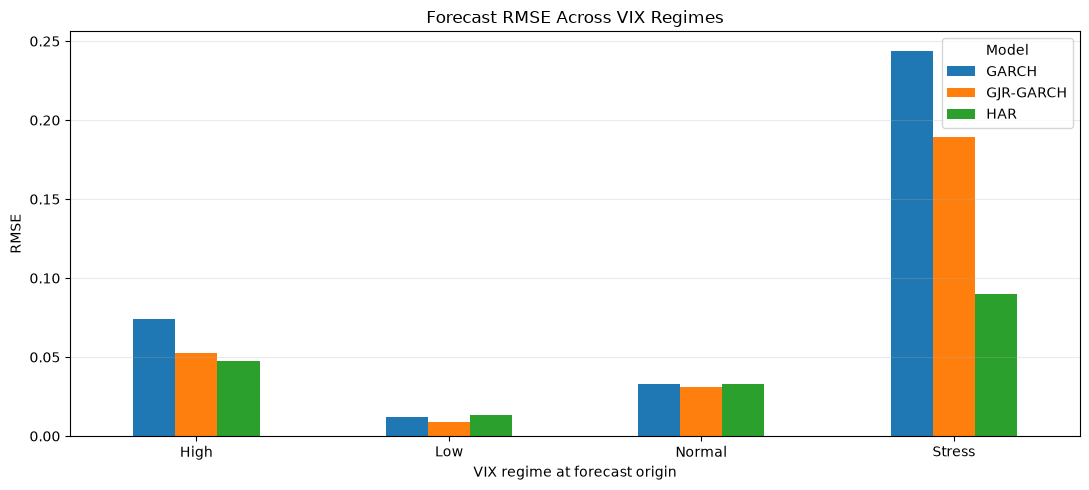

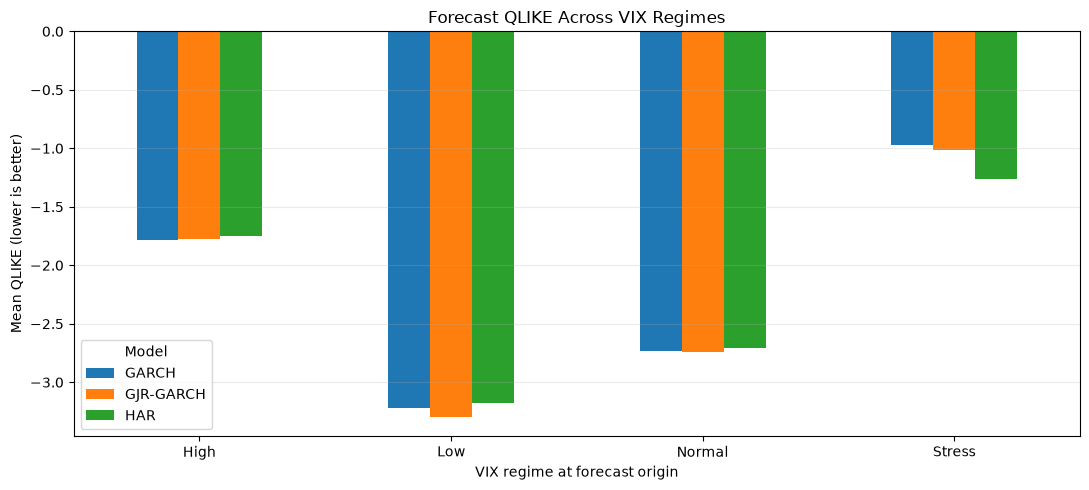

In [11]:
rmse_pivot = regime_comparison.pivot(
    index="VIX regime", columns="Model", values="RMSE"
)
ax = rmse_pivot.plot(kind="bar", figsize=(11, 5))
ax.set_title("Forecast RMSE Across VIX Regimes")
ax.set_xlabel("VIX regime at forecast origin")
ax.set_ylabel("RMSE")
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

qlike_pivot = regime_comparison.pivot(
    index="VIX regime", columns="Model", values="QLIKE"
)
ax = qlike_pivot.plot(kind="bar", figsize=(11, 5))
ax.set_title("Forecast QLIKE Across VIX Regimes")
ax.set_xlabel("VIX regime at forecast origin")
ax.set_ylabel("Mean QLIKE (lower is better)")
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Stage 8.11 — Forecasting checks
Confirm that the data, targets, forecasts, and comparison tables were created.


In [12]:
print("STAGE 8 COMPLETED")
print("Market observations:", len(market))
print("Evaluation observations:", len(evaluation_data))
print("Common comparison observations:", len(comparison_gjr))
print("Regimes evaluated:", regime_comparison["VIX regime"].nunique())
print("Years evaluated:", annual_comparison["Year"].nunique())

STAGE 8 COMPLETED
Market observations: 4243
Evaluation observations: 3680
Common comparison observations: 1084
Regimes evaluated: 4
Years evaluated: 5


## Stage 9 — Forecast-loss inference
Test paired forecast-loss differences with Newey–West HAC standard errors and Holm correction; account for overlapping 21-session targets.


In [13]:

# ============================================================
# STAGE 9: REGIME-SPECIFIC FORECAST SIGNIFICANCE TESTS
# Paired loss differentials with Newey-West HAC standard errors
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import norm
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 1. Reconstruct regime labels
# ------------------------------------------------------------

test_data = comparison_gjr.copy()

test_data["VIX_regime"] = pd.cut(
    test_data["VIX"],
    bins=[-np.inf, 15, 25, 35, np.inf],
    labels=["Low", "Normal", "High", "Stress"],
    right=False
)

# ------------------------------------------------------------
# 2. Calculate forecast losses
# ------------------------------------------------------------

actual = test_data["actual_future_variance"]

forecasts = {
    "HAR": test_data["har_forecast"],
    "GARCH": test_data["garch_forecast"],
    "GJR-GARCH": test_data["gjr_forecast"]
}

losses = {}

for model, forecast in forecasts.items():

    losses[("MSE", model)] = (
        actual - forecast
    ) ** 2

    losses[("QLIKE", model)] = (
        np.log(forecast) + actual / forecast
    )

# ------------------------------------------------------------
# 3. Define pairwise model comparisons
# ------------------------------------------------------------

pairs = [
    ("HAR", "GJR-GARCH"),
    ("HAR", "GARCH"),
    ("GARCH", "GJR-GARCH")
]

regimes = ["Low", "Normal", "High", "Stress"]

# Preserve the complete daily time sequence when applying HAC.
# This avoids treating separated observations within a regime
# as consecutive trading sessions.

T = len(test_data)
results = []

# ------------------------------------------------------------
# 4. HAC test for conditional mean loss difference
# ------------------------------------------------------------

def regime_hac_test(loss_difference, regime_mask, max_lag):

    d = loss_difference.to_numpy(dtype=float)
    mask = regime_mask.to_numpy(dtype=bool)

    valid = mask & np.isfinite(d)
    n = int(valid.sum())

    if n < 50:
        return None

    mean_difference = float(d[valid].mean())

    # Zero outside the selected regime.
    # Center within the selected regime.
    z = np.zeros(len(d), dtype=float)
    z[valid] = d[valid] - mean_difference

    # Newey-West Bartlett HAC long-run variance
    gamma_zero = np.dot(z, z) / len(z)
    long_run_variance = gamma_zero

    effective_lag = min(max_lag, len(z) - 1)

    for lag in range(1, effective_lag + 1):

        autocovariance = (
            np.dot(z[lag:], z[:-lag]) / len(z)
        )

        weight = 1 - lag / (effective_lag + 1)

        long_run_variance += (
            2 * weight * autocovariance
        )

    if long_run_variance <= 0:
        return None

    # Standard error of the conditional regime mean
    standard_error = np.sqrt(
        len(z) * long_run_variance / (n ** 2)
    )

    z_statistic = mean_difference / standard_error

    p_value = 2 * norm.sf(abs(z_statistic))

    return {
        "Observations": n,
        "Mean loss difference (A - B)": mean_difference,
        "HAC standard error": standard_error,
        "Z statistic": z_statistic,
        "p-value": p_value
    }


# ------------------------------------------------------------
# 5. Run tests across regimes and evaluation metrics
# ------------------------------------------------------------

for regime in regimes:

    regime_mask = (
        test_data["VIX_regime"] == regime
    )

    n_regime = int(regime_mask.sum())

    for metric in ["MSE", "QLIKE"]:

        for model_a, model_b in pairs:

            difference = (
                losses[(metric, model_a)]
                - losses[(metric, model_b)]
            )

            for lag in [20, 42]:

                test_result = regime_hac_test(
                    difference,
                    regime_mask,
                    lag
                )

                if test_result is None:

                    results.append({
                        "Regime": regime,
                        "Metric": metric,
                        "Comparison": f"{model_a} vs {model_b}",
                        "HAC lags": lag,
                        "Observations": n_regime,
                        "Mean loss difference (A - B)": np.nan,
                        "HAC standard error": np.nan,
                        "Z statistic": np.nan,
                        "p-value": np.nan,
                        "Status": "Insufficient sample or invalid HAC variance"
                    })

                else:

                    results.append({
                        "Regime": regime,
                        "Metric": metric,
                        "Comparison": f"{model_a} vs {model_b}",
                        "HAC lags": lag,
                        **test_result,
                        "Status": "Tested"
                    })


# ------------------------------------------------------------
# 6. Apply Holm multiple-testing correction
# ------------------------------------------------------------

dm_results = pd.DataFrame(results)

dm_results["Holm-adjusted p-value"] = np.nan

testable = dm_results["p-value"].notna()

# Correct the three pairwise comparisons within each
# regime, metric and HAC-lag specification.

for _, group in dm_results[testable].groupby(
    ["Regime", "Metric", "HAC lags"]
):

    adjusted = multipletests(
        group["p-value"].to_numpy(),
        method="holm"
    )[1]

    dm_results.loc[
        group.index,
        "Holm-adjusted p-value"
    ] = adjusted


# ------------------------------------------------------------
# 7. Display final statistical results
# ------------------------------------------------------------

display(
    dm_results[
        [
            "Regime",
            "Metric",
            "Comparison",
            "HAC lags",
            "Observations",
            "Mean loss difference (A - B)",
            "Z statistic",
            "p-value",
            "Holm-adjusted p-value",
            "Status"
        ]
    ]
)

print("\nINTERPRETATION")
print("Positive loss difference: Model B has lower average loss.")
print("Negative loss difference: Model A has lower average loss.")
print("Use Holm-adjusted p-values for significance assessment.")
print("Stress regime is not tested when fewer than 50 observations exist.")

print("\nSTAGE 9 COMPLETED")


,Regime,Metric,Comparison,HAC lags,Observations,Mean loss difference (A - B),Z statistic,p-value,Holm-adjusted p-value,Status
0,Low,MSE,HAR vs GJR-GARCH,20,271,0.000104,3.676034,0.000237,0.000711,Tested
1,Low,MSE,HAR vs GJR-GARCH,42,271,0.000104,3.760075,0.000170,0.000510,Tested
2,Low,MSE,HAR vs GARCH,20,271,0.000035,1.856134,0.063434,0.063434,Tested
3,Low,MSE,HAR vs GARCH,42,271,0.000035,1.839703,0.065812,0.065812,Tested
4,Low,MSE,GARCH vs GJR-GARCH,20,271,0.000069,3.438273,0.000585,0.001171,Tested
5,Low,MSE,GARCH vs GJR-GARCH,42,271,0.000069,3.742779,0.000182,0.000510,Tested
6,Low,QLIKE,HAR vs GJR-GARCH,20,271,0.114590,2.557927,0.010530,0.021060,Tested
7,Low,QLIKE,HAR vs GJR-GARCH,42,271,0.114590,2.678373,0.007398,0.014796,Tested
8,Low,QLIKE,HAR vs GARCH,20,271,0.042994,1.689791,0.091068,0.091068,Tested
9,Low,QLIKE,HAR vs GARCH,42,271,0.042994,1.780908,0.074927,0.074927,Tested



INTERPRETATION
Positive loss difference: Model B has lower average loss.
Negative loss difference: Model A has lower average loss.
Use Holm-adjusted p-values for significance assessment.
Stress regime is not tested when fewer than 50 observations exist.

STAGE 9 COMPLETED


In [14]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)

display(
    dm_results.sort_values(
        ["Regime", "Metric", "HAC lags", "Comparison"]
    ).round(6)
)

,Regime,Metric,Comparison,HAC lags,Observations,Mean loss difference (A - B),HAC standard error,Z statistic,p-value,Status,Holm-adjusted p-value
28,High,MSE,GARCH vs GJR-GARCH,20,116,0.002733,0.003065,0.891548,0.372635,Tested,0.752522
26,High,MSE,HAR vs GARCH,20,116,-0.003240,0.002822,-1.148310,0.250841,Tested,0.752522
24,High,MSE,HAR vs GJR-GARCH,20,116,-0.000507,0.000893,-0.567504,0.570372,Tested,0.752522
29,High,MSE,GARCH vs GJR-GARCH,42,116,0.002733,0.003287,0.831543,0.405667,Tested,0.835227
27,High,MSE,HAR vs GARCH,42,116,-0.003240,0.002989,-1.083900,0.278409,Tested,0.835227
25,High,MSE,HAR vs GJR-GARCH,42,116,-0.000507,0.000836,-0.606164,0.544406,Tested,0.835227
34,High,QLIKE,GARCH vs GJR-GARCH,20,116,-0.011029,0.040717,-0.270863,0.786496,Tested,1.000000
32,High,QLIKE,HAR vs GARCH,20,116,0.033331,0.076319,0.436731,0.662306,Tested,1.000000
30,High,QLIKE,HAR vs GJR-GARCH,20,116,0.022302,0.059942,0.372061,0.709847,Tested,1.000000
35,High,QLIKE,GARCH vs GJR-GARCH,42,116,-0.011029,0.042565,-0.259101,0.795557,Tested,1.000000


In [15]:

from statsmodels.stats.multitest import multipletests

# Use 42 HAC lags as the primary specification
primary_tests = dm_results[
    (dm_results["HAC lags"] == 42)
    & (dm_results["Status"] == "Tested")
].copy()

# Global Holm correction across all valid primary tests
primary_tests["Global Holm p-value"] = multipletests(
    primary_tests["p-value"],
    method="holm"
)[1]

primary_tests = primary_tests.sort_values(
    "Global Holm p-value"
)

display(
    primary_tests[
        [
            "Regime",
            "Metric",
            "Comparison",
            "Observations",
            "Mean loss difference (A - B)",
            "p-value",
            "Global Holm p-value"
        ]
    ].round(6)
)

print("\nGlobally significant comparisons (5% level):")

display(
    primary_tests[
        primary_tests["Global Holm p-value"] < 0.05
    ]
)


,Regime,Metric,Comparison,Observations,Mean loss difference (A - B),p-value,Global Holm p-value
1,Low,MSE,HAR vs GJR-GARCH,271,0.000104,0.000170,0.003058
5,Low,MSE,GARCH vs GJR-GARCH,271,0.000069,0.000182,0.003094
11,Low,QLIKE,GARCH vs GJR-GARCH,271,0.071596,0.002367,0.037878
7,Low,QLIKE,HAR vs GJR-GARCH,271,0.114590,0.007398,0.110971
3,Low,MSE,HAR vs GARCH,271,0.000035,0.065812,0.921365
9,Low,QLIKE,HAR vs GARCH,271,0.042994,0.074927,0.974057
13,Normal,MSE,HAR vs GJR-GARCH,691,0.000115,0.284385,1.000000
15,Normal,MSE,HAR vs GARCH,691,-0.000007,0.953929,1.000000
17,Normal,MSE,GARCH vs GJR-GARCH,691,0.000122,0.143314,1.000000
19,Normal,QLIKE,HAR vs GJR-GARCH,691,0.040285,0.301927,1.000000



Globally significant comparisons (5% level):


,Regime,Metric,Comparison,HAC lags,Observations,Mean loss difference (A - B),HAC standard error,Z statistic,p-value,Status,Holm-adjusted p-value,Global Holm p-value
1,Low,MSE,HAR vs GJR-GARCH,42,271,0.000104,0.000028,3.760075,0.000170,Tested,0.000510,0.003058
5,Low,MSE,GARCH vs GJR-GARCH,42,271,0.000069,0.000018,3.742779,0.000182,Tested,0.000510,0.003094
11,Low,QLIKE,GARCH vs GJR-GARCH,42,271,0.071596,0.023553,3.039797,0.002367,Tested,0.007102,0.037878


## Stage 10 — Walk-forward regime selection
Select models using only historical observations and compare the adaptive forecast with fixed benchmarks.


Adaptive forecasts generated: 1084
Observations using historical model selection: 832
Observations using HAR fallback: 252

OVERALL FORECAST COMPARISON


,Observations,MSE,RMSE,QLIKE
Model,,,,
HAR,1084,0.001020,0.031935,-2.713328
GARCH,1084,0.001647,0.040582,-2.745925
GJR-GARCH,1084,0.001128,0.033585,-2.768700
Adaptive,1084,0.001382,0.037182,-2.715397



REGIME-SPECIFIC COMPARISON


,VIX regime,Model,Observations,RMSE,QLIKE
0,Low,HAR,271,0.013546,-3.180419
1,Low,GARCH,271,0.012176,-3.223413
2,Low,GJR-GARCH,271,0.008922,-3.295009
3,Low,Adaptive,271,0.011473,-3.230698
4,Normal,HAR,691,0.032834,-2.704501
5,Normal,GARCH,691,0.032940,-2.735714
6,Normal,GJR-GARCH,691,0.031030,-2.744786
7,Normal,Adaptive,691,0.033816,-2.696227
8,High,HAR,116,0.047542,-1.749800
9,High,GARCH,116,0.074164,-1.783131



MODEL SELECTION FREQUENCY


selected_model,GARCH,GJR-GARCH,HAR
VIX_regime,,,
Low,0,188,83
Normal,374,85,232
High,36,0,80
Stress,0,0,6


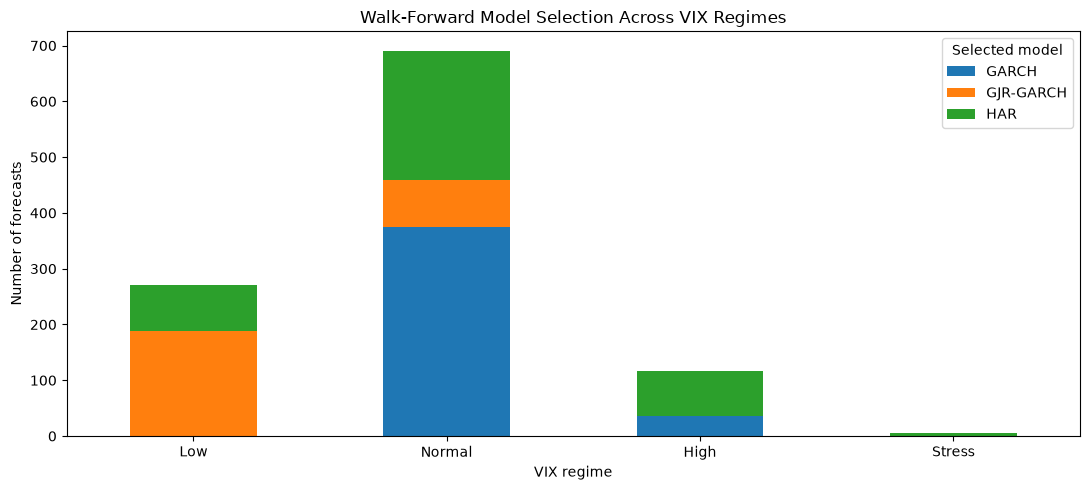

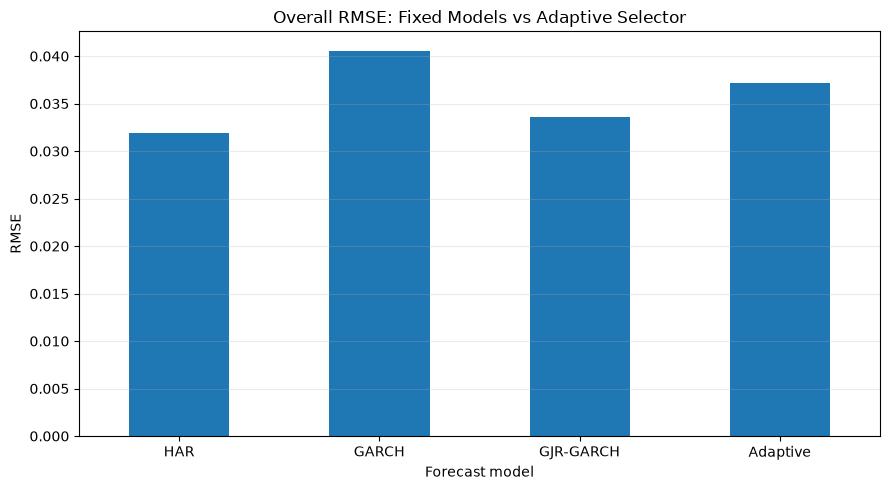


STAGE 10 COMPLETED
Total forecasts: 1084
Unique selected models: 3
Model selection counts:
 selected_model
GARCH        410
HAR          401
GJR-GARCH    273
Name: count, dtype: int64


In [16]:

# ============================================================
# STAGE 10: WALK-FORWARD REGIME-AWARE MODEL SELECTION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Prepare common forecast dataset
# ------------------------------------------------------------

selector_data = comparison_gjr.copy().sort_index()

forecast_models = {
    "HAR": "har_forecast",
    "GARCH": "garch_forecast",
    "GJR-GARCH": "gjr_forecast"
}

# Classify current volatility regime
selector_data["VIX_regime"] = pd.cut(
    selector_data["VIX"],
    bins=[-np.inf, 15, 25, 35, np.inf],
    labels=["Low", "Normal", "High", "Stress"],
    right=False
)

# Require positive realised and forecast variances
required_columns = list(forecast_models.values())

selector_data = selector_data.dropna(
    subset=required_columns + [
        "actual_future_variance",
        "VIX_regime"
    ]
)

# ------------------------------------------------------------
# 2. Define selection parameters
# ------------------------------------------------------------

MIN_HISTORY = 63
FORECAST_HORIZON = 21

adaptive_records = []

# ------------------------------------------------------------
# 3. Walk-forward model selection
# ------------------------------------------------------------

for i in range(len(selector_data)):

    current = selector_data.iloc[i]
    current_regime = current["VIX_regime"]

    # Only use observations whose 21-session
    # realised outcomes have already matured.

    history_end = i - FORECAST_HORIZON + 1

    history = selector_data.iloc[
        :max(0, history_end)
    ]

    regime_history = history[
        history["VIX_regime"] == current_regime
    ]

    available_history = len(regime_history)

    # Default model when history is insufficient
    selected_model = "HAR"
    selection_reason = "HAR fallback"

    # --------------------------------------------------------
    # Select the best historical QLIKE model
    # --------------------------------------------------------

    if available_history >= MIN_HISTORY:

        historical_losses = {}

        for model_name, forecast_column in forecast_models.items():

            past_forecast = regime_history[forecast_column]

            past_actual = regime_history[
                "actual_future_variance"
            ]

            past_qlike = (
                np.log(past_forecast)
                + past_actual / past_forecast
            )

            historical_losses[model_name] = past_qlike.mean()

        selected_model = min(
            historical_losses,
            key=historical_losses.get
        )

        selection_reason = "Historical regime QLIKE"

    # --------------------------------------------------------
    # Generate adaptive forecast
    # --------------------------------------------------------

    selected_column = forecast_models[selected_model]

    adaptive_records.append({
        "Date": selector_data.index[i],
        "VIX_regime": current_regime,
        "selected_model": selected_model,
        "selection_reason": selection_reason,
        "historical_regime_observations": available_history,
        "adaptive_forecast": current[selected_column]
    })

adaptive_results = (
    pd.DataFrame(adaptive_records)
    .set_index("Date")
)

# ------------------------------------------------------------
# 4. Merge adaptive forecasts
# ------------------------------------------------------------

adaptive_data = selector_data.join(
    adaptive_results[
        [
            "selected_model",
            "selection_reason",
            "historical_regime_observations",
            "adaptive_forecast"
        ]
    ]
)

print("Adaptive forecasts generated:", len(adaptive_data))

print(
    "Observations using historical model selection:",
    (adaptive_data["selection_reason"]
     == "Historical regime QLIKE").sum()
)

print(
    "Observations using HAR fallback:",
    (adaptive_data["selection_reason"]
     == "HAR fallback").sum()
)

# ------------------------------------------------------------
# 5. Overall model comparison
# ------------------------------------------------------------

comparison_models = {
    "HAR": "har_forecast",
    "GARCH": "garch_forecast",
    "GJR-GARCH": "gjr_forecast",
    "Adaptive": "adaptive_forecast"
}

actual = adaptive_data["actual_future_variance"]

overall_results = []

for model_name, forecast_column in comparison_models.items():

    forecast = adaptive_data[forecast_column]

    valid = (
        actual.gt(0)
        & forecast.gt(0)
        & np.isfinite(actual)
        & np.isfinite(forecast)
    )

    y = actual.loc[valid]
    f = forecast.loc[valid]

    mse = np.mean((y - f) ** 2)

    qlike = np.mean(
        np.log(f) + y / f
    )

    overall_results.append({
        "Model": model_name,
        "Observations": len(y),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "QLIKE": qlike
    })

overall_comparison = (
    pd.DataFrame(overall_results)
    .set_index("Model")
)

print("\nOVERALL FORECAST COMPARISON")

display(overall_comparison)

# ------------------------------------------------------------
# 6. Model performance by volatility regime
# ------------------------------------------------------------

regime_metrics = []

for regime, group in adaptive_data.groupby(
    "VIX_regime",
    observed=True
):

    y = group["actual_future_variance"]

    for model_name, forecast_column in comparison_models.items():

        f = group[forecast_column]

        valid = (
            y.gt(0)
            & f.gt(0)
            & np.isfinite(y)
            & np.isfinite(f)
        )

        actual_valid = y.loc[valid]
        forecast_valid = f.loc[valid]

        regime_metrics.append({
            "VIX regime": regime,
            "Model": model_name,
            "Observations": len(actual_valid),
            "RMSE": np.sqrt(
                np.mean(
                    (actual_valid - forecast_valid) ** 2
                )
            ),
            "QLIKE": np.mean(
                np.log(forecast_valid)
                + actual_valid / forecast_valid
            )
        })

adaptive_regime_comparison = pd.DataFrame(
    regime_metrics
)

print("\nREGIME-SPECIFIC COMPARISON")

display(adaptive_regime_comparison)

# ------------------------------------------------------------
# 7. Model selection frequency
# ------------------------------------------------------------

selection_frequency = pd.crosstab(
    adaptive_data["VIX_regime"],
    adaptive_data["selected_model"]
)

print("\nMODEL SELECTION FREQUENCY")

display(selection_frequency)

# ------------------------------------------------------------
# 8. Plot model selection frequency
# ------------------------------------------------------------

ax = selection_frequency.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 5)
)

ax.set_title(
    "Walk-Forward Model Selection Across VIX Regimes"
)

ax.set_xlabel("VIX regime")
ax.set_ylabel("Number of forecasts")
ax.legend(title="Selected model")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Plot overall RMSE comparison
# ------------------------------------------------------------

ax = overall_comparison["RMSE"].plot(
    kind="bar",
    figsize=(9, 5)
)

ax.set_title(
    "Overall RMSE: Fixed Models vs Adaptive Selector"
)

ax.set_xlabel("Forecast model")
ax.set_ylabel("RMSE")
ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. Completion checks
# ------------------------------------------------------------

print("\nSTAGE 10 COMPLETED")

print("Total forecasts:", len(adaptive_data))
print(
    "Unique selected models:",
    adaptive_data["selected_model"].nunique()
)

print(
    "Model selection counts:\n",
    adaptive_data["selected_model"].value_counts()
)


## Stage 11 — VRP construction
Calculate the variance spread between VIX-implied variance and forecast physical variance; inspect its calibration and relationship with subsequent realised VRP.



VRP SIGNAL COMPARISON


,Observations,Mean ex-ante VRP,Mean ex-post VRP,Correlation,Signal RMSE,Signal MAE,Sign accuracy,Positive signal fraction,Positive realised VRP fraction
Model,,,,,,,,,
HAR,1084,0.007413,0.010529,0.135838,0.031935,0.016879,0.626384,0.670664,0.872694
GARCH,1084,0.002090,0.010529,-0.067618,0.040582,0.018823,0.633764,0.687269,0.872694
GJR-GARCH,1084,0.007061,0.010529,0.013581,0.033585,0.016088,0.771218,0.830258,0.872694



VRP PREDICTIVE CALIBRATION


,Model,HAC lags,Observations,Intercept,VRP coefficient,Coefficient standard error,Coefficient p-value,R-squared
0,HAR,20,1084,0.008957,0.211970,0.108612,0.050983,0.018452
1,HAR,42,1084,0.008957,0.211970,0.118338,0.073258,0.018452
2,GARCH,20,1084,0.010686,-0.075255,0.102959,0.464828,0.004572
3,GARCH,42,1084,0.010686,-0.075255,0.098441,0.444588,0.004572
4,GJR-GARCH,20,1084,0.010374,0.021949,0.182829,0.904442,0.000184
5,GJR-GARCH,42,1084,0.010374,0.021949,0.148863,0.882782,0.000184



HAR VRP QUINTILE ANALYSIS


,observations,mean_ex_ante_vrp,mean_realized_vrp,median_realized_vrp,positive_realized_fraction
har_vrp_quintile,,,,,
Q1 Lowest,217,-0.009330,0.007372,0.008272,0.875576
Q2,217,-0.000833,0.007682,0.010507,0.894009
Q3,216,0.004405,0.009067,0.013005,0.879630
Q4,217,0.011116,0.011049,0.017996,0.898618
Q5 Highest,217,0.031695,0.017466,0.022251,0.815668


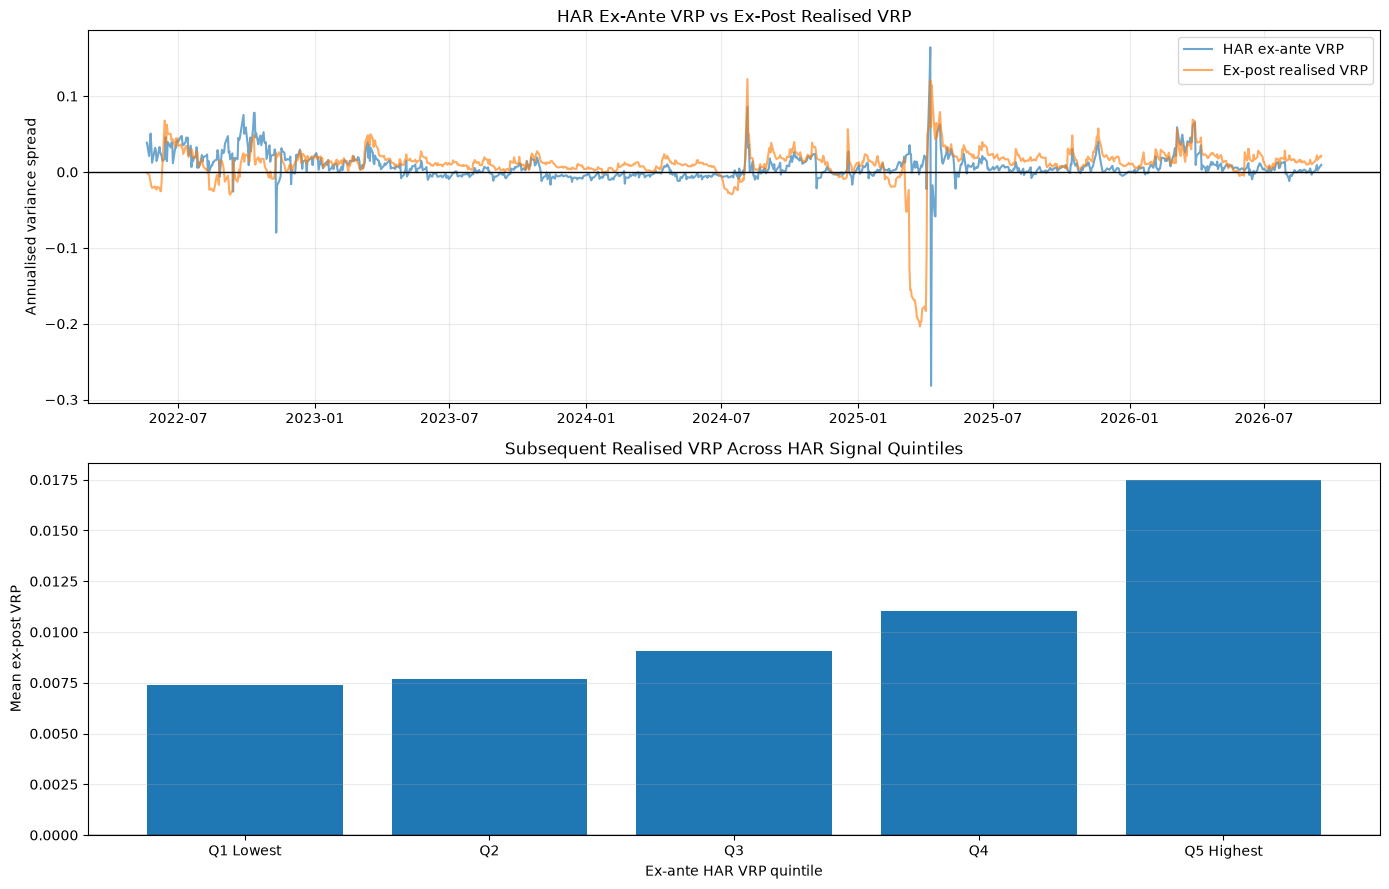


STAGE 11 COMPLETED
Observations: 1084
Evaluation start: 2022-05-20 00:00:00
Evaluation end: 2026-09-16 00:00:00

Available variables:
vrp_data
signal_comparison
calibration_comparison
quintile_summary


In [17]:

# ============================================================
# STAGE 11: VRP SIGNAL CONSTRUCTION AND VALIDATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

# ------------------------------------------------------------
# 1. Prepare common forecast dataset
# ------------------------------------------------------------

vrp_data = comparison_gjr.copy().sort_index()

required_columns = [
    "VIX",
    "actual_future_variance",
    "har_forecast",
    "garch_forecast",
    "gjr_forecast"
]

vrp_data = vrp_data.dropna(
    subset=required_columns
).copy()

# ------------------------------------------------------------
# 2. Calculate VIX-implied variance
# ------------------------------------------------------------

vrp_data["implied_variance"] = (
    vrp_data["VIX"] / 100
) ** 2

# ------------------------------------------------------------
# 3. Construct ex-ante VRP signals
# ------------------------------------------------------------

vrp_data["vrp_har"] = (
    vrp_data["implied_variance"]
    - vrp_data["har_forecast"]
)

vrp_data["vrp_garch"] = (
    vrp_data["implied_variance"]
    - vrp_data["garch_forecast"]
)

vrp_data["vrp_gjr"] = (
    vrp_data["implied_variance"]
    - vrp_data["gjr_forecast"]
)

# ------------------------------------------------------------
# 4. Construct ex-post realised VRP proxy
# ------------------------------------------------------------

vrp_data["realized_vrp"] = (
    vrp_data["implied_variance"]
    - vrp_data["actual_future_variance"]
)

# ------------------------------------------------------------
# 5. Compare ex-ante VRP signals with ex-post VRP
# ------------------------------------------------------------

signals = {
    "HAR": "vrp_har",
    "GARCH": "vrp_garch",
    "GJR-GARCH": "vrp_gjr"
}

signal_results = []

for model, column in signals.items():

    signal = vrp_data[column]
    realized = vrp_data["realized_vrp"]

    valid = (
        signal.notna()
        & realized.notna()
        & np.isfinite(signal)
        & np.isfinite(realized)
    )

    s = signal[valid]
    r = realized[valid]

    signal_results.append({
        "Model": model,
        "Observations": len(s),
        "Mean ex-ante VRP": s.mean(),
        "Mean ex-post VRP": r.mean(),
        "Correlation": s.corr(r),
        "Signal RMSE": np.sqrt(
            np.mean((s - r) ** 2)
        ),
        "Signal MAE": np.mean(np.abs(s - r)),
        "Sign accuracy": (
            (np.sign(s) == np.sign(r)).mean()
        ),
        "Positive signal fraction": (s > 0).mean(),
        "Positive realised VRP fraction": (r > 0).mean()
    })

signal_comparison = (
    pd.DataFrame(signal_results)
    .set_index("Model")
)

print("\nVRP SIGNAL COMPARISON")

display(signal_comparison)


# ------------------------------------------------------------
# 6. Predictive calibration regression
# ------------------------------------------------------------

calibration_results = []

for model, column in signals.items():

    regression_data = vrp_data[
        [column, "realized_vrp"]
    ].dropna()

    X = sm.add_constant(
        regression_data[column]
    )

    y = regression_data["realized_vrp"]

    # Compare HAC specifications for overlapping targets
    for lag in [20, 42]:

        calibration_model = sm.OLS(
            y,
            X
        ).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": lag}
        )

        calibration_results.append({
            "Model": model,
            "HAC lags": lag,
            "Observations": len(y),
            "Intercept": calibration_model.params["const"],
            "VRP coefficient": calibration_model.params[column],
            "Coefficient standard error": (
                calibration_model.bse[column]
            ),
            "Coefficient p-value": (
                calibration_model.pvalues[column]
            ),
            "R-squared": calibration_model.rsquared
        })

calibration_comparison = pd.DataFrame(
    calibration_results
)

print("\nVRP PREDICTIVE CALIBRATION")

display(calibration_comparison)


# ------------------------------------------------------------
# 7. HAR VRP signal quintile analysis
# ------------------------------------------------------------

vrp_data["har_vrp_quintile"] = pd.qcut(
    vrp_data["vrp_har"],
    q=5,
    labels=[
        "Q1 Lowest",
        "Q2",
        "Q3",
        "Q4",
        "Q5 Highest"
    ],
    duplicates="drop"
)

quintile_summary = vrp_data.groupby(
    "har_vrp_quintile",
    observed=True
).agg(
    observations=("realized_vrp", "count"),
    mean_ex_ante_vrp=("vrp_har", "mean"),
    mean_realized_vrp=("realized_vrp", "mean"),
    median_realized_vrp=("realized_vrp", "median"),
    positive_realized_fraction=(
        "realized_vrp",
        lambda x: (x > 0).mean()
    )
)

print("\nHAR VRP QUINTILE ANALYSIS")

display(quintile_summary)


# ------------------------------------------------------------
# 8. Plot ex-ante versus ex-post VRP
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 9)
)

axes[0].plot(
    vrp_data.index,
    vrp_data["vrp_har"],
    alpha=0.65,
    label="HAR ex-ante VRP"
)

axes[0].plot(
    vrp_data.index,
    vrp_data["realized_vrp"],
    alpha=0.65,
    label="Ex-post realised VRP"
)

axes[0].axhline(
    0,
    color="black",
    linewidth=1
)

axes[0].set_title(
    "HAR Ex-Ante VRP vs Ex-Post Realised VRP"
)

axes[0].set_ylabel("Annualised variance spread")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Quintile relationship

axes[1].bar(
    quintile_summary.index.astype(str),
    quintile_summary["mean_realized_vrp"]
)

axes[1].axhline(
    0,
    color="black",
    linewidth=1
)

axes[1].set_title(
    "Subsequent Realised VRP Across HAR Signal Quintiles"
)

axes[1].set_xlabel("Ex-ante HAR VRP quintile")
axes[1].set_ylabel("Mean ex-post VRP")
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Completion summary
# ------------------------------------------------------------

print("\nSTAGE 11 COMPLETED")

print("Observations:", len(vrp_data))
print("Evaluation start:", vrp_data.index.min())
print("Evaluation end:", vrp_data.index.max())

print("\nAvailable variables:")
print("vrp_data")
print("signal_comparison")
print("calibration_comparison")
print("quintile_summary")


## Stage 12 — Walk-forward VRP validation
Form signal ranks and thresholds using past data only; test whether ex-ante rankings order subsequent realised VRP.


Available observations: 1084
Start date: 2022-05-20 00:00:00
End date: 2026-09-16 00:00:00

PREDICTIVE REGRESSION WITH IMPLIED VARIANCE CONTROL


,Model,HAC lags,Observations,VRP coefficient,HAC standard error,t-statistic,p-value,R-squared,Global Holm p-value
0,HAR,20,1084,-0.046999,0.059909,-0.784506,0.432743,0.062220,1.0
1,HAR,42,1084,-0.046999,0.062316,-0.754206,0.450726,0.062220,1.0
2,GARCH,20,1084,-0.026850,0.068043,-0.394609,0.693131,0.062227,1.0
3,GARCH,42,1084,-0.026850,0.065776,-0.408208,0.683121,0.062227,1.0
4,GJR-GARCH,20,1084,0.107280,0.123781,0.866689,0.386112,0.065891,1.0
5,GJR-GARCH,42,1084,0.107280,0.107030,1.002330,0.316184,0.065891,1.0



ROLLING QUINTILE OBSERVATIONS


Quintile,Q1,Q2,Q3,Q4,Q5
Model,,,,,
GARCH,179,189,204,211,175
GJR-GARCH,204,242,200,145,167
HAR,259,203,167,160,169



WALK-FORWARD VRP QUINTILE ANALYSIS


,Model,Quintile,observations,mean_ex_ante_vrp,mean_ex_post_vrp,median_ex_post_vrp,positive_realized_fraction
0,GARCH,Q1,179,-0.020525,0.007398,0.012202,0.899441
1,GARCH,Q2,189,-0.000237,0.008867,0.009954,0.962963
2,GARCH,Q3,204,0.004186,0.007879,0.010845,0.897059
3,GARCH,Q4,211,0.008423,0.010521,0.012775,0.857820
4,GARCH,Q5,175,0.018334,0.018806,0.020147,0.897143
5,GJR-GARCH,Q1,204,-0.009080,0.007334,0.011291,0.877451
6,GJR-GARCH,Q2,242,0.005337,0.008786,0.011070,0.950413
7,GJR-GARCH,Q3,200,0.009591,0.009692,0.012172,0.915000
8,GJR-GARCH,Q4,145,0.011612,0.008868,0.011747,0.813793
9,GJR-GARCH,Q5,167,0.018977,0.019592,0.021623,0.922156



Q5 MINUS Q1 STATISTICAL TEST


,Model,HAC lags,Observations,Q5 minus Q1,HAC standard error,t-statistic,p-value,Global Holm p-value
0,HAR,20,958,0.004638,0.009059,0.511991,0.608657,1.000000
1,HAR,42,958,0.004638,0.009725,0.476938,0.633406,1.000000
2,GARCH,20,958,0.011408,0.006637,1.718907,0.085631,0.342526
3,GARCH,42,958,0.011408,0.004624,2.467238,0.013616,0.081696
4,GJR-GARCH,20,958,0.012258,0.007208,1.700705,0.088998,0.342526
5,GJR-GARCH,42,958,0.012258,0.005021,2.441362,0.014632,0.081696



RANK CORRELATION


,Model,Spearman correlation,p-value,Global Holm p-value
0,HAR,0.405525,0.0,0.0
1,GARCH,0.232522,0.0,0.0
2,GJR-GARCH,0.272416,0.0,0.0


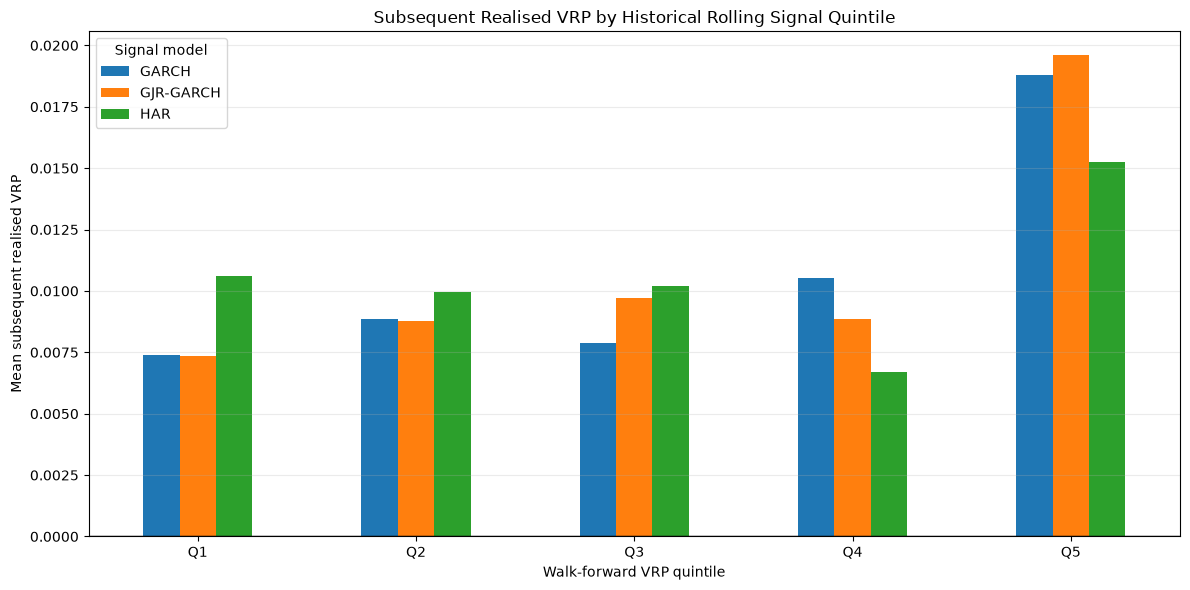

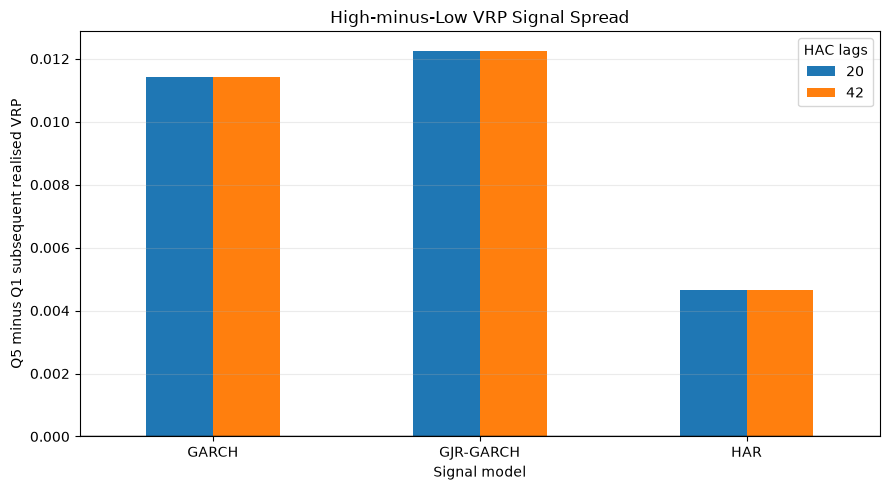


STAGE 12 COMPLETED
Walk-forward observations: 2874
Signal models: 3
Historical lookback: 252
Minimum history: 126

Available variables:
predictive_table
rolling_quintile_data
rolling_quintile_summary
spread_table
rank_table


In [18]:

# ============================================================
# STAGE 12: WALK-FORWARD VRP SIGNAL VALIDATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 1. Prepare data
# ------------------------------------------------------------

signal_columns = {
    "HAR": "vrp_har",
    "GARCH": "vrp_garch",
    "GJR-GARCH": "vrp_gjr"
}

required = [
    "implied_variance",
    "realized_vrp"
] + list(signal_columns.values())

signal_data = (
    vrp_data[required]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .sort_index()
    .copy()
)

print("Available observations:", len(signal_data))
print("Start date:", signal_data.index.min())
print("End date:", signal_data.index.max())

# ------------------------------------------------------------
# 2. Predictive regression with implied variance control
# ------------------------------------------------------------

# This tests whether the ex-ante VRP signal contains
# information about subsequent realised VRP beyond
# the current implied variance level.

predictive_results = []

for model_name, column in signal_columns.items():

    data = signal_data[
        [column, "implied_variance", "realized_vrp"]
    ].copy()

    X = sm.add_constant(
        data[[column, "implied_variance"]]
    )

    y = data["realized_vrp"]

    for lag in [20, 42]:

        fitted = sm.OLS(y, X).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": lag}
        )

        predictive_results.append({
            "Model": model_name,
            "HAC lags": lag,
            "Observations": len(data),
            "VRP coefficient": fitted.params[column],
            "HAC standard error": fitted.bse[column],
            "t-statistic": fitted.tvalues[column],
            "p-value": fitted.pvalues[column],
            "R-squared": fitted.rsquared
        })

predictive_table = pd.DataFrame(predictive_results)

# Global correction across six regression tests
predictive_table["Global Holm p-value"] = multipletests(
    predictive_table["p-value"],
    method="holm"
)[1]

print("\nPREDICTIVE REGRESSION WITH IMPLIED VARIANCE CONTROL")

display(predictive_table.round(6))


# ------------------------------------------------------------
# 3. Construct rolling historical VRP quintiles
# ------------------------------------------------------------

LOOKBACK = 252
MIN_HISTORY = 126

rolling_records = []

for model_name, column in signal_columns.items():

    signal = signal_data[column]

    for i in range(len(signal_data)):

        current_signal = signal.iloc[i]

        if not np.isfinite(current_signal):
            continue

        # Only use historical signal values available
        # before the current forecast date.

        start = max(0, i - LOOKBACK)

        historical_signals = (
            signal.iloc[start:i].dropna()
        )

        if len(historical_signals) < MIN_HISTORY:
            continue

        # Historical rolling quintile thresholds
        thresholds = np.quantile(
            historical_signals,
            [0.20, 0.40, 0.60, 0.80]
        )

        # Assign the current signal to a quintile
        quintile = (
            np.searchsorted(
                thresholds,
                current_signal,
                side="left"
            ) + 1
        )

        rolling_records.append({
            "Date": signal_data.index[i],
            "Model": model_name,
            "Quintile": f"Q{quintile}",
            "Ex-ante VRP": current_signal,
            "Ex-post VRP": signal_data[
                "realized_vrp"
            ].iloc[i],
            "Implied variance": signal_data[
                "implied_variance"
            ].iloc[i],
            "Historical observations": len(
                historical_signals
            )
        })

rolling_quintile_data = pd.DataFrame(
    rolling_records
)

print("\nROLLING QUINTILE OBSERVATIONS")

display(
    rolling_quintile_data.groupby(
        ["Model", "Quintile"],
        observed=True
    ).size().unstack(fill_value=0)
)


# ------------------------------------------------------------
# 4. Calculate subsequent realised VRP by quintile
# ------------------------------------------------------------

rolling_quintile_summary = (
    rolling_quintile_data
    .groupby(
        ["Model", "Quintile"],
        observed=True
    )
    .agg(
        observations=("Ex-post VRP", "count"),
        mean_ex_ante_vrp=("Ex-ante VRP", "mean"),
        mean_ex_post_vrp=("Ex-post VRP", "mean"),
        median_ex_post_vrp=("Ex-post VRP", "median"),
        positive_realized_fraction=(
            "Ex-post VRP",
            lambda x: (x > 0).mean()
        )
    )
    .reset_index()
)

quintile_order = ["Q1", "Q2", "Q3", "Q4", "Q5"]

rolling_quintile_summary["Quintile"] = pd.Categorical(
    rolling_quintile_summary["Quintile"],
    categories=quintile_order,
    ordered=True
)

rolling_quintile_summary = (
    rolling_quintile_summary.sort_values(
        ["Model", "Quintile"]
    )
)

print("\nWALK-FORWARD VRP QUINTILE ANALYSIS")

display(rolling_quintile_summary)


# ------------------------------------------------------------
# 5. Test the Q5 minus Q1 realised VRP difference
# ------------------------------------------------------------

spread_results = []

for model_name in signal_columns:

    group = rolling_quintile_data[
        rolling_quintile_data["Model"] == model_name
    ].copy()

    group = group.sort_values("Date")

    # Use Q1 as the reference category.
    # Q5 coefficient therefore measures Q5 minus Q1.

    X = pd.DataFrame(
        {"const": np.ones(len(group))},
        index=group.index
    )

    for q in ["Q2", "Q3", "Q4", "Q5"]:

        X[q] = (
            group["Quintile"] == q
        ).astype(float)

    y = group["Ex-post VRP"]

    for lag in [20, 42]:

        fitted = sm.OLS(y, X).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": lag}
        )

        spread_results.append({
            "Model": model_name,
            "HAC lags": lag,
            "Observations": len(group),
            "Q5 minus Q1": fitted.params["Q5"],
            "HAC standard error": fitted.bse["Q5"],
            "t-statistic": fitted.tvalues["Q5"],
            "p-value": fitted.pvalues["Q5"]
        })

spread_table = pd.DataFrame(spread_results)

# Global correction across six spread tests
spread_table["Global Holm p-value"] = multipletests(
    spread_table["p-value"],
    method="holm"
)[1]

print("\nQ5 MINUS Q1 STATISTICAL TEST")

display(spread_table.round(6))


# ------------------------------------------------------------
# 6. Spearman rank correlation
# ------------------------------------------------------------

rank_results = []

for model_name, column in signal_columns.items():

    rho, pvalue = spearmanr(
        signal_data[column],
        signal_data["realized_vrp"],
        nan_policy="omit"
    )

    rank_results.append({
        "Model": model_name,
        "Spearman correlation": rho,
        "p-value": pvalue
    })

rank_table = pd.DataFrame(rank_results)

rank_table["Global Holm p-value"] = multipletests(
    rank_table["p-value"],
    method="holm"
)[1]

print("\nRANK CORRELATION")

display(rank_table.round(6))


# ------------------------------------------------------------
# 7. Plot walk-forward quintile results
# ------------------------------------------------------------

quintile_pivot = rolling_quintile_summary.pivot(
    index="Quintile",
    columns="Model",
    values="mean_ex_post_vrp"
)

ax = quintile_pivot.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.axhline(
    0,
    color="black",
    linewidth=1
)

ax.set_title(
    "Subsequent Realised VRP by Historical Rolling Signal Quintile"
)

ax.set_xlabel("Walk-forward VRP quintile")
ax.set_ylabel("Mean subsequent realised VRP")
ax.legend(title="Signal model")
ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Plot Q5-Q1 spread
# ------------------------------------------------------------

spread_pivot = spread_table.pivot(
    index="Model",
    columns="HAC lags",
    values="Q5 minus Q1"
)

ax = spread_pivot.plot(
    kind="bar",
    figsize=(9, 5)
)

ax.axhline(
    0,
    color="black",
    linewidth=1
)

ax.set_title(
    "High-minus-Low VRP Signal Spread"
)

ax.set_xlabel("Signal model")
ax.set_ylabel("Q5 minus Q1 subsequent realised VRP")
ax.legend(title="HAC lags")
ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Completion summary
# ------------------------------------------------------------

print("\nSTAGE 12 COMPLETED")

print("Walk-forward observations:", len(rolling_quintile_data))
print("Signal models:", len(signal_columns))
print("Historical lookback:", LOOKBACK)
print("Minimum history:", MIN_HISTORY)

print("\nAvailable variables:")
print("predictive_table")
print("rolling_quintile_data")
print("rolling_quintile_summary")
print("spread_table")
print("rank_table")


## Stage 13 — Moving-block bootstrap
Estimate uncertainty in VRP quintile spreads while preserving serial dependence.



Processing HAR: 958 observations

Processing GARCH: 958 observations

Processing GJR-GARCH: 958 observations

MOVING-BLOCK BOOTSTRAP RESULTS


,Model,Block length,Observed Q5-Q1 spread,Bootstrap standard error,95% CI lower,95% CI upper,Probability spread is positive,Valid bootstrap samples
0,HAR,21,0.004638,0.009388,-0.017785,0.018425,0.7090,2000
1,HAR,42,0.004638,0.010049,-0.017048,0.018916,0.7070,2000
2,HAR,63,0.004638,0.009797,-0.016181,0.019248,0.6990,2000
3,GARCH,21,0.011408,0.006749,-0.001485,0.025609,0.9610,2000
4,GARCH,42,0.011408,0.005033,0.001550,0.021179,0.9855,2000
5,GARCH,63,0.011408,0.004405,0.002206,0.020061,0.9885,2000
6,GJR-GARCH,21,0.012258,0.007287,-0.001682,0.026664,0.9570,2000
7,GJR-GARCH,42,0.012258,0.005446,0.000474,0.022358,0.9800,2000
8,GJR-GARCH,63,0.012258,0.004761,0.002464,0.021348,0.9905,2000


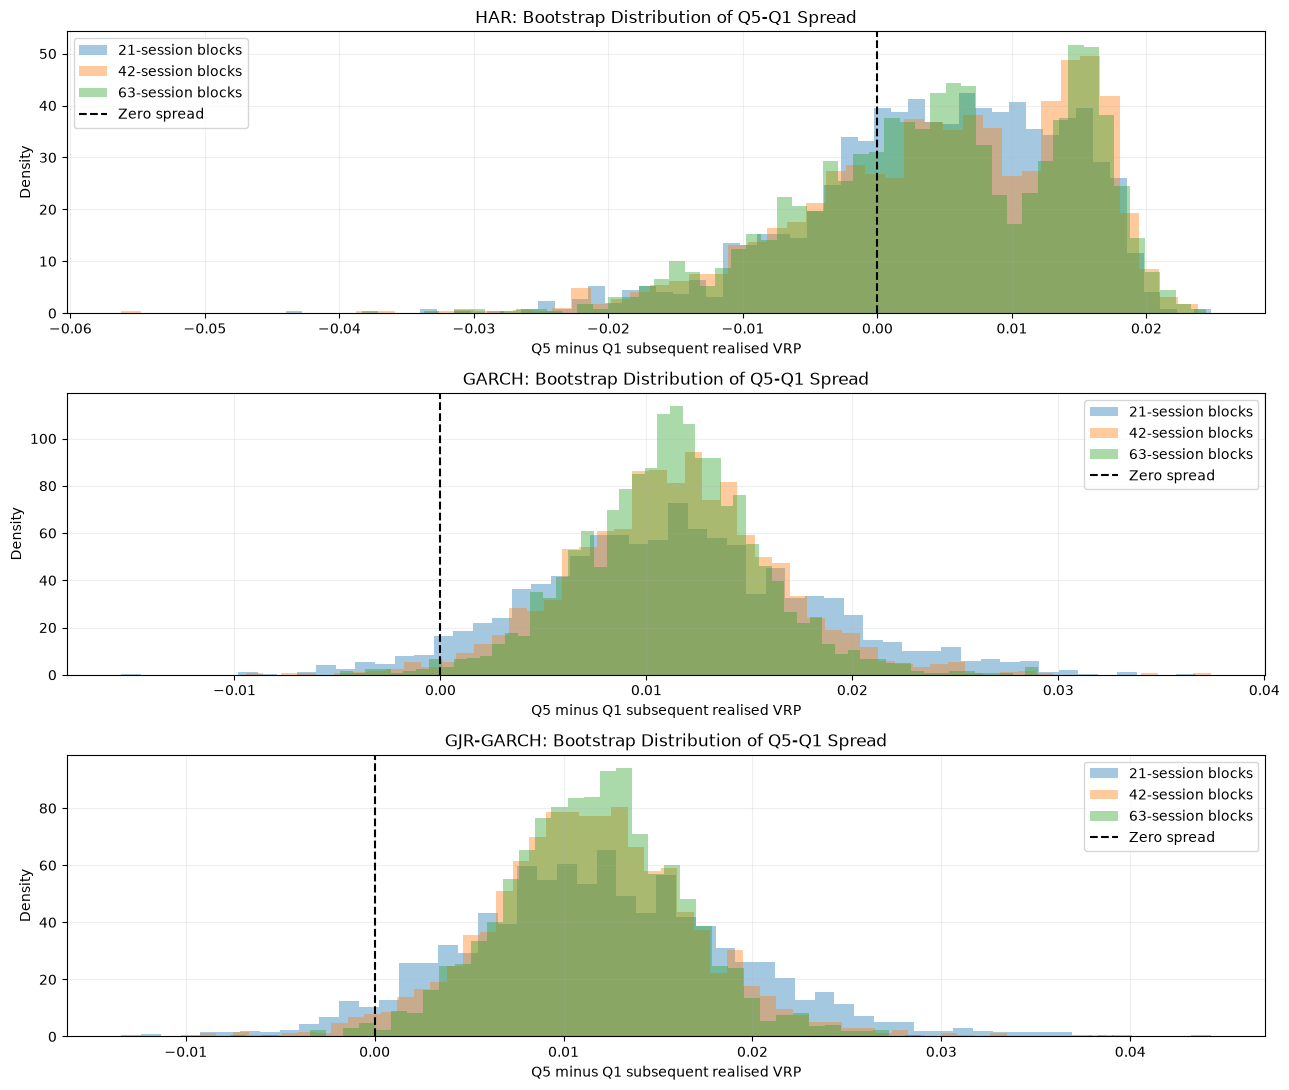


ROBUSTNESS SUMMARY


,Model,Block length,Observed Q5-Q1 spread,95% CI lower,95% CI upper,CI excludes zero
0,HAR,21,0.004638,-0.017785,0.018425,False
1,HAR,42,0.004638,-0.017048,0.018916,False
2,HAR,63,0.004638,-0.016181,0.019248,False
3,GARCH,21,0.011408,-0.001485,0.025609,False
4,GARCH,42,0.011408,0.001550,0.021179,True
5,GARCH,63,0.011408,0.002206,0.020061,True
6,GJR-GARCH,21,0.012258,-0.001682,0.026664,False
7,GJR-GARCH,42,0.012258,0.000474,0.022358,True
8,GJR-GARCH,63,0.012258,0.002464,0.021348,True



STAGE 13 COMPLETED


In [19]:

# ============================================================
# STAGE 13: MOVING-BLOCK BOOTSTRAP OF VRP SIGNAL SPREAD
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Bootstrap settings
# ------------------------------------------------------------

BLOCK_LENGTHS = [21, 42, 63]
N_BOOTSTRAPS = 2000
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

bootstrap_results = []
bootstrap_distributions = {}

# ------------------------------------------------------------
# 2. Circular moving-block bootstrap function
# ------------------------------------------------------------

def moving_block_bootstrap(data, block_length, n_bootstraps):

    data = data.reset_index(drop=True)

    n = len(data)

    quintiles = data["Quintile"].astype(str).to_numpy()
    outcomes = data["Ex-post VRP"].to_numpy(dtype=float)

    # Observed Q5 minus Q1 difference
    q1 = outcomes[quintiles == "Q1"]
    q5 = outcomes[quintiles == "Q5"]

    if len(q1) == 0 or len(q5) == 0:
        raise ValueError("Q1 or Q5 has no observations.")

    observed_spread = q5.mean() - q1.mean()

    bootstrap_spreads = []

    n_blocks = int(np.ceil(n / block_length))

    for _ in range(n_bootstraps):

        # Randomly select circular block starting points
        starts = rng.integers(
            0, n, size=n_blocks
        )

        # Construct consecutive blocks
        indices = np.concatenate([
            (start + np.arange(block_length)) % n
            for start in starts
        ])[:n]

        sampled_quintiles = quintiles[indices]
        sampled_outcomes = outcomes[indices]

        sampled_q1 = sampled_outcomes[
            sampled_quintiles == "Q1"
        ]

        sampled_q5 = sampled_outcomes[
            sampled_quintiles == "Q5"
        ]

        if len(sampled_q1) == 0 or len(sampled_q5) == 0:
            continue

        spread = sampled_q5.mean() - sampled_q1.mean()

        bootstrap_spreads.append(spread)

    bootstrap_spreads = np.asarray(bootstrap_spreads)

    if len(bootstrap_spreads) < 0.9 * n_bootstraps:
        raise RuntimeError(
            "Too many bootstrap samples lacked Q1 or Q5 observations."
        )

    # Percentile confidence interval
    ci_lower, ci_upper = np.quantile(
        bootstrap_spreads,
        [0.025, 0.975]
    )

    # Bootstrap probability of a positive spread
    positive_probability = np.mean(
        bootstrap_spreads > 0
    )

    return {
        "Observed Q5-Q1 spread": observed_spread,
        "Bootstrap standard error": bootstrap_spreads.std(ddof=1),
        "95% CI lower": ci_lower,
        "95% CI upper": ci_upper,
        "Probability spread is positive": positive_probability,
        "Valid bootstrap samples": len(bootstrap_spreads)
    }, bootstrap_spreads


# ------------------------------------------------------------
# 3. Run bootstrap for each model and block length
# ------------------------------------------------------------

for model_name in ["HAR", "GARCH", "GJR-GARCH"]:

    model_data = rolling_quintile_data[
        rolling_quintile_data["Model"] == model_name
    ].sort_values("Date").copy()

    print(
        f"\nProcessing {model_name}: "
        f"{len(model_data)} observations"
    )

    for block_length in BLOCK_LENGTHS:

        result, distribution = moving_block_bootstrap(
            model_data,
            block_length,
            N_BOOTSTRAPS
        )

        bootstrap_results.append({
            "Model": model_name,
            "Block length": block_length,
            **result
        })

        bootstrap_distributions[
            (model_name, block_length)
        ] = distribution


# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------

bootstrap_table = pd.DataFrame(
    bootstrap_results
)

print("\nMOVING-BLOCK BOOTSTRAP RESULTS")

display(bootstrap_table.round(6))


# ------------------------------------------------------------
# 5. Visualise bootstrap distributions
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3, 1,
    figsize=(13, 11)
)

for ax, model_name in zip(
    axes,
    ["HAR", "GARCH", "GJR-GARCH"]
):

    for block_length in BLOCK_LENGTHS:

        distribution = bootstrap_distributions[
            (model_name, block_length)
        ]

        ax.hist(
            distribution,
            bins=55,
            alpha=0.4,
            density=True,
            label=f"{block_length}-session blocks"
        )

    ax.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Zero spread"
    )

    ax.set_title(
        f"{model_name}: Bootstrap Distribution of Q5-Q1 Spread"
    )

    ax.set_xlabel("Q5 minus Q1 subsequent realised VRP")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Identify confidence intervals excluding zero
# ------------------------------------------------------------

bootstrap_table["CI excludes zero"] = (
    (bootstrap_table["95% CI lower"] > 0)
    | (bootstrap_table["95% CI upper"] < 0)
)

print("\nROBUSTNESS SUMMARY")

display(
    bootstrap_table[
        [
            "Model",
            "Block length",
            "Observed Q5-Q1 spread",
            "95% CI lower",
            "95% CI upper",
            "CI excludes zero"
        ]
    ].round(6)
)

print("\nSTAGE 13 COMPLETED")


## Stage 13B — Multiple-testing correction
Apply a global bootstrap correction across the tested models and block lengths.


In [20]:

# ============================================================
# STAGE 13B: GLOBAL BOOTSTRAP ROBUSTNESS
# ============================================================

import numpy as np
import pandas as pd

# Family-wise significance level
FAMILY_ALPHA = 0.05

# Nine comparisons: 3 models x 3 block lengths
N_TESTS = len(bootstrap_distributions)

# Bonferroni-adjusted significance level
ADJUSTED_ALPHA = FAMILY_ALPHA / N_TESTS

LOWER_QUANTILE = ADJUSTED_ALPHA / 2
UPPER_QUANTILE = 1 - ADJUSTED_ALPHA / 2

global_bootstrap_results = []

for (model, block_length), distribution in (
    bootstrap_distributions.items()
):

    observed = bootstrap_table.loc[
        (bootstrap_table["Model"] == model)
        & (
            bootstrap_table["Block length"]
            == block_length
        ),
        "Observed Q5-Q1 spread"
    ].iloc[0]

    lower = np.quantile(
        distribution,
        LOWER_QUANTILE
    )

    upper = np.quantile(
        distribution,
        UPPER_QUANTILE
    )

    global_bootstrap_results.append({
        "Model": model,
        "Block length": block_length,
        "Observed spread": observed,
        "Global CI lower": lower,
        "Global CI upper": upper,
        "Global CI excludes zero": (
            lower > 0 or upper < 0
        )
    })

global_bootstrap_table = pd.DataFrame(
    global_bootstrap_results
).sort_values(
    ["Model", "Block length"]
)

print("Number of comparisons:", N_TESTS)
print("Family-wise alpha:", FAMILY_ALPHA)
print("Adjusted alpha per comparison:", ADJUSTED_ALPHA)

print("\nGLOBAL BOOTSTRAP CONFIDENCE INTERVALS")

display(global_bootstrap_table.round(6))

print("\nComparisons surviving global correction:")

display(
    global_bootstrap_table[
        global_bootstrap_table[
            "Global CI excludes zero"
        ]
    ]
)


Number of comparisons: 9
Family-wise alpha: 0.05
Adjusted alpha per comparison: 0.005555555555555556

GLOBAL BOOTSTRAP CONFIDENCE INTERVALS


,Model,Block length,Observed spread,Global CI lower,Global CI upper,Global CI excludes zero
3,GARCH,21,0.011408,-0.006249,0.030580,False
4,GARCH,42,0.011408,-0.003524,0.027969,False
5,GARCH,63,0.011408,-0.003015,0.026262,False
6,GJR-GARCH,21,0.012258,-0.008510,0.035809,False
7,GJR-GARCH,42,0.012258,-0.005773,0.029428,False
8,GJR-GARCH,63,0.012258,-0.002091,0.026511,False
0,HAR,21,0.004638,-0.025440,0.020781,False
1,HAR,42,0.004638,-0.029441,0.022227,False
2,HAR,63,0.004638,-0.028260,0.022452,False



Comparisons surviving global correction:


,Model,Block length,Observed spread,Global CI lower,Global CI upper,Global CI excludes zero


## Stage 14 — Non-overlapping validation
Repeat the VRP spread test across non-overlapping cohorts to assess sensitivity to the starting date.


NON-OVERLAPPING COHORT RESULTS


,Model,Offset,Observations,Q1 observations,Q5 observations,Q1 mean,Q5 mean,Q5-Q1 spread
0,HAR,0,46,13,8,0.010548,0.018945,0.008398
1,HAR,1,46,13,5,0.009818,0.013328,0.003511
2,HAR,2,46,9,7,0.009628,-0.005404,-0.015031
3,HAR,3,46,11,9,0.010330,-0.004628,-0.014958
4,HAR,4,46,12,9,0.010907,-0.000636,-0.011543
5,HAR,5,46,10,10,-0.002834,0.020516,0.023350
6,HAR,6,46,12,10,0.012375,0.022038,0.009663
7,HAR,7,46,13,8,0.009658,0.035529,0.025871
8,HAR,8,46,12,8,0.011331,0.034914,0.023583
9,HAR,9,46,14,8,0.013684,0.013505,-0.000179



COHORT ROBUSTNESS SUMMARY


,Valid_cohorts,Mean_spread,Median_spread,Standard_deviation,Minimum_spread,Maximum_spread,Positive_cohort_fraction
Model,,,,,,,
GARCH,21,0.011938,0.009743,0.022585,-0.026187,0.059034,0.666667
GJR-GARCH,21,0.012714,0.012760,0.011753,-0.011669,0.031533,0.857143
HAR,21,0.003886,0.008398,0.017373,-0.030356,0.025871,0.619048


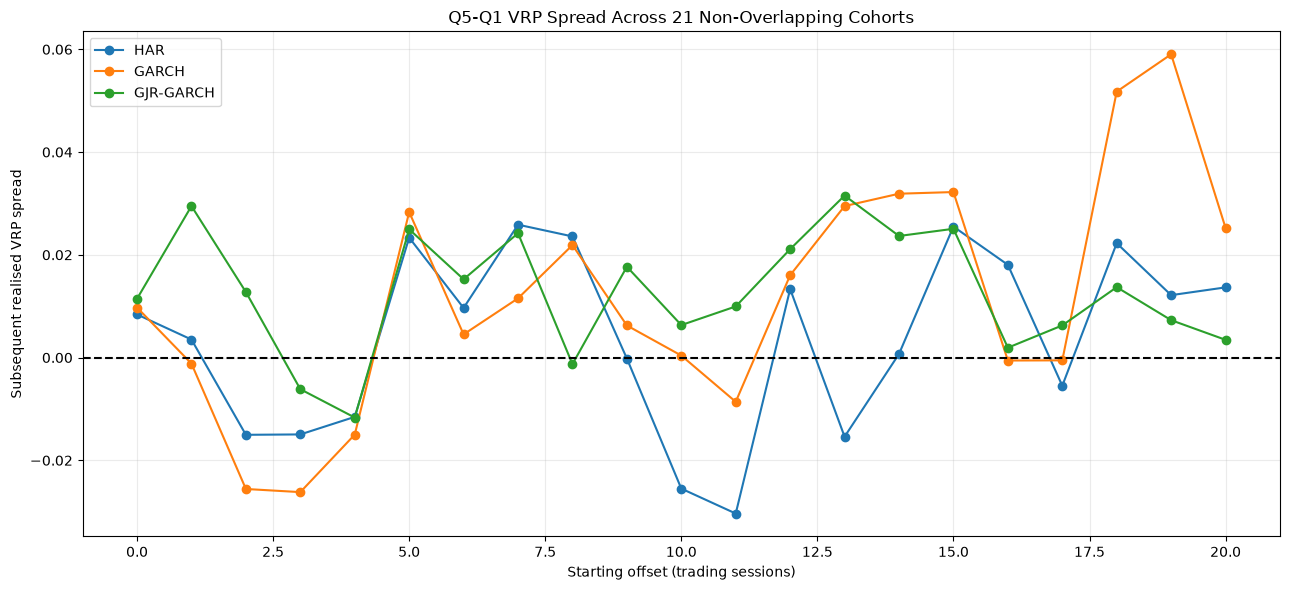

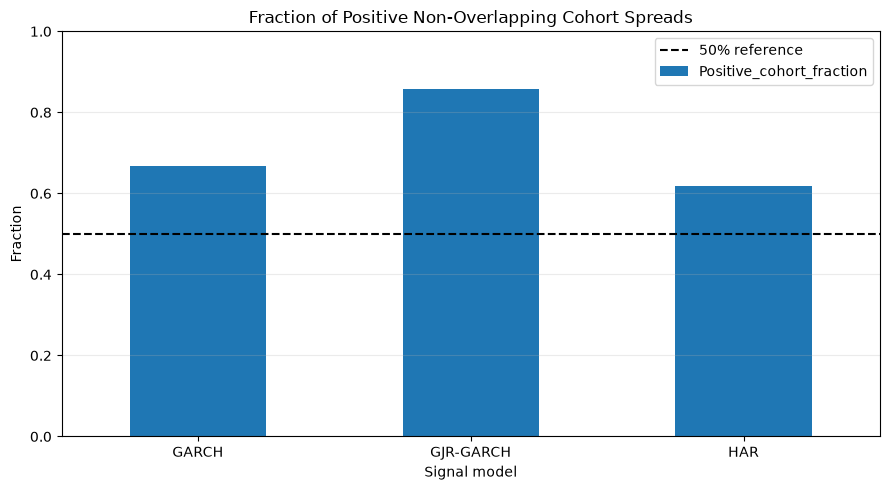


STAGE 14 COMPLETED
Horizon: 21 trading sessions
Models evaluated: 3
Total valid cohorts: 63

Available variables:
cohort_table
cohort_summary


In [21]:

# ============================================================
# STAGE 14: NON-OVERLAPPING VRP SIGNAL VALIDATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MODELS = ["HAR", "GARCH", "GJR-GARCH"]
HORIZON = 21
MIN_Q1_Q5 = 3

cohort_results = []

# ------------------------------------------------------------
# 1. Construct 21 non-overlapping cohorts
# ------------------------------------------------------------

for model in MODELS:

    model_data = (
        rolling_quintile_data[
            rolling_quintile_data["Model"] == model
        ]
        .sort_values("Date")
        .reset_index(drop=True)
    )

    for offset in range(HORIZON):

        # Each cohort contains observations spaced
        # 21 trading sessions apart.

        cohort = model_data.iloc[offset::HORIZON].copy()

        q1 = cohort[
            cohort["Quintile"] == "Q1"
        ]["Ex-post VRP"]

        q5 = cohort[
            cohort["Quintile"] == "Q5"
        ]["Ex-post VRP"]

        if min(len(q1), len(q5)) < MIN_Q1_Q5:
            continue

        spread = q5.mean() - q1.mean()

        cohort_results.append({
            "Model": model,
            "Offset": offset,
            "Observations": len(cohort),
            "Q1 observations": len(q1),
            "Q5 observations": len(q5),
            "Q1 mean": q1.mean(),
            "Q5 mean": q5.mean(),
            "Q5-Q1 spread": spread
        })

cohort_table = pd.DataFrame(cohort_results)

print("NON-OVERLAPPING COHORT RESULTS")
display(cohort_table.round(6))


# ------------------------------------------------------------
# 2. Summarise consistency across starting dates
# ------------------------------------------------------------

cohort_summary = (
    cohort_table
    .groupby("Model")
    .agg(
        Valid_cohorts=("Offset", "count"),
        Mean_spread=("Q5-Q1 spread", "mean"),
        Median_spread=("Q5-Q1 spread", "median"),
        Standard_deviation=("Q5-Q1 spread", "std"),
        Minimum_spread=("Q5-Q1 spread", "min"),
        Maximum_spread=("Q5-Q1 spread", "max"),
        Positive_cohort_fraction=(
            "Q5-Q1 spread",
            lambda x: (x > 0).mean()
        )
    )
)

print("\nCOHORT ROBUSTNESS SUMMARY")
display(cohort_summary.round(6))


# ------------------------------------------------------------
# 3. Plot Q5-Q1 spread by cohort offset
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 6))

for model in MODELS:

    subset = cohort_table[
        cohort_table["Model"] == model
    ]

    ax.plot(
        subset["Offset"],
        subset["Q5-Q1 spread"],
        marker="o",
        label=model
    )

ax.axhline(
    0,
    color="black",
    linestyle="--"
)

ax.set_title(
    "Q5-Q1 VRP Spread Across 21 Non-Overlapping Cohorts"
)

ax.set_xlabel("Starting offset (trading sessions)")
ax.set_ylabel("Subsequent realised VRP spread")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. Plot proportion of positive cohort spreads
# ------------------------------------------------------------

ax = cohort_summary[
    "Positive_cohort_fraction"
].plot(
    kind="bar",
    figsize=(9, 5)
)

ax.axhline(
    0.5,
    color="black",
    linestyle="--",
    label="50% reference"
)

ax.set_title(
    "Fraction of Positive Non-Overlapping Cohort Spreads"
)

ax.set_ylabel("Fraction")
ax.set_xlabel("Signal model")
ax.set_ylim(0, 1)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. Completion
# ------------------------------------------------------------

print("\nSTAGE 14 COMPLETED")

print("Horizon:", HORIZON, "trading sessions")
print("Models evaluated:", cohort_table["Model"].nunique())
print("Total valid cohorts:", len(cohort_table))

print("\nAvailable variables:")
print("cohort_table")
print("cohort_summary")


## Stage 15 — Out-of-sample VRP prediction
Use expanding-window forecasts to test whether the VRP signal predicts subsequent realised VRP beyond benchmarks.


Available observations: 1084
Start: 2022-05-20 00:00:00
End: 2026-09-16 00:00:00

OUT-OF-SAMPLE FORECASTS
Forecast observations: 812
First forecast: 2023-06-22 00:00:00
Last forecast: 2026-09-16 00:00:00


,Actual,VIX,HAR Signal,GARCH Signal,GJR Signal,Training observations,Historical Mean,VIX Only,HAR,GARCH,GJR-GARCH
Date,,,,,,,,,,,
2023-06-22,0.007485,0.016667,-0.006973,-0.001289,0.002250,252,0.013336,0.004863,0.005127,0.005039,0.006386
2023-06-23,0.009496,0.018063,-0.005521,-0.001653,-0.000043,253,0.013366,0.005303,0.005485,0.005494,0.007034
2023-06-26,0.011981,0.020306,-0.002451,0.001207,0.001970,254,0.013420,0.005935,0.005891,0.006007,0.007431
2023-06-27,0.011612,0.018879,-0.007711,-0.003355,0.002068,255,0.013458,0.005769,0.006322,0.006016,0.007276
2023-06-28,0.009612,0.018036,-0.005253,-0.001826,0.002408,256,0.013485,0.005731,0.005879,0.005919,0.007218



OUT-OF-SAMPLE PREDICTIVE PERFORMANCE


,Observations,MSE,RMSE,MAE,OOS R2 vs historical mean,OOS R2 vs VIX only
Model,,,,,,
Historical Mean,812,0.001020,0.031936,0.014573,0.000000,-0.050791
VIX Only,812,0.000971,0.031155,0.013856,0.048336,0.000000
HAR,812,0.000972,0.031173,0.013923,0.047249,-0.001143
GARCH,812,0.000997,0.031576,0.014273,0.022408,-0.027245
GJR-GARCH,812,0.000980,0.031301,0.013852,0.039399,-0.009391



HAC PREDICTIVE LOSS COMPARISON


,Model,Metric,HAC lags,Mean improvement,HAC standard error,t-statistic,p-value,Global Holm p-value
0,HAR,MSE,42,-0.000001,0.000004,-0.282533,0.777535,1.000000
1,HAR,MAE,42,-0.000067,0.000079,-0.853912,0.393154,1.000000
2,GARCH,MSE,42,-0.000026,0.000019,-1.370018,0.170681,0.853407
3,GARCH,MAE,42,-0.000418,0.000228,-1.833678,0.066702,0.400211
4,GJR-GARCH,MSE,42,-0.000009,0.000010,-0.919289,0.357944,1.000000
5,GJR-GARCH,MAE,42,0.000004,0.000129,0.028977,0.976883,1.000000


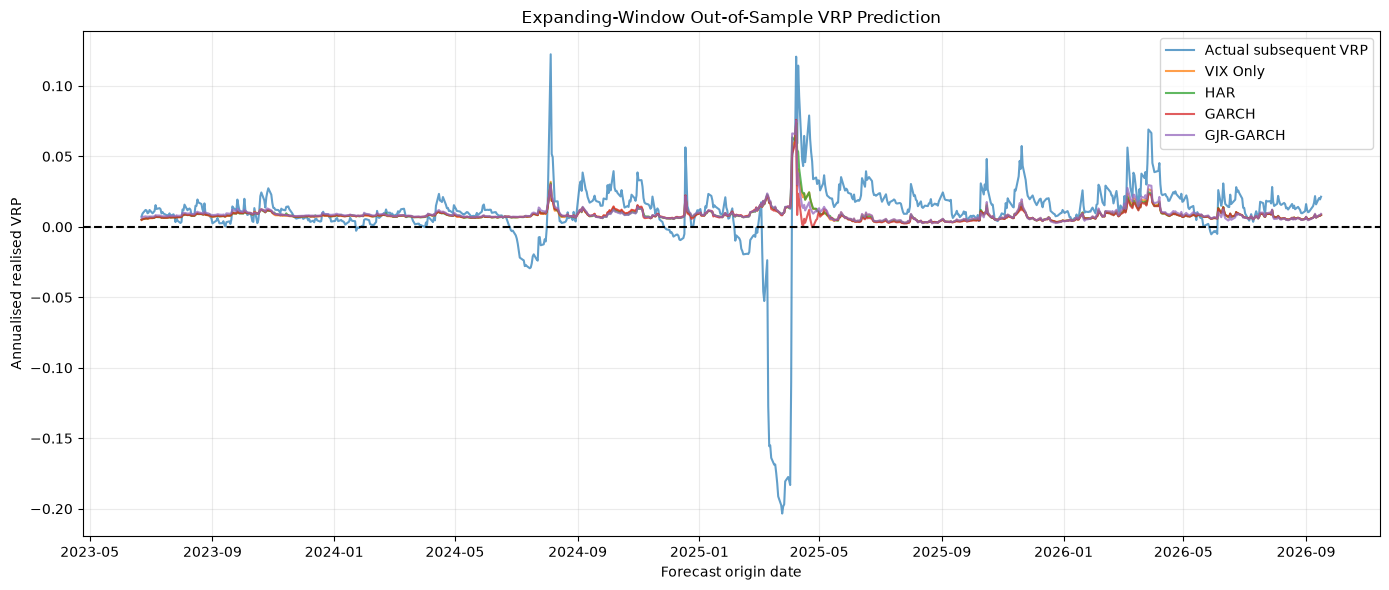

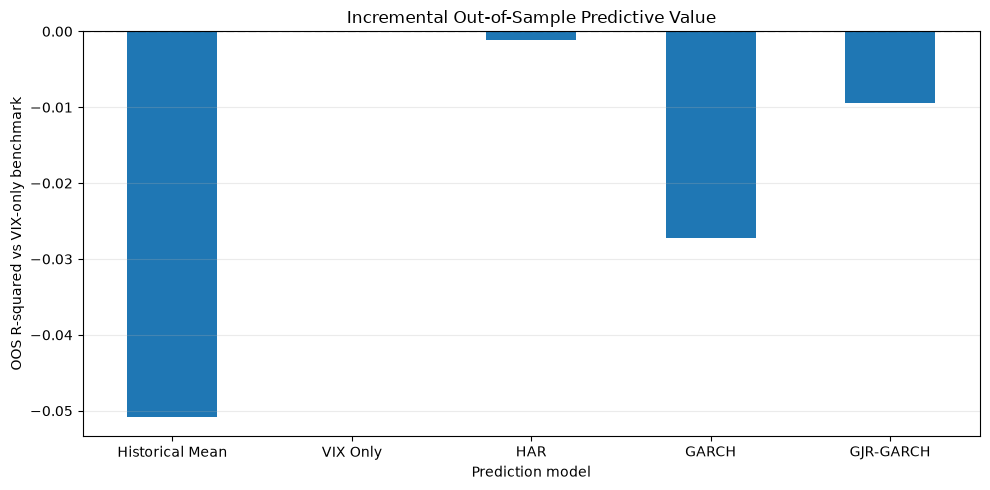


STAGE 15 COMPLETED
Out-of-sample observations: 812

Available variables:
oos_results
oos_comparison
hac_comparison


In [22]:

# ============================================================
# STAGE 15: EXPANDING-WINDOW OUT-OF-SAMPLE VRP PREDICTION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from scipy.stats import norm
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 1. Prepare dataset
# ------------------------------------------------------------

data = (
    vrp_data[
        [
            "implied_variance",
            "realized_vrp",
            "vrp_har",
            "vrp_garch",
            "vrp_gjr"
        ]
    ]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .sort_index()
    .copy()
)

signals = {
    "HAR": "vrp_har",
    "GARCH": "vrp_garch",
    "GJR-GARCH": "vrp_gjr"
}

HORIZON = 21
MIN_TRAIN = 252

print("Available observations:", len(data))
print("Start:", data.index.min())
print("End:", data.index.max())


# ------------------------------------------------------------
# 2. Define forecasting models
# ------------------------------------------------------------

# Benchmark 1: Historical unconditional mean
# Benchmark 2: Current implied variance only
# Models 3-5: Implied variance + ex-ante VRP signal

forecast_records = []

# Require at least 252 matured training observations.
# At forecast origin i, training outcomes are restricted
# to observations j <= i - 21.

for i in range(MIN_TRAIN + HORIZON - 1, len(data)):

    current = data.iloc[i]

    history_end = i - HORIZON + 1

    train = data.iloc[:history_end].copy()

    if len(train) < MIN_TRAIN:
        continue

    y_train = train["realized_vrp"].to_numpy()

    current_forecasts = {
        "Historical Mean": y_train.mean()
    }

    # --------------------------------------------------------
    # Benchmark: implied variance only
    # --------------------------------------------------------

    X_vix = np.column_stack([
        np.ones(len(train)),
        train["implied_variance"].to_numpy()
    ])

    beta_vix = np.linalg.lstsq(
        X_vix,
        y_train,
        rcond=None
    )[0]

    current_vix = np.array([
        1.0,
        current["implied_variance"]
    ])

    current_forecasts["VIX Only"] = (
        current_vix @ beta_vix
    )

    # --------------------------------------------------------
    # Signal models
    # --------------------------------------------------------

    for model_name, signal_column in signals.items():

        X_train = np.column_stack([
            np.ones(len(train)),
            train["implied_variance"].to_numpy(),
            train[signal_column].to_numpy()
        ])

        beta = np.linalg.lstsq(
            X_train,
            y_train,
            rcond=None
        )[0]

        X_current = np.array([
            1.0,
            current["implied_variance"],
            current[signal_column]
        ])

        current_forecasts[model_name] = (
            X_current @ beta
        )

    record = {
        "Date": data.index[i],
        "Actual": current["realized_vrp"],
        "VIX": current["implied_variance"],
        "HAR Signal": current["vrp_har"],
        "GARCH Signal": current["vrp_garch"],
        "GJR Signal": current["vrp_gjr"],
        "Training observations": len(train)
    }

    record.update(current_forecasts)

    forecast_records.append(record)


# ------------------------------------------------------------
# 3. Store out-of-sample forecasts
# ------------------------------------------------------------

oos_results = (
    pd.DataFrame(forecast_records)
    .set_index("Date")
)

print("\nOUT-OF-SAMPLE FORECASTS")

print("Forecast observations:", len(oos_results))
print("First forecast:", oos_results.index.min())
print("Last forecast:", oos_results.index.max())

display(oos_results.head())


# ------------------------------------------------------------
# 4. Calculate predictive accuracy
# ------------------------------------------------------------

model_names = [
    "Historical Mean",
    "VIX Only",
    "HAR",
    "GARCH",
    "GJR-GARCH"
]

actual = oos_results["Actual"]

mean_benchmark_error = (
    actual - oos_results["Historical Mean"]
)

vix_benchmark_error = (
    actual - oos_results["VIX Only"]
)

metric_rows = []

for model_name in model_names:

    forecast = oos_results[model_name]

    error = actual - forecast

    mse = np.mean(error ** 2)
    mae = np.mean(np.abs(error))

    r2_mean = (
        1 - np.sum(error ** 2)
        / np.sum(mean_benchmark_error ** 2)
    )

    r2_vix = (
        1 - np.sum(error ** 2)
        / np.sum(vix_benchmark_error ** 2)
    )

    metric_rows.append({
        "Model": model_name,
        "Observations": len(actual),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mae,
        "OOS R2 vs historical mean": r2_mean,
        "OOS R2 vs VIX only": r2_vix
    })

oos_comparison = (
    pd.DataFrame(metric_rows)
    .set_index("Model")
)

print("\nOUT-OF-SAMPLE PREDICTIVE PERFORMANCE")

display(oos_comparison)


# ------------------------------------------------------------
# 5. HAC comparison against VIX-only benchmark
# ------------------------------------------------------------

# Positive difference means the signal model
# has lower forecast loss than VIX-only.

hac_records = []

for model_name in ["HAR", "GARCH", "GJR-GARCH"]:

    candidate = oos_results[model_name]

    candidate_error = actual - candidate
    benchmark_error = actual - vix_benchmark_error * 0 - oos_results["VIX Only"]

    # MSE loss differential
    mse_difference = (
        benchmark_error ** 2
        - candidate_error ** 2
    )

    # MAE loss differential
    mae_difference = (
        np.abs(benchmark_error)
        - np.abs(candidate_error)
    )

    for metric, difference in [
        ("MSE", mse_difference),
        ("MAE", mae_difference)
    ]:

        hac_model = sm.OLS(
            difference.to_numpy(),
            np.ones((len(difference), 1))
        ).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": 42}
        )

        hac_records.append({
            "Model": model_name,
            "Metric": metric,
            "HAC lags": 42,
            "Mean improvement": hac_model.params[0],
            "HAC standard error": hac_model.bse[0],
            "t-statistic": hac_model.tvalues[0],
            "p-value": hac_model.pvalues[0]
        })

hac_comparison = pd.DataFrame(hac_records)

# Six hypothesis tests: three signals x two metrics.
hac_comparison["Global Holm p-value"] = multipletests(
    hac_comparison["p-value"],
    method="holm"
)[1]

print("\nHAC PREDICTIVE LOSS COMPARISON")

display(hac_comparison.round(6))


# ------------------------------------------------------------
# 6. Plot actual versus predicted realised VRP
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    oos_results.index,
    actual,
    label="Actual subsequent VRP",
    alpha=0.7
)

for model_name in [
    "VIX Only",
    "HAR",
    "GARCH",
    "GJR-GARCH"
]:

    ax.plot(
        oos_results.index,
        oos_results[model_name],
        label=model_name,
        alpha=0.75
    )

ax.axhline(
    0,
    color="black",
    linestyle="--"
)

ax.set_title(
    "Expanding-Window Out-of-Sample VRP Prediction"
)

ax.set_xlabel("Forecast origin date")
ax.set_ylabel("Annualised realised VRP")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Plot OOS R-squared relative to VIX-only benchmark
# ------------------------------------------------------------

ax = oos_comparison[
    "OOS R2 vs VIX only"
].plot(
    kind="bar",
    figsize=(10, 5)
)

ax.axhline(
    0,
    color="black",
    linestyle="--"
)

ax.set_title(
    "Incremental Out-of-Sample Predictive Value"
)

ax.set_xlabel("Prediction model")
ax.set_ylabel("OOS R-squared vs VIX-only benchmark")
ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Completion
# ------------------------------------------------------------

print("\nSTAGE 15 COMPLETED")

print("Out-of-sample observations:", len(oos_results))

print("\nAvailable variables:")
print("oos_results")
print("oos_comparison")
print("hac_comparison")


## Stage 16 — VRP payoff proxy
Translate walk-forward signal ranks into stylised long/short variance exposures; this is not traded-option P&L.


Observations: 812
Evaluation start: 2023-06-22 00:00:00
Evaluation end: 2026-09-16 00:00:00

STRATEGY SUMMARY ACROSS 21 STARTING OFFSETS


,Mean_scheduled_payoff,Median_scheduled_payoff,Mean_active_payoff,Mean_exposure_fraction,Mean_active_entries,Positive_offset_fraction
Strategy,,,,,,
Always flat,0.000000,0.000000,NaN,0.000000,0.000000,0.000000
Always short variance,0.009578,0.008883,0.009578,1.000000,38.666667,1.000000
GARCH Long-Short,0.002334,0.002213,0.006273,0.365754,14.142857,0.714286
GARCH Short-Only,0.003484,0.004463,0.017029,0.195939,7.571429,0.857143
GJR-GARCH Long-Short,0.003090,0.002905,0.008427,0.383105,14.809524,0.904762
GJR-GARCH Short-Only,0.004043,0.004372,0.019750,0.214318,8.285714,0.952381
HAR Long-Short,0.001628,0.001778,0.005011,0.328835,12.714286,0.714286
HAR Short-Only,0.003046,0.003310,0.013639,0.204710,7.904762,0.714286



INDIVIDUAL COHORT RESULTS


,Offset,Strategy,Scheduled entries,Active entries,Short variance entries,Long variance entries,Flat entries,Exposure fraction,Mean payoff per scheduled entry,Mean payoff per active entry,Positive payoff fraction,Total payoff proxy
0,0,Always short variance,39,39,39,0,0,1.000000,0.008115,0.008115,0.871795,0.316493
1,0,Always flat,39,0,0,0,39,0.000000,0.000000,NaN,NaN,0.000000
2,0,HAR Long-Short,39,13,6,7,26,0.333333,0.002162,0.006486,0.538462,0.084317
3,0,HAR Short-Only,39,6,6,0,33,0.153846,0.003310,0.021517,0.833333,0.129101
4,0,GARCH Long-Short,39,14,6,8,25,0.358974,0.005376,0.014976,0.500000,0.209659
...,...,...,...,...,...,...,...,...,...,...,...,...
163,20,HAR Short-Only,38,9,9,0,29,0.236842,0.005324,0.022479,0.888889,0.202308
164,20,GARCH Long-Short,38,10,8,2,28,0.263158,0.009229,0.035070,0.800000,0.350700
165,20,GARCH Short-Only,38,8,8,0,30,0.210526,0.005099,0.024219,0.875000,0.193754
166,20,GJR-GARCH Long-Short,38,13,8,5,25,0.342105,0.002496,0.007296,0.692308,0.094853


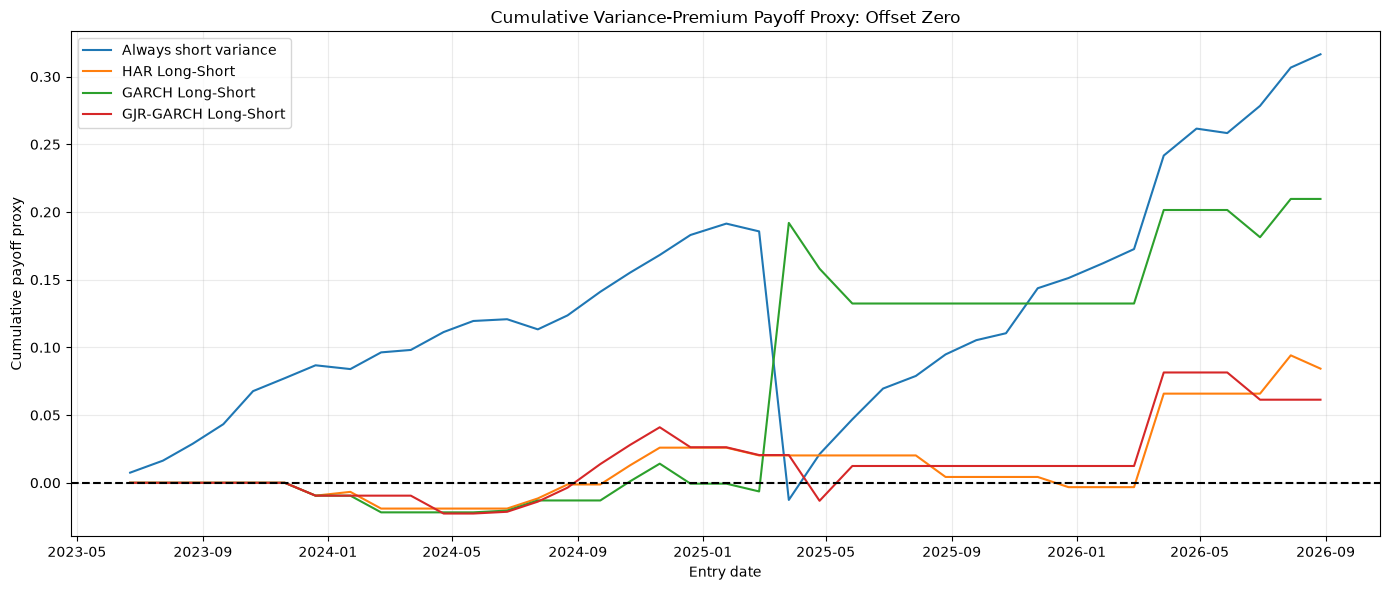

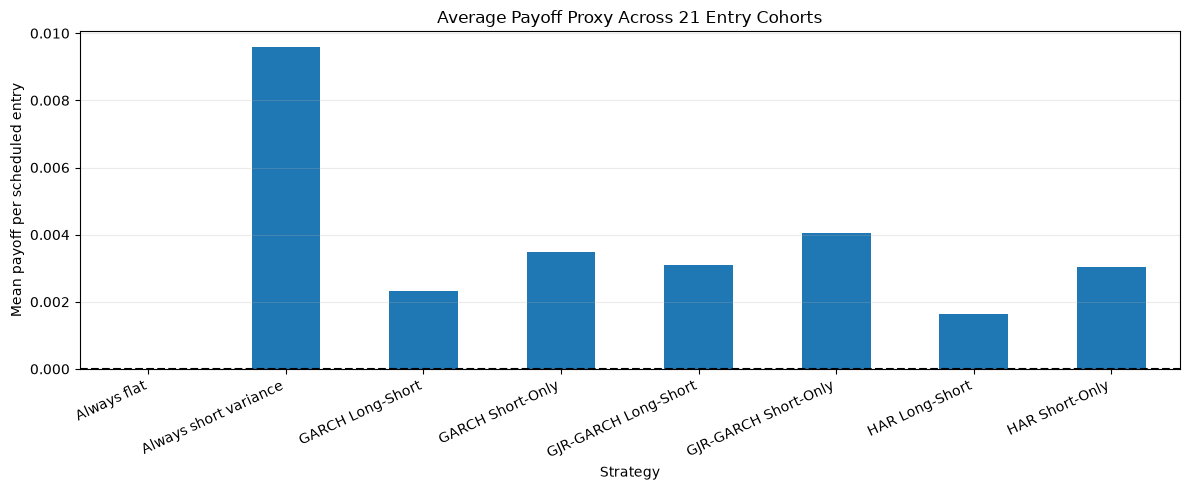


STAGE 16 COMPLETED
Holding period: 21 sessions
Historical threshold lookback: 252
Minimum historical observations: 126
Starting offsets: 21

Available variables:
strategy_data
strategy_results
cohort_results
strategy_summary


In [23]:

# ============================================================
# STAGE 16: WALK-FORWARD VRP PAYOFF PROXY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Prepare data
# ------------------------------------------------------------

required = [
    "Actual",
    "HAR Signal",
    "GARCH Signal",
    "GJR Signal"
]

strategy_data = (
    oos_results[required]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .sort_index()
    .copy()
)

HORIZON = 21
LOOKBACK = 252
MIN_HISTORY = 126

LOW_QUANTILE = 0.20
HIGH_QUANTILE = 0.80

signal_mapping = {
    "HAR": "HAR Signal",
    "GARCH": "GARCH Signal",
    "GJR-GARCH": "GJR Signal"
}

print("Observations:", len(strategy_data))
print("Evaluation start:", strategy_data.index.min())
print("Evaluation end:", strategy_data.index.max())


# ------------------------------------------------------------
# 2. Generate historical rolling thresholds
# ------------------------------------------------------------

for model, column in signal_mapping.items():

    low_thresholds = []
    high_thresholds = []
    long_positions = []
    short_positions = []

    signal = strategy_data[column]

    for i in range(len(strategy_data)):

        current_signal = signal.iloc[i]

        # Only observations strictly before today's signal
        history = signal.iloc[
            max(0, i - LOOKBACK):i
        ].dropna()

        if (
            len(history) < MIN_HISTORY
            or not np.isfinite(current_signal)
        ):

            low_thresholds.append(np.nan)
            high_thresholds.append(np.nan)
            long_positions.append(0)
            short_positions.append(0)

            continue

        low = history.quantile(LOW_QUANTILE)
        high = history.quantile(HIGH_QUANTILE)

        low_thresholds.append(low)
        high_thresholds.append(high)

        # Position convention:
        # +1 = short variance
        # -1 = long variance
        #  0 = no position

        long_short_position = (
            -1 if current_signal <= low
            else 1 if current_signal >= high
            else 0
        )

        short_only_position = (
            1 if current_signal >= high
            else 0
        )

        long_positions.append(long_short_position)
        short_positions.append(short_only_position)

    strategy_data[f"{model}_low_threshold"] = low_thresholds
    strategy_data[f"{model}_high_threshold"] = high_thresholds

    strategy_data[f"{model}_LS_position"] = long_positions
    strategy_data[f"{model}_Short_position"] = short_positions


# ------------------------------------------------------------
# 3. Construct variance-premium payoff proxies
# ------------------------------------------------------------

strategy_positions = {
    "Always short variance": pd.Series(
        1, index=strategy_data.index
    ),

    "Always flat": pd.Series(
        0, index=strategy_data.index
    )
}

for model in signal_mapping:

    strategy_positions[f"{model} Long-Short"] = (
        strategy_data[f"{model}_LS_position"]
    )

    strategy_positions[f"{model} Short-Only"] = (
        strategy_data[f"{model}_Short_position"]
    )

strategy_results = pd.DataFrame(
    index=strategy_data.index
)

strategy_results["Actual VRP"] = strategy_data["Actual"]

for name, position in strategy_positions.items():

    strategy_results[f"{name} Position"] = position

    strategy_results[f"{name} Payoff"] = (
        position * strategy_data["Actual"]
    )


# ------------------------------------------------------------
# 4. Evaluate 21 non-overlapping starting cohorts
# ------------------------------------------------------------

cohort_metrics = []

strategy_names = list(strategy_positions.keys())

for offset in range(HORIZON):

    cohort = strategy_results.iloc[
        offset::HORIZON
    ].copy()

    for strategy in strategy_names:

        positions = cohort[
            f"{strategy} Position"
        ]

        payoffs = cohort[
            f"{strategy} Payoff"
        ]

        active = positions != 0

        active_payoffs = payoffs[active]

        cohort_metrics.append({
            "Offset": offset,
            "Strategy": strategy,
            "Scheduled entries": len(cohort),
            "Active entries": int(active.sum()),
            "Short variance entries": int(
                (positions == 1).sum()
            ),
            "Long variance entries": int(
                (positions == -1).sum()
            ),
            "Flat entries": int(
                (positions == 0).sum()
            ),
            "Exposure fraction": active.mean(),
            "Mean payoff per scheduled entry": payoffs.mean(),
            "Mean payoff per active entry": (
                active_payoffs.mean()
                if len(active_payoffs) else np.nan
            ),
            "Positive payoff fraction": (
                (active_payoffs > 0).mean()
                if len(active_payoffs) else np.nan
            ),
            "Total payoff proxy": payoffs.sum()
        })

cohort_results = pd.DataFrame(cohort_metrics)


# ------------------------------------------------------------
# 5. Summary across starting offsets
# ------------------------------------------------------------

strategy_summary = (
    cohort_results
    .groupby("Strategy")
    .agg(
        Mean_scheduled_payoff=(
            "Mean payoff per scheduled entry", "mean"
        ),
        Median_scheduled_payoff=(
            "Mean payoff per scheduled entry", "median"
        ),
        Mean_active_payoff=(
            "Mean payoff per active entry", "mean"
        ),
        Mean_exposure_fraction=(
            "Exposure fraction", "mean"
        ),
        Mean_active_entries=(
            "Active entries", "mean"
        ),
        Positive_offset_fraction=(
            "Mean payoff per scheduled entry",
            lambda x: (x > 0).mean()
        )
    )
)

print("\nSTRATEGY SUMMARY ACROSS 21 STARTING OFFSETS")

display(strategy_summary.round(6))


# ------------------------------------------------------------
# 6. Individual cohort results
# ------------------------------------------------------------

print("\nINDIVIDUAL COHORT RESULTS")

display(
    cohort_results.round(6)
)


# ------------------------------------------------------------
# 7. Evaluate position selection on offset zero
# ------------------------------------------------------------

primary_cohort = strategy_results.iloc[0::HORIZON].copy()

fig, ax = plt.subplots(figsize=(14, 6))

for strategy in [
    "Always short variance",
    "HAR Long-Short",
    "GARCH Long-Short",
    "GJR-GARCH Long-Short"
]:

    cumulative_payoff = (
        primary_cohort[
            f"{strategy} Payoff"
        ].cumsum()
    )

    ax.plot(
        cumulative_payoff.index,
        cumulative_payoff,
        label=strategy
    )

ax.axhline(0, color="black", linestyle="--")

ax.set_title(
    "Cumulative Variance-Premium Payoff Proxy: Offset Zero"
)

ax.set_xlabel("Entry date")
ax.set_ylabel("Cumulative payoff proxy")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Compare average payoff by strategy
# ------------------------------------------------------------

ax = strategy_summary[
    "Mean_scheduled_payoff"
].plot(
    kind="bar",
    figsize=(12, 5)
)

ax.axhline(0, color="black", linestyle="--")

ax.set_title(
    "Average Payoff Proxy Across 21 Entry Cohorts"
)

ax.set_xlabel("Strategy")
ax.set_ylabel("Mean payoff per scheduled entry")
ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Completion
# ------------------------------------------------------------

print("\nSTAGE 16 COMPLETED")

print("Holding period:", HORIZON, "sessions")
print("Historical threshold lookback:", LOOKBACK)
print("Minimum historical observations:", MIN_HISTORY)
print("Starting offsets:", HORIZON)

print("\nAvailable variables:")
print("strategy_data")
print("strategy_results")
print("cohort_results")
print("strategy_summary")


## Stage 17 — Benchmark comparison
Compare signal-based exposures with an always-short variance benchmark.



STRATEGY VS ALWAYS-SHORT BENCHMARK


,Strategy,Block length,Observations,Mean payoff difference,Bootstrap standard error,Bootstrap p-value,Global Holm p-value,Global CI lower,Global CI upper,CI excludes zero
0,HAR Long-Short,21,812,-0.007971,0.002228,0.001999,0.035988,-0.013115,0.000498,False
1,HAR Long-Short,42,812,-0.007971,0.002400,0.002333,0.039653,-0.013480,0.000300,False
2,HAR Long-Short,63,812,-0.007971,0.002474,0.002333,0.039653,-0.014368,0.000142,False
3,HAR Short-Only,21,812,-0.006548,0.002147,0.006998,0.104965,-0.011106,0.001961,False
4,HAR Short-Only,42,812,-0.006548,0.002362,0.010663,0.149284,-0.011715,0.002236,False
5,HAR Short-Only,63,812,-0.006548,0.002481,0.011663,0.151616,-0.012203,0.001791,False
6,GARCH Long-Short,21,812,-0.007279,0.004727,0.101966,0.509830,-0.018363,0.012517,False
7,GARCH Long-Short,42,812,-0.007279,0.004325,0.078307,0.509830,-0.016925,0.008778,False
8,GARCH Long-Short,63,812,-0.007279,0.003954,0.056648,0.509830,-0.015885,0.006864,False
9,GARCH Short-Only,21,812,-0.006112,0.003006,0.042319,0.465511,-0.012484,0.004840,False



AGGREGATED STRATEGY COMPARISON


,Mean_payoff_difference,Positive_difference_fraction,Minimum_global_CI_lower,Maximum_global_CI_upper
Strategy,,,,
GARCH Long-Short,-0.007279,0.0,-0.018363,0.012517
GARCH Short-Only,-0.006112,0.0,-0.012484,0.006034
GJR-GARCH Long-Short,-0.006501,0.0,-0.017542,0.012081
GJR-GARCH Short-Only,-0.005547,0.0,-0.011930,0.007509
HAR Long-Short,-0.007971,0.0,-0.014368,0.000498
HAR Short-Only,-0.006548,0.0,-0.012203,0.002236


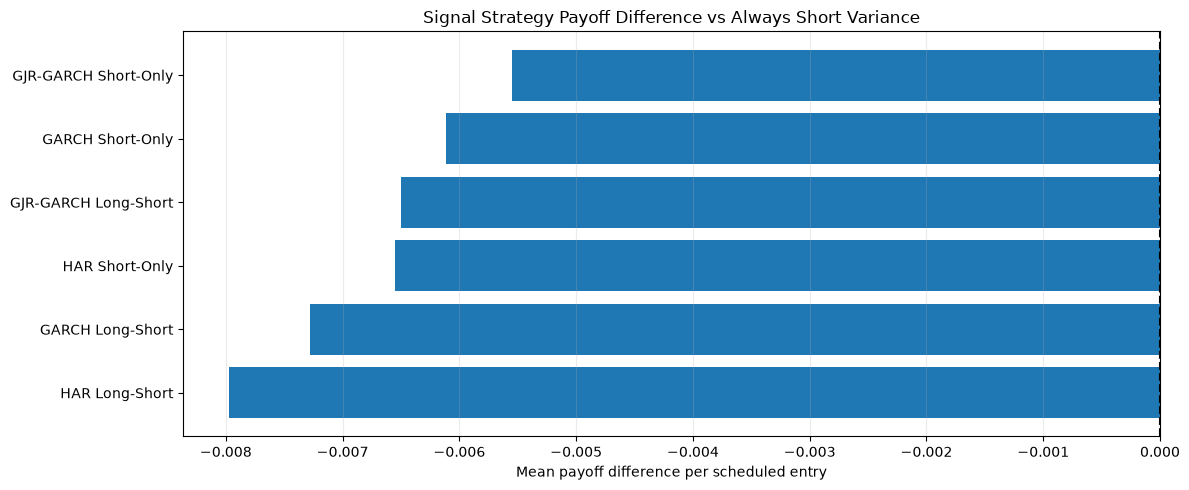


RESULTS SURVIVING GLOBAL HOLM CORRECTION


,Strategy,Block length,Observations,Mean payoff difference,Bootstrap standard error,Bootstrap p-value,Global Holm p-value,Global CI lower,Global CI upper,CI excludes zero
0,HAR Long-Short,21,812,-0.007971,0.002228,0.001999,0.035988,-0.013115,0.000498,False
1,HAR Long-Short,42,812,-0.007971,0.002400,0.002333,0.039653,-0.013480,0.000300,False
2,HAR Long-Short,63,812,-0.007971,0.002474,0.002333,0.039653,-0.014368,0.000142,False



STAGE 17 COMPLETED


In [24]:

# ============================================================
# STAGE 17: SIGNAL STRATEGY VS ALWAYS-SHORT BENCHMARK
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 1. Prepare payoff data
# ------------------------------------------------------------

payoff_data = strategy_results.copy().sort_index()

benchmark_column = "Always short variance Payoff"

alternative_strategies = [
    "HAR Long-Short",
    "HAR Short-Only",
    "GARCH Long-Short",
    "GARCH Short-Only",
    "GJR-GARCH Long-Short",
    "GJR-GARCH Short-Only"
]

BLOCK_LENGTHS = [21, 42, 63]
N_BOOTSTRAPS = 3000

rng = np.random.default_rng(42)

# ------------------------------------------------------------
# 2. Circular moving-block bootstrap
# ------------------------------------------------------------

def bootstrap_mean_difference(
    differences,
    block_length,
    n_bootstraps
):

    x = np.asarray(differences, dtype=float)
    x = x[np.isfinite(x)]

    n = len(x)
    observed_mean = x.mean()

    n_blocks = int(np.ceil(n / block_length))

    bootstrap_means = []

    for _ in range(n_bootstraps):

        starts = rng.integers(
            0, n, size=n_blocks
        )

        indices = np.concatenate([
            (start + np.arange(block_length)) % n
            for start in starts
        ])[:n]

        bootstrap_means.append(
            x[indices].mean()
        )

    bootstrap_means = np.asarray(bootstrap_means)

    # Center the bootstrap distribution to impose
    # the null hypothesis of zero mean difference.

    null_distribution = (
        bootstrap_means - observed_mean
    )

    p_value = (
        1 + np.sum(
            np.abs(null_distribution)
            >= abs(observed_mean)
        )
    ) / (n_bootstraps + 1)

    return {
        "Observations": n,
        "Mean payoff difference": observed_mean,
        "Bootstrap standard error": bootstrap_means.std(ddof=1),
        "Bootstrap p-value": p_value
    }, bootstrap_means


# ------------------------------------------------------------
# 3. Compare each strategy with always short variance
# ------------------------------------------------------------

bootstrap_strategy_results = []
bootstrap_distributions = {}

benchmark = payoff_data[benchmark_column]

for strategy in alternative_strategies:

    strategy_column = f"{strategy} Payoff"

    differences = (
        payoff_data[strategy_column] - benchmark
    ).dropna()

    for block_length in BLOCK_LENGTHS:

        result, distribution = bootstrap_mean_difference(
            differences,
            block_length,
            N_BOOTSTRAPS
        )

        bootstrap_strategy_results.append({
            "Strategy": strategy,
            "Block length": block_length,
            **result
        })

        bootstrap_distributions[
            (strategy, block_length)
        ] = distribution


# ------------------------------------------------------------
# 4. Multiple-testing correction
# ------------------------------------------------------------

strategy_test_table = pd.DataFrame(
    bootstrap_strategy_results
)

strategy_test_table["Global Holm p-value"] = (
    multipletests(
        strategy_test_table["Bootstrap p-value"],
        method="holm"
    )[1]
)

# Bonferroni confidence intervals:
# Six strategies multiplied by three block lengths.

n_tests = len(strategy_test_table)

adjusted_alpha = 0.05 / n_tests

strategy_test_table["Global CI lower"] = np.nan
strategy_test_table["Global CI upper"] = np.nan

for row_index, row in strategy_test_table.iterrows():

    distribution = bootstrap_distributions[
        (row["Strategy"], row["Block length"])
    ]

    strategy_test_table.loc[
        row_index, "Global CI lower"
    ] = np.quantile(
        distribution,
        adjusted_alpha / 2
    )

    strategy_test_table.loc[
        row_index, "Global CI upper"
    ] = np.quantile(
        distribution,
        1 - adjusted_alpha / 2
    )

strategy_test_table["CI excludes zero"] = (
    (strategy_test_table["Global CI lower"] > 0)
    | (strategy_test_table["Global CI upper"] < 0)
)

# Positive difference means the signal strategy
# outperformed always short variance.

print("\nSTRATEGY VS ALWAYS-SHORT BENCHMARK")

display(
    strategy_test_table.round(6)
)


# ------------------------------------------------------------
# 5. Aggregate results across block lengths
# ------------------------------------------------------------

strategy_overview = (
    strategy_test_table
    .groupby("Strategy")
    .agg(
        Mean_payoff_difference=(
            "Mean payoff difference", "first"
        ),
        Positive_difference_fraction=(
            "Mean payoff difference",
            lambda x: (x > 0).mean()
        ),
        Minimum_global_CI_lower=(
            "Global CI lower", "min"
        ),
        Maximum_global_CI_upper=(
            "Global CI upper", "max"
        )
    )
)

print("\nAGGREGATED STRATEGY COMPARISON")

display(strategy_overview.round(6))


# ------------------------------------------------------------
# 6. Visualise mean payoff differences
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 5))

strategy_means = (
    strategy_test_table
    .groupby("Strategy")["Mean payoff difference"]
    .first()
    .sort_values()
)

ax.barh(
    strategy_means.index,
    strategy_means.values
)

ax.axvline(
    0,
    color="black",
    linestyle="--"
)

ax.set_title(
    "Signal Strategy Payoff Difference vs Always Short Variance"
)

ax.set_xlabel(
    "Mean payoff difference per scheduled entry"
)

ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Display statistically significant results
# ------------------------------------------------------------

print("\nRESULTS SURVIVING GLOBAL HOLM CORRECTION")

display(
    strategy_test_table[
        strategy_test_table["Global Holm p-value"] < 0.05
    ].round(6)
)

print("\nSTAGE 17 COMPLETED")


## Stage 17B — Corrected strategy inference
Use block-bootstrap inference and global correction to test strategy differences against the benchmark.


In [25]:

# ============================================================
# STAGE 17B: CORRECTED BOOTSTRAP INFERENCE
# ============================================================

import numpy as np
import pandas as pd
from statsmodels.stats.multitest import multipletests

N_BOOTSTRAPS = 20000
BLOCK_LENGTHS = [21, 42, 63]
FAMILY_ALPHA = 0.05

rng = np.random.default_rng(20261113)

benchmark_column = "Always short variance Payoff"

alternative_strategies = [
    "HAR Long-Short",
    "HAR Short-Only",
    "GARCH Long-Short",
    "GARCH Short-Only",
    "GJR-GARCH Long-Short",
    "GJR-GARCH Short-Only"
]

# Nine? No: six strategies multiplied by three
# block lengths = 18 simultaneous comparisons.
N_TESTS = len(alternative_strategies) * len(BLOCK_LENGTHS)

adjusted_alpha = FAMILY_ALPHA / N_TESTS

results = []
distributions = {}

# ------------------------------------------------------------
# Circular moving-block bootstrap
# ------------------------------------------------------------

def run_bootstrap(x, block_length, repetitions):

    x = np.asarray(x, dtype=float)
    n = len(x)

    observed = x.mean()
    n_blocks = int(np.ceil(n / block_length))

    boot_means = np.empty(repetitions)

    for b in range(repetitions):

        starts = rng.integers(
            0, n, size=n_blocks
        )

        indices = np.concatenate([
            (start + np.arange(block_length)) % n
            for start in starts
        ])[:n]

        boot_means[b] = x[indices].mean()

    # Null-centred bootstrap test
    null_distribution = boot_means - observed

    p_value = (
        1 + np.sum(
            np.abs(null_distribution) >= abs(observed)
        )
    ) / (repetitions + 1)

    # Basic bootstrap confidence interval
    q_low = np.quantile(
        boot_means, adjusted_alpha / 2
    )

    q_high = np.quantile(
        boot_means, 1 - adjusted_alpha / 2
    )

    ci_lower = 2 * observed - q_high
    ci_upper = 2 * observed - q_low

    return {
        "Observed difference": observed,
        "Bootstrap SE": boot_means.std(ddof=1),
        "Bootstrap p-value": p_value,
        "Global CI lower": ci_lower,
        "Global CI upper": ci_upper
    }


# ------------------------------------------------------------
# Run all comparisons
# ------------------------------------------------------------

benchmark = strategy_results[benchmark_column]

for strategy in alternative_strategies:

    difference = (
        strategy_results[f"{strategy} Payoff"]
        - benchmark
    ).dropna()

    for block_length in BLOCK_LENGTHS:

        print(
            f"Processing {strategy}, "
            f"block length {block_length}"
        )

        result = run_bootstrap(
            difference,
            block_length,
            N_BOOTSTRAPS
        )

        results.append({
            "Strategy": strategy,
            "Block length": block_length,
            "Observations": len(difference),
            **result
        })

# ------------------------------------------------------------
# Apply global Holm correction
# ------------------------------------------------------------

corrected_results = pd.DataFrame(results)

corrected_results["Global Holm p-value"] = (
    multipletests(
        corrected_results["Bootstrap p-value"],
        method="holm"
    )[1]
)

corrected_results["CI excludes zero"] = (
    (corrected_results["Global CI lower"] > 0)
    | (corrected_results["Global CI upper"] < 0)
)

print("\nCORRECTED GLOBAL BOOTSTRAP RESULTS")

display(
    corrected_results.sort_values(
        ["Strategy", "Block length"]
    ).round(6)
)

print("\nRESULTS SURVIVING GLOBAL HOLM CORRECTION")

display(
    corrected_results[
        corrected_results["Global Holm p-value"] < 0.05
    ].round(6)
)

print("\nSTAGE 17B COMPLETED")


Processing HAR Long-Short, block length 21
Processing HAR Long-Short, block length 42
Processing HAR Long-Short, block length 63
Processing HAR Short-Only, block length 21
Processing HAR Short-Only, block length 42
Processing HAR Short-Only, block length 63
Processing GARCH Long-Short, block length 21
Processing GARCH Long-Short, block length 42
Processing GARCH Long-Short, block length 63
Processing GARCH Short-Only, block length 21
Processing GARCH Short-Only, block length 42
Processing GARCH Short-Only, block length 63
Processing GJR-GARCH Long-Short, block length 21
Processing GJR-GARCH Long-Short, block length 42
Processing GJR-GARCH Long-Short, block length 63
Processing GJR-GARCH Short-Only, block length 21
Processing GJR-GARCH Short-Only, block length 42
Processing GJR-GARCH Short-Only, block length 63

CORRECTED GLOBAL BOOTSTRAP RESULTS


,Strategy,Block length,Observations,Observed difference,Bootstrap SE,Bootstrap p-value,Global CI lower,Global CI upper,Global Holm p-value,CI excludes zero
6,GARCH Long-Short,21,812,-0.007279,0.004614,0.095995,-0.025599,0.003052,0.524224,False
7,GARCH Long-Short,42,812,-0.007279,0.004311,0.078296,-0.023978,0.002371,0.524224,False
8,GARCH Long-Short,63,812,-0.007279,0.003997,0.058247,-0.022462,0.001543,0.524224,False
9,GARCH Short-Only,21,812,-0.006112,0.003090,0.042998,-0.018163,0.000264,0.453727,False
10,GARCH Short-Only,42,812,-0.006112,0.003036,0.041248,-0.018084,0.000065,0.453727,False
11,GARCH Short-Only,63,812,-0.006112,0.002942,0.035598,-0.017549,0.000097,0.427179,False
12,GJR-GARCH Long-Short,21,812,-0.006501,0.004756,0.147643,-0.025224,0.003830,0.524224,False
13,GJR-GARCH Long-Short,42,812,-0.006501,0.004446,0.115644,-0.023319,0.002351,0.524224,False
14,GJR-GARCH Long-Short,63,812,-0.006501,0.004243,0.098445,-0.023543,0.001781,0.524224,False
15,GJR-GARCH Short-Only,21,812,-0.005547,0.003168,0.064947,-0.017614,0.000782,0.524224,False



RESULTS SURVIVING GLOBAL HOLM CORRECTION


,Strategy,Block length,Observations,Observed difference,Bootstrap SE,Bootstrap p-value,Global CI lower,Global CI upper,Global Holm p-value,CI excludes zero
0,HAR Long-Short,21,812,-0.007971,0.002234,0.00235,-0.016548,-0.002787,0.039948,True
1,HAR Long-Short,42,812,-0.007971,0.002399,0.00235,-0.016446,-0.002248,0.039948,True
2,HAR Long-Short,63,812,-0.007971,0.002479,0.00200,-0.016171,-0.001771,0.035998,True



STAGE 17B COMPLETED


## Stage 18 — Synthetic gamma-scalping simulation
Price European straddles with Black–Scholes and simulate daily delta hedging using VIX as an implied-volatility proxy.


Synthetic gamma-scalping configuration loaded.
Signal observations: 812



C:\Users\Bhavya\AppData\Local\Temp\ipykernel_5736\1509532372.py:147: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  simulation_data = pd.concat(



Simulation dataset
Observations: 812
Start: 2023-06-22 00:00:00
End: 2026-09-16 00:00:00
Maximum calendar holding period: 35
Option initial maturity: 42
Minimum remaining maturity at exit: 7 days

SIMULATED TRADES
Total trade records: 160
Entry dates: 32


,Entry date,Exit date,Holding sessions,Direction,Entry SPX,Strike,Entry VIX,Entry option premium,Exit option value,Entry gamma,Option P&L,Hedge P&L,Gross P&L,Hedge turnover,Hedge cost,Net P&L,Net return on premium (%),Strategy,Signal,Signal status,Low threshold,High threshold
0,2023-12-21,2024-01-24,21,-1,4746.750000,4746.750000,13.65,175.351093,130.271543,0.007258,45.079550,7.524381,52.603931,14275.229775,1.427523,51.176408,29.185109,Always Short Straddle,NaN,NaN,NaN,NaN
1,2023-12-21,2024-01-24,21,1,4746.750000,4746.750000,13.65,175.351093,130.271543,0.007258,-45.079550,-7.524381,-52.603931,14275.229775,1.427523,-54.031454,-30.813297,Always Long Straddle,NaN,NaN,NaN,NaN
2,2023-12-21,2024-01-24,21,1,4746.750000,4746.750000,13.65,175.351093,130.271543,0.007258,-45.079550,-7.524381,-52.603931,14275.229775,1.427523,-54.031454,-30.813297,HAR Timing,-0.009723,Long straddle,-0.005953,0.004490
3,2023-12-21,2024-01-24,21,1,4746.750000,4746.750000,13.65,175.351093,130.271543,0.007258,-45.079550,-7.524381,-52.603931,14275.229775,1.427523,-54.031454,-30.813297,GARCH Timing,-0.007217,Long straddle,-0.002145,0.005748
4,2023-12-21,2024-01-24,21,1,4746.750000,4746.750000,13.65,175.351093,130.271543,0.007258,-45.079550,-7.524381,-52.603931,14275.229775,1.427523,-54.031454,-30.813297,GJR-GARCH Timing,-0.007231,Long straddle,0.001556,0.006029
5,2024-01-24,2024-02-23,21,-1,4868.549805,4868.549805,13.14,173.131989,224.024771,0.007352,-50.892783,36.099354,-14.793429,17091.114782,1.709111,-16.502540,-9.531768,Always Short Straddle,NaN,NaN,NaN,NaN
6,2024-01-24,2024-02-23,21,1,4868.549805,4868.549805,13.14,173.131989,224.024771,0.007352,50.892783,-36.099354,14.793429,17091.114782,1.709111,13.084317,7.557423,Always Long Straddle,NaN,NaN,NaN,NaN
7,2024-01-24,2024-02-23,21,1,4868.549805,4868.549805,13.14,173.131989,224.024771,0.007352,50.892783,-36.099354,14.793429,17091.114782,1.709111,13.084317,7.557423,HAR Timing,-0.007781,Long straddle,-0.006927,0.003344
8,2024-01-24,2024-02-23,21,0,4868.549805,NaN,13.14,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,GARCH Timing,-0.002337,Flat,-0.003299,0.005179
9,2024-01-24,2024-02-23,21,0,4868.549805,NaN,13.14,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,GJR-GARCH Timing,0.003222,Flat,0.000421,0.005912



GAMMA-SCALPING STRATEGY COMPARISON


,Scheduled_trades,Active_trades,Long_straddles,Short_straddles,Total_option_PnL,Total_hedge_PnL,Total_hedge_cost,Gross_PnL,Net_PnL,Mean_net_PnL,Win_fraction,Mean_entry_gamma
Strategy,,,,,,,,,,,,
Always Long Straddle,32,32,32,0,-1369.774383,-16.609099,48.425142,-1386.383482,-1434.808625,-44.837770,0.156250,0.004810
Always Short Straddle,32,32,0,32,1369.774383,16.609099,48.425142,1386.383482,1337.958340,41.811198,0.812500,0.004810
GARCH Timing,32,14,8,6,-396.491847,444.556517,21.898560,48.064670,26.166110,0.817691,0.357143,0.002031
GJR-GARCH Timing,32,14,6,8,-170.561235,249.367266,20.935143,78.806030,57.870887,1.808465,0.428571,0.002079
HAR Timing,32,12,6,6,-73.592250,233.178171,17.864047,159.585921,141.721874,4.428809,0.500000,0.001886


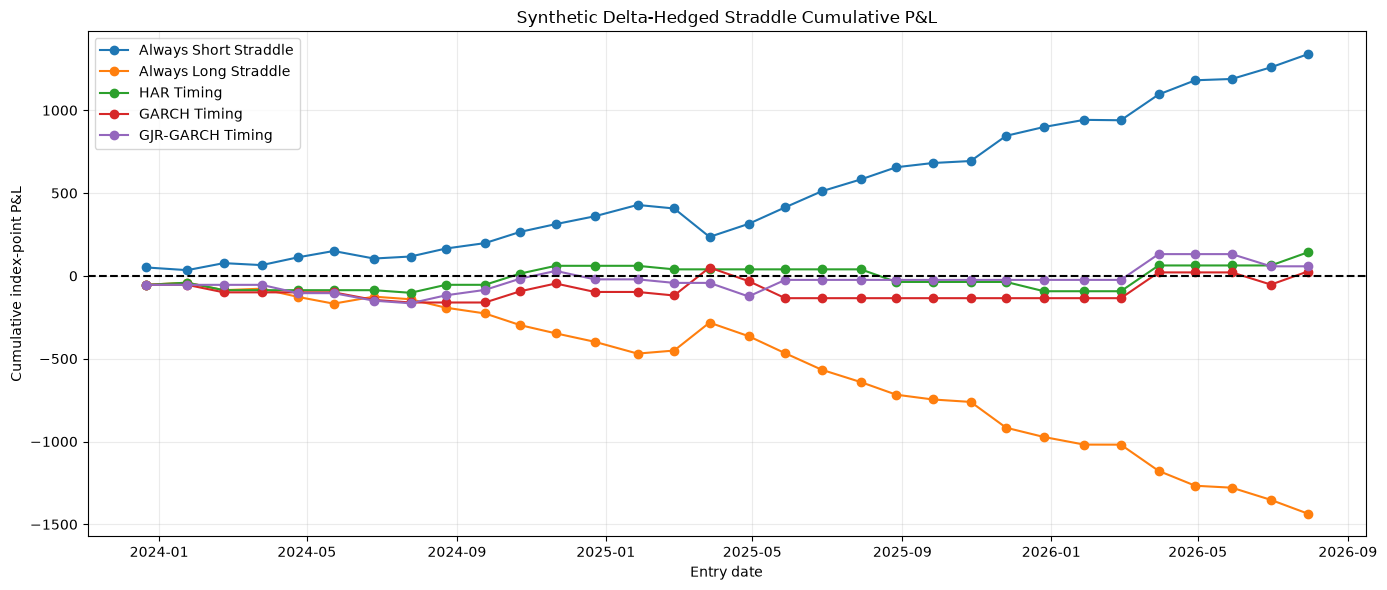

,Option P&L,Hedge P&L,Hedge cost,Net P&L
Strategy,,,,
Always Long Straddle,-1369.774383,-16.609099,48.425142,-1434.808625
Always Short Straddle,1369.774383,16.609099,48.425142,1337.958340
GARCH Timing,-396.491847,444.556517,21.898560,26.166110
GJR-GARCH Timing,-170.561235,249.367266,20.935143,57.870887
HAR Timing,-73.592250,233.178171,17.864047,141.721874



STAGE 18 COMPLETED
Maturity: 42 calendar days
Holding period: 21 sessions
Hedge cost: 1.0 basis points
Option bid-ask costs: Excluded
Underlying: S&P 500
IV proxy: VIX

Available variables:
simulation_data
gamma_trades
strategy_performance
decomposition


In [26]:

# ============================================================
# STAGE 18: SYNTHETIC SPX GAMMA-SCALPING SIMULATOR
# Black-Scholes straddle + daily delta hedging
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from scipy.stats import norm

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

OPTION_TENOR_DAYS = 35
HOLDING_SESSIONS = 21

LOOKBACK = 252
MIN_HISTORY = 126

LOW_QUANTILE = 0.20
HIGH_QUANTILE = 0.80

RISK_FREE_RATE = 0.0
DIVIDEND_YIELD = 0.0

HEDGE_COST_BPS = 1.0

TRADING_DAYS = 252

print("Synthetic gamma-scalping configuration loaded.")


# ------------------------------------------------------------
# 2. Verify Stage 15 signals
# ------------------------------------------------------------

required_signals = [
    "HAR Signal",
    "GARCH Signal",
    "GJR Signal"
]

if "oos_results" not in globals():
    raise RuntimeError(
        "oos_results is missing. Run Stage 15 first."
    )

missing = [
    column for column in required_signals
    if column not in oos_results.columns
]

if missing:
    raise ValueError(
        f"Missing signal columns: {missing}"
    )

signals = oos_results[required_signals].copy()

signals.index = pd.to_datetime(signals.index)

if signals.index.tz is not None:
    signals.index = signals.index.tz_localize(None)

signals = signals.sort_index().dropna()

print("Signal observations:", len(signals))


# ------------------------------------------------------------
# 3. Download S&P 500 and VIX
# ------------------------------------------------------------

def download_close(ticker, start, end):

    data = yf.Ticker(ticker).history(
        start=start,
        end=end,
        auto_adjust=False,
        actions=False
    )

    if data.empty:

        data = yf.download(
            ticker,
            start=start,
            end=end,
            auto_adjust=False,
            progress=False,
            threads=False
        )

    if data.empty:
        raise RuntimeError(
            f"No Yahoo Finance data received for {ticker}."
        )

    if isinstance(data.columns, pd.MultiIndex):

        if "Close" in data.columns.get_level_values(0):
            close = data["Close"]

        elif "Close" in data.columns.get_level_values(1):
            close = data.xs(
                "Close", axis=1, level=1
            )

        else:
            raise ValueError(
                f"Close column missing for {ticker}."
            )

        if isinstance(close, pd.DataFrame):
            close = close.iloc[:, 0]

    else:
        close = data["Close"]

    close = close.dropna().astype(float)

    close.index = pd.to_datetime(close.index)

    if close.index.tz is not None:
        close.index = close.index.tz_localize(None)

    return close


start_date = (
    signals.index.min() - pd.Timedelta(days=10)
).strftime("%Y-%m-%d")

end_date = (
    signals.index.max() + pd.Timedelta(days=2)
).strftime("%Y-%m-%d")

print("\nDownloading SPX data...")
spx = download_close("^GSPC", start_date, end_date)

print("Downloading VIX data...")
vix = download_close("^VIX", start_date, end_date)

simulation_data = pd.concat(
    [
        spx.rename("SPX"),
        vix.rename("VIX")
    ],
    axis=1
)

simulation_data = simulation_data.join(
    signals,
    how="inner"
).dropna()

simulation_data = simulation_data.sort_index()

print("\nSimulation dataset")
print("Observations:", len(simulation_data))
print("Start:", simulation_data.index.min())
print("End:", simulation_data.index.max())


# ------------------------------------------------------------
# 4. Black-Scholes European straddle pricing
# ------------------------------------------------------------

def bs_straddle_metrics(
    spot,
    strike,
    time_to_maturity,
    volatility,
    risk_free_rate=0.0,
    dividend_yield=0.0
):

    S = float(spot)
    K = float(strike)
    T = max(float(time_to_maturity), 0.0)
    sigma = max(float(volatility), 0.01)
    r = float(risk_free_rate)
    q = float(dividend_yield)

    if T <= 0:

        call_value = max(S - K, 0.0)
        put_value = max(K - S, 0.0)

        if S > K:
            delta = np.exp(-q * T)
        elif S < K:
            delta = -np.exp(-q * T)
        else:
            delta = 0.0

        return {
            "straddle_price": call_value + put_value,
            "delta": delta,
            "gamma": np.nan,
            "call_price": call_value,
            "put_price": put_value
        }

    sqrt_T = np.sqrt(T)

    d1 = (
        np.log(S / K)
        + (r - q + 0.5 * sigma**2) * T
    ) / (sigma * sqrt_T)

    d2 = d1 - sigma * sqrt_T

    discount_r = np.exp(-r * T)
    discount_q = np.exp(-q * T)

    call_price = (
        S * discount_q * norm.cdf(d1)
        - K * discount_r * norm.cdf(d2)
    )

    put_price = (
        K * discount_r * norm.cdf(-d2)
        - S * discount_q * norm.cdf(-d1)
    )

    call_delta = discount_q * norm.cdf(d1)

    put_delta = (
        discount_q * (norm.cdf(d1) - 1)
    )

    gamma = (
        2 * discount_q * norm.pdf(d1)
        / (S * sigma * sqrt_T)
    )

    return {
        "straddle_price": call_price + put_price,
        "delta": call_delta + put_delta,
        "gamma": 2 * gamma,
        "call_price": call_price,
        "put_price": put_price
    }


# ------------------------------------------------------------
# 5. Delta-hedged straddle simulation
# ------------------------------------------------------------

def simulate_straddle(
    path,
    direction,
    hedge_cost_bps=HEDGE_COST_BPS
):

    # direction:
    # +1 = Long straddle
    # -1 = Short straddle

    if direction not in [-1, 1]:
        raise ValueError("Direction must be +1 or -1.")

    prices = path["SPX"].to_numpy(dtype=float)
    implied_vol = (
        path["VIX"].to_numpy(dtype=float) / 100
    )

    dates = path.index

    entry_date = dates[0]
    exit_date = dates[-1]

    strike = prices[0]

    expiry_date = (
        entry_date
        + pd.Timedelta(days=OPTION_TENOR_DAYS)
    )

    if expiry_date <= exit_date:
        raise ValueError(
            "Option expires before the scheduled exit."
        )

    # Daily theoretical option valuation
    marks = []

    for j, date in enumerate(dates):

        remaining_days = (
            expiry_date - date
        ).days

        time_to_maturity = (
            remaining_days / 365
        )

        metrics = bs_straddle_metrics(
            spot=prices[j],
            strike=strike,
            time_to_maturity=time_to_maturity,
            volatility=implied_vol[j],
            risk_free_rate=RISK_FREE_RATE,
            dividend_yield=DIVIDEND_YIELD
        )

        marks.append(metrics)

    option_values = np.array([
        x["straddle_price"] for x in marks
    ])

    deltas = np.array([
        x["delta"] for x in marks
    ])

    gammas = np.array([
        x["gamma"] for x in marks
    ])

    # --------------------------------------------------------
    # Option P&L
    # --------------------------------------------------------

    option_pnl = direction * (
        option_values[-1] - option_values[0]
    )

    # --------------------------------------------------------
    # Initial delta hedge
    # --------------------------------------------------------

    hedge_position = -direction * deltas[0]

    hedge_turnover = (
        abs(hedge_position) * prices[0]
    )

    hedge_pnl = 0.0

    # --------------------------------------------------------
    # Daily hedge P&L and rebalancing
    # --------------------------------------------------------

    for j in range(1, len(prices)):

        # Previous hedge earns the daily index movement
        hedge_pnl += (
            hedge_position
            * (prices[j] - prices[j - 1])
        )

        if j < len(prices) - 1:

            target_hedge = (
                -direction * deltas[j]
            )

            turnover = abs(
                target_hedge - hedge_position
            ) * prices[j]

            hedge_turnover += turnover

            hedge_position = target_hedge

        else:

            # Close the existing hedge at the exit
            hedge_turnover += (
                abs(hedge_position) * prices[j]
            )

    # --------------------------------------------------------
    # Transaction costs
    # --------------------------------------------------------

    hedge_cost = (
        hedge_turnover
        * hedge_cost_bps / 10000
    )

    gross_pnl = option_pnl + hedge_pnl

    net_pnl = gross_pnl - hedge_cost

    return {
        "Entry date": entry_date,
        "Exit date": exit_date,
        "Holding sessions": len(prices) - 1,
        "Direction": direction,
        "Entry SPX": prices[0],
        "Strike": strike,
        "Entry VIX": implied_vol[0] * 100,
        "Entry option premium": option_values[0],
        "Exit option value": option_values[-1],
        "Entry gamma": gammas[0],
        "Option P&L": option_pnl,
        "Hedge P&L": hedge_pnl,
        "Gross P&L": gross_pnl,
        "Hedge turnover": hedge_turnover,
        "Hedge cost": hedge_cost,
        "Net P&L": net_pnl,
        "Net return on premium (%)": (
            net_pnl / option_values[0] * 100
            if option_values[0] > 0 else np.nan
        )
    }


# ------------------------------------------------------------
# 6. Construct historical VRP thresholds
# ------------------------------------------------------------

signal_mapping = {
    "HAR": "HAR Signal",
    "GARCH": "GARCH Signal",
    "GJR-GARCH": "GJR Signal"
}

HOLD = HOLDING_SESSIONS

first_entry = MIN_HISTORY + 1

entry_indices = range(
    first_entry,
    len(simulation_data) - HOLD,
    HOLD
)

# Calculate the longest calendar holding period
# across all scheduled 21-session trades.

entry_index_list = list(entry_indices)

calendar_spans = [
    (
        simulation_data.index[i + HOLD]
        - simulation_data.index[i]
    ).days
    for i in entry_index_list
]

max_calendar_span = max(calendar_spans)

# Keep the same initial option maturity for every trade,
# with an additional 7-calendar-day buffer.

OPTION_TENOR_DAYS = max(
    35,
    max_calendar_span + 7
)

print("Maximum calendar holding period:", max_calendar_span)
print("Option initial maturity:", OPTION_TENOR_DAYS)
print("Minimum remaining maturity at exit:", 
      OPTION_TENOR_DAYS - max_calendar_span, "days")

trade_records = []

# ------------------------------------------------------------
# 7. Generate benchmark and signal-based trades
# ------------------------------------------------------------

for entry_idx in entry_indices:

    signal_idx = entry_idx - 1

    entry_date = simulation_data.index[entry_idx]
    exit_date = simulation_data.index[entry_idx + HOLD]

    option_path = simulation_data.iloc[
        entry_idx:entry_idx + HOLD + 1
    ].copy()

    # Always-short benchmark
    benchmark_trade = simulate_straddle(
        option_path,
        direction=-1
    )

    benchmark_trade["Strategy"] = "Always Short Straddle"
    benchmark_trade["Signal"] = np.nan

    trade_records.append(benchmark_trade)

    # Always-long benchmark
    benchmark_trade = simulate_straddle(
        option_path,
        direction=1
    )

    benchmark_trade["Strategy"] = "Always Long Straddle"
    benchmark_trade["Signal"] = np.nan

    trade_records.append(benchmark_trade)

    # Signal-based strategies
    for model_name, column in signal_mapping.items():

        current_signal = float(
            simulation_data[column].iloc[signal_idx]
        )

        historical_signal = (
            simulation_data[column]
            .iloc[
                max(0, signal_idx - LOOKBACK):signal_idx
            ]
            .dropna()
        )

        if len(historical_signal) < MIN_HISTORY:
            continue

        low_threshold = historical_signal.quantile(
            LOW_QUANTILE
        )

        high_threshold = historical_signal.quantile(
            HIGH_QUANTILE
        )

        # Positive VRP signal: short implied variance.
        # Negative VRP signal: buy implied variance.

        if current_signal >= high_threshold:
            direction = -1
            status = "Short straddle"

        elif current_signal <= low_threshold:
            direction = 1
            status = "Long straddle"

        else:
            direction = 0
            status = "Flat"

        if direction == 0:

            trade = {
                "Entry date": entry_date,
                "Exit date": exit_date,
                "Holding sessions": HOLD,
                "Direction": 0,
                "Entry SPX": option_path["SPX"].iloc[0],
                "Strike": np.nan,
                "Entry VIX": option_path["VIX"].iloc[0],
                "Entry option premium": 0.0,
                "Exit option value": 0.0,
                "Entry gamma": 0.0,
                "Option P&L": 0.0,
                "Hedge P&L": 0.0,
                "Gross P&L": 0.0,
                "Hedge turnover": 0.0,
                "Hedge cost": 0.0,
                "Net P&L": 0.0,
                "Net return on premium (%)": np.nan
            }

        else:

            trade = simulate_straddle(
                option_path,
                direction=direction
            )

        trade["Strategy"] = f"{model_name} Timing"
        trade["Signal"] = current_signal
        trade["Signal status"] = status
        trade["Low threshold"] = low_threshold
        trade["High threshold"] = high_threshold

        trade_records.append(trade)


# ------------------------------------------------------------
# 8. Store trade results
# ------------------------------------------------------------

gamma_trades = pd.DataFrame(trade_records)

print("\nSIMULATED TRADES")
print("Total trade records:", len(gamma_trades))
print("Entry dates:", gamma_trades["Entry date"].nunique())

display(gamma_trades.head(10))


# ------------------------------------------------------------
# 9. Calculate strategy performance
# ------------------------------------------------------------

strategy_performance = (
    gamma_trades
    .groupby("Strategy")
    .agg(
        Scheduled_trades=("Net P&L", "count"),
        Active_trades=("Direction", lambda x: (x != 0).sum()),
        Long_straddles=("Direction", lambda x: (x == 1).sum()),
        Short_straddles=("Direction", lambda x: (x == -1).sum()),
        Total_option_PnL=("Option P&L", "sum"),
        Total_hedge_PnL=("Hedge P&L", "sum"),
        Total_hedge_cost=("Hedge cost", "sum"),
        Gross_PnL=("Gross P&L", "sum"),
        Net_PnL=("Net P&L", "sum"),
        Mean_net_PnL=("Net P&L", "mean"),
        Win_fraction=(
            "Net P&L",
            lambda x: (x[x.index].loc[
                gamma_trades.loc[x.index, "Direction"] != 0
            ] > 0).mean()
            if (gamma_trades.loc[x.index, "Direction"] != 0).any()
            else np.nan
        ),
        Mean_entry_gamma=("Entry gamma", "mean")
    )
)

print("\nGAMMA-SCALPING STRATEGY COMPARISON")

display(strategy_performance.round(6))


# ------------------------------------------------------------
# 10. Plot cumulative P&L
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

for strategy in gamma_trades["Strategy"].unique():

    subset = gamma_trades[
        gamma_trades["Strategy"] == strategy
    ].sort_values("Entry date")

    cumulative = subset["Net P&L"].cumsum()

    ax.plot(
        subset["Entry date"],
        cumulative,
        marker="o",
        label=strategy
    )

ax.axhline(
    0,
    color="black",
    linestyle="--"
)

ax.set_title(
    "Synthetic Delta-Hedged Straddle Cumulative P&L"
)

ax.set_xlabel("Entry date")
ax.set_ylabel("Cumulative index-point P&L")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. P&L decomposition
# ------------------------------------------------------------

decomposition = (
    gamma_trades
    .groupby("Strategy")[
        ["Option P&L", "Hedge P&L", "Hedge cost", "Net P&L"]
    ]
    .sum()
)

display(decomposition.round(6))


# ------------------------------------------------------------
# 12. Completion summary
# ------------------------------------------------------------

print("\nSTAGE 18 COMPLETED")

print("Maturity:", OPTION_TENOR_DAYS, "calendar days")
print("Holding period:", HOLDING_SESSIONS, "sessions")
print("Hedge cost:", HEDGE_COST_BPS, "basis points")
print("Option bid-ask costs: Excluded")
print("Underlying: S&P 500")
print("IV proxy: VIX")

print("\nAvailable variables:")
print("simulation_data")
print("gamma_trades")
print("strategy_performance")
print("decomposition")


## Stage 19 — Cost and hedge-frequency sensitivity
Measure the effect of transaction costs and hedge frequency on simulated P&L.


Scheduled entry dates: 32

SENSITIVITY SIMULATIONS COMPLETED
Total simulated trade records: 7680

FULL SENSITIVITY SUMMARY


,Hedge frequency,Hedge cost bps,Option round-trip cost %,Strategy,Scheduled trades,Active trades,Net P&L,Mean net P&L per scheduled trade,Mean net P&L per active trade,Total option P&L,Total hedge P&L,Total hedge costs,Total option costs,Net P&L / total entry premium (%),Win fraction
0,1,0,0.0,Always Long Straddle,32,32,-1386.383482,-43.324484,-43.324484,-1369.774383,-16.609099,0.0,0.000000,-15.382511,0.187500
1,1,0,0.0,Always Short Straddle,32,32,1386.383482,43.324484,43.324484,1369.774383,16.609099,0.0,0.000000,15.382511,0.812500
2,1,0,0.0,GARCH Timing,32,14,48.064670,1.502021,3.433191,-396.491847,444.556517,0.0,0.000000,1.157604,0.357143
3,1,0,0.0,GJR-GARCH Timing,32,14,78.806030,2.462688,5.629002,-170.561235,249.367266,0.0,0.000000,1.955198,0.428571
4,1,0,0.0,HAR Timing,32,12,159.585921,4.987060,13.298827,-73.592250,233.178171,0.0,0.000000,4.813293,0.500000
5,1,0,1.0,Always Long Straddle,32,32,-1476.510736,-46.140960,-46.140960,-1369.774383,-16.609099,0.0,90.127253,-16.382511,0.156250
6,1,0,1.0,Always Short Straddle,32,32,1296.256229,40.508007,40.508007,1369.774383,16.609099,0.0,90.127253,14.382511,0.812500
7,1,0,1.0,GARCH Timing,32,14,6.543846,0.204495,0.467418,-396.491847,444.556517,0.0,41.520824,0.157604,0.357143
8,1,0,1.0,GJR-GARCH Timing,32,14,38.500133,1.203129,2.750009,-170.561235,249.367266,0.0,40.305898,0.955198,0.428571
9,1,0,1.0,HAR Timing,32,12,126.430671,3.950958,10.535889,-73.592250,233.178171,0.0,33.155250,3.813293,0.500000



BASELINE SCENARIO


,Hedge frequency,Hedge cost bps,Option round-trip cost %,Strategy,Scheduled trades,Active trades,Net P&L,Mean net P&L per scheduled trade,Mean net P&L per active trade,Total option P&L,Total hedge P&L,Total hedge costs,Total option costs,Net P&L / total entry premium (%),Win fraction
21,1,1,0.0,Always Short Straddle,32,32,1337.958340,41.811198,41.811198,1369.774383,16.609099,48.425142,0.0,14.845214,0.812500
24,1,1,0.0,HAR Timing,32,12,141.721874,4.428809,11.810156,-73.592250,233.178171,17.864047,0.0,4.274493,0.500000
23,1,1,0.0,GJR-GARCH Timing,32,14,57.870887,1.808465,4.133635,-170.561235,249.367266,20.935143,0.0,1.435792,0.428571
22,1,1,0.0,GARCH Timing,32,14,26.166110,0.817691,1.869008,-396.491847,444.556517,21.898560,0.0,0.630192,0.357143
20,1,1,0.0,Always Long Straddle,32,32,-1434.808625,-44.837770,-44.837770,-1369.774383,-16.609099,48.425142,0.0,-15.919809,0.156250



DAILY HEDGING COST SENSITIVITY


,Hedge frequency,Hedge cost bps,Option round-trip cost %,Strategy,Scheduled trades,Active trades,Net P&L,Mean net P&L per scheduled trade,Mean net P&L per active trade,Total option P&L,Total hedge P&L,Total hedge costs,Total option costs,Net P&L / total entry premium (%),Win fraction
1,1,0,0.0,Always Short Straddle,32,32,1386.383482,43.324484,43.324484,1369.774383,16.609099,0.000000,0.000000,15.382511,0.812500
2,1,0,0.0,GARCH Timing,32,14,48.064670,1.502021,3.433191,-396.491847,444.556517,0.000000,0.000000,1.157604,0.357143
3,1,0,0.0,GJR-GARCH Timing,32,14,78.806030,2.462688,5.629002,-170.561235,249.367266,0.000000,0.000000,1.955198,0.428571
4,1,0,0.0,HAR Timing,32,12,159.585921,4.987060,13.298827,-73.592250,233.178171,0.000000,0.000000,4.813293,0.500000
6,1,0,1.0,Always Short Straddle,32,32,1296.256229,40.508007,40.508007,1369.774383,16.609099,0.000000,90.127253,14.382511,0.812500
7,1,0,1.0,GARCH Timing,32,14,6.543846,0.204495,0.467418,-396.491847,444.556517,0.000000,41.520824,0.157604,0.357143
8,1,0,1.0,GJR-GARCH Timing,32,14,38.500133,1.203129,2.750009,-170.561235,249.367266,0.000000,40.305898,0.955198,0.428571
9,1,0,1.0,HAR Timing,32,12,126.430671,3.950958,10.535889,-73.592250,233.178171,0.000000,33.155250,3.813293,0.500000
11,1,0,2.5,Always Short Straddle,32,32,1161.065350,36.283292,36.283292,1369.774383,16.609099,0.000000,225.318133,12.882511,0.812500
12,1,0,2.5,GARCH Timing,32,14,-55.737391,-1.741793,-3.981242,-396.491847,444.556517,0.000000,103.802061,-1.342396,0.357143


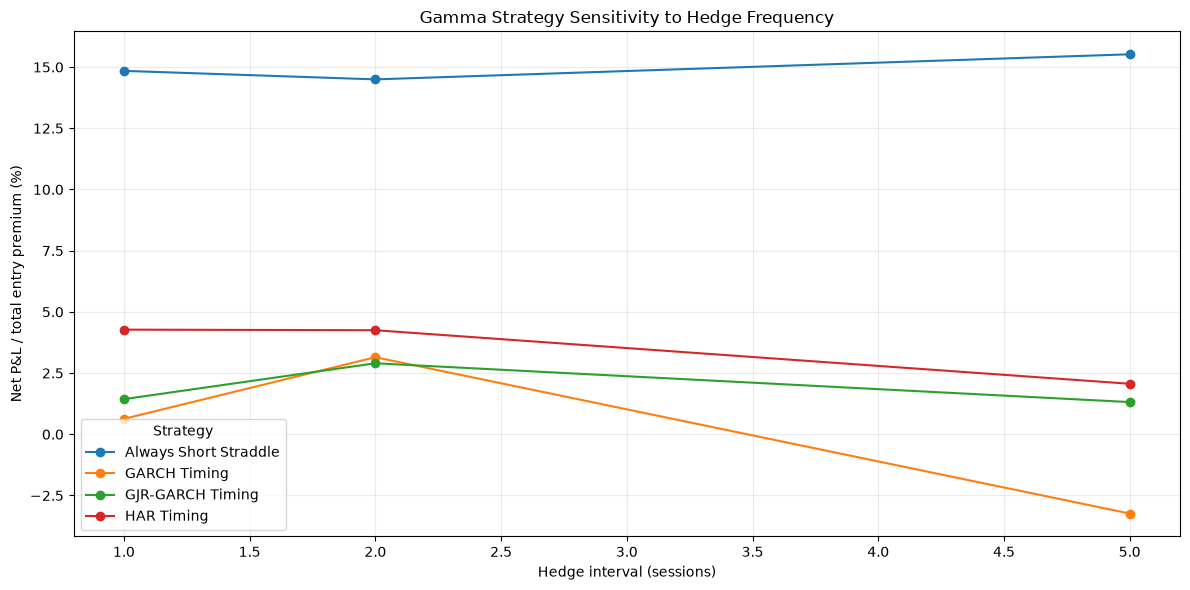

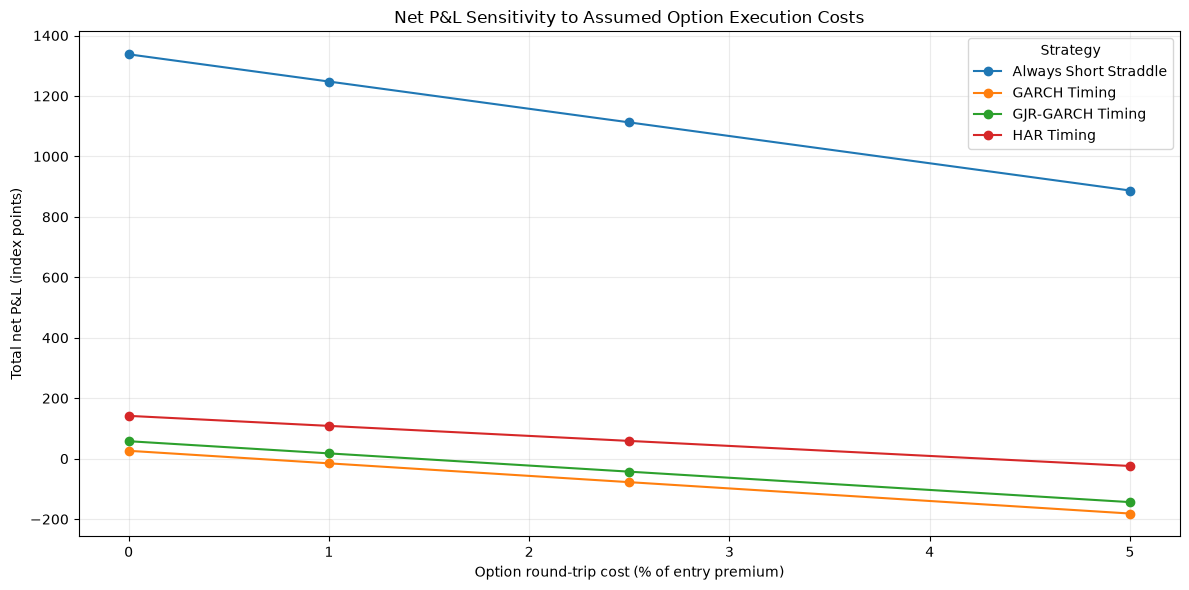


STAGE 19 COMPLETED
Hedge frequencies: [1, 2, 5]
Hedge costs: [0, 1, 2, 5]
Option cost assumptions: [0, 1, 2.5, 5]
Total scenario combinations: 240

Available variables:
sensitivity_trades
sensitivity_summary
baseline_sensitivity
daily_sensitivity


In [27]:

# ============================================================
# STAGE 19: GAMMA-SCALPING COST AND HEDGING SENSITIVITY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

HEDGE_FREQUENCIES = [1, 2, 5]
HEDGE_COSTS = [0, 1, 2, 5]
OPTION_COSTS = [0, 1, 2.5, 5]

HOLD = 21
LOOKBACK = 252
MIN_HISTORY = 126

LOW_QUANTILE = 0.20
HIGH_QUANTILE = 0.80

TENOR = int(OPTION_TENOR_DAYS)

SIGNAL_MAPPING = {
    "HAR Timing": "HAR Signal",
    "GARCH Timing": "GARCH Signal",
    "GJR-GARCH Timing": "GJR Signal"
}

required_objects = [
    "simulation_data",
    "bs_straddle_metrics"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Missing Stage 18 objects: {missing_objects}. "
        "Run Stage 18 first."
    )

# ------------------------------------------------------------
# 2. Define sensitivity-aware straddle simulator
# ------------------------------------------------------------

def simulate_straddle_sensitivity(
    path,
    direction,
    hedge_interval,
    hedge_cost_bps,
    option_cost_pct
):

    if direction not in [-1, 1]:
        raise ValueError("Direction must be -1 or +1.")

    prices = path["SPX"].to_numpy(dtype=float)

    implied_vols = (
        path["VIX"].to_numpy(dtype=float) / 100
    )

    dates = path.index

    expiry_date = (
        dates[0] + pd.Timedelta(days=TENOR)
    )

    if expiry_date <= dates[-1]:
        raise ValueError(
            "Option expires before scheduled exit."
        )

    # --------------------------------------------------------
    # Daily option marks
    # --------------------------------------------------------

    marks = []

    for j, date in enumerate(dates):

        remaining_days = (
            expiry_date - date
        ).days

        metrics = bs_straddle_metrics(
            spot=prices[j],
            strike=prices[0],
            time_to_maturity=remaining_days / 365,
            volatility=implied_vols[j],
            risk_free_rate=RISK_FREE_RATE,
            dividend_yield=DIVIDEND_YIELD
        )

        marks.append(metrics)

    option_values = np.array([
        x["straddle_price"] for x in marks
    ])

    deltas = np.array([
        x["delta"] for x in marks
    ])

    gammas = np.array([
        x["gamma"] for x in marks
    ])

    # --------------------------------------------------------
    # Option P&L
    # --------------------------------------------------------

    option_pnl = direction * (
        option_values[-1] - option_values[0]
    )

    entry_premium = option_values[0]

    # Assumed round-trip option execution cost.
    # This is a sensitivity assumption, not an observed
    # historical bid-ask spread.

    option_cost = (
        entry_premium * option_cost_pct / 100
    )

    # --------------------------------------------------------
    # Initial delta hedge
    # --------------------------------------------------------

    hedge_position = -direction * deltas[0]

    hedge_turnover = (
        abs(hedge_position) * prices[0]
    )

    hedge_pnl = 0.0

    # --------------------------------------------------------
    # Hedge rebalancing
    # --------------------------------------------------------

    for j in range(1, len(prices)):

        # Existing hedge earns the daily index movement.
        hedge_pnl += (
            hedge_position
            * (prices[j] - prices[j - 1])
        )

        if j < len(prices) - 1:

            # Rebalance only at the specified frequency.
            if j % hedge_interval == 0:

                target_hedge = (
                    -direction * deltas[j]
                )

                turnover = (
                    abs(target_hedge - hedge_position)
                    * prices[j]
                )

                hedge_turnover += turnover

                hedge_position = target_hedge

        else:

            # Close the hedge at the scheduled exit.
            hedge_turnover += (
                abs(hedge_position) * prices[j]
            )

    hedge_cost = (
        hedge_turnover * hedge_cost_bps / 10000
    )

    gross_pnl = option_pnl + hedge_pnl

    net_pnl = (
        gross_pnl
        - hedge_cost
        - option_cost
    )

    return {
        "Entry premium": entry_premium,
        "Entry gamma": gammas[0],
        "Option P&L": option_pnl,
        "Hedge P&L": hedge_pnl,
        "Gross P&L": gross_pnl,
        "Hedge turnover": hedge_turnover,
        "Hedge cost": hedge_cost,
        "Option cost": option_cost,
        "Total costs": hedge_cost + option_cost,
        "Net P&L": net_pnl,
        "Net return on premium (%)": (
            net_pnl / entry_premium * 100
            if entry_premium > 0 else np.nan
        )
    }


# ------------------------------------------------------------
# 3. Construct trade entry dates
# ------------------------------------------------------------

entry_indices = list(
    range(
        MIN_HISTORY + 1,
        len(simulation_data) - HOLD,
        HOLD
    )
)

trade_dates = []

for entry_idx in entry_indices:

    signal_idx = entry_idx - 1

    entry_date = simulation_data.index[entry_idx]

    exit_date = simulation_data.index[entry_idx + HOLD]

    path = simulation_data.iloc[
        entry_idx:entry_idx + HOLD + 1
    ].copy()

    trade_dates.append({
        "Entry index": entry_idx,
        "Signal index": signal_idx,
        "Entry date": entry_date,
        "Exit date": exit_date,
        "Path": path
    })

print("Scheduled entry dates:", len(trade_dates))


# ------------------------------------------------------------
# 4. Pre-calculate signal decisions
# ------------------------------------------------------------

signal_decisions = {}

for trade_number, trade in enumerate(trade_dates):

    signal_idx = trade["Signal index"]

    for strategy, column in SIGNAL_MAPPING.items():

        current_signal = float(
            simulation_data[column].iloc[signal_idx]
        )

        history = (
            simulation_data[column]
            .iloc[
                max(0, signal_idx - LOOKBACK):signal_idx
            ]
            .dropna()
        )

        if len(history) < MIN_HISTORY:
            direction = 0
            status = "Insufficient history"
            low = np.nan
            high = np.nan

        else:

            low = history.quantile(LOW_QUANTILE)
            high = history.quantile(HIGH_QUANTILE)

            if current_signal <= low:
                direction = 1
                status = "Long straddle"

            elif current_signal >= high:
                direction = -1
                status = "Short straddle"

            else:
                direction = 0
                status = "Flat"

        signal_decisions[
            (trade_number, strategy)
        ] = {
            "direction": direction,
            "signal": current_signal,
            "status": status,
            "low": low,
            "high": high
        }


# ------------------------------------------------------------
# 5. Run all cost and hedging scenarios
# ------------------------------------------------------------

sensitivity_records = []

STRATEGIES = [
    "Always Short Straddle",
    "Always Long Straddle",
    "HAR Timing",
    "GARCH Timing",
    "GJR-GARCH Timing"
]

for hedge_frequency in HEDGE_FREQUENCIES:

    for hedge_cost_bps in HEDGE_COSTS:

        for option_cost_pct in OPTION_COSTS:

            for trade_number, trade in enumerate(trade_dates):

                path = trade["Path"]

                directions = {
                    "Always Short Straddle": -1,
                    "Always Long Straddle": 1
                }

                # Add signal-based strategies.
                for strategy in SIGNAL_MAPPING:

                    directions[strategy] = (
                        signal_decisions[
                            (trade_number, strategy)
                        ]["direction"]
                    )

                for strategy in STRATEGIES:

                    direction = directions[strategy]

                    if direction == 0:

                        metrics = {
                            "Entry premium": 0.0,
                            "Entry gamma": 0.0,
                            "Option P&L": 0.0,
                            "Hedge P&L": 0.0,
                            "Gross P&L": 0.0,
                            "Hedge turnover": 0.0,
                            "Hedge cost": 0.0,
                            "Option cost": 0.0,
                            "Total costs": 0.0,
                            "Net P&L": 0.0,
                            "Net return on premium (%)": np.nan
                        }

                    else:

                        metrics = simulate_straddle_sensitivity(
                            path=path,
                            direction=direction,
                            hedge_interval=hedge_frequency,
                            hedge_cost_bps=hedge_cost_bps,
                            option_cost_pct=option_cost_pct
                        )

                    signal_information = {}

                    if strategy in SIGNAL_MAPPING:

                        signal_information = signal_decisions[
                            (trade_number, strategy)
                        ]

                    sensitivity_records.append({
                        "Entry date": trade["Entry date"],
                        "Exit date": trade["Exit date"],
                        "Strategy": strategy,
                        "Direction": direction,
                        "Hedge frequency": hedge_frequency,
                        "Hedge cost bps": hedge_cost_bps,
                        "Option round-trip cost %": option_cost_pct,
                        "Signal": signal_information.get(
                            "signal", np.nan
                        ),
                        "Signal status": signal_information.get(
                            "status", "Benchmark"
                        ),
                        **metrics
                    })


# ------------------------------------------------------------
# 6. Store complete sensitivity results
# ------------------------------------------------------------

sensitivity_trades = pd.DataFrame(
    sensitivity_records
)

print("\nSENSITIVITY SIMULATIONS COMPLETED")
print("Total simulated trade records:", len(sensitivity_trades))

# ------------------------------------------------------------
# 7. Aggregate strategy performance
# ------------------------------------------------------------

summary_records = []

group_columns = [
    "Hedge frequency",
    "Hedge cost bps",
    "Option round-trip cost %",
    "Strategy"
]

for keys, group in sensitivity_trades.groupby(
    group_columns,
    sort=True
):

    active = group[group["Direction"] != 0]

    total_premium = group["Entry premium"].sum()

    total_net_pnl = group["Net P&L"].sum()

    summary_records.append({
        "Hedge frequency": keys[0],
        "Hedge cost bps": keys[1],
        "Option round-trip cost %": keys[2],
        "Strategy": keys[3],
        "Scheduled trades": len(group),
        "Active trades": len(active),
        "Net P&L": total_net_pnl,
        "Mean net P&L per scheduled trade": group["Net P&L"].mean(),
        "Mean net P&L per active trade": (
            active["Net P&L"].mean()
            if len(active) else np.nan
        ),
        "Total option P&L": group["Option P&L"].sum(),
        "Total hedge P&L": group["Hedge P&L"].sum(),
        "Total hedge costs": group["Hedge cost"].sum(),
        "Total option costs": group["Option cost"].sum(),
        "Net P&L / total entry premium (%)": (
            total_net_pnl / total_premium * 100
            if total_premium > 0 else np.nan
        ),
        "Win fraction": (
            (active["Net P&L"] > 0).mean()
            if len(active) else np.nan
        )
    })

sensitivity_summary = pd.DataFrame(
    summary_records
)

print("\nFULL SENSITIVITY SUMMARY")

display(sensitivity_summary.head(20))


# ------------------------------------------------------------
# 8. Baseline scenario: daily hedging, 1 bp, no option cost
# ------------------------------------------------------------

baseline_sensitivity = sensitivity_summary[
    (sensitivity_summary["Hedge frequency"] == 1)
    & (sensitivity_summary["Hedge cost bps"] == 1)
    & (sensitivity_summary["Option round-trip cost %"] == 0)
].copy()

print("\nBASELINE SCENARIO")

display(
    baseline_sensitivity.sort_values(
        "Net P&L",
        ascending=False
    ).round(6)
)


# ------------------------------------------------------------
# 9. Cost sensitivity for daily hedging
# ------------------------------------------------------------

daily_sensitivity = sensitivity_summary[
    sensitivity_summary["Hedge frequency"] == 1
].copy()

print("\nDAILY HEDGING COST SENSITIVITY")

display(
    daily_sensitivity[
        daily_sensitivity["Strategy"].isin([
            "Always Short Straddle",
            "HAR Timing",
            "GARCH Timing",
            "GJR-GARCH Timing"
        ])
    ].round(6)
)


# ------------------------------------------------------------
# 10. Plot hedge-frequency sensitivity
# ------------------------------------------------------------

plot_data = sensitivity_summary[
    (sensitivity_summary["Hedge cost bps"] == 1)
    & (sensitivity_summary["Option round-trip cost %"] == 0)
    & (sensitivity_summary["Strategy"].isin([
        "Always Short Straddle",
        "HAR Timing",
        "GARCH Timing",
        "GJR-GARCH Timing"
    ]))
]

frequency_pivot = plot_data.pivot(
    index="Hedge frequency",
    columns="Strategy",
    values="Net P&L / total entry premium (%)"
)

ax = frequency_pivot.plot(
    marker="o",
    figsize=(12, 6)
)

ax.set_title(
    "Gamma Strategy Sensitivity to Hedge Frequency"
)

ax.set_xlabel("Hedge interval (sessions)")
ax.set_ylabel("Net P&L / total entry premium (%)")
ax.legend(title="Strategy")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. Plot option transaction cost sensitivity
# ------------------------------------------------------------

cost_plot = sensitivity_summary[
    (sensitivity_summary["Hedge frequency"] == 1)
    & (sensitivity_summary["Hedge cost bps"] == 1)
    & (sensitivity_summary["Strategy"].isin([
        "Always Short Straddle",
        "HAR Timing",
        "GARCH Timing",
        "GJR-GARCH Timing"
    ]))
]

cost_pivot = cost_plot.pivot(
    index="Option round-trip cost %",
    columns="Strategy",
    values="Net P&L"
)

ax = cost_pivot.plot(
    marker="o",
    figsize=(12, 6)
)

ax.set_title(
    "Net P&L Sensitivity to Assumed Option Execution Costs"
)

ax.set_xlabel("Option round-trip cost (% of entry premium)")
ax.set_ylabel("Total net P&L (index points)")
ax.legend(title="Strategy")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12. Completion
# ------------------------------------------------------------

print("\nSTAGE 19 COMPLETED")

print("Hedge frequencies:", HEDGE_FREQUENCIES)
print("Hedge costs:", HEDGE_COSTS)
print("Option cost assumptions:", OPTION_COSTS)
print("Total scenario combinations:", len(sensitivity_summary))

print("\nAvailable variables:")
print("sensitivity_trades")
print("sensitivity_summary")
print("baseline_sensitivity")
print("daily_sensitivity")


## Stage 20 — Maturity-matched volatility input
Interpolate VIX-family indices to the synthetic option tenor and rerun the simulation.


Stage 20 configuration loaded.

Maturity data alignment
Observations: 812
Start: 2023-06-22 00:00:00
End: 2026-09-16 00:00:00
Observations removed: 0

Option maturity
Maximum holding calendar span: 35
Initial option maturity: 44
Minimum remaining maturity: 9 days


,VIX9D,VIX,VIX3M,IV_42D_proxy
Date,,,,
2023-06-22,11.15,12.91,16.559999,0.138048
2023-06-23,11.61,13.44,16.870001,0.142736
2023-06-26,12.68,14.25,17.049999,0.149177
2023-06-27,12.05,13.74,16.440001,0.143839
2023-06-28,11.74,13.43,15.900000,0.140166



CORRECTED SIMULATION
Trade records: 160
Entry dates: 32


,Entry date,Exit date,Holding sessions,Direction,Entry SPX,Strike,Entry IV proxy,Entry option premium,Exit option value,Entry gamma,Option P&L,Hedge P&L,Gross P&L,Hedge turnover,Hedge cost,Option cost,Net P&L,Net return on premium (%),Strategy,Signal status,Signal,Low threshold,High threshold
0,2023-12-21,2024-01-24,21,-1,4746.750000,4746.750000,0.142814,187.777706,135.780507,0.003389,51.997198,7.346510,59.343708,13704.348198,1.370435,0.0,57.973273,30.873353,Always Short Straddle,Benchmark,NaN,NaN,NaN
1,2023-12-21,2024-01-24,21,1,4746.750000,4746.750000,0.142814,187.777706,135.780507,0.003389,-51.997198,-7.346510,-59.343708,13704.348198,1.370435,0.0,-60.714143,-32.332988,Always Long Straddle,Benchmark,NaN,NaN,NaN
2,2023-12-21,2024-01-24,21,1,4746.750000,4746.750000,0.142814,187.777706,135.780507,0.003389,-51.997198,-7.346510,-59.343708,13704.348198,1.370435,0.0,-60.714143,-32.332988,HAR Timing,Long straddle,-0.009723,-0.005953,0.004490
3,2023-12-21,2024-01-24,21,1,4746.750000,4746.750000,0.142814,187.777706,135.780507,0.003389,-51.997198,-7.346510,-59.343708,13704.348198,1.370435,0.0,-60.714143,-32.332988,GARCH Timing,Long straddle,-0.007217,-0.002145,0.005748
4,2023-12-21,2024-01-24,21,1,4746.750000,4746.750000,0.142814,187.777706,135.780507,0.003389,-51.997198,-7.346510,-59.343708,13704.348198,1.370435,0.0,-60.714143,-32.332988,GJR-GARCH Timing,Long straddle,-0.007231,0.001556,0.006029
5,2024-01-24,2024-02-23,21,-1,4868.549805,4868.549805,0.135680,182.976669,223.485885,0.003478,-40.509216,34.522499,-5.986717,17025.939043,1.702594,0.0,-7.689311,-4.202345,Always Short Straddle,Benchmark,NaN,NaN,NaN
6,2024-01-24,2024-02-23,21,1,4868.549805,4868.549805,0.135680,182.976669,223.485885,0.003478,40.509216,-34.522499,5.986717,17025.939043,1.702594,0.0,4.284123,2.341350,Always Long Straddle,Benchmark,NaN,NaN,NaN
7,2024-01-24,2024-02-23,21,1,4868.549805,4868.549805,0.135680,182.976669,223.485885,0.003478,40.509216,-34.522499,5.986717,17025.939043,1.702594,0.0,4.284123,2.341350,HAR Timing,Long straddle,-0.007781,-0.006927,0.003344
8,2024-01-24,2024-02-23,21,0,4868.549805,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,NaN,GARCH Timing,Flat,-0.002337,-0.003299,0.005179
9,2024-01-24,2024-02-23,21,0,4868.549805,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,NaN,GJR-GARCH Timing,Flat,0.003222,0.000421,0.005912



MATURITY-MATCHED STRATEGY PERFORMANCE


,Scheduled trades,Active trades,Long straddles,Short straddles,Total option P&L,Total hedge P&L,Total hedge costs,Total option costs,Gross P&L,Net P&L,Mean net P&L per scheduled trade,Mean net P&L per active trade,Win fraction,Mean entry gamma,Net P&L / total entry premium (%)
Strategy,,,,,,,,,,,,,,,
Always Long Straddle,32,32,32,0,-1799.863438,-31.336892,47.699218,0.0,-1831.200330,-1878.899548,-58.715611,-58.715611,0.187500,0.002277,-19.803690
Always Short Straddle,32,32,0,32,1799.863438,31.336892,47.699218,0.0,1831.200330,1783.501113,55.734410,55.734410,0.812500,0.002277,18.798186
GARCH Timing,32,14,8,6,-407.841168,410.629480,21.527589,0.0,2.788312,-18.739277,-0.585602,-1.338520,0.357143,0.002217,-0.433581
GJR-GARCH Timing,32,14,6,8,-142.428951,245.089579,20.573705,0.0,102.660628,82.086923,2.565216,5.863352,0.428571,0.002267,1.954551
HAR Timing,32,12,6,6,-90.896616,222.862042,17.613774,0.0,131.965425,114.351651,3.573489,9.529304,0.500000,0.002386,3.294469



P&L DECOMPOSITION


,Option P&L,Hedge P&L,Hedge cost,Option cost,Net P&L
Strategy,,,,,
Always Long Straddle,-1799.863438,-31.336892,47.699218,0.0,-1878.899548
Always Short Straddle,1799.863438,31.336892,47.699218,0.0,1783.501113
GARCH Timing,-407.841168,410.629480,21.527589,0.0,-18.739277
GJR-GARCH Timing,-142.428951,245.089579,20.573705,0.0,82.086923
HAR Timing,-90.896616,222.862042,17.613774,0.0,114.351651


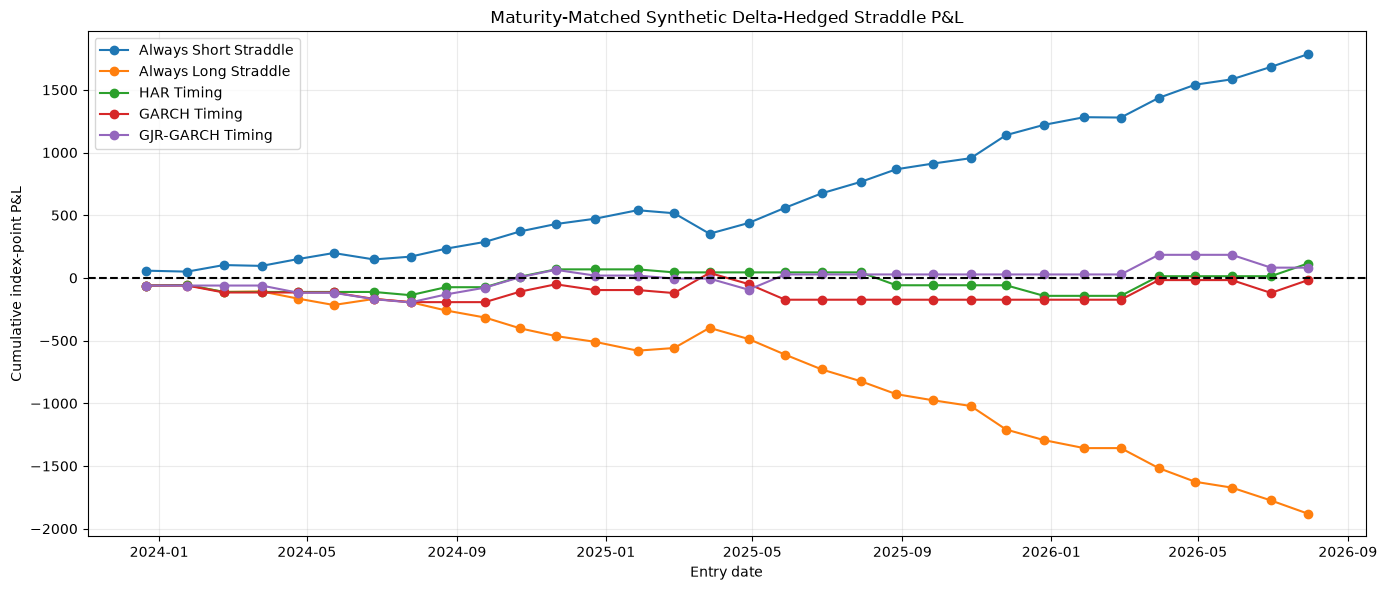


STAGE 20 COMPLETED
Initial maturity: 44 calendar days
Holding period: 21 trading sessions
IV inputs: VIX9D, VIX, VIX3M
Hedge cost: 1.0 bps
Option costs: 0.0 %
Gamma formula: Corrected

Available variables:
term_data
gamma_trades_v2
strategy_performance_v2
decomposition_v2


In [28]:

# ============================================================
# STAGE 20: MATURITY-MATCHED GAMMA-SCALPING SIMULATOR
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from scipy.stats import norm

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

HOLD = 21
LOOKBACK = 252
MIN_HISTORY = 126

HEDGE_COST_BPS = 1.0
OPTION_COST_PCT = 0.0

RISK_FREE_RATE = 0.0
DIVIDEND_YIELD = 0.0

TRADING_DAYS = 252

print("Stage 20 configuration loaded.")


# ------------------------------------------------------------
# 2. Verify existing data
# ------------------------------------------------------------

required_columns = [
    "SPX",
    "VIX",
    "HAR Signal",
    "GARCH Signal",
    "GJR Signal"
]

if "simulation_data" not in globals():
    raise RuntimeError(
        "simulation_data is missing. Run Stage 18 first."
    )

missing = [
    c for c in required_columns
    if c not in simulation_data.columns
]

if missing:
    raise ValueError(f"Missing columns: {missing}")

base_data = simulation_data[
    required_columns
].copy()

base_data = base_data.sort_index()


# ------------------------------------------------------------
# 3. Download maturity-specific volatility indices
# ------------------------------------------------------------

def fetch_close(ticker, start, end):

    data = yf.Ticker(ticker).history(
        start=start,
        end=end,
        auto_adjust=False,
        actions=False
    )

    if data.empty:

        data = yf.download(
            ticker,
            start=start,
            end=end,
            auto_adjust=False,
            progress=False,
            threads=False
        )

    if data.empty:
        raise RuntimeError(
            f"No Yahoo Finance data received for {ticker}."
        )

    if isinstance(data.columns, pd.MultiIndex):

        if "Close" in data.columns.get_level_values(0):
            close = data["Close"]

        elif "Close" in data.columns.get_level_values(1):
            close = data.xs(
                "Close", axis=1, level=1
            )

        else:
            raise ValueError(
                f"Close missing for {ticker}"
            )

        if isinstance(close, pd.DataFrame):
            close = close.iloc[:, 0]

    else:
        close = data["Close"]

    close = close.dropna().astype(float)

    close.index = pd.to_datetime(close.index)

    if close.index.tz is not None:
        close.index = close.index.tz_localize(None)

    return close


start_date = base_data.index.min().strftime("%Y-%m-%d")

end_date = (
    base_data.index.max() + pd.Timedelta(days=2)
).strftime("%Y-%m-%d")

print("Downloading VIX9D...")
vix9d = fetch_close(
    "^VIX9D", start_date, end_date
).rename("VIX9D")

print("Downloading VIX3M...")
vix3m = fetch_close(
    "^VIX3M", start_date, end_date
).rename("VIX3M")


# ------------------------------------------------------------
# 4. Build maturity-matched volatility dataset
# ------------------------------------------------------------

term_data = (
    base_data
    .join(vix9d, how="inner")
    .join(vix3m, how="inner")
    .dropna()
    .sort_index()
)

print("\nMaturity data alignment")
print("Observations:", len(term_data))
print("Start:", term_data.index.min())
print("End:", term_data.index.max())

print(
    "Observations removed:",
    len(base_data) - len(term_data)
)


# ------------------------------------------------------------
# 5. Define actual option holding period
# ------------------------------------------------------------

entry_indices = list(
    range(
        MIN_HISTORY + 1,
        len(term_data) - HOLD,
        HOLD
    )
)

if not entry_indices:
    raise RuntimeError(
        "Insufficient observations for the simulation."
    )

calendar_spans = [
    (
        term_data.index[i + HOLD]
        - term_data.index[i]
    ).days
    for i in entry_indices
]

MAX_CALENDAR_SPAN = max(calendar_spans)

# Preserve at least nine calendar days until expiry
# at the end of the longest holding period.

OPTION_TENOR_DAYS = (
    MAX_CALENDAR_SPAN + 9
)

print("\nOption maturity")
print("Maximum holding calendar span:", MAX_CALENDAR_SPAN)
print("Initial option maturity:", OPTION_TENOR_DAYS)
print("Minimum remaining maturity: 9 days")


# ------------------------------------------------------------
# 6. Interpolate implied variance by maturity
# ------------------------------------------------------------

MATURITY_ANCHORS = np.array([
    9.0,
    30.0,
    93.0
])

def maturity_matched_iv(row, remaining_days):

    if not 9 <= remaining_days <= 93:
        raise ValueError(
            f"Remaining maturity {remaining_days} "
            "is outside the 9-93 day volatility grid."
        )

    volatilities = np.array([
        row["VIX9D"],
        row["VIX"],
        row["VIX3M"]
    ]) / 100.0

    if not np.all(np.isfinite(volatilities)):
        raise ValueError("Invalid volatility observation.")

    # Interpolate ANNUALISED VARIANCE, not volatility.
    annual_variances = volatilities ** 2

    target_variance = np.interp(
        remaining_days,
        MATURITY_ANCHORS,
        annual_variances
    )

    return np.sqrt(max(target_variance, 0.0))


term_data["IV_42D_proxy"] = term_data.apply(
    lambda row: maturity_matched_iv(
        row, OPTION_TENOR_DAYS
    ),
    axis=1
)

display(
    term_data[
        ["VIX9D", "VIX", "VIX3M", "IV_42D_proxy"]
    ].head()
)


# ------------------------------------------------------------
# 7. Corrected Black-Scholes straddle metrics
# ------------------------------------------------------------

def bs_straddle_metrics_v2(
    spot,
    strike,
    time_to_maturity,
    volatility,
    risk_free_rate=RISK_FREE_RATE,
    dividend_yield=DIVIDEND_YIELD
):

    S = float(spot)
    K = float(strike)
    T = float(time_to_maturity)
    sigma = float(volatility)

    r = float(risk_free_rate)
    q = float(dividend_yield)

    if S <= 0 or K <= 0:
        raise ValueError("Spot and strike must be positive.")

    if T <= 0:
        raise ValueError(
            "Option has expired. Remaining maturity must be positive."
        )

    if sigma <= 0:
        raise ValueError("Volatility must be positive.")

    sqrt_T = np.sqrt(T)

    discount_r = np.exp(-r * T)
    discount_q = np.exp(-q * T)

    d1 = (
        np.log(S / K)
        + (r - q + 0.5 * sigma**2) * T
    ) / (sigma * sqrt_T)

    d2 = d1 - sigma * sqrt_T

    call = (
        S * discount_q * norm.cdf(d1)
        - K * discount_r * norm.cdf(d2)
    )

    put = (
        K * discount_r * norm.cdf(-d2)
        - S * discount_q * norm.cdf(-d1)
    )

    call_delta = discount_q * norm.cdf(d1)

    put_delta = (
        discount_q * (norm.cdf(d1) - 1)
    )

    call_gamma = (
        discount_q * norm.pdf(d1)
        / (S * sigma * sqrt_T)
    )

    # Straddle consists of one call plus one put.
    # Their gammas add.
    straddle_gamma = 2 * call_gamma

    return {
        "straddle_price": call + put,
        "delta": call_delta + put_delta,
        "gamma": straddle_gamma,
        "call_price": call,
        "put_price": put
    }


# ------------------------------------------------------------
# 8. Corrected delta-hedged straddle simulator
# ------------------------------------------------------------

def simulate_straddle_v2(
    path,
    direction,
    hedge_cost_bps=HEDGE_COST_BPS,
    option_cost_pct=OPTION_COST_PCT
):

    if direction not in [-1, 1]:
        raise ValueError("Direction must be -1 or +1.")

    prices = path["SPX"].to_numpy(dtype=float)

    dates = path.index

    entry_date = dates[0]
    exit_date = dates[-1]

    strike = prices[0]

    expiry_date = (
        entry_date
        + pd.Timedelta(days=OPTION_TENOR_DAYS)
    )

    marks = []

    for j, date in enumerate(dates):

        remaining_days = (
            expiry_date - date
        ).days

        if remaining_days < 9:
            raise ValueError(
                "Option maturity below the IV grid."
            )

        iv = maturity_matched_iv(
            path.iloc[j],
            remaining_days
        )

        metrics = bs_straddle_metrics_v2(
            spot=prices[j],
            strike=strike,
            time_to_maturity=remaining_days / 365,
            volatility=iv
        )

        marks.append(metrics)

    option_values = np.array([
        x["straddle_price"] for x in marks
    ])

    deltas = np.array([
        x["delta"] for x in marks
    ])

    gammas = np.array([
        x["gamma"] for x in marks
    ])

    # Option P&L
    option_pnl = direction * (
        option_values[-1] - option_values[0]
    )

    entry_premium = option_values[0]

    # Initial hedge
    hedge_position = -direction * deltas[0]

    hedge_turnover = (
        abs(hedge_position) * prices[0]
    )

    hedge_pnl = 0.0

    for j in range(1, len(prices)):

        # Previous hedge P&L
        hedge_pnl += (
            hedge_position
            * (prices[j] - prices[j - 1])
        )

        if j < len(prices) - 1:

            target_hedge = (
                -direction * deltas[j]
            )

            hedge_turnover += (
                abs(target_hedge - hedge_position)
                * prices[j]
            )

            hedge_position = target_hedge

        else:

            # Close hedge at exit
            hedge_turnover += (
                abs(hedge_position) * prices[j]
            )

    hedge_cost = (
        hedge_turnover
        * hedge_cost_bps / 10000
    )

    option_cost = (
        entry_premium
        * option_cost_pct / 100
    )

    gross_pnl = option_pnl + hedge_pnl

    net_pnl = (
        gross_pnl
        - hedge_cost
        - option_cost
    )

    return {
        "Entry date": entry_date,
        "Exit date": exit_date,
        "Holding sessions": len(prices) - 1,
        "Direction": direction,
        "Entry SPX": prices[0],
        "Strike": strike,
        "Entry IV proxy": maturity_matched_iv(
            path.iloc[0], OPTION_TENOR_DAYS
        ),
        "Entry option premium": entry_premium,
        "Exit option value": option_values[-1],
        "Entry gamma": gammas[0],
        "Option P&L": option_pnl,
        "Hedge P&L": hedge_pnl,
        "Gross P&L": gross_pnl,
        "Hedge turnover": hedge_turnover,
        "Hedge cost": hedge_cost,
        "Option cost": option_cost,
        "Net P&L": net_pnl,
        "Net return on premium (%)": (
            net_pnl / entry_premium * 100
            if entry_premium > 0 else np.nan
        )
    }


# ------------------------------------------------------------
# 9. Generate the same five strategies
# ------------------------------------------------------------

SIGNAL_MAPPING = {
    "HAR Timing": "HAR Signal",
    "GARCH Timing": "GARCH Signal",
    "GJR-GARCH Timing": "GJR Signal"
}

trade_records_v2 = []

for entry_idx in entry_indices:

    signal_idx = entry_idx - 1

    entry_date = term_data.index[entry_idx]
    exit_date = term_data.index[entry_idx + HOLD]

    option_path = term_data.iloc[
        entry_idx:entry_idx + HOLD + 1
    ].copy()

    # Always-short benchmark
    trade = simulate_straddle_v2(
        option_path,
        direction=-1
    )

    trade["Strategy"] = "Always Short Straddle"
    trade["Signal status"] = "Benchmark"

    trade_records_v2.append(trade)

    # Always-long benchmark
    trade = simulate_straddle_v2(
        option_path,
        direction=1
    )

    trade["Strategy"] = "Always Long Straddle"
    trade["Signal status"] = "Benchmark"

    trade_records_v2.append(trade)

    # Signal-based strategies
    for strategy, column in SIGNAL_MAPPING.items():

        signal = float(
            term_data[column].iloc[signal_idx]
        )

        historical = (
            term_data[column]
            .iloc[
                max(0, signal_idx - LOOKBACK):signal_idx
            ]
            .dropna()
        )

        if len(historical) < MIN_HISTORY:
            continue

        low = historical.quantile(0.20)
        high = historical.quantile(0.80)

        if signal <= low:
            direction = 1
            status = "Long straddle"

        elif signal >= high:
            direction = -1
            status = "Short straddle"

        else:
            direction = 0
            status = "Flat"

        if direction == 0:

            trade = {
                "Entry date": entry_date,
                "Exit date": exit_date,
                "Holding sessions": HOLD,
                "Direction": 0,
                "Entry SPX": option_path["SPX"].iloc[0],
                "Strike": np.nan,
                "Entry IV proxy": np.nan,
                "Entry option premium": 0.0,
                "Exit option value": 0.0,
                "Entry gamma": 0.0,
                "Option P&L": 0.0,
                "Hedge P&L": 0.0,
                "Gross P&L": 0.0,
                "Hedge turnover": 0.0,
                "Hedge cost": 0.0,
                "Option cost": 0.0,
                "Net P&L": 0.0,
                "Net return on premium (%)": np.nan
            }

        else:

            trade = simulate_straddle_v2(
                option_path,
                direction=direction
            )

        trade["Strategy"] = strategy
        trade["Signal"] = signal
        trade["Signal status"] = status
        trade["Low threshold"] = low
        trade["High threshold"] = high

        trade_records_v2.append(trade)


# ------------------------------------------------------------
# 10. Store corrected trade results
# ------------------------------------------------------------

gamma_trades_v2 = pd.DataFrame(
    trade_records_v2
)

print("\nCORRECTED SIMULATION")
print("Trade records:", len(gamma_trades_v2))
print(
    "Entry dates:",
    gamma_trades_v2["Entry date"].nunique()
)

display(gamma_trades_v2.head(10))


# ------------------------------------------------------------
# 11. Strategy performance
# ------------------------------------------------------------

performance_rows = []

for strategy, group in gamma_trades_v2.groupby("Strategy"):

    active = group[group["Direction"] != 0]

    total_premium = group["Entry option premium"].sum()

    performance_rows.append({
        "Strategy": strategy,
        "Scheduled trades": len(group),
        "Active trades": len(active),
        "Long straddles": (
            group["Direction"] == 1
        ).sum(),
        "Short straddles": (
            group["Direction"] == -1
        ).sum(),
        "Total option P&L": group["Option P&L"].sum(),
        "Total hedge P&L": group["Hedge P&L"].sum(),
        "Total hedge costs": group["Hedge cost"].sum(),
        "Total option costs": group["Option cost"].sum(),
        "Gross P&L": group["Gross P&L"].sum(),
        "Net P&L": group["Net P&L"].sum(),
        "Mean net P&L per scheduled trade": group["Net P&L"].mean(),
        "Mean net P&L per active trade": (
            active["Net P&L"].mean()
            if len(active) else np.nan
        ),
        "Win fraction": (
            (active["Net P&L"] > 0).mean()
            if len(active) else np.nan
        ),
        "Mean entry gamma": active["Entry gamma"].mean(),
        "Net P&L / total entry premium (%)": (
            group["Net P&L"].sum()
            / total_premium * 100
            if total_premium > 0 else np.nan
        )
    })

strategy_performance_v2 = (
    pd.DataFrame(performance_rows)
    .set_index("Strategy")
)

print("\nMATURITY-MATCHED STRATEGY PERFORMANCE")

display(strategy_performance_v2.round(6))


# ------------------------------------------------------------
# 12. P&L decomposition
# ------------------------------------------------------------

decomposition_v2 = (
    gamma_trades_v2.groupby("Strategy")[
        [
            "Option P&L",
            "Hedge P&L",
            "Hedge cost",
            "Option cost",
            "Net P&L"
        ]
    ]
    .sum()
)

print("\nP&L DECOMPOSITION")

display(decomposition_v2.round(6))


# ------------------------------------------------------------
# 13. Cumulative P&L
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

for strategy in gamma_trades_v2["Strategy"].unique():

    subset = gamma_trades_v2[
        gamma_trades_v2["Strategy"] == strategy
    ].sort_values("Entry date")

    ax.plot(
        subset["Entry date"],
        subset["Net P&L"].cumsum(),
        marker="o",
        label=strategy
    )

ax.axhline(0, color="black", linestyle="--")

ax.set_title(
    "Maturity-Matched Synthetic Delta-Hedged Straddle P&L"
)

ax.set_xlabel("Entry date")
ax.set_ylabel("Cumulative index-point P&L")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 14. Completion
# ------------------------------------------------------------

print("\nSTAGE 20 COMPLETED")

print("Initial maturity:", OPTION_TENOR_DAYS, "calendar days")
print("Holding period:", HOLD, "trading sessions")
print("IV inputs: VIX9D, VIX, VIX3M")
print("Hedge cost:", HEDGE_COST_BPS, "bps")
print("Option costs:", OPTION_COST_PCT, "%")
print("Gamma formula: Corrected")

print("\nAvailable variables:")
print("term_data")
print("gamma_trades_v2")
print("strategy_performance_v2")
print("decomposition_v2")


## Stage 21 — Greek-level P&L attribution
Decompose simulated option P&L into delta, gamma, vega, and theta contributions; reconcile the hedge.


Active trades: 104
Strategies: ['Always Short Straddle', 'Always Long Straddle', 'HAR Timing', 'GARCH Timing', 'GJR-GARCH Timing']

GREEK-LEVEL P&L ATTRIBUTION


,Trades,Delta_PnL,Gamma_PnL,Vega_PnL,Theta_PnL,Taylor_residual,Option_PnL,Hedge_PnL,Hedge_cost,Net_PnL,Mean_reconciliation_error,Maximum_absolute_reconciliation_error
Strategy,,,,,,,,,,,,
Always Long Straddle,32,31.336892,2203.772511,-284.658262,-3520.335379,-229.979200,-1799.863438,-31.336892,47.699218,-1878.899548,-0.0,0.0
Always Short Straddle,32,-31.336892,-2203.772511,284.658262,3520.335379,229.979200,1799.863438,31.336892,47.699218,1783.501113,0.0,0.0
GARCH Timing,14,-410.629480,361.311751,227.408790,-371.152864,-214.779365,-407.841168,410.629480,21.527589,-18.739277,0.0,0.0
GJR-GARCH Timing,14,-245.089579,-87.258931,15.840636,199.519734,-25.440810,-142.428951,245.089579,20.573705,82.086923,0.0,0.0
HAR Timing,12,-222.862042,-71.593913,222.540009,16.539557,-35.520227,-90.896616,222.862042,17.613774,114.351651,0.0,0.0



DELTA HEDGE RECONCILIATION


,Delta_PnL,Hedge_PnL,Delta plus Hedge
Strategy,,,
Always Long Straddle,31.336892,-31.336892,0.0
Always Short Straddle,-31.336892,31.336892,0.0
GARCH Timing,-410.629480,410.629480,0.0
GJR-GARCH Timing,-245.089579,245.089579,0.0
HAR Timing,-222.862042,222.862042,0.0



STAGE 20 NET P&L RECONCILIATION


C:\Users\Bhavya\AppData\Local\Temp\ipykernel_5736\1154537411.py:480: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(15).round(10)


,Strategy,Entry date,Net P&L,Stage 20 Net P&L,Reconciliation difference
0,Always Short Straddle,2023-12-21,57.973273,57.973273,0.0
1,Always Long Straddle,2023-12-21,-60.714143,-60.714143,-0.0
2,HAR Timing,2023-12-21,-60.714143,-60.714143,-0.0
3,GARCH Timing,2023-12-21,-60.714143,-60.714143,-0.0
4,GJR-GARCH Timing,2023-12-21,-60.714143,-60.714143,-0.0
5,Always Short Straddle,2024-01-24,-7.689311,-7.689311,-0.0
6,Always Long Straddle,2024-01-24,4.284123,4.284123,0.0
7,HAR Timing,2024-01-24,4.284123,4.284123,0.0
8,Always Short Straddle,2024-02-23,52.418388,52.418388,0.0
9,Always Long Straddle,2024-02-23,-55.372239,-55.372239,0.0


Maximum absolute reconciliation error: 5.684341886080802e-14


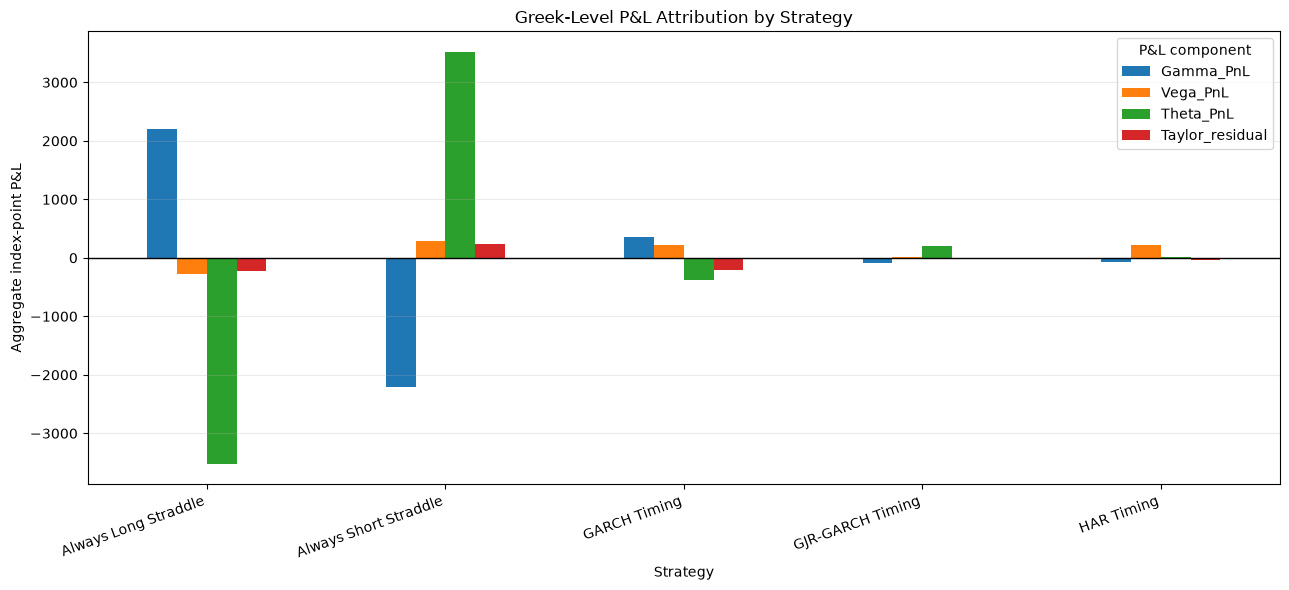

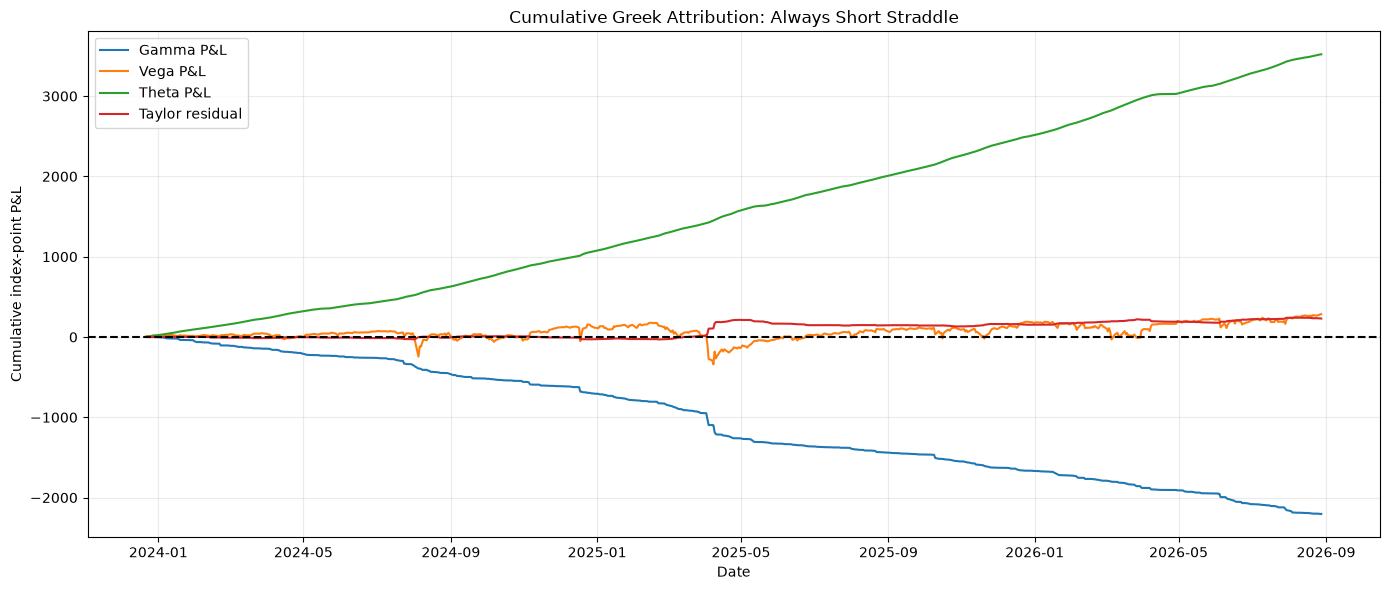


STAGE 21 COMPLETED
Active trades attributed: 104
Daily attribution observations: 2184

Available variables:
daily_attribution
trade_attribution
attribution_summary


In [29]:

# ============================================================
# STAGE 21: DAILY GREEK-LEVEL P&L ATTRIBUTION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Verify Stage 20 variables
# ------------------------------------------------------------

required_variables = [
    "term_data",
    "gamma_trades_v2",
    "maturity_matched_iv",
    "OPTION_TENOR_DAYS",
    "HOLD",
    "HEDGE_COST_BPS"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Run Stage 20 first. Missing: {missing}"
    )


# ------------------------------------------------------------
# 2. Define complete Black-Scholes straddle Greeks
# ------------------------------------------------------------

def bs_straddle_greeks(
    spot,
    strike,
    time_to_maturity,
    volatility,
    risk_free_rate=0.0,
    dividend_yield=0.0
):

    S = float(spot)
    K = float(strike)
    T = float(time_to_maturity)
    sigma = float(volatility)
    r = float(risk_free_rate)
    q = float(dividend_yield)

    if min(S, K, T, sigma) <= 0:
        raise ValueError(
            "Spot, strike, maturity and volatility must be positive."
        )

    sqrt_T = np.sqrt(T)

    d1 = (
        np.log(S / K)
        + (r - q + 0.5 * sigma**2) * T
    ) / (sigma * sqrt_T)

    d2 = d1 - sigma * sqrt_T

    discount_r = np.exp(-r * T)
    discount_q = np.exp(-q * T)

    density = norm.pdf(d1)

    call = (
        S * discount_q * norm.cdf(d1)
        - K * discount_r * norm.cdf(d2)
    )

    put = (
        K * discount_r * norm.cdf(-d2)
        - S * discount_q * norm.cdf(-d1)
    )

    # Straddle delta
    delta = (
        discount_q * (2 * norm.cdf(d1) - 1)
    )

    # Straddle gamma
    gamma = (
        2 * discount_q * density
        / (S * sigma * sqrt_T)
    )

    # Straddle vega: per 1.0 change in decimal volatility.
    # For a 1 percentage-point move, multiply by 0.01.
    vega = (
        2 * S * discount_q * density * sqrt_T
    )

    # Call theta
    common_theta = (
        -S * discount_q * density * sigma
        / (2 * sqrt_T)
    )

    call_theta = (
        common_theta
        - r * K * discount_r * norm.cdf(d2)
        + q * S * discount_q * norm.cdf(d1)
    )

    # Put theta
    put_theta = (
        common_theta
        + r * K * discount_r * norm.cdf(-d2)
        - q * S * discount_q * norm.cdf(-d1)
    )

    theta = call_theta + put_theta

    return {
        "price": call + put,
        "delta": delta,
        "gamma": gamma,
        "vega": vega,
        "theta": theta
    }


# ------------------------------------------------------------
# 3. Identify active Stage 20 trades
# ------------------------------------------------------------

active_trades = gamma_trades_v2[
    gamma_trades_v2["Direction"].isin([-1, 1])
].copy()

print("Active trades:", len(active_trades))
print(
    "Strategies:",
    active_trades["Strategy"].unique().tolist()
)


# ------------------------------------------------------------
# 4. Reconstruct daily Greek attribution
# ------------------------------------------------------------

daily_records = []
trade_records = []

for trade_number, trade in active_trades.iterrows():

    strategy = trade["Strategy"]
    direction = int(trade["Direction"])

    entry_date = pd.Timestamp(trade["Entry date"])

    if entry_date not in term_data.index:
        raise ValueError(
            f"Entry date {entry_date} not found in term_data."
        )

    entry_pos = term_data.index.get_loc(entry_date)

    path = term_data.iloc[
        entry_pos:entry_pos + HOLD + 1
    ].copy()

    if len(path) != HOLD + 1:
        raise ValueError(
            f"Incomplete price path for {entry_date}."
        )

    prices = path["SPX"].to_numpy(dtype=float)

    strike = prices[0]

    expiry_date = (
        entry_date
        + pd.Timedelta(days=OPTION_TENOR_DAYS)
    )

    # --------------------------------------------------------
    # Calculate daily option marks and Greeks
    # --------------------------------------------------------

    marks = []

    for j, date in enumerate(path.index):

        remaining_days = (
            expiry_date - date
        ).days

        if remaining_days <= 0:
            raise ValueError("Option expired before exit.")

        iv = maturity_matched_iv(
            path.iloc[j],
            remaining_days
        )

        greeks = bs_straddle_greeks(
            spot=prices[j],
            strike=strike,
            time_to_maturity=remaining_days / 365,
            volatility=iv,
            risk_free_rate=RISK_FREE_RATE,
            dividend_yield=DIVIDEND_YIELD
        )

        greeks["IV"] = iv
        greeks["remaining_days"] = remaining_days

        marks.append(greeks)

    # --------------------------------------------------------
    # Initial delta hedge
    # --------------------------------------------------------

    hedge_position = (
        -direction * marks[0]["delta"]
    )

    hedge_turnover = (
        abs(hedge_position) * prices[0]
    )

    total_hedge_pnl = 0.0
    total_delta_pnl = 0.0
    total_gamma_pnl = 0.0
    total_vega_pnl = 0.0
    total_theta_pnl = 0.0
    total_residual = 0.0

    # --------------------------------------------------------
    # Daily attribution
    # --------------------------------------------------------

    for j in range(HOLD):

        date0 = path.index[j]
        date1 = path.index[j + 1]

        state0 = marks[j]
        state1 = marks[j + 1]

        S0 = prices[j]
        S1 = prices[j + 1]

        dS = S1 - S0

        d_sigma = (
            state1["IV"] - state0["IV"]
        )

        dt_years = (
            (date1 - date0).days / 365
        )

        # Exact daily change in theoretical option value
        exact_option_change = (
            state1["price"] - state0["price"]
        )

        # First-order delta contribution
        delta_component = (
            state0["delta"] * dS
        )

        # Second-order gamma approximation
        gamma_component = (
            0.5 * state0["gamma"] * dS**2
        )

        # Vega contribution
        vega_component = (
            state0["vega"] * d_sigma
        )

        # Theta contribution
        theta_component = (
            state0["theta"] * dt_years
        )

        # Remaining terms:
        # higher-order effects, cross Greeks,
        # jumps and Taylor approximation error.

        residual_component = (
            exact_option_change
            - delta_component
            - gamma_component
            - vega_component
            - theta_component
        )

        # Apply long/short option direction
        delta_pnl = direction * delta_component
        gamma_pnl = direction * gamma_component
        vega_pnl = direction * vega_component
        theta_pnl = direction * theta_component
        residual_pnl = direction * residual_component

        option_mark_pnl = (
            direction * exact_option_change
        )

        # Existing delta hedge earns this daily P&L
        hedge_pnl = (
            hedge_position * dS
        )

        # Rebalance at every daily close except final exit
        if j < HOLD - 1:

            next_hedge = (
                -direction * state1["delta"]
            )

            turnover = (
                abs(next_hedge - hedge_position) * S1
            )

            hedge_turnover += turnover

            hedge_position = next_hedge

        else:

            # Close the existing hedge on final day
            hedge_turnover += (
                abs(hedge_position) * S1
            )

        total_hedge_pnl += hedge_pnl
        total_delta_pnl += delta_pnl
        total_gamma_pnl += gamma_pnl
        total_vega_pnl += vega_pnl
        total_theta_pnl += theta_pnl
        total_residual += residual_pnl

        daily_records.append({
            "Strategy": strategy,
            "Entry date": entry_date,
            "Date": date1,
            "SPX": S1,
            "IV": state1["IV"],
            "dSPX": dS,
            "dIV": d_sigma,
            "Option mark P&L": option_mark_pnl,
            "Delta P&L": delta_pnl,
            "Gamma P&L": gamma_pnl,
            "Vega P&L": vega_pnl,
            "Theta P&L": theta_pnl,
            "Taylor residual": residual_pnl,
            "Hedge P&L": hedge_pnl
        })

    # --------------------------------------------------------
    # Trade-level reconciliation
    # --------------------------------------------------------

    option_pnl = sum([
        total_delta_pnl,
        total_gamma_pnl,
        total_vega_pnl,
        total_theta_pnl,
        total_residual
    ])

    hedge_cost = (
        hedge_turnover * HEDGE_COST_BPS / 10000
    )

    net_pnl = option_pnl + total_hedge_pnl - hedge_cost

    stage20_net = float(trade["Net P&L"])

    reconciliation_difference = (
        net_pnl - stage20_net
    )

    trade_records.append({
        "Strategy": strategy,
        "Entry date": entry_date,
        "Direction": direction,
        "Delta P&L": total_delta_pnl,
        "Gamma P&L": total_gamma_pnl,
        "Vega P&L": total_vega_pnl,
        "Theta P&L": total_theta_pnl,
        "Taylor residual": total_residual,
        "Option P&L": option_pnl,
        "Hedge P&L": total_hedge_pnl,
        "Hedge cost": hedge_cost,
        "Net P&L": net_pnl,
        "Stage 20 Net P&L": stage20_net,
        "Reconciliation difference": reconciliation_difference
    })


# ------------------------------------------------------------
# 5. Save attribution results in DataFrames
# ------------------------------------------------------------

daily_attribution = pd.DataFrame(daily_records)

trade_attribution = pd.DataFrame(trade_records)

# ------------------------------------------------------------
# 6. Aggregate by strategy
# ------------------------------------------------------------

attribution_summary = (
    trade_attribution
    .groupby("Strategy")
    .agg(
        Trades=("Net P&L", "count"),
        Delta_PnL=("Delta P&L", "sum"),
        Gamma_PnL=("Gamma P&L", "sum"),
        Vega_PnL=("Vega P&L", "sum"),
        Theta_PnL=("Theta P&L", "sum"),
        Taylor_residual=("Taylor residual", "sum"),
        Option_PnL=("Option P&L", "sum"),
        Hedge_PnL=("Hedge P&L", "sum"),
        Hedge_cost=("Hedge cost", "sum"),
        Net_PnL=("Net P&L", "sum"),
        Mean_reconciliation_error=(
            "Reconciliation difference", "mean"
        ),
        Maximum_absolute_reconciliation_error=(
            "Reconciliation difference",
            lambda x: np.max(np.abs(x))
        )
    )
)

print("\nGREEK-LEVEL P&L ATTRIBUTION")

display(attribution_summary.round(6))


# ------------------------------------------------------------
# 7. Verify delta neutrality
# ------------------------------------------------------------

attribution_summary["Delta plus Hedge"] = (
    attribution_summary["Delta_PnL"]
    + attribution_summary["Hedge_PnL"]
)

print("\nDELTA HEDGE RECONCILIATION")

display(
    attribution_summary[
        [
            "Delta_PnL",
            "Hedge_PnL",
            "Delta plus Hedge"
        ]
    ].round(10)
)


# ------------------------------------------------------------
# 8. Verify Stage 20 reconciliation
# ------------------------------------------------------------

print("\nSTAGE 20 NET P&L RECONCILIATION")

display(
    trade_attribution[
        [
            "Strategy",
            "Entry date",
            "Net P&L",
            "Stage 20 Net P&L",
            "Reconciliation difference"
        ]
    ].head(15).round(10)
)

max_error = (
    trade_attribution["Reconciliation difference"]
    .abs()
    .max()
)

print("Maximum absolute reconciliation error:", max_error)


# ------------------------------------------------------------
# 9. Visualise the P&L attribution
# ------------------------------------------------------------

attribution_columns = [
    "Gamma_PnL",
    "Vega_PnL",
    "Theta_PnL",
    "Taylor_residual"
]

attribution_plot = attribution_summary[
    attribution_columns
]

ax = attribution_plot.plot(
    kind="bar",
    figsize=(13, 6)
)

ax.axhline(0, color="black", linewidth=1)

ax.set_title(
    "Greek-Level P&L Attribution by Strategy"
)

ax.set_xlabel("Strategy")
ax.set_ylabel("Aggregate index-point P&L")
ax.legend(title="P&L component")
ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Daily Greek attribution for the short benchmark
# ------------------------------------------------------------

short_daily = daily_attribution[
    (daily_attribution["Strategy"] == "Always Short Straddle")
]

fig, ax = plt.subplots(figsize=(14, 6))

for column in [
    "Gamma P&L",
    "Vega P&L",
    "Theta P&L",
    "Taylor residual"
]:

    daily_series = (
        short_daily
        .groupby("Date")[column]
        .sum()
        .sort_index()
        .cumsum()
    )

    ax.plot(
        daily_series.index,
        daily_series,
        label=column
    )

ax.axhline(0, color="black", linestyle="--")

ax.set_title(
    "Cumulative Greek Attribution: Always Short Straddle"
)

ax.set_xlabel("Date")
ax.set_ylabel("Cumulative index-point P&L")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. Completion check
# ------------------------------------------------------------

print("\nSTAGE 21 COMPLETED")

print("Active trades attributed:", len(trade_attribution))
print("Daily attribution observations:", len(daily_attribution))

print("\nAvailable variables:")
print("daily_attribution")
print("trade_attribution")
print("attribution_summary")


## Stage 22 — Higher-order Greek attribution
Add vanna and volga to explain spot–volatility interaction effects.


Active trades: 104

EXTENDED GREEK P&L ATTRIBUTION


,Trades,Delta_PnL,Gamma_PnL,Vega_PnL,Theta_PnL,Vanna_PnL,Volga_PnL,Taylor_residual,Hedge_PnL,Hedge_cost,Net_PnL
Strategy,,,,,,,,,,,
Always Long Straddle,32,31.336892,2203.772511,-284.658262,-3520.335379,-212.182513,152.374389,-170.171077,-31.336892,47.699218,-1878.899548
Always Short Straddle,32,-31.336892,-2203.772511,284.658262,3520.335379,212.182513,-152.374389,170.171077,31.336892,47.699218,1783.501113
GARCH Timing,14,-410.629480,361.311751,227.408790,-371.152864,-295.557783,27.574518,53.203900,410.629480,21.527589,-18.739277
GJR-GARCH Timing,14,-245.089579,-87.258931,15.840636,199.519734,-77.056927,-26.201715,77.817832,245.089579,20.573705,82.086923
HAR Timing,12,-222.862042,-71.593913,222.540009,16.539557,-53.612690,-34.296019,52.388481,222.862042,17.613774,114.351651



DELTA-NEUTRALITY CHECK


,Delta_PnL,Hedge_PnL,Delta plus hedge
Strategy,,,
Always Long Straddle,31.336892,-31.336892,0.0
Always Short Straddle,-31.336892,31.336892,0.0
GARCH Timing,-410.629480,410.629480,0.0
GJR-GARCH Timing,-245.089579,245.089579,0.0
HAR Timing,-222.862042,222.862042,0.0



Maximum absolute P&L reconciliation error: 7.105427357601002e-14


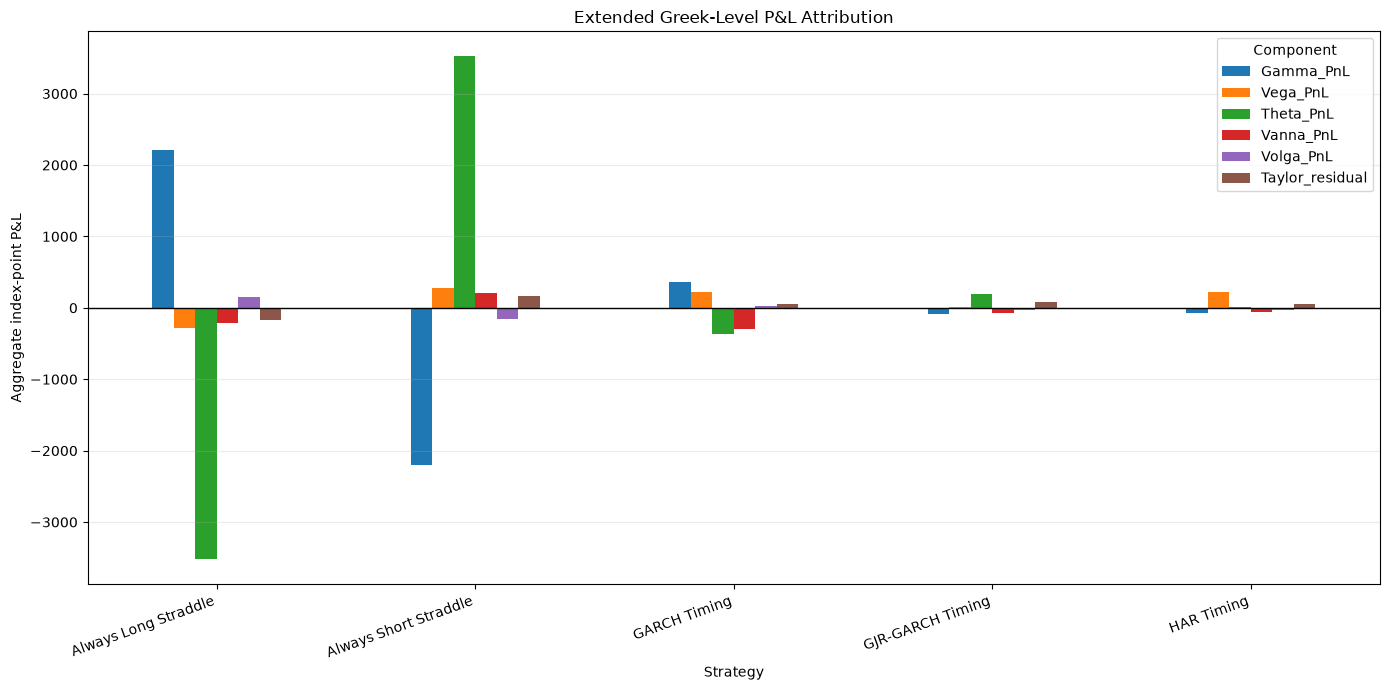

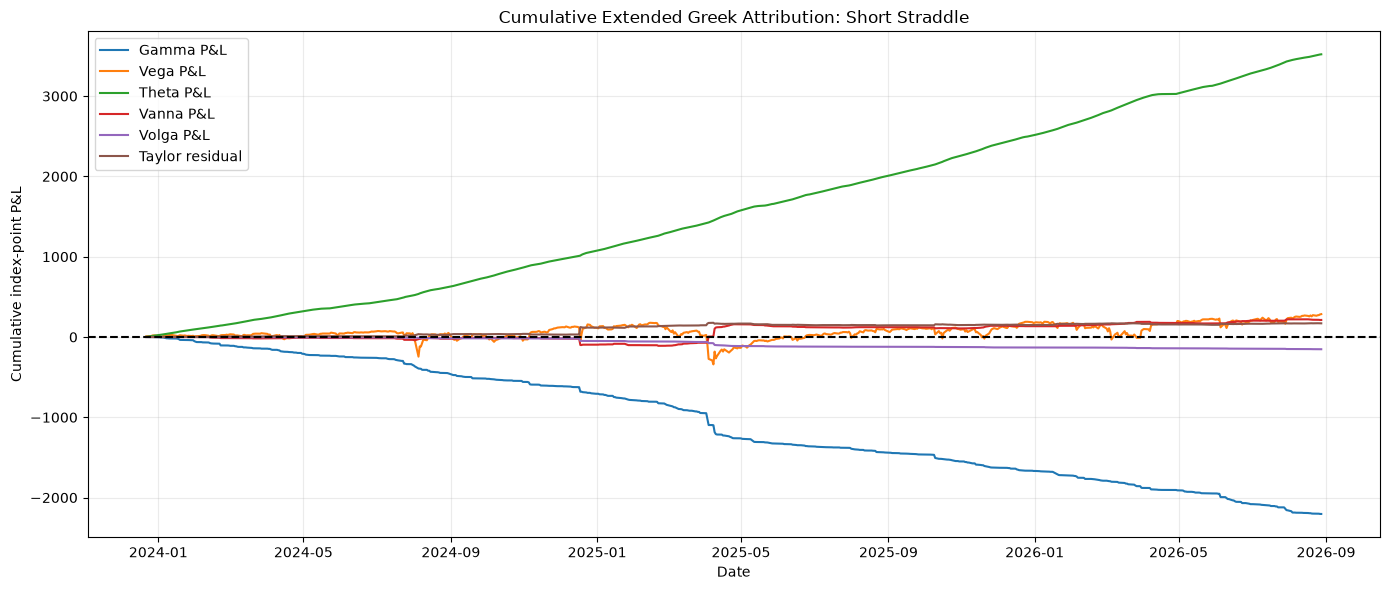


RESIDUAL COMPARISON


,Stage 21 residual,Stage 22 residual,Residual reduction
Strategy,,,
Always Long Straddle,-229.979200,-170.171077,-59.808124
Always Short Straddle,229.979200,170.171077,59.808124
GARCH Timing,-214.779365,53.203900,-267.983265
GJR-GARCH Timing,-25.440810,77.817832,-103.258642
HAR Timing,-35.520227,52.388481,-87.908709



STAGE 22 COMPLETED
Attributed trades: 104
Daily observations: 2184
Maximum absolute reconciliation error: 7.105427357601002e-14

Available variables:
daily_attribution_v2
trade_attribution_v2
attribution_summary_v2
residual_comparison


In [30]:

# ============================================================
# STAGE 22: VANNA, VOLGA AND EXTENDED GREEK ATTRIBUTION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm
from IPython.display import display

# ------------------------------------------------------------
# 1. Verify Stage 20 and Stage 21 variables
# ------------------------------------------------------------

required_variables = [
    "term_data",
    "gamma_trades_v2",
    "maturity_matched_iv",
    "OPTION_TENOR_DAYS",
    "HOLD"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing variables. Run Stage 20 first: {missing}"
    )

RF = globals().get("RISK_FREE_RATE", 0.0)
DIVIDEND = globals().get("DIVIDEND_YIELD", 0.0)
HEDGE_BPS = globals().get("HEDGE_COST_BPS", 1.0)


# ------------------------------------------------------------
# 2. Extended Black-Scholes straddle Greeks
# ------------------------------------------------------------

def bs_extended_greeks(
    spot,
    strike,
    time_to_maturity,
    volatility,
    risk_free_rate=RF,
    dividend_yield=DIVIDEND
):

    S = float(spot)
    K = float(strike)
    T = float(time_to_maturity)
    sigma = float(volatility)
    r = float(risk_free_rate)
    q = float(dividend_yield)

    if min(S, K, T, sigma) <= 0:
        raise ValueError(
            "Spot, strike, maturity and volatility must be positive."
        )

    sqrt_T = np.sqrt(T)

    discount_r = np.exp(-r * T)
    discount_q = np.exp(-q * T)

    d1 = (
        np.log(S / K)
        + (r - q + 0.5 * sigma**2) * T
    ) / (sigma * sqrt_T)

    d2 = d1 - sigma * sqrt_T

    density = norm.pdf(d1)

    # Straddle price
    call = (
        S * discount_q * norm.cdf(d1)
        - K * discount_r * norm.cdf(d2)
    )

    put = (
        K * discount_r * norm.cdf(-d2)
        - S * discount_q * norm.cdf(-d1)
    )

    # First-order Greeks
    delta = (
        discount_q * (2 * norm.cdf(d1) - 1)
    )

    vega = (
        2 * S * discount_q * density * sqrt_T
    )

    # Second-order Greeks
    gamma = (
        2 * discount_q * density
        / (S * sigma * sqrt_T)
    )

    # Vanna = d²V / (dS dσ)
    vanna = (
        -2 * discount_q * density * d2 / sigma
    )

    # Volga / Vomma = d²V / dσ²
    volga = (
        vega * d1 * d2 / sigma
    )

    # Calendar-time theta, per year
    common_theta = (
        -S * discount_q * density * sigma
        / (2 * sqrt_T)
    )

    call_theta = (
        common_theta
        - r * K * discount_r * norm.cdf(d2)
        + q * S * discount_q * norm.cdf(d1)
    )

    put_theta = (
        common_theta
        + r * K * discount_r * norm.cdf(-d2)
        - q * S * discount_q * norm.cdf(-d1)
    )

    theta = call_theta + put_theta

    return {
        "price": call + put,
        "delta": delta,
        "gamma": gamma,
        "vega": vega,
        "theta": theta,
        "vanna": vanna,
        "volga": volga,
        "d1": d1,
        "d2": d2
    }


# ------------------------------------------------------------
# 3. Identify active trades
# ------------------------------------------------------------

active_trades_v2 = gamma_trades_v2[
    gamma_trades_v2["Direction"].isin([-1, 1])
].copy()

print("Active trades:", len(active_trades_v2))


# ------------------------------------------------------------
# 4. Reconstruct daily extended Greek attribution
# ------------------------------------------------------------

daily_records_v2 = []
trade_records_v2 = []

for trade_number, trade in active_trades_v2.iterrows():

    strategy = trade["Strategy"]
    direction = int(trade["Direction"])

    entry_date = pd.Timestamp(trade["Entry date"])

    entry_pos = term_data.index.get_loc(entry_date)

    path = term_data.iloc[
        entry_pos:entry_pos + HOLD + 1
    ].copy()

    if len(path) != HOLD + 1:
        raise ValueError(
            f"Incomplete path for {entry_date}"
        )

    prices = path["SPX"].to_numpy(dtype=float)

    strike = prices[0]

    expiry_date = (
        entry_date
        + pd.Timedelta(days=OPTION_TENOR_DAYS)
    )

    marks = []

    # --------------------------------------------------------
    # Calculate daily theoretical prices and Greeks
    # --------------------------------------------------------

    for j, date in enumerate(path.index):

        remaining_days = (
            expiry_date - date
        ).days

        if remaining_days <= 0:
            raise ValueError("Option expired.")

        iv = maturity_matched_iv(
            path.iloc[j],
            remaining_days
        )

        greeks = bs_extended_greeks(
            spot=prices[j],
            strike=strike,
            time_to_maturity=remaining_days / 365,
            volatility=iv
        )

        greeks["IV"] = iv
        greeks["remaining_days"] = remaining_days

        marks.append(greeks)

    # Initial delta hedge
    hedge_position = (
        -direction * marks[0]["delta"]
    )

    hedge_turnover = (
        abs(hedge_position) * prices[0]
    )

    totals = {
        "Delta": 0.0,
        "Gamma": 0.0,
        "Vega": 0.0,
        "Theta": 0.0,
        "Vanna": 0.0,
        "Volga": 0.0,
        "Residual": 0.0,
        "Hedge": 0.0
    }

    # --------------------------------------------------------
    # Daily P&L attribution
    # --------------------------------------------------------

    for j in range(HOLD):

        date0 = path.index[j]
        date1 = path.index[j + 1]

        state0 = marks[j]
        state1 = marks[j + 1]

        S0 = prices[j]
        S1 = prices[j + 1]

        dS = S1 - S0

        d_sigma = (
            state1["IV"] - state0["IV"]
        )

        dt_years = (
            (date1 - date0).days / 365
        )

        # Exact change in option theoretical value
        exact_dV = (
            state1["price"] - state0["price"]
        )

        # First-order components
        delta_component = (
            state0["delta"] * dS
        )

        vega_component = (
            state0["vega"] * d_sigma
        )

        theta_component = (
            state0["theta"] * dt_years
        )

        # Second-order components
        gamma_component = (
            0.5 * state0["gamma"] * dS**2
        )

        vanna_component = (
            state0["vanna"] * dS * d_sigma
        )

        volga_component = (
            0.5 * state0["volga"] * d_sigma**2
        )

        # Remaining higher-order and time interaction effects
        residual_component = (
            exact_dV
            - delta_component
            - gamma_component
            - vega_component
            - theta_component
            - vanna_component
            - volga_component
        )

        # Apply long/short direction
        components = {
            "Delta": direction * delta_component,
            "Gamma": direction * gamma_component,
            "Vega": direction * vega_component,
            "Theta": direction * theta_component,
            "Vanna": direction * vanna_component,
            "Volga": direction * volga_component,
            "Residual": direction * residual_component
        }

        # Existing hedge earns daily spot movement
        hedge_pnl = hedge_position * dS

        # Rebalance at each daily close, except final exit
        if j < HOLD - 1:

            target_hedge = (
                -direction * state1["delta"]
            )

            hedge_turnover += (
                abs(target_hedge - hedge_position) * S1
            )

            hedge_position = target_hedge

        else:

            # Close the hedge at exit
            hedge_turnover += (
                abs(hedge_position) * S1
            )

        # Accumulate each component
        for component, value in components.items():
            totals[component] += value

        totals["Hedge"] += hedge_pnl

        daily_records_v2.append({
            "Strategy": strategy,
            "Entry date": entry_date,
            "Date": date1,
            "Spot change": dS,
            "IV change": d_sigma,
            "Delta P&L": components["Delta"],
            "Gamma P&L": components["Gamma"],
            "Vega P&L": components["Vega"],
            "Theta P&L": components["Theta"],
            "Vanna P&L": components["Vanna"],
            "Volga P&L": components["Volga"],
            "Taylor residual": components["Residual"],
            "Hedge P&L": hedge_pnl
        })

    # --------------------------------------------------------
    # Trade-level P&L reconciliation
    # --------------------------------------------------------

    option_pnl = sum([
        totals["Delta"],
        totals["Gamma"],
        totals["Vega"],
        totals["Theta"],
        totals["Vanna"],
        totals["Volga"],
        totals["Residual"]
    ])

    hedge_cost = (
        hedge_turnover * HEDGE_BPS / 10000
    )

    net_pnl = (
        option_pnl
        + totals["Hedge"]
        - hedge_cost
    )

    stage20_net = float(trade["Net P&L"])

    trade_records_v2.append({
        "Strategy": strategy,
        "Entry date": entry_date,
        "Delta P&L": totals["Delta"],
        "Gamma P&L": totals["Gamma"],
        "Vega P&L": totals["Vega"],
        "Theta P&L": totals["Theta"],
        "Vanna P&L": totals["Vanna"],
        "Volga P&L": totals["Volga"],
        "Taylor residual": totals["Residual"],
        "Hedge P&L": totals["Hedge"],
        "Hedge cost": hedge_cost,
        "Option P&L": option_pnl,
        "Net P&L": net_pnl,
        "Stage 20 Net P&L": stage20_net,
        "Reconciliation error": net_pnl - stage20_net
    })


# ------------------------------------------------------------
# 5. Store results
# ------------------------------------------------------------

daily_attribution_v2 = pd.DataFrame(
    daily_records_v2
)

trade_attribution_v2 = pd.DataFrame(
    trade_records_v2
)

# ------------------------------------------------------------
# 6. Aggregate by strategy
# ------------------------------------------------------------

attribution_summary_v2 = (
    trade_attribution_v2
    .groupby("Strategy")
    .agg(
        Trades=("Net P&L", "count"),
        Delta_PnL=("Delta P&L", "sum"),
        Gamma_PnL=("Gamma P&L", "sum"),
        Vega_PnL=("Vega P&L", "sum"),
        Theta_PnL=("Theta P&L", "sum"),
        Vanna_PnL=("Vanna P&L", "sum"),
        Volga_PnL=("Volga P&L", "sum"),
        Taylor_residual=("Taylor residual", "sum"),
        Hedge_PnL=("Hedge P&L", "sum"),
        Hedge_cost=("Hedge cost", "sum"),
        Net_PnL=("Net P&L", "sum")
    )
)

print("\nEXTENDED GREEK P&L ATTRIBUTION")

display(attribution_summary_v2.round(6))


# ------------------------------------------------------------
# 7. Reconciliation checks
# ------------------------------------------------------------

max_reconciliation_error = (
    trade_attribution_v2["Reconciliation error"]
    .abs()
    .max()
)

attribution_summary_v2["Delta plus hedge"] = (
    attribution_summary_v2["Delta_PnL"]
    + attribution_summary_v2["Hedge_PnL"]
)

print("\nDELTA-NEUTRALITY CHECK")

display(
    attribution_summary_v2[
        ["Delta_PnL", "Hedge_PnL", "Delta plus hedge"]
    ].round(10)
)

print(
    "\nMaximum absolute P&L reconciliation error:",
    max_reconciliation_error
)


# ------------------------------------------------------------
# 8. Greek-level P&L decomposition plot
# ------------------------------------------------------------

greek_columns = [
    "Gamma_PnL",
    "Vega_PnL",
    "Theta_PnL",
    "Vanna_PnL",
    "Volga_PnL",
    "Taylor_residual"
]

ax = attribution_summary_v2[
    greek_columns
].plot(
    kind="bar",
    figsize=(14, 7)
)

ax.axhline(0, color="black", linewidth=1)

ax.set_title(
    "Extended Greek-Level P&L Attribution"
)

ax.set_xlabel("Strategy")
ax.set_ylabel("Aggregate index-point P&L")

ax.legend(title="Component")
ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Cumulative vanna and volga P&L:
# Always short straddle
# ------------------------------------------------------------

short_daily = daily_attribution_v2[
    daily_attribution_v2["Strategy"]
    == "Always Short Straddle"
].copy()

short_daily = (
    short_daily
    .groupby("Date")[
        [
            "Gamma P&L",
            "Vega P&L",
            "Theta P&L",
            "Vanna P&L",
            "Volga P&L",
            "Taylor residual"
        ]
    ]
    .sum()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(14, 6))

for column in [
    "Gamma P&L",
    "Vega P&L",
    "Theta P&L",
    "Vanna P&L",
    "Volga P&L",
    "Taylor residual"
]:

    ax.plot(
        short_daily.index,
        short_daily[column].cumsum(),
        label=column
    )

ax.axhline(0, color="black", linestyle="--")

ax.set_title(
    "Cumulative Extended Greek Attribution: Short Straddle"
)

ax.set_xlabel("Date")
ax.set_ylabel("Cumulative index-point P&L")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Compare old and extended residuals
# ------------------------------------------------------------

residual_comparison = pd.DataFrame({
    "Stage 21 residual": (
        trade_attribution
        .groupby("Strategy")["Taylor residual"]
        .sum()
    ),
    "Stage 22 residual": (
        trade_attribution_v2
        .groupby("Strategy")["Taylor residual"]
        .sum()
    )
})

residual_comparison["Residual reduction"] = (
    residual_comparison["Stage 21 residual"]
    - residual_comparison["Stage 22 residual"]
)

print("\nRESIDUAL COMPARISON")

display(residual_comparison.round(6))


# ------------------------------------------------------------
# 11. Completion
# ------------------------------------------------------------

print("\nSTAGE 22 COMPLETED")

print("Attributed trades:", len(trade_attribution_v2))
print("Daily observations:", len(daily_attribution_v2))

print("Maximum absolute reconciliation error:",
      max_reconciliation_error)

print("\nAvailable variables:")
print("daily_attribution_v2")
print("trade_attribution_v2")
print("attribution_summary_v2")
print("residual_comparison")


## Stage 23 — Greek validation
Compare analytical Black–Scholes Greeks with finite-difference estimates.


Selected validation dates: 12
First selected date: 2023-12-21 00:00:00
Last selected date: 2026-07-30 00:00:00
Number of validation states: 60


,Entry date,Date,Spot,Strike,Maturity,Volatility
0,2023-12-21,2023-12-21,4746.750000,4746.75,0.120548,0.142814
1,2023-12-21,2023-12-29,4769.830078,4746.75,0.098630,0.127443
2,2023-12-21,2024-01-08,4763.540039,4746.75,0.071233,0.128286
3,2023-12-21,2024-01-16,4765.979980,4746.75,0.049315,0.131677
4,2023-12-21,2024-01-23,4864.600098,4746.75,0.030137,0.124957



ANALYTICAL VS NUMERICAL GREEK VALIDATION


,Tests,Mean_absolute_error,Maximum_absolute_error,Median_relative_error,P95_relative_error,Maximum_relative_error
Greek,,,,,,
Delta,60,3.000000e-07,1.710000e-06,1.110000e-06,2.300000e-06,4.130000e-06
Gamma,60,0.000000e+00,1.000000e-08,3.300000e-07,1.370000e-06,3.760000e-06
Theta,60,2.890000e-06,1.418000e-05,0.000000e+00,1.000000e-08,2.000000e-08
Vanna,60,3.475000e-05,1.806200e-04,2.026000e-05,6.620000e-05,1.000200e-04
Vega,60,3.586030e-03,1.575889e-02,1.350000e-06,2.350000e-05,4.938000e-05
Volga,60,3.539121e-02,1.606056e-01,2.033000e-05,5.802000e-05,7.406000e-05



LARGEST GREEK VALIDATION ERRORS


C:\Users\Bhavya\AppData\Local\Temp\ipykernel_5736\3067312156.py:390: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).head(20).round(8)


,Entry date,Date,Greek,Analytical,Finite difference,Absolute error,Relative error
70,2024-05-23,2024-05-31,Vanna,-0.146089,-0.146103,0.000015,0.000100
100,2024-08-23,2024-08-30,Vanna,-0.134663,-0.134673,0.000010,0.000077
71,2024-05-23,2024-05-31,Volga,15.776278,15.777447,0.001168,0.000074
10,2023-12-21,2023-12-29,Vanna,-0.627158,-0.627201,0.000043,0.000068
16,2023-12-21,2024-01-08,Vanna,-0.531073,-0.531108,0.000035,0.000066
11,2023-12-21,2023-12-29,Volga,132.655169,132.663475,0.008306,0.000063
17,2023-12-21,2024-01-08,Volga,81.188315,81.193351,0.005036,0.000062
88,2024-05-23,2024-06-24,Vanna,-3.047209,-3.047029,0.000181,0.000059
77,2024-05-23,2024-06-07,Volga,1662.323108,1662.419206,0.096097,0.000058
23,2023-12-21,2024-01-16,Volga,119.818432,119.825320,0.006888,0.000057



DAILY ABSOLUTE RESIDUAL COMPARISON


,Observations,Stage21_mean_abs_residual,Stage22_mean_abs_residual,Stage21_p95_abs_residual,Stage22_p95_abs_residual,Mean absolute residual reduction (%)
Strategy,,,,,,
Always Long Straddle,672,1.317195,0.911761,4.481793,2.581232,30.780108
Always Short Straddle,672,1.317195,0.911761,4.481793,2.581232,30.780108
GARCH Timing,294,1.844627,1.234782,6.088220,3.000317,33.060583
GJR-GARCH Timing,294,1.177684,1.097461,4.705167,2.834603,6.811966
HAR Timing,252,1.077695,1.054702,3.983778,2.734591,2.133559


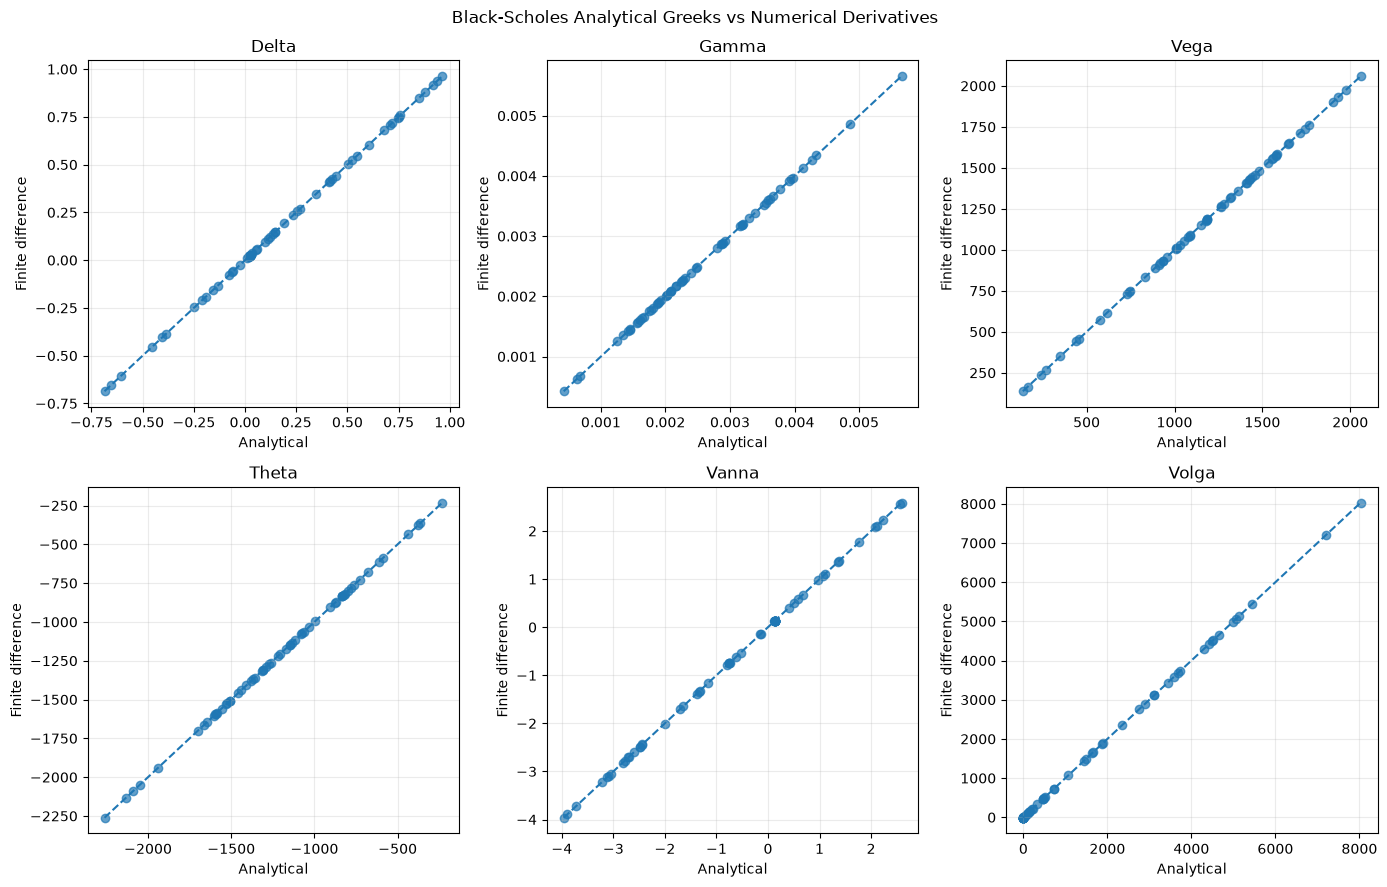

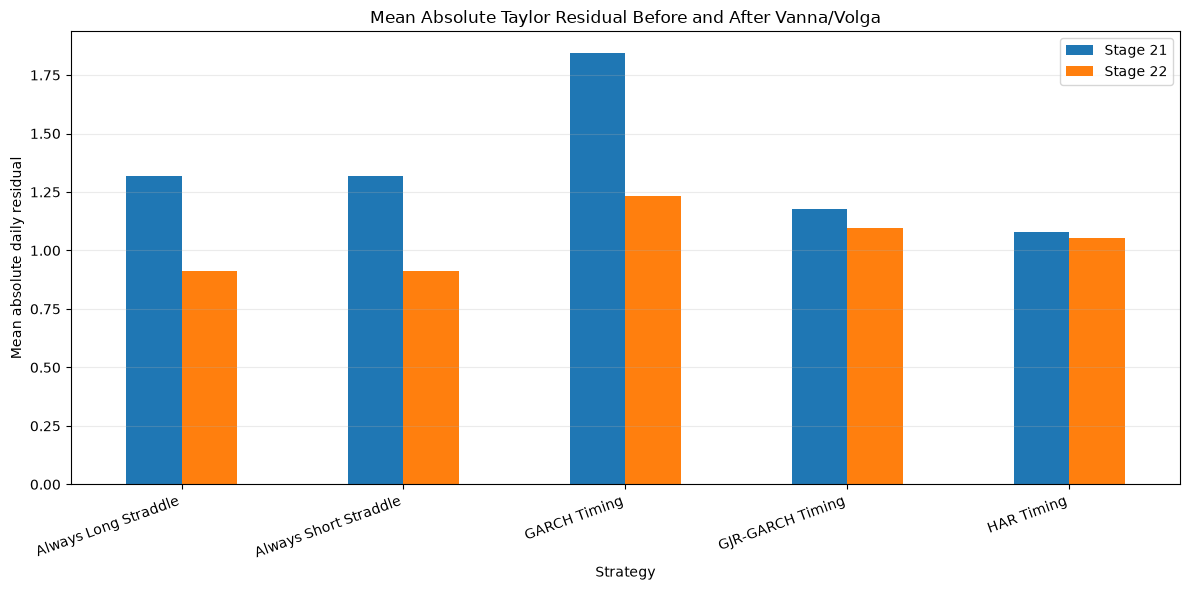


STAGE 23 COMPLETED
Validation states: 60
Greek comparisons: 360

Available variables:
validation_states
greek_validation
greek_validation_summary
residual_daily_comparison
residual_daily_summary


In [31]:

# ============================================================
# STAGE 23: FINITE-DIFFERENCE VALIDATION OF BLACK-SCHOLES GREEKS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm

# ------------------------------------------------------------
# 1. Configuration and dependency checks
# ------------------------------------------------------------

required_variables = [
    "term_data",
    "gamma_trades_v2",
    "daily_attribution",
    "daily_attribution_v2",
    "bs_extended_greeks",
    "maturity_matched_iv",
    "OPTION_TENOR_DAYS",
    "HOLD"
]

missing = [
    x for x in required_variables
    if x not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing variables. Run previous stages: {missing}"
    )

RF = globals().get("RISK_FREE_RATE", 0.0)
DIVIDEND = globals().get("DIVIDEND_YIELD", 0.0)


# ------------------------------------------------------------
# 2. Independent Black-Scholes straddle pricing function
# ------------------------------------------------------------

def bs_price_independent(
    spot,
    strike,
    maturity,
    volatility,
    r=RF,
    q=DIVIDEND
):

    S = float(spot)
    K = float(strike)
    T = float(maturity)
    sigma = float(volatility)

    if min(S, K, T, sigma) <= 0:
        raise ValueError(
            "Inputs must be positive."
        )

    sqrt_T = np.sqrt(T)

    d1 = (
        np.log(S / K)
        + (r - q + 0.5 * sigma**2) * T
    ) / (sigma * sqrt_T)

    d2 = d1 - sigma * sqrt_T

    call = (
        S * np.exp(-q*T) * norm.cdf(d1)
        - K * np.exp(-r*T) * norm.cdf(d2)
    )

    put = (
        K * np.exp(-r*T) * norm.cdf(-d2)
        - S * np.exp(-q*T) * norm.cdf(-d1)
    )

    return call + put


# ------------------------------------------------------------
# 3. Create representative option states
# ------------------------------------------------------------

active_entries = (
    gamma_trades_v2.loc[
        gamma_trades_v2["Direction"].isin([-1, 1]),
        "Entry date"
    ]
)

unique_entries = sorted(
    pd.to_datetime(active_entries).unique()
)

# Select up to 12 dates spread across the evaluation sample.
number_of_entries = min(12, len(unique_entries))

# Select actual dates from the existing DatetimeIndex.
selected_positions = np.linspace(
    0,
    len(unique_entries) - 1,
    number_of_entries,
    dtype=int
)

selected_entries = [
    pd.Timestamp(unique_entries[int(i)])
    for i in selected_positions
]

# Ensure dates match term_data's index.
selected_entries = [
    date for date in selected_entries
    if date in term_data.index
]

print("Selected validation dates:", len(selected_entries))
print("First selected date:", selected_entries[0])
print("Last selected date:", selected_entries[-1])

sample_states = []

for entry_date in selected_entries:

    entry_pos = term_data.index.get_loc(entry_date)

    path = term_data.iloc[
        entry_pos:entry_pos + HOLD + 1
    ]

    if len(path) != HOLD + 1:
        continue

    strike = float(path["SPX"].iloc[0])

    expiry = (
        entry_date
        + pd.Timedelta(days=OPTION_TENOR_DAYS)
    )

    for j in [0, 5, 10, 15, 20]:

        row = path.iloc[j]
        date = path.index[j]

        S = float(row["SPX"])

        remaining_days = (
            expiry - date
        ).days

        T = remaining_days / 365

        sigma = maturity_matched_iv(
            row,
            remaining_days
        )

        sample_states.append({
            "Entry date": entry_date,
            "Date": date,
            "Spot": S,
            "Strike": strike,
            "Maturity": T,
            "Volatility": sigma
        })

validation_states = pd.DataFrame(sample_states)

print("Number of validation states:", len(validation_states))

display(validation_states.head())


# ------------------------------------------------------------
# 4. Finite-difference steps
# ------------------------------------------------------------

# Relative spot bump
SPOT_BUMP_RELATIVE = 1e-4

# Absolute decimal volatility bump
VOL_BUMP = 1e-3

# Maturity bump in years
TIME_BUMP = 1e-5


# ------------------------------------------------------------
# 5. Calculate analytical and numerical Greeks
# ------------------------------------------------------------

greek_records = []

for _, state in validation_states.iterrows():

    S = state["Spot"]
    K = state["Strike"]
    T = state["Maturity"]
    sigma = state["Volatility"]

    hS = S * SPOT_BUMP_RELATIVE
    hVol = VOL_BUMP
    hT = TIME_BUMP

    price = bs_price_independent(
        S, K, T, sigma
    )

    # --------------------------------------------------------
    # Analytical Greeks
    # --------------------------------------------------------

    analytical = bs_extended_greeks(
        S, K, T, sigma
    )

    # --------------------------------------------------------
    # Numerical delta
    # --------------------------------------------------------

    p_s_up = bs_price_independent(
        S + hS, K, T, sigma
    )

    p_s_down = bs_price_independent(
        S - hS, K, T, sigma
    )

    delta_fd = (
        p_s_up - p_s_down
    ) / (2 * hS)

    # --------------------------------------------------------
    # Numerical gamma
    # --------------------------------------------------------

    gamma_fd = (
        p_s_up - 2 * price + p_s_down
    ) / hS**2

    # --------------------------------------------------------
    # Numerical vega
    # --------------------------------------------------------

    p_vol_up = bs_price_independent(
        S, K, T, sigma + hVol
    )

    p_vol_down = bs_price_independent(
        S, K, T, sigma - hVol
    )

    vega_fd = (
        p_vol_up - p_vol_down
    ) / (2 * hVol)

    # --------------------------------------------------------
    # Numerical volga
    # --------------------------------------------------------

    volga_fd = (
        p_vol_up - 2 * price + p_vol_down
    ) / hVol**2

    # --------------------------------------------------------
    # Numerical vanna
    # --------------------------------------------------------

    p_sp_up_vol_up = bs_price_independent(
        S + hS, K, T, sigma + hVol
    )

    p_sp_up_vol_down = bs_price_independent(
        S + hS, K, T, sigma - hVol
    )

    p_sp_down_vol_up = bs_price_independent(
        S - hS, K, T, sigma + hVol
    )

    p_sp_down_vol_down = bs_price_independent(
        S - hS, K, T, sigma - hVol
    )

    vanna_fd = (
        p_sp_up_vol_up
        - p_sp_up_vol_down
        - p_sp_down_vol_up
        + p_sp_down_vol_down
    ) / (4 * hS * hVol)

    # --------------------------------------------------------
    # Numerical calendar-time theta
    # --------------------------------------------------------

    p_shorter_T = bs_price_independent(
        S, K, T - hT, sigma
    )

    p_longer_T = bs_price_independent(
        S, K, T + hT, sigma
    )

    # Calendar-time theta = negative maturity derivative
    theta_fd = (
        p_shorter_T - p_longer_T
    ) / (2 * hT)

    # --------------------------------------------------------
    # Store analytical and numerical estimates
    # --------------------------------------------------------

    comparisons = {
        "Delta": (analytical["delta"], delta_fd),
        "Gamma": (analytical["gamma"], gamma_fd),
        "Vega": (analytical["vega"], vega_fd),
        "Theta": (analytical["theta"], theta_fd),
        "Vanna": (analytical["vanna"], vanna_fd),
        "Volga": (analytical["volga"], volga_fd)
    }

    for greek, (analytical_value, numerical_value) in comparisons.items():

        abs_error = abs(
            analytical_value - numerical_value
        )

        scale = max(
            abs(analytical_value),
            abs(numerical_value),
            1e-10
        )

        relative_error = abs_error / scale

        greek_records.append({
            "Entry date": state["Entry date"],
            "Date": state["Date"],
            "Greek": greek,
            "Analytical": analytical_value,
            "Finite difference": numerical_value,
            "Absolute error": abs_error,
            "Relative error": relative_error
        })


# ------------------------------------------------------------
# 6. Store validation results
# ------------------------------------------------------------

greek_validation = pd.DataFrame(greek_records)

greek_validation_summary = (
    greek_validation
    .groupby("Greek")
    .agg(
        Tests=("Absolute error", "count"),
        Mean_absolute_error=("Absolute error", "mean"),
        Maximum_absolute_error=("Absolute error", "max"),
        Median_relative_error=("Relative error", "median"),
        P95_relative_error=(
            "Relative error",
            lambda x: x.quantile(0.95)
        ),
        Maximum_relative_error=("Relative error", "max")
    )
)

print("\nANALYTICAL VS NUMERICAL GREEK VALIDATION")

display(greek_validation_summary.round(8))


# ------------------------------------------------------------
# 7. Inspect the largest relative errors
# ------------------------------------------------------------

print("\nLARGEST GREEK VALIDATION ERRORS")

display(
    greek_validation.sort_values(
        "Relative error",
        ascending=False
    ).head(20).round(8)
)


# ------------------------------------------------------------
# 8. Daily Taylor residual comparison
# ------------------------------------------------------------

merge_keys = [
    "Strategy",
    "Entry date",
    "Date"
]

old_residual = (
    daily_attribution[
        merge_keys + ["Taylor residual"]
    ]
    .rename(
        columns={
            "Taylor residual": "Stage 21 residual"
        }
    )
)

new_residual = (
    daily_attribution_v2[
        merge_keys + ["Taylor residual"]
    ]
    .rename(
        columns={
            "Taylor residual": "Stage 22 residual"
        }
    )
)

residual_daily_comparison = old_residual.merge(
    new_residual,
    on=merge_keys,
    how="inner",
    validate="one_to_one"
)

residual_daily_comparison[
    "Absolute Stage 21 residual"
] = residual_daily_comparison[
    "Stage 21 residual"
].abs()

residual_daily_comparison[
    "Absolute Stage 22 residual"
] = residual_daily_comparison[
    "Stage 22 residual"
].abs()

residual_daily_summary = (
    residual_daily_comparison
    .groupby("Strategy")
    .agg(
        Observations=("Date", "count"),
        Stage21_mean_abs_residual=(
            "Absolute Stage 21 residual", "mean"
        ),
        Stage22_mean_abs_residual=(
            "Absolute Stage 22 residual", "mean"
        ),
        Stage21_p95_abs_residual=(
            "Absolute Stage 21 residual",
            lambda x: x.quantile(0.95)
        ),
        Stage22_p95_abs_residual=(
            "Absolute Stage 22 residual",
            lambda x: x.quantile(0.95)
        )
    )
)

residual_daily_summary["Mean absolute residual reduction (%)"] = (
    100 * (
        1
        - residual_daily_summary[
            "Stage22_mean_abs_residual"
        ]
        / residual_daily_summary[
            "Stage21_mean_abs_residual"
        ]
    )
)

print("\nDAILY ABSOLUTE RESIDUAL COMPARISON")

display(residual_daily_summary.round(6))


# ------------------------------------------------------------
# 9. Plot analytical vs finite-difference values
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 9)
)

for ax, greek in zip(
    axes.flatten(),
    ["Delta", "Gamma", "Vega", "Theta", "Vanna", "Volga"]
):

    subset = greek_validation[
        greek_validation["Greek"] == greek
    ]

    ax.scatter(
        subset["Analytical"],
        subset["Finite difference"],
        alpha=0.7
    )

    low = min(
        subset["Analytical"].min(),
        subset["Finite difference"].min()
    )

    high = max(
        subset["Analytical"].max(),
        subset["Finite difference"].max()
    )

    ax.plot(
        [low, high],
        [low, high],
        linestyle="--"
    )

    ax.set_title(greek)
    ax.set_xlabel("Analytical")
    ax.set_ylabel("Finite difference")
    ax.grid(alpha=0.25)

plt.suptitle(
    "Black-Scholes Analytical Greeks vs Numerical Derivatives"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Plot absolute residual comparison
# ------------------------------------------------------------

residual_plot = residual_daily_summary[
    [
        "Stage21_mean_abs_residual",
        "Stage22_mean_abs_residual"
    ]
]

ax = residual_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title(
    "Mean Absolute Taylor Residual Before and After Vanna/Volga"
)

ax.set_xlabel("Strategy")
ax.set_ylabel("Mean absolute daily residual")
ax.legend(["Stage 21", "Stage 22"])
ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. Completion
# ------------------------------------------------------------

print("\nSTAGE 23 COMPLETED")

print("Validation states:", len(validation_states))
print("Greek comparisons:", len(greek_validation))

print("\nAvailable variables:")
print("validation_states")
print("greek_validation")
print("greek_validation_summary")
print("residual_daily_comparison")
print("residual_daily_summary")


## Stage 24 — Shapley attribution
Allocate modelled option-value changes across spot, volatility, and time without dependence on factor ordering.


Shapley permutations: 6
Active trades: 104

DAILY SHAPLEY OBSERVATIONS: 2184
ACTIVE TRADES: 104

EXACT SHAPLEY P&L ATTRIBUTION


,Trades,Spot_ShAPLEY_PnL,Hedge_PnL,Net_Spot_Gamma_PnL,IV_ShAPLEY_PnL,Time_ShAPLEY_PnL,Gross_PnL,Hedge_cost,Option_cost,Net_PnL,Mean_reconciliation_error,Maximum_absolute_reconciliation_error
Strategy,,,,,,,,,,,,
Always Long Straddle,32,2073.321631,-31.336892,2041.984739,-324.549684,-3548.635385,-1831.200330,47.699218,0.0,-1878.899548,0.0,0.0
Always Short Straddle,32,-2073.321631,31.336892,-2041.984739,324.549684,3548.635385,1831.200330,47.699218,0.0,1783.501113,-0.0,0.0
GARCH Timing,14,-176.899048,410.629480,233.730432,147.173086,-378.115205,2.788312,21.527589,0.0,-18.739277,-0.0,0.0
GJR-GARCH Timing,14,-341.984083,245.089579,-96.894505,0.959481,198.595651,102.660628,20.573705,0.0,82.086923,-0.0,0.0
HAR Timing,12,-297.716286,222.862042,-74.854244,198.412909,8.406760,131.965425,17.613774,0.0,114.351651,-0.0,0.0



RECONCILIATION CHECKS
Maximum trade P&L reconciliation error: 8.526512829121202e-14
Maximum daily option attribution error: 5.684341886080802e-14


C:\Users\Bhavya\AppData\Local\Temp\ipykernel_5736\2947904676.py:472: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(15).round(10)


,Strategy,Entry date,Net P&L,Stage 20 Net P&L,Reconciliation error
0,Always Short Straddle,2023-12-21,57.973273,57.973273,0.0
1,Always Long Straddle,2023-12-21,-60.714143,-60.714143,0.0
2,HAR Timing,2023-12-21,-60.714143,-60.714143,0.0
3,GARCH Timing,2023-12-21,-60.714143,-60.714143,0.0
4,GJR-GARCH Timing,2023-12-21,-60.714143,-60.714143,0.0
5,Always Short Straddle,2024-01-24,-7.689311,-7.689311,0.0
6,Always Long Straddle,2024-01-24,4.284123,4.284123,-0.0
7,HAR Timing,2024-01-24,4.284123,4.284123,-0.0
8,Always Short Straddle,2024-02-23,52.418388,52.418388,-0.0
9,Always Long Straddle,2024-02-23,-55.372239,-55.372239,0.0



EXACT SHAPLEY VS TAYLOR APPROXIMATION


,Exact net spot/gamma,Taylor gamma approximation,Exact IV contribution,Taylor IV approximation,Exact time contribution,Taylor theta approximation,Exact net P&L
Strategy,,,,,,,
Always Long Straddle,2041.984739,2203.772511,-324.549684,-344.466386,-3548.635385,-3520.335379,-1878.899548
Always Short Straddle,-2041.984739,-2203.772511,324.549684,344.466386,3548.635385,3520.335379,1783.501113
GARCH Timing,233.730432,361.311751,147.173086,-40.574475,-378.115205,-371.152864,-18.739277
GJR-GARCH Timing,-96.894505,-87.258931,0.959481,-87.418006,198.595651,199.519734,82.086923
HAR Timing,-74.854244,-71.593913,198.412909,134.631300,8.406760,16.539557,114.351651


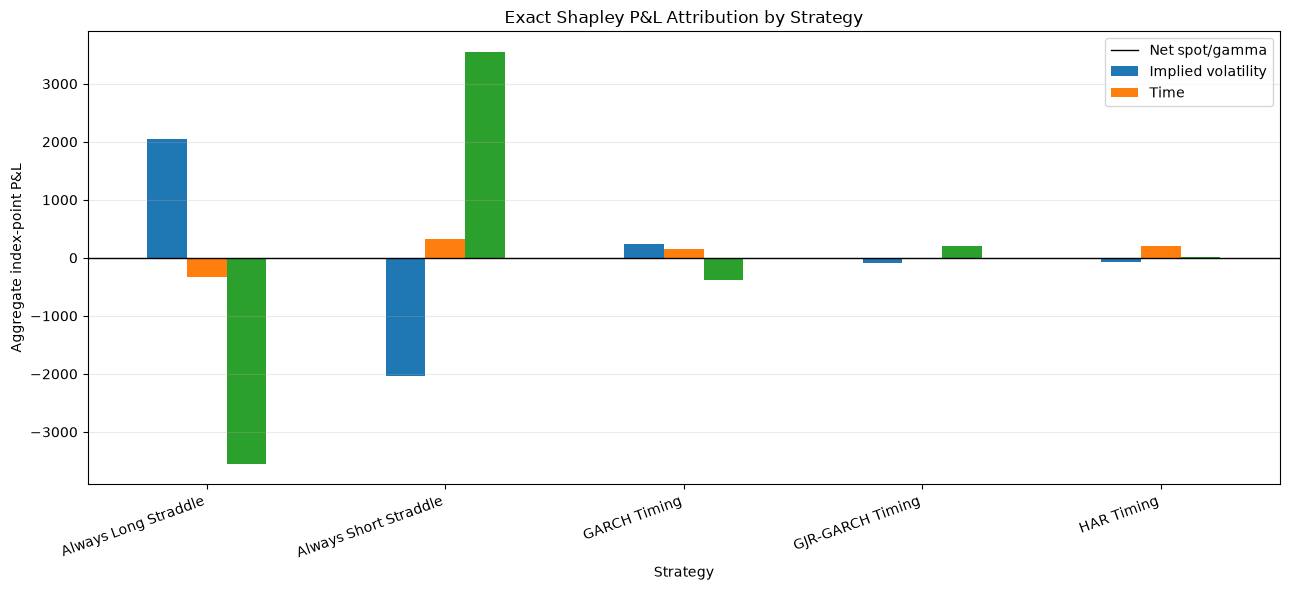

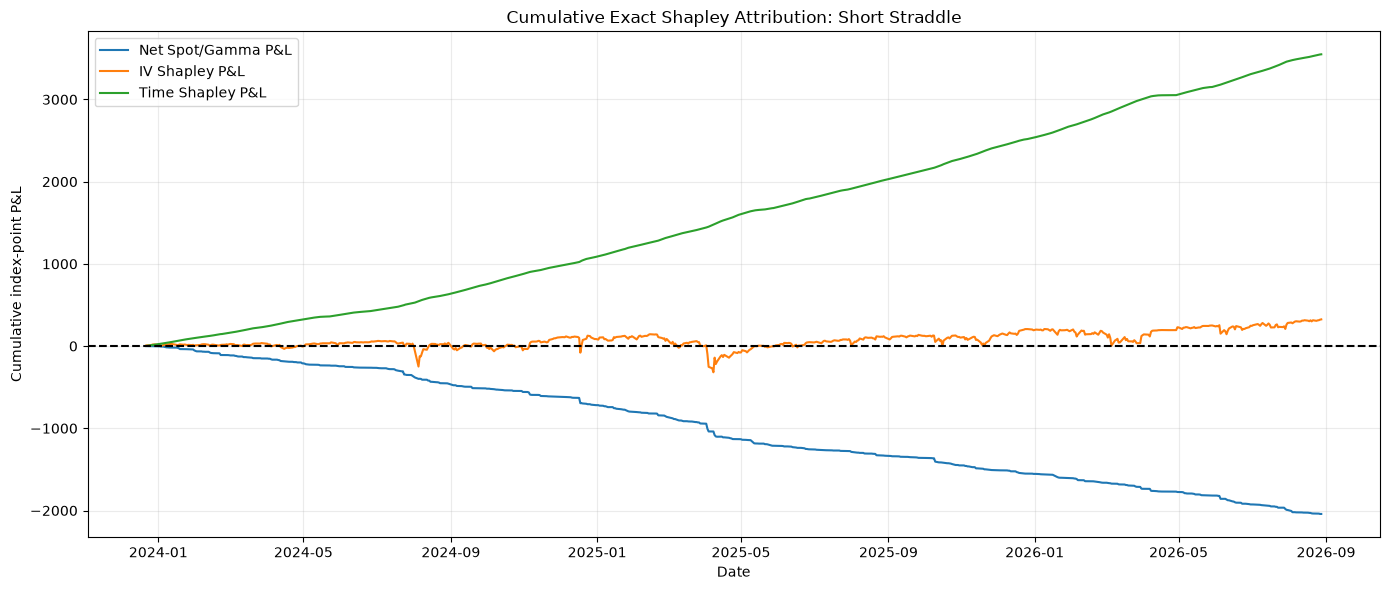


STAGE 24 COMPLETED
Active trades: 104
Daily observations: 2184
Maximum trade reconciliation error: 8.526512829121202e-14
Maximum daily option attribution error: 5.684341886080802e-14

Available variables:
daily_shapley
trade_shapley
shapley_summary
shapley_vs_taylor


In [32]:

# ============================================================
# STAGE 24: EXACT SHAPLEY P&L ATTRIBUTION
# ============================================================

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Dependency checks
# ------------------------------------------------------------

required_variables = [
    "term_data",
    "gamma_trades_v2",
    "bs_price_independent",
    "bs_extended_greeks",
    "maturity_matched_iv",
    "OPTION_TENOR_DAYS",
    "HOLD",
    "trade_attribution_v2"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing variables. Run previous stages first: {missing}"
    )

RF = RISK_FREE_RATE
DIVIDEND = DIVIDEND_YIELD
HEDGE_BPS = HEDGE_COST_BPS

FACTORS = ["Spot", "Volatility", "Time"]

PERMUTATIONS = list(
    itertools.permutations(FACTORS)
)

print("Shapley permutations:", len(PERMUTATIONS))


# ------------------------------------------------------------
# 2. Independent option valuation wrapper
# ------------------------------------------------------------

def shapley_option_price(spot, strike, sigma, maturity):

    return bs_price_independent(
        spot=float(spot),
        strike=float(strike),
        maturity=float(maturity),
        volatility=float(sigma),
        r=RF,
        q=DIVIDEND
    )


# ------------------------------------------------------------
# 3. Calculate exact three-factor Shapley attribution
# ------------------------------------------------------------

def calculate_shapley_attribution(
    initial_state,
    final_state,
    strike
):

    initial = {
        "Spot": float(initial_state["Spot"]),
        "Volatility": float(initial_state["Volatility"]),
        "Time": float(initial_state["Time"])
    }

    final = {
        "Spot": float(final_state["Spot"]),
        "Volatility": float(final_state["Volatility"]),
        "Time": float(final_state["Time"])
    }

    shapley_values = {
        factor: 0.0
        for factor in FACTORS
    }

    for permutation in PERMUTATIONS:

        current = initial.copy()

        previous_value = shapley_option_price(
            current["Spot"],
            strike,
            current["Volatility"],
            current["Time"]
        )

        for factor in permutation:

            current[factor] = final[factor]

            new_value = shapley_option_price(
                current["Spot"],
                strike,
                current["Volatility"],
                current["Time"]
            )

            marginal_contribution = (
                new_value - previous_value
            )

            shapley_values[factor] += (
                marginal_contribution
            )

            previous_value = new_value

    # Average contributions across all six orderings.
    for factor in FACTORS:
        shapley_values[factor] /= len(PERMUTATIONS)

    initial_price = shapley_option_price(
        initial["Spot"],
        strike,
        initial["Volatility"],
        initial["Time"]
    )

    final_price = shapley_option_price(
        final["Spot"],
        strike,
        final["Volatility"],
        final["Time"]
    )

    exact_change = final_price - initial_price

    attributed_change = sum(
        shapley_values.values()
    )

    return {
        "Spot contribution": shapley_values["Spot"],
        "Volatility contribution": shapley_values["Volatility"],
        "Time contribution": shapley_values["Time"],
        "Exact option change": exact_change,
        "Shapley sum": attributed_change,
        "Shapley reconciliation error": (
            exact_change - attributed_change
        )
    }


# ------------------------------------------------------------
# 4. Identify active Stage 20 trades
# ------------------------------------------------------------

active_shapley_trades = gamma_trades_v2[
    gamma_trades_v2["Direction"].isin([-1, 1])
].copy()

print("Active trades:", len(active_shapley_trades))


# ------------------------------------------------------------
# 5. Daily Shapley attribution and hedge accounting
# ------------------------------------------------------------

daily_shapley_records = []
trade_shapley_records = []

for trade_number, trade in active_shapley_trades.iterrows():

    strategy = trade["Strategy"]
    direction = int(trade["Direction"])

    entry_date = pd.Timestamp(trade["Entry date"])

    entry_pos = term_data.index.get_loc(entry_date)

    path = term_data.iloc[
        entry_pos:entry_pos + HOLD + 1
    ].copy()

    if len(path) != HOLD + 1:
        raise ValueError(
            f"Incomplete price path for {entry_date}"
        )

    prices = path["SPX"].to_numpy(dtype=float)

    strike = float(trade["Strike"])

    expiry_date = (
        entry_date
        + pd.Timedelta(days=OPTION_TENOR_DAYS)
    )

    # Build all daily states.
    states = []

    for j, date in enumerate(path.index):

        remaining_days = (
            expiry_date - date
        ).days

        if remaining_days <= 0:
            raise ValueError(
                f"Option expired on {date}"
            )

        row = path.iloc[j]

        sigma = maturity_matched_iv(
            row,
            remaining_days
        )

        T = remaining_days / 365

        states.append({
            "Spot": prices[j],
            "Volatility": sigma,
            "Time": T
        })

    # Initial delta hedge
    initial_greeks = bs_extended_greeks(
        spot=states[0]["Spot"],
        strike=strike,
        time_to_maturity=states[0]["Time"],
        volatility=states[0]["Volatility"],
        risk_free_rate=RF,
        dividend_yield=DIVIDEND
    )

    hedge_position = (
        -direction * initial_greeks["delta"]
    )

    hedge_turnover = (
        abs(hedge_position) * prices[0]
    )

    total_spot_shapley = 0.0
    total_vol_shapley = 0.0
    total_time_shapley = 0.0
    total_hedge_pnl = 0.0

    # --------------------------------------------------------
    # Daily valuation intervals
    # --------------------------------------------------------

    for j in range(HOLD):

        state0 = states[j]
        state1 = states[j + 1]

        shapley = calculate_shapley_attribution(
            initial_state=state0,
            final_state=state1,
            strike=strike
        )

        S0 = prices[j]
        S1 = prices[j + 1]

        dS = S1 - S0

        # Apply long/short option direction.
        spot_pnl = (
            direction * shapley["Spot contribution"]
        )

        volatility_pnl = (
            direction * shapley["Volatility contribution"]
        )

        time_pnl = (
            direction * shapley["Time contribution"]
        )

        # Existing hedge earns the daily SPX move.
        hedge_pnl = hedge_position * dS

        # Rebalance at daily close, except at final exit.
        if j < HOLD - 1:

            next_greeks = bs_extended_greeks(
                spot=state1["Spot"],
                strike=strike,
                time_to_maturity=state1["Time"],
                volatility=state1["Volatility"],
                risk_free_rate=RF,
                dividend_yield=DIVIDEND
            )

            next_hedge = (
                -direction * next_greeks["delta"]
            )

            hedge_turnover += (
                abs(next_hedge - hedge_position) * S1
            )

            hedge_position = next_hedge

        else:

            # Close the hedge at the exit price.
            hedge_turnover += (
                abs(hedge_position) * S1
            )

        total_spot_shapley += spot_pnl
        total_vol_shapley += volatility_pnl
        total_time_shapley += time_pnl
        total_hedge_pnl += hedge_pnl

        # Net the actual hedge against spot attribution.
        net_spot_gamma = spot_pnl + hedge_pnl

        daily_shapley_records.append({
            "Strategy": strategy,
            "Entry date": entry_date,
            "Date": path.index[j + 1],
            "Spot Shapley P&L": spot_pnl,
            "Hedge P&L": hedge_pnl,
            "Net Spot/Gamma P&L": net_spot_gamma,
            "IV Shapley P&L": volatility_pnl,
            "Time Shapley P&L": time_pnl,
            "Option change reconciliation error": (
                shapley["Shapley reconciliation error"]
            )
        })

    # --------------------------------------------------------
    # Trade-level reconciliation
    # --------------------------------------------------------

    hedge_cost = (
        hedge_turnover * HEDGE_BPS / 10000
    )

    option_cost = (
        float(trade["Option cost"])
        if "Option cost" in trade.index
        and pd.notna(trade["Option cost"])
        else 0.0
    )

    net_spot_gamma_pnl = (
        total_spot_shapley + total_hedge_pnl
    )

    gross_pnl = (
        net_spot_gamma_pnl
        + total_vol_shapley
        + total_time_shapley
    )

    net_pnl = (
        gross_pnl - hedge_cost - option_cost
    )

    stage20_net = float(trade["Net P&L"])

    trade_shapley_records.append({
        "Strategy": strategy,
        "Entry date": entry_date,
        "Direction": direction,
        "Spot Shapley P&L": total_spot_shapley,
        "Hedge P&L": total_hedge_pnl,
        "Net Spot/Gamma P&L": net_spot_gamma_pnl,
        "IV Shapley P&L": total_vol_shapley,
        "Time Shapley P&L": total_time_shapley,
        "Gross P&L": gross_pnl,
        "Hedge cost": hedge_cost,
        "Option cost": option_cost,
        "Net P&L": net_pnl,
        "Stage 20 Net P&L": stage20_net,
        "Reconciliation error": net_pnl - stage20_net
    })


# ------------------------------------------------------------
# 6. Store results
# ------------------------------------------------------------

daily_shapley = pd.DataFrame(
    daily_shapley_records
)

trade_shapley = pd.DataFrame(
    trade_shapley_records
)

print("\nDAILY SHAPLEY OBSERVATIONS:", len(daily_shapley))
print("ACTIVE TRADES:", len(trade_shapley))


# ------------------------------------------------------------
# 7. Strategy-level exact attribution
# ------------------------------------------------------------

shapley_summary = (
    trade_shapley
    .groupby("Strategy")
    .agg(
        Trades=("Net P&L", "count"),
        Spot_ShAPLEY_PnL=("Spot Shapley P&L", "sum"),
        Hedge_PnL=("Hedge P&L", "sum"),
        Net_Spot_Gamma_PnL=("Net Spot/Gamma P&L", "sum"),
        IV_ShAPLEY_PnL=("IV Shapley P&L", "sum"),
        Time_ShAPLEY_PnL=("Time Shapley P&L", "sum"),
        Gross_PnL=("Gross P&L", "sum"),
        Hedge_cost=("Hedge cost", "sum"),
        Option_cost=("Option cost", "sum"),
        Net_PnL=("Net P&L", "sum"),
        Mean_reconciliation_error=(
            "Reconciliation error", "mean"
        ),
        Maximum_absolute_reconciliation_error=(
            "Reconciliation error",
            lambda x: np.max(np.abs(x))
        )
    )
)

print("\nEXACT SHAPLEY P&L ATTRIBUTION")

display(shapley_summary.round(8))


# ------------------------------------------------------------
# 8. Compare with original Stage 20 P&L
# ------------------------------------------------------------

max_trade_error = (
    trade_shapley["Reconciliation error"]
    .abs()
    .max()
)

max_daily_error = (
    daily_shapley[
        "Option change reconciliation error"
    ]
    .abs()
    .max()
)

print("\nRECONCILIATION CHECKS")
print("Maximum trade P&L reconciliation error:", max_trade_error)
print("Maximum daily option attribution error:", max_daily_error)

display(
    trade_shapley[
        [
            "Strategy",
            "Entry date",
            "Net P&L",
            "Stage 20 Net P&L",
            "Reconciliation error"
        ]
    ].head(15).round(10)
)


# ------------------------------------------------------------
# 9. Compare exact Shapley attribution with Taylor attribution
# ------------------------------------------------------------

stage22_grouped = (
    trade_attribution_v2
    .groupby("Strategy")
    .sum(numeric_only=True)
)

comparison_rows = []

for strategy in shapley_summary.index:

    exact = shapley_summary.loc[strategy]
    approx = stage22_grouped.loc[strategy]

    comparison_rows.append({
        "Strategy": strategy,

        "Exact net spot/gamma": (
            exact["Net_Spot_Gamma_PnL"]
        ),

        "Taylor gamma approximation": (
            approx["Gamma P&L"]
        ),

        "Exact IV contribution": (
            exact["IV_ShAPLEY_PnL"]
        ),

        "Taylor IV approximation": (
            approx["Vega P&L"]
            + approx["Vanna P&L"]
            + approx["Volga P&L"]
        ),

        "Exact time contribution": (
            exact["Time_ShAPLEY_PnL"]
        ),

        "Taylor theta approximation": (
            approx["Theta P&L"]
        ),

        "Exact net P&L": (
            exact["Net_PnL"]
        )
    })

shapley_vs_taylor = pd.DataFrame(
    comparison_rows
).set_index("Strategy")

print("\nEXACT SHAPLEY VS TAYLOR APPROXIMATION")

display(shapley_vs_taylor.round(6))


# ------------------------------------------------------------
# 10. Plot exact Shapley decomposition
# ------------------------------------------------------------

plot_columns = [
    "Net_Spot_Gamma_PnL",
    "IV_ShAPLEY_PnL",
    "Time_ShAPLEY_PnL"
]

ax = shapley_summary[
    plot_columns
].plot(
    kind="bar",
    figsize=(13, 6)
)

ax.axhline(
    0,
    color="black",
    linewidth=1
)

ax.set_title(
    "Exact Shapley P&L Attribution by Strategy"
)

ax.set_xlabel("Strategy")
ax.set_ylabel("Aggregate index-point P&L")

ax.legend([
    "Net spot/gamma",
    "Implied volatility",
    "Time"
])

ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. Plot cumulative exact attribution:
# Always short straddle
# ------------------------------------------------------------

short_daily = daily_shapley[
    daily_shapley["Strategy"] == "Always Short Straddle"
].copy()

short_daily = (
    short_daily
    .groupby("Date")[
        [
            "Net Spot/Gamma P&L",
            "IV Shapley P&L",
            "Time Shapley P&L"
        ]
    ]
    .sum()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(14, 6))

for column in short_daily.columns:

    ax.plot(
        short_daily.index,
        short_daily[column].cumsum(),
        label=column
    )

ax.axhline(
    0,
    color="black",
    linestyle="--"
)

ax.set_title(
    "Cumulative Exact Shapley Attribution: Short Straddle"
)

ax.set_xlabel("Date")
ax.set_ylabel("Cumulative index-point P&L")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12. Completion
# ------------------------------------------------------------

print("\nSTAGE 24 COMPLETED")

print("Active trades:", len(trade_shapley))
print("Daily observations:", len(daily_shapley))

print("Maximum trade reconciliation error:", max_trade_error)
print("Maximum daily option attribution error:", max_daily_error)

print("\nAvailable variables:")
print("daily_shapley")
print("trade_shapley")
print("shapley_summary")
print("shapley_vs_taylor")


## Stage 25 — Futures-proxy validation
Compare Yahoo `ES=F` with the S&P 500 and inspect basis changes and roll discontinuities.


ES observations: 823
ES first date: 2023-06-12 00:00:00
ES last date: 2026-09-17 00:00:00

ALIGNED DATA SUMMARY
Common observations: 812
SPX observations: 812
ES observations: 823
SPX observations without ES match: 0
Start: 2023-06-22 00:00:00
End: 2026-09-16 00:00:00

FUTURES BASIS SUMMARY


,Value
Observations,811.000000
Mean basis,26.625624
Median basis,25.020020
Basis standard deviation,17.310476
Minimum basis,-90.590332
Maximum basis,88.149902
Mean basis (bps),46.248323
Basis bps standard deviation,30.781834
Mean absolute daily basis change,3.271853



RETURN TRACKING SUMMARY


,Value
Return correlation,0.979640
Mean return difference,-0.000011
Return difference standard deviation,0.001893
Return difference RMSE,0.001892
Return difference MAE,0.000556
Annualised tracking error (%),3.005298



BASIS DISTRIBUTION


,Basis,Basis_bps,Basis_change
count,811.000000,811.000000,811.000000
mean,26.625624,46.248323,-0.045832
std,17.310476,30.781834,11.089086
min,-90.590332,-152.744262,-92.260254
25%,13.720215,22.558405,-2.100098
50%,25.020020,43.861632,-0.810059
75%,39.145020,68.119737,0.510010
max,88.149902,135.480171,152.520508



LOWEST BASIS OBSERVATIONS


,SPX,ES,Basis,Basis_bps
Date,,,,
2024-12-20,5930.8501,5840.2598,-90.5903,-152.7443
2025-03-21,5667.5601,5617.7998,-49.7603,-87.7984
2025-12-19,6834.5000,6796.5400,-37.9600,-55.5417
2023-12-15,4719.1899,4694.2700,-24.9199,-52.8055
2024-03-15,5117.0898,5101.6699,-15.4199,-30.1342
2025-09-19,6664.3599,6658.7700,-5.5898,-8.3877
2024-09-20,5702.5498,5699.9902,-2.5596,-4.4885
2025-03-20,5662.8901,5662.5000,-0.3901,-0.6889
2024-12-18,5872.1602,5872.2500,0.0898,0.1530



HIGHEST BASIS OBSERVATIONS


,SPX,ES,Basis,Basis_bps
Date,,,,
2026-03-20,6506.4800,6594.6299,88.1499,135.4802
2026-06-23,7365.4600,7437.5000,72.0400,97.8079
2026-06-24,7358.2202,7428.2500,70.0298,95.1722
2024-06-24,5447.8701,5517.0000,69.1299,126.8934
2026-06-22,7472.7900,7541.2500,68.4600,91.6123
2024-06-25,5469.2998,5537.0000,67.7002,123.7822
2026-06-25,7357.4902,7423.2500,65.7598,89.3780
2024-06-26,5477.8999,5543.5000,65.6001,119.7541
2024-03-18,5149.4199,5214.7500,65.3301,126.8688


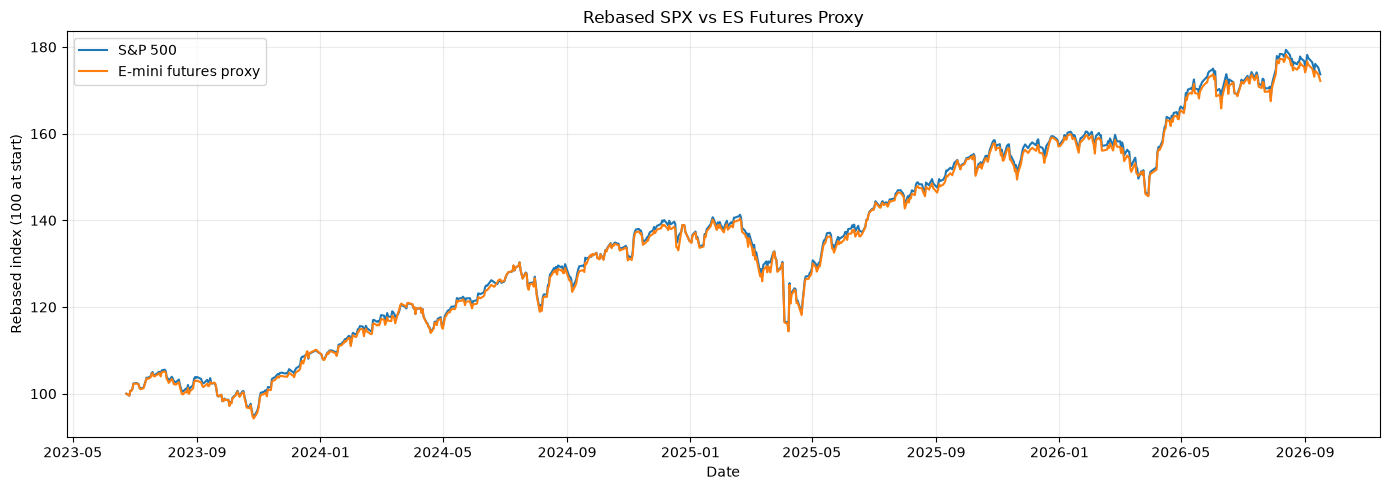

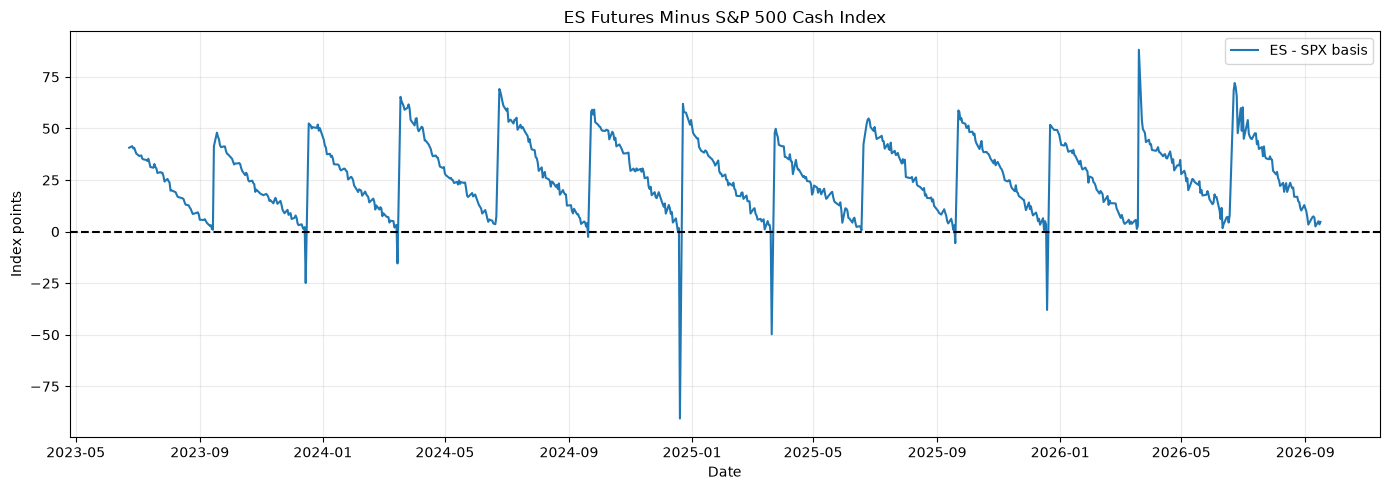

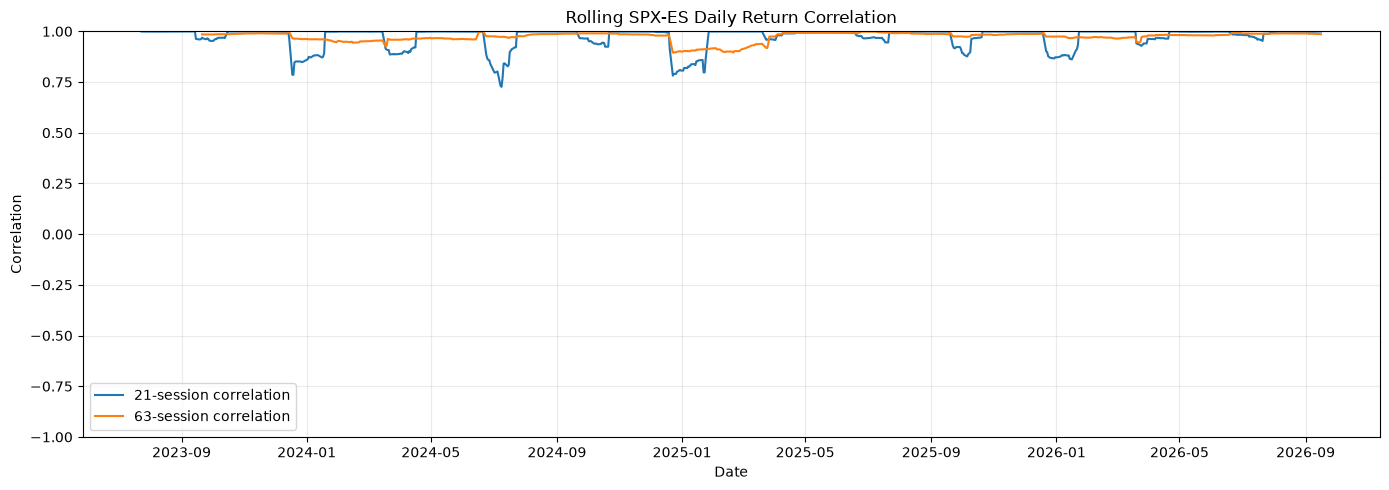


STAGE 25 COMPLETED
Common observations: 811
Return correlation: 0.97964

Available variables:
hedge_data
basis_summary
tracking_summary


In [33]:

# ============================================================
# STAGE 25: ES FUTURES HEDGE DATA VALIDATION
# Yahoo Finance: ES=F vs S&P 500 (^GSPC)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

# ------------------------------------------------------------
# 1. Verify existing data
# ------------------------------------------------------------

if "term_data" not in globals():
    raise RuntimeError(
        "term_data is missing. Run Stage 20 first."
    )

spx_data = term_data["SPX"].copy()

start_date = (
    spx_data.index.min() - pd.Timedelta(days=10)
).strftime("%Y-%m-%d")

end_date = (
    spx_data.index.max() + pd.Timedelta(days=2)
).strftime("%Y-%m-%d")


# ------------------------------------------------------------
# 2. Robust Yahoo Finance downloader
# ------------------------------------------------------------

def download_yahoo_close(ticker, start, end):

    data = yf.Ticker(ticker).history(
        start=start,
        end=end,
        auto_adjust=False,
        actions=False
    )

    if data.empty:

        data = yf.download(
            ticker,
            start=start,
            end=end,
            auto_adjust=False,
            progress=False,
            threads=False
        )

    if data.empty:
        raise RuntimeError(
            f"Yahoo Finance returned no data for {ticker}."
        )

    if isinstance(data.columns, pd.MultiIndex):

        if "Close" in data.columns.get_level_values(0):
            close = data["Close"]

        elif "Close" in data.columns.get_level_values(1):
            close = data.xs(
                "Close", axis=1, level=1
            )

        else:
            raise ValueError(
                f"Close column not found for {ticker}."
            )

        if isinstance(close, pd.DataFrame):
            close = close.iloc[:, 0]

    else:

        if "Close" not in data.columns:
            raise ValueError(
                f"Close column not found for {ticker}."
            )

        close = data["Close"]

    close = close.dropna().astype(float)

    close.index = pd.to_datetime(close.index)

    if close.index.tz is not None:
        close.index = close.index.tz_localize(None)

    return close


# ------------------------------------------------------------
# 3. Download E-mini futures proxy
# ------------------------------------------------------------

print("Downloading ES futures data...")

es_close = download_yahoo_close(
    "ES=F",
    start_date,
    end_date
)

es_close.name = "ES"

print("ES observations:", len(es_close))
print("ES first date:", es_close.index.min())
print("ES last date:", es_close.index.max())


# ------------------------------------------------------------
# 4. Align futures and SPX data
# ------------------------------------------------------------

hedge_data = pd.concat(
    [
        spx_data.rename("SPX"),
        es_close.rename("ES")
    ],
    axis=1,
    join="inner"
).dropna()

hedge_data = hedge_data.sort_index()

if hedge_data.empty:
    raise RuntimeError(
        "No common SPX and ES observations."
    )

print("\nALIGNED DATA SUMMARY")

print("Common observations:", len(hedge_data))
print("SPX observations:", len(spx_data))
print("ES observations:", len(es_close))
print(
    "SPX observations without ES match:",
    len(spx_data) - len(hedge_data)
)

print("Start:", hedge_data.index.min())
print("End:", hedge_data.index.max())


# ------------------------------------------------------------
# 5. Calculate futures basis
# ------------------------------------------------------------

hedge_data["Basis"] = (
    hedge_data["ES"] - hedge_data["SPX"]
)

hedge_data["Basis_bps"] = (
    hedge_data["Basis"]
    / hedge_data["SPX"]
    * 10000
)

hedge_data["Basis_change"] = (
    hedge_data["Basis"].diff()
)

hedge_data["Basis_change_bps"] = (
    hedge_data["Basis_bps"].diff()
)


# ------------------------------------------------------------
# 6. Calculate daily returns
# ------------------------------------------------------------

hedge_data["SPX_return"] = np.log(
    hedge_data["SPX"]
    / hedge_data["SPX"].shift(1)
)

hedge_data["ES_return"] = np.log(
    hedge_data["ES"]
    / hedge_data["ES"].shift(1)
)

hedge_data["Return_difference"] = (
    hedge_data["ES_return"]
    - hedge_data["SPX_return"]
)

hedge_data = hedge_data.dropna()

# Rolling correlations
hedge_data["Rolling_21d_correlation"] = (
    hedge_data["SPX_return"]
    .rolling(21)
    .corr(hedge_data["ES_return"])
)

hedge_data["Rolling_63d_correlation"] = (
    hedge_data["SPX_return"]
    .rolling(63)
    .corr(hedge_data["ES_return"])
)


# ------------------------------------------------------------
# 7. Basis diagnostics
# ------------------------------------------------------------

basis_summary = pd.Series({
    "Observations": len(hedge_data),
    "Mean basis": hedge_data["Basis"].mean(),
    "Median basis": hedge_data["Basis"].median(),
    "Basis standard deviation": hedge_data["Basis"].std(),
    "Minimum basis": hedge_data["Basis"].min(),
    "Maximum basis": hedge_data["Basis"].max(),
    "Mean basis (bps)": hedge_data["Basis_bps"].mean(),
    "Basis bps standard deviation": hedge_data["Basis_bps"].std(),
    "Mean absolute daily basis change": (
        hedge_data["Basis_change"].abs().mean()
    )
})

print("\nFUTURES BASIS SUMMARY")

display(basis_summary.to_frame("Value").round(6))


# ------------------------------------------------------------
# 8. Return tracking diagnostics
# ------------------------------------------------------------

return_correlation = hedge_data[
    ["SPX_return", "ES_return"]
].corr().iloc[0, 1]

return_difference = hedge_data[
    "Return_difference"
].dropna()

tracking_summary = pd.Series({
    "Return correlation": return_correlation,
    "Mean return difference": return_difference.mean(),
    "Return difference standard deviation": (
        return_difference.std()
    ),
    "Return difference RMSE": np.sqrt(
        np.mean(return_difference**2)
    ),
    "Return difference MAE": (
        return_difference.abs().mean()
    ),
    "Annualised tracking error (%)": (
        return_difference.std()
        * np.sqrt(252)
        * 100
    )
})

print("\nRETURN TRACKING SUMMARY")

display(
    tracking_summary.to_frame("Value").round(8)
)


# ------------------------------------------------------------
# 9. Rebased price comparison
# ------------------------------------------------------------

hedge_data["SPX_rebased"] = (
    hedge_data["SPX"]
    / hedge_data["SPX"].iloc[0]
    * 100
)

hedge_data["ES_rebased"] = (
    hedge_data["ES"]
    / hedge_data["ES"].iloc[0]
    * 100
)


# ------------------------------------------------------------
# 10. Distribution diagnostics
# ------------------------------------------------------------

print("\nBASIS DISTRIBUTION")

display(
    hedge_data[
        ["Basis", "Basis_bps", "Basis_change"]
    ].describe().round(6)
)

print("\nLOWEST BASIS OBSERVATIONS")

display(
    hedge_data.nsmallest(10, "Basis")[
        ["SPX", "ES", "Basis", "Basis_bps"]
    ].round(4)
)

print("\nHIGHEST BASIS OBSERVATIONS")

display(
    hedge_data.nlargest(10, "Basis")[
        ["SPX", "ES", "Basis", "Basis_bps"]
    ].round(4)
)


# ------------------------------------------------------------
# 11. Plot rebased prices
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    hedge_data.index,
    hedge_data["SPX_rebased"],
    label="S&P 500"
)

ax.plot(
    hedge_data.index,
    hedge_data["ES_rebased"],
    label="E-mini futures proxy"
)

ax.set_title("Rebased SPX vs ES Futures Proxy")

ax.set_xlabel("Date")
ax.set_ylabel("Rebased index (100 at start)")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12. Plot basis
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    hedge_data.index,
    hedge_data["Basis"],
    label="ES - SPX basis"
)

ax.axhline(
    0,
    color="black",
    linestyle="--"
)

ax.set_title("ES Futures Minus S&P 500 Cash Index")

ax.set_xlabel("Date")
ax.set_ylabel("Index points")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. Plot rolling correlations
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    hedge_data.index,
    hedge_data["Rolling_21d_correlation"],
    label="21-session correlation"
)

ax.plot(
    hedge_data.index,
    hedge_data["Rolling_63d_correlation"],
    label="63-session correlation"
)

ax.set_ylim(-1, 1)

ax.set_title("Rolling SPX-ES Daily Return Correlation")

ax.set_xlabel("Date")
ax.set_ylabel("Correlation")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 14. Completion
# ------------------------------------------------------------

print("\nSTAGE 25 COMPLETED")

print("Common observations:", len(hedge_data))
print("Return correlation:", round(return_correlation, 6))

print("\nAvailable variables:")
print("hedge_data")
print("basis_summary")
print("tracking_summary")


## Stage 26 — Integer-contract futures hedge
Convert theoretical delta exposure into whole ES contracts and measure residual exposure, hedge P&L, and costs.


SPX option multiplier: 100.0
ES futures multiplier: 50.0
ES transaction cost: 1.0 bps

CONTINUOUS FUTURES ROLL DIAGNOSTICS
Median daily basis change: -0.81005859375
Robust basis-change sigma: 1.94229287109375
Roll detection threshold: 15.53834296875
Detected roll days: 19


,SPX,ES,Basis,Basis_change,Roll_adjustment,ES_back_adjusted
Date,,,,,,
2023-09-15,4450.3198,4491.7202,41.4004,40.5005,41.3105,4450.4097
2023-12-15,4719.1899,4694.2700,-24.9199,-27.1201,-26.3101,4679.2695
2023-12-18,4740.5601,4793.0000,52.4399,77.3599,78.1699,4699.8296
2024-03-15,5117.0898,5101.6699,-15.4199,-18.6899,-17.8799,5026.3794
2024-03-18,5149.4199,5214.7500,65.3301,80.7500,81.5601,5057.8994
2024-06-24,5447.8701,5517.0000,69.1299,61.8599,62.6699,5297.4795
2024-09-23,5718.5698,5776.7500,58.1802,60.7397,61.5498,5495.6797
2024-12-20,5930.8501,5840.2598,-90.5903,-92.2603,-91.4502,5650.6396
2024-12-23,5974.0698,6036.0000,61.9302,152.5205,153.3306,5693.0493



RETURN CORRELATION BEFORE AND AFTER ROLL ADJUSTMENT


,SPX_return,Raw_ES_return,Adjusted_ES_return
SPX_return,1.000000,0.979619,0.998864
Raw_ES_return,0.979619,1.000000,0.980006
Adjusted_ES_return,0.998864,0.980006,1.000000



Adjusted ES tracking diagnostics
Annualised adjusted tracking error (%): 1.126065

STAGE 26 DATA ALIGNMENT
Observations: 811
Start: 2023-06-23 00:00:00
End: 2026-09-16 00:00:00

STAGE 26 SIMULATION COMPLETED
Trade records: 160
Hedge-level records: 2288
Scheduled entry dates: 32

INTEGER-CONTRACT ES HEDGE PERFORMANCE


,Scheduled trades,Active trades,Long straddles,Short straddles,Option P&L USD,ES hedge P&L USD,Gross P&L USD,ES transaction costs USD,Option costs USD,Net P&L USD,Mean net P&L per scheduled trade USD,Mean net P&L per active trade USD,Win fraction,Net return on total option premium (%),Mean absolute residual delta USD,Maximum ES contracts
Strategy,,,,,,,,,,,,,,,,
Always Long Straddle,32,32,32,0,-179986.3438,-10625.0488,-190611.3926,4513.4043,0.0,-195124.7969,-6097.6499,-6097.6499,0.1250,-20.5662,13.7829,2
Always Short Straddle,32,32,0,32,179986.3438,10625.0488,190611.3926,4513.4043,0.0,186097.9884,5815.5621,5815.5621,0.8750,19.6148,13.7829,2
GARCH Timing,32,14,8,6,-40784.1168,58099.0479,17314.9311,2088.2206,0.0,15226.7104,475.8347,1087.6222,0.5000,3.5231,14.3404,2
GJR-GARCH Timing,32,14,6,8,-14242.8951,43502.5146,29259.6196,1817.7435,0.0,27441.8760,857.5586,1960.1340,0.5714,6.5341,13.6105,2
HAR Timing,32,12,6,6,-9089.6616,39262.0361,30172.3745,1489.0821,0.0,28683.2924,896.3529,2390.2744,0.5833,8.2637,13.7354,2



ES HEDGE VS THEORETICAL SPX HEDGE


,ES_Net_PnL_USD,Stage20_Theoretical_PnL_USD,Difference_USD
Strategy,,,
Always Long Straddle,-195124.7969,-187889.9548,-7234.8421
Always Short Straddle,186097.9884,178350.1113,7747.8771
GARCH Timing,15226.7104,-1873.9277,17100.6381
GJR-GARCH Timing,27441.8760,8208.6923,19233.1837
HAR Timing,28683.2924,11435.1651,17248.1273



INTEGER HEDGE DIAGNOSTICS


,Value
Hedge observations,2288.0000
Mean absolute ES contracts,0.5664
Maximum absolute ES contracts,2.0000
Fraction of observations with zero contracts,0.5166
Mean absolute residual delta USD,13.8293
Maximum absolute residual delta USD,99.9259
Total roll days in hedge paths,57.0000


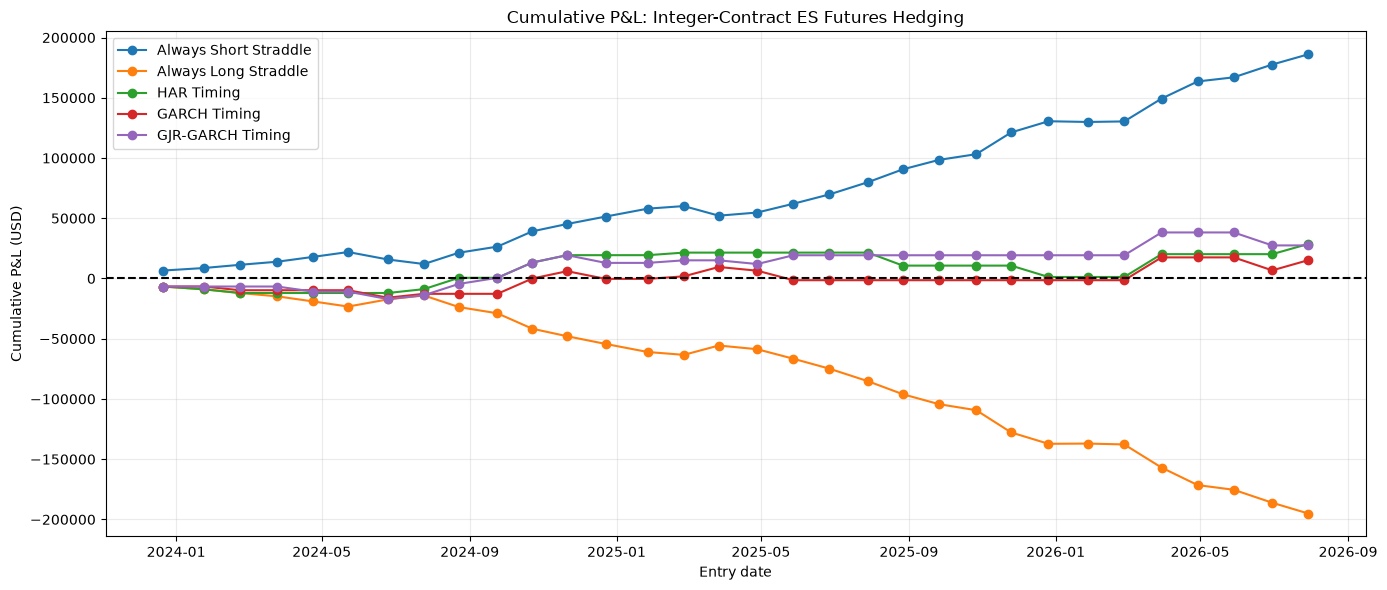

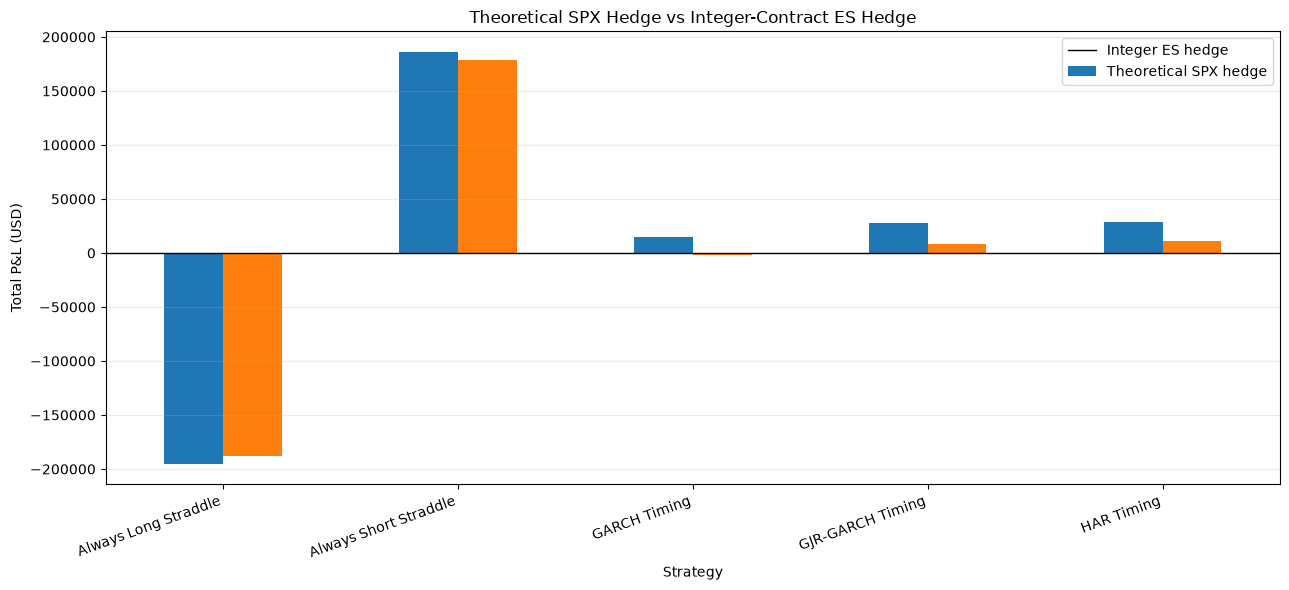


STAGE 26 COMPLETED
SPX option multiplier: 100.0
ES multiplier: 50.0
Hedge costs: 1.0 bps
Option execution costs: 0.0 %
Detected roll days: 19

Available variables:
es_data
stage26_data
es_trade_results
es_hedge_history
es_strategy_summary
comparison
contract_diagnostics


In [34]:

# ============================================================
# STAGE 26: INTEGER-CONTRACT ES FUTURES HEDGING
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SPX_OPTION_MULTIPLIER = 100.0
ES_CONTRACT_MULTIPLIER = 50.0

ES_HEDGE_COST_BPS = 1.0
OPTION_COST_PCT = 0.0

HOLD = 21

print("SPX option multiplier:", SPX_OPTION_MULTIPLIER)
print("ES futures multiplier:", ES_CONTRACT_MULTIPLIER)
print("ES transaction cost:", ES_HEDGE_COST_BPS, "bps")


# ------------------------------------------------------------
# 2. Dependency checks
# ------------------------------------------------------------

required_objects = [
    "term_data",
    "hedge_data",
    "gamma_trades_v2",
    "bs_extended_greeks",
    "maturity_matched_iv",
    "OPTION_TENOR_DAYS",
    "HOLD"
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing objects. Run previous stages first: {missing}"
    )

required_columns = ["SPX", "ES", "Basis"]

missing_columns = [
    c for c in required_columns
    if c not in hedge_data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing hedge data columns: {missing_columns}"
    )


# ------------------------------------------------------------
# 3. Detect continuous futures roll discontinuities
# ------------------------------------------------------------

es_data = hedge_data.copy().sort_index()

es_data["Basis"] = (
    es_data["ES"] - es_data["SPX"]
)

es_data["Basis_change"] = (
    es_data["Basis"].diff()
)

basis_change = es_data["Basis_change"].dropna()

median_basis_change = basis_change.median()

mad = (
    basis_change - median_basis_change
).abs().median()

robust_sigma = 1.4826 * mad

ROLL_THRESHOLD = max(
    10.0,
    8.0 * robust_sigma
)

es_data["Roll_day"] = (
    (
        es_data["Basis_change"]
        - median_basis_change
    ).abs()
    > ROLL_THRESHOLD
)

# Remove only the abnormal basis jump on detected roll days.
es_data["Roll_adjustment"] = 0.0

es_data.loc[
    es_data["Roll_day"],
    "Roll_adjustment"
] = (
    es_data.loc[
        es_data["Roll_day"],
        "Basis_change"
    ] - median_basis_change
)

# Back-adjust the ES continuous series.
es_data["ES_back_adjusted"] = (
    es_data["ES"]
    - es_data["Roll_adjustment"].fillna(0).cumsum()
)

roll_dates = es_data.index[
    es_data["Roll_day"]
]

print("\nCONTINUOUS FUTURES ROLL DIAGNOSTICS")

print("Median daily basis change:", median_basis_change)
print("Robust basis-change sigma:", robust_sigma)
print("Roll detection threshold:", ROLL_THRESHOLD)
print("Detected roll days:", len(roll_dates))

display(
    es_data.loc[
        es_data["Roll_day"],
        [
            "SPX",
            "ES",
            "Basis",
            "Basis_change",
            "Roll_adjustment",
            "ES_back_adjusted"
        ]
    ].round(4)
)


# ------------------------------------------------------------
# 4. Compare raw and adjusted futures returns
# ------------------------------------------------------------

es_data["Raw_ES_return"] = np.log(
    es_data["ES"] / es_data["ES"].shift(1)
)

es_data["Adjusted_ES_return"] = np.log(
    es_data["ES_back_adjusted"]
    / es_data["ES_back_adjusted"].shift(1)
)

es_data["SPX_return"] = np.log(
    es_data["SPX"] / es_data["SPX"].shift(1)
)

return_comparison = es_data[
    [
        "SPX_return",
        "Raw_ES_return",
        "Adjusted_ES_return"
    ]
].dropna()

return_correlation = return_comparison.corr()

print("\nRETURN CORRELATION BEFORE AND AFTER ROLL ADJUSTMENT")

display(return_correlation.round(6))

print("\nAdjusted ES tracking diagnostics")

adjusted_tracking_error = (
    return_comparison["Adjusted_ES_return"]
    - return_comparison["SPX_return"]
).std() * np.sqrt(252) * 100

print(
    "Annualised adjusted tracking error (%):",
    round(adjusted_tracking_error, 6)
)


# ------------------------------------------------------------
# 5. Construct common simulation dataset
# ------------------------------------------------------------

es_columns = [
    "ES",
    "ES_back_adjusted",
    "Roll_day"
]

stage26_data = (
    term_data
    .join(
        es_data[es_columns],
        how="inner"
    )
    .dropna()
    .sort_index()
)

if stage26_data.empty:
    raise RuntimeError(
        "No common observations available for Stage 26."
    )

print("\nSTAGE 26 DATA ALIGNMENT")

print("Observations:", len(stage26_data))
print("Start:", stage26_data.index.min())
print("End:", stage26_data.index.max())


# ------------------------------------------------------------
# 6. Verify corrected Black-Scholes functions
# ------------------------------------------------------------

def get_daily_option_greeks(row, strike, date, expiry):

    remaining_days = (
        expiry - date
    ).days

    if remaining_days <= 0:
        raise ValueError(
            f"Option expired on {date}."
        )

    iv = maturity_matched_iv(
        row,
        remaining_days
    )

    greeks = bs_extended_greeks(
        spot=float(row["SPX"]),
        strike=float(strike),
        time_to_maturity=remaining_days / 365,
        volatility=iv,
        risk_free_rate=RISK_FREE_RATE,
        dividend_yield=DIVIDEND_YIELD
    )

    return greeks, iv


# ------------------------------------------------------------
# 7. Integer-contract ES hedge simulator
# ------------------------------------------------------------

def simulate_es_hedge(
    path,
    direction,
    strategy,
    entry_date,
    es_cost_bps=ES_HEDGE_COST_BPS,
    option_cost_pct=OPTION_COST_PCT
):

    if direction not in [-1, 1]:
        raise ValueError(
            "This function requires an active long or short position."
        )

    if len(path) != HOLD + 1:
        raise ValueError(
            "Path must contain HOLD + 1 observations."
        )

    prices = path["SPX"].to_numpy(dtype=float)

    es_prices = path["ES"].to_numpy(dtype=float)

    adjusted_es = (
        path["ES_back_adjusted"]
        .to_numpy(dtype=float)
    )

    dates = path.index

    strike = prices[0]

    expiry = (
        pd.Timestamp(entry_date)
        + pd.Timedelta(days=OPTION_TENOR_DAYS)
    )

    # --------------------------------------------------------
    # 7A. Calculate daily option values and deltas
    # --------------------------------------------------------

    option_marks = []
    iv_values = []

    for j, date in enumerate(dates):

        greeks, iv = get_daily_option_greeks(
            path.iloc[j],
            strike,
            date,
            expiry
        )

        option_marks.append(greeks)
        iv_values.append(iv)

    # Option P&L in USD for one SPX straddle contract.
    option_pnl_usd = (
        direction
        * (
            option_marks[-1]["price"]
            - option_marks[0]["price"]
        )
        * SPX_OPTION_MULTIPLIER
    )

    entry_premium_usd = (
        option_marks[0]["price"]
        * SPX_OPTION_MULTIPLIER
    )

    option_cost_usd = (
        entry_premium_usd
        * option_cost_pct / 100
    )

    # --------------------------------------------------------
    # 7B. Calculate integer futures hedge
    # --------------------------------------------------------

    def target_es_contracts(delta):

        theoretical_contracts = (
            -direction
            * delta
            * SPX_OPTION_MULTIPLIER
            / ES_CONTRACT_MULTIPLIER
        )

        return int(np.rint(theoretical_contracts))

    # Start with no futures position.
    hedge_contracts = 0

    hedge_pnl_usd = 0.0
    hedge_turnover_usd = 0.0
    hedge_cost_usd = 0.0

    hedge_history = []

    # --------------------------------------------------------
    # 7C. Open initial hedge
    # --------------------------------------------------------

    initial_target = target_es_contracts(
        option_marks[0]["delta"]
    )

    contracts_traded = (
        initial_target - hedge_contracts
    )

    hedge_turnover_usd += (
        abs(contracts_traded)
        * ES_CONTRACT_MULTIPLIER
        * es_prices[0]
    )

    hedge_cost_usd += (
        abs(contracts_traded)
        * ES_CONTRACT_MULTIPLIER
        * es_prices[0]
        * es_cost_bps / 10000
    )

    hedge_contracts = initial_target

    hedge_history.append({
        "Date": dates[0],
        "Target contracts": initial_target,
        "Actual contracts": hedge_contracts,
        "Residual option delta": (
            direction * option_marks[0]["delta"]
            * SPX_OPTION_MULTIPLIER
            + hedge_contracts * ES_CONTRACT_MULTIPLIER
        ),
        "ES price": es_prices[0],
        "Roll day": bool(
            path["Roll_day"].iloc[0]
        )
    })

    # --------------------------------------------------------
    # 7D. Daily futures mark-to-market and rebalancing
    # --------------------------------------------------------

    for j in range(1, HOLD + 1):

        adjusted_futures_change = (
            adjusted_es[j] - adjusted_es[j - 1]
        )

        # Existing contracts earn the daily futures movement.
        daily_hedge_pnl = (
            hedge_contracts
            * ES_CONTRACT_MULTIPLIER
            * adjusted_futures_change
        )

        hedge_pnl_usd += daily_hedge_pnl

        # Target contracts at today's option delta.
        if j < HOLD:

            new_target = target_es_contracts(
                option_marks[j]["delta"]
            )

        else:

            # Close all futures positions at scheduled exit.
            new_target = 0

        contracts_traded = (
            new_target - hedge_contracts
        )

        current_notional = (
            abs(contracts_traded)
            * ES_CONTRACT_MULTIPLIER
            * es_prices[j]
        )

        hedge_turnover_usd += current_notional

        hedge_cost_usd += (
            current_notional
            * es_cost_bps / 10000
        )

        hedge_contracts = new_target

        # Residual delta after rebalancing.
        residual_delta = (
            direction
            * option_marks[j]["delta"]
            * SPX_OPTION_MULTIPLIER
            + hedge_contracts
            * ES_CONTRACT_MULTIPLIER
        )

        hedge_history.append({
            "Date": dates[j],
            "Target contracts": new_target,
            "Actual contracts": hedge_contracts,
            "Residual option delta": residual_delta,
            "ES price": es_prices[j],
            "Roll day": bool(
                path["Roll_day"].iloc[j]
            ),
            "Daily hedge P&L": daily_hedge_pnl,
            "Contracts traded": contracts_traded
        })

    # --------------------------------------------------------
    # 7E. Final P&L
    # --------------------------------------------------------

    gross_pnl_usd = (
        option_pnl_usd + hedge_pnl_usd
    )

    net_pnl_usd = (
        gross_pnl_usd
        - hedge_cost_usd
        - option_cost_usd
    )

    theoretical_target = (
        -direction
        * option_marks[0]["delta"]
        * SPX_OPTION_MULTIPLIER
        / ES_CONTRACT_MULTIPLIER
    )

    return {
        "Strategy": strategy,
        "Entry date": pd.Timestamp(entry_date),
        "Exit date": dates[-1],
        "Direction": direction,
        "Entry SPX": prices[0],
        "Entry ES": es_prices[0],
        "Entry IV": iv_values[0],
        "Option premium USD": entry_premium_usd,
        "Theoretical initial ES contracts": theoretical_target,
        "Initial integer ES contracts": (
            int(np.rint(theoretical_target))
        ),
        "Option P&L USD": option_pnl_usd,
        "ES hedge P&L USD": hedge_pnl_usd,
        "Gross P&L USD": gross_pnl_usd,
        "ES turnover USD": hedge_turnover_usd,
        "ES transaction costs USD": hedge_cost_usd,
        "Option costs USD": option_cost_usd,
        "Net P&L USD": net_pnl_usd,
        "Return on option premium (%)": (
            net_pnl_usd / entry_premium_usd * 100
            if entry_premium_usd > 0 else np.nan
        ),
        "Mean absolute residual delta USD": (
            np.mean([
                abs(x["Residual option delta"])
                for x in hedge_history
            ])
        ),
        "Maximum absolute residual delta USD": (
            np.max([
                abs(x["Residual option delta"])
                for x in hedge_history
            ])
        ),
        "Maximum absolute ES contracts": (
            max(
                abs(x["Actual contracts"])
                for x in hedge_history
            )
        ),
        "Roll days encountered": sum(
            x["Roll day"] for x in hedge_history
        )
    }, hedge_history


# ------------------------------------------------------------
# 8. Run all Stage 20 trades through ES hedging
# ------------------------------------------------------------

es_trade_records = []
es_hedge_records = []

for trade_number, trade in gamma_trades_v2.iterrows():

    strategy = trade["Strategy"]

    direction = int(trade["Direction"])

    entry_date = pd.Timestamp(trade["Entry date"])

    if entry_date not in stage26_data.index:
        raise ValueError(
            f"Entry date {entry_date} is missing from stage26_data."
        )

    entry_pos = stage26_data.index.get_loc(entry_date)

    path = stage26_data.iloc[
        entry_pos:entry_pos + HOLD + 1
    ].copy()

    if len(path) != HOLD + 1:
        raise ValueError(
            f"Incomplete ES path for {entry_date}."
        )

    if direction == 0:

        flat_result = {
            "Strategy": strategy,
            "Entry date": entry_date,
            "Exit date": path.index[-1],
            "Direction": 0,
            "Entry SPX": path["SPX"].iloc[0],
            "Entry ES": path["ES"].iloc[0],
            "Entry IV": np.nan,
            "Option premium USD": 0.0,
            "Theoretical initial ES contracts": 0.0,
            "Initial integer ES contracts": 0,
            "Option P&L USD": 0.0,
            "ES hedge P&L USD": 0.0,
            "Gross P&L USD": 0.0,
            "ES turnover USD": 0.0,
            "ES transaction costs USD": 0.0,
            "Option costs USD": 0.0,
            "Net P&L USD": 0.0,
            "Return on option premium (%)": np.nan,
            "Mean absolute residual delta USD": 0.0,
            "Maximum absolute residual delta USD": 0.0,
            "Maximum absolute ES contracts": 0,
            "Roll days encountered": int(
                path["Roll_day"].sum()
            )
        }

        es_trade_records.append(flat_result)

        continue

    result, hedge_history = simulate_es_hedge(
        path=path,
        direction=direction,
        strategy=strategy,
        entry_date=entry_date
    )

    es_trade_records.append(result)

    for item in hedge_history:

        item["Strategy"] = strategy
        item["Entry date"] = entry_date

        es_hedge_records.append(item)


# ------------------------------------------------------------
# 9. Store trade and hedge-level results
# ------------------------------------------------------------

es_trade_results = pd.DataFrame(
    es_trade_records
)

es_hedge_history = pd.DataFrame(
    es_hedge_records
)

print("\nSTAGE 26 SIMULATION COMPLETED")

print("Trade records:", len(es_trade_results))
print("Hedge-level records:", len(es_hedge_history))

print("Scheduled entry dates:",
      es_trade_results["Entry date"].nunique())


# ------------------------------------------------------------
# 10. Aggregate strategy performance
# ------------------------------------------------------------

es_summary_rows = []

for strategy, group in es_trade_results.groupby("Strategy"):

    active = group[
        group["Direction"].isin([-1, 1])
    ]

    total_option_premium = (
        group["Option premium USD"].sum()
    )

    es_summary_rows.append({
        "Strategy": strategy,
        "Scheduled trades": len(group),
        "Active trades": len(active),
        "Long straddles": (
            group["Direction"] == 1
        ).sum(),
        "Short straddles": (
            group["Direction"] == -1
        ).sum(),
        "Option P&L USD": (
            group["Option P&L USD"].sum()
        ),
        "ES hedge P&L USD": (
            group["ES hedge P&L USD"].sum()
        ),
        "Gross P&L USD": (
            group["Gross P&L USD"].sum()
        ),
        "ES transaction costs USD": (
            group["ES transaction costs USD"].sum()
        ),
        "Option costs USD": (
            group["Option costs USD"].sum()
        ),
        "Net P&L USD": (
            group["Net P&L USD"].sum()
        ),
        "Mean net P&L per scheduled trade USD": (
            group["Net P&L USD"].mean()
        ),
        "Mean net P&L per active trade USD": (
            active["Net P&L USD"].mean()
            if len(active) else np.nan
        ),
        "Win fraction": (
            (active["Net P&L USD"] > 0).mean()
            if len(active) else np.nan
        ),
        "Net return on total option premium (%)": (
            group["Net P&L USD"].sum()
            / total_option_premium * 100
            if total_option_premium > 0 else np.nan
        ),
        "Mean absolute residual delta USD": (
            active["Mean absolute residual delta USD"].mean()
            if len(active) else np.nan
        ),
        "Maximum ES contracts": (
            active["Maximum absolute ES contracts"].max()
            if len(active) else np.nan
        )
    })

es_strategy_summary = (
    pd.DataFrame(es_summary_rows)
    .set_index("Strategy")
)

print("\nINTEGER-CONTRACT ES HEDGE PERFORMANCE")

display(es_strategy_summary.round(4))


# ------------------------------------------------------------
# 11. Compare with theoretical Stage 20 benchmark
# ------------------------------------------------------------

# Stage 20 P&L was in index points.
# Convert it to USD using the $100 SPX multiplier.

es_trade_results["Stage20 theoretical P&L USD"] = (
    gamma_trades_v2["Net P&L"].to_numpy()
    * SPX_OPTION_MULTIPLIER
)

es_trade_results["ES vs theoretical difference USD"] = (
    es_trade_results["Net P&L USD"]
    - es_trade_results["Stage20 theoretical P&L USD"]
)

print("\nES HEDGE VS THEORETICAL SPX HEDGE")

comparison = (
    es_trade_results
    .groupby("Strategy")
    .agg(
        ES_Net_PnL_USD=(
            "Net P&L USD", "sum"
        ),
        Stage20_Theoretical_PnL_USD=(
            "Stage20 theoretical P&L USD", "sum"
        ),
        Difference_USD=(
            "ES vs theoretical difference USD", "sum"
        )
    )
)

display(comparison.round(4))


# ------------------------------------------------------------
# 12. Integer contract diagnostics
# ------------------------------------------------------------

active_es_hedges = es_hedge_history[
    es_hedge_history["Actual contracts"].notna()
].copy()

contract_diagnostics = pd.Series({
    "Hedge observations": len(active_es_hedges),
    "Mean absolute ES contracts": (
        active_es_hedges["Actual contracts"].abs().mean()
    ),
    "Maximum absolute ES contracts": (
        active_es_hedges["Actual contracts"].abs().max()
    ),
    "Fraction of observations with zero contracts": (
        active_es_hedges["Actual contracts"].eq(0).mean()
    ),
    "Mean absolute residual delta USD": (
        active_es_hedges["Residual option delta"].abs().mean()
    ),
    "Maximum absolute residual delta USD": (
        active_es_hedges["Residual option delta"].abs().max()
    ),
    "Total roll days in hedge paths": (
        active_es_hedges["Roll day"].sum()
    )
})

print("\nINTEGER HEDGE DIAGNOSTICS")

display(contract_diagnostics.to_frame("Value").round(4))


# ------------------------------------------------------------
# 13. Plot cumulative ES hedge P&L
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

for strategy in es_trade_results["Strategy"].unique():

    subset = es_trade_results[
        es_trade_results["Strategy"] == strategy
    ].sort_values("Entry date")

    ax.plot(
        subset["Entry date"],
        subset["Net P&L USD"].cumsum(),
        marker="o",
        label=strategy
    )

ax.axhline(0, color="black", linestyle="--")

ax.set_title(
    "Cumulative P&L: Integer-Contract ES Futures Hedging"
)

ax.set_xlabel("Entry date")
ax.set_ylabel("Cumulative P&L (USD)")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 14. Compare theoretical and integer ES hedging
# ------------------------------------------------------------

comparison_plot = comparison[
    [
        "ES_Net_PnL_USD",
        "Stage20_Theoretical_PnL_USD"
    ]
]

ax = comparison_plot.plot(
    kind="bar",
    figsize=(13, 6)
)

ax.axhline(0, color="black", linewidth=1)

ax.set_title(
    "Theoretical SPX Hedge vs Integer-Contract ES Hedge"
)

ax.set_xlabel("Strategy")
ax.set_ylabel("Total P&L (USD)")

ax.legend([
    "Integer ES hedge",
    "Theoretical SPX hedge"
])

ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 15. Completion
# ------------------------------------------------------------

print("\nSTAGE 26 COMPLETED")

print("SPX option multiplier:", SPX_OPTION_MULTIPLIER)
print("ES multiplier:", ES_CONTRACT_MULTIPLIER)
print("Hedge costs:", ES_HEDGE_COST_BPS, "bps")
print("Option execution costs:", OPTION_COST_PCT, "%")
print("Detected roll days:", len(roll_dates))

print("\nAvailable variables:")
print("es_data")
print("stage26_data")
print("es_trade_results")
print("es_hedge_history")
print("es_strategy_summary")
print("comparison")
print("contract_diagnostics")


## Stage 27 — Portfolio risk
Aggregate simulated trade results and evaluate drawdowns, tail losses, and hedge exposure.


Scheduled trade records: 160
Strategies: 5
Holding period: 21
Annualisation factor: 3.4641

TRADE RETURN CHECK


C:\Users\Bhavya\AppData\Local\Temp\ipykernel_5736\2868817348.py:112: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(12).round(4)


,Strategy,Entry date,Direction,Option premium USD,Net P&L USD,Trade_return_pct
0,Always Long Straddle,2023-12-21,1,18777.7706,-6673.5573,-35.5397
1,Always Long Straddle,2024-01-24,1,18297.6669,-2300.4834,-12.5726
2,Always Long Straddle,2024-02-23,1,19871.1403,-3082.2731,-15.5113
3,Always Long Straddle,2024-03-25,1,19812.5022,-2772.1786,-13.9921
4,Always Long Straddle,2024-04-24,1,22711.7265,-4246.2995,-18.6965
5,Always Long Straddle,2024-05-23,1,19284.5508,-4233.9104,-21.9549
6,Always Long Straddle,2024-06-25,1,20172.8461,5975.3350,29.6207
7,Always Long Straddle,2024-07-25,1,27683.0879,3215.7556,11.6163
8,Always Long Straddle,2024-08-23,1,25605.8016,-9616.1624,-37.5546
9,Always Long Straddle,2024-09-24,1,25606.4545,-5177.0433,-20.2177



PORTFOLIO TRADE-LEVEL RISK SUMMARY


,Scheduled trades,Active trades,Total net P&L USD,Mean P&L per scheduled trade USD,Mean P&L per active trade USD,Median active trade P&L USD,Best trade USD,Worst trade USD,Active win fraction,Profit factor,Trade return standard deviation,Annualised Sharpe proxy,Annualised Sortino proxy,Historical P&L VaR 95% USD,Historical P&L CVaR 95% USD,Premium return VaR 95%,Premium return CVaR 95%,Total ES transaction costs USD
Strategy,,,,,,,,,,,,,,,,,,
Always Long Straddle,32,32,-195124.796880,-6097.649902,-6097.649902,-6320.532575,7753.294554,-19212.693329,0.125000,0.080708,0.183791,-3.708801,-2.649723,-16303.104844,-18834.328022,-0.396765,-0.463459,4513.404250
Always Short Straddle,32,32,186097.988379,5815.562137,5815.562137,6140.982575,18934.993329,-7968.147054,0.875000,11.040827,0.185121,3.500518,8.539770,-4862.055716,-7082.874797,-0.194797,-0.286845,4513.404250
GARCH Timing,32,14,15226.710428,475.834701,1087.622173,-474.193297,18934.993329,-10770.318176,0.500000,1.345269,0.173389,-0.009393,-0.013681,-8900.119780,-10770.318176,-0.324085,-0.355397,2088.220649
GJR-GARCH Timing,32,14,27441.876030,857.558626,1960.134002,2674.259097,18934.993329,-10770.318176,0.571429,1.734291,0.177639,0.300541,0.474553,-8107.423638,-10770.318176,-0.324085,-0.355397,1817.743550
HAR Timing,32,12,28683.292389,896.352887,2390.274366,2674.259097,18934.993329,-10794.704546,0.583333,1.888537,0.176738,0.247831,0.378871,-10044.369214,-10794.704546,-0.369028,-0.385689,1489.082100



EXIT-DATE-BASED DRAWDOWN SUMMARY


... (4 outputs left out)


INTEGER HEDGE ROUNDING VALIDATION


,Maximum absolute residual delta USD,Residual delta within rounding bound
Strategy,,
Always Long Straddle,24.928767,True
Always Short Straddle,24.928767,True
GARCH Timing,24.928767,True
GJR-GARCH Timing,24.629075,True
HAR Timing,24.928767,True



PREMIUM-NORMALISED STRATEGY RETURN CORRELATION


Strategy,Always Long Straddle,Always Short Straddle,GARCH Timing,GJR-GARCH Timing,HAR Timing
Strategy,,,,,
Always Long Straddle,1.0000,-0.9997,-0.0604,-0.2473,-0.0223
Always Short Straddle,-0.9997,1.0000,0.0651,0.2459,0.0227
GARCH Timing,-0.0604,0.0651,1.0000,0.7039,0.5914
GJR-GARCH Timing,-0.2473,0.2459,0.7039,1.0000,0.6280
HAR Timing,-0.0223,0.0227,0.5914,0.6280,1.0000


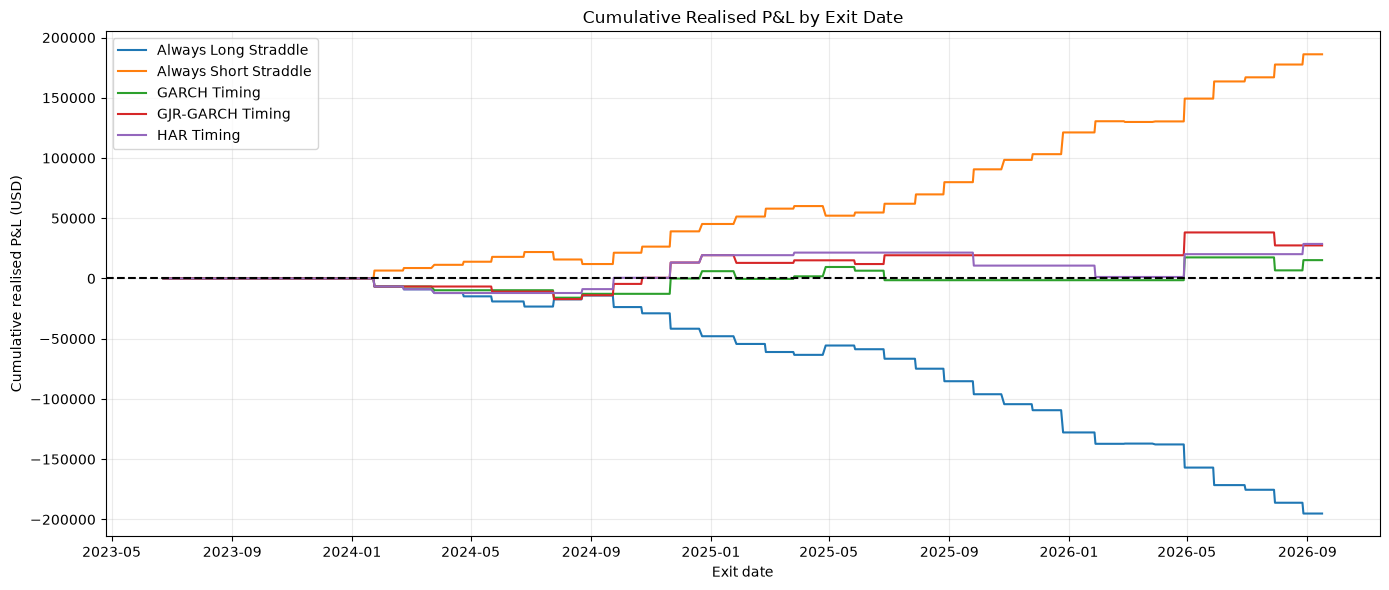

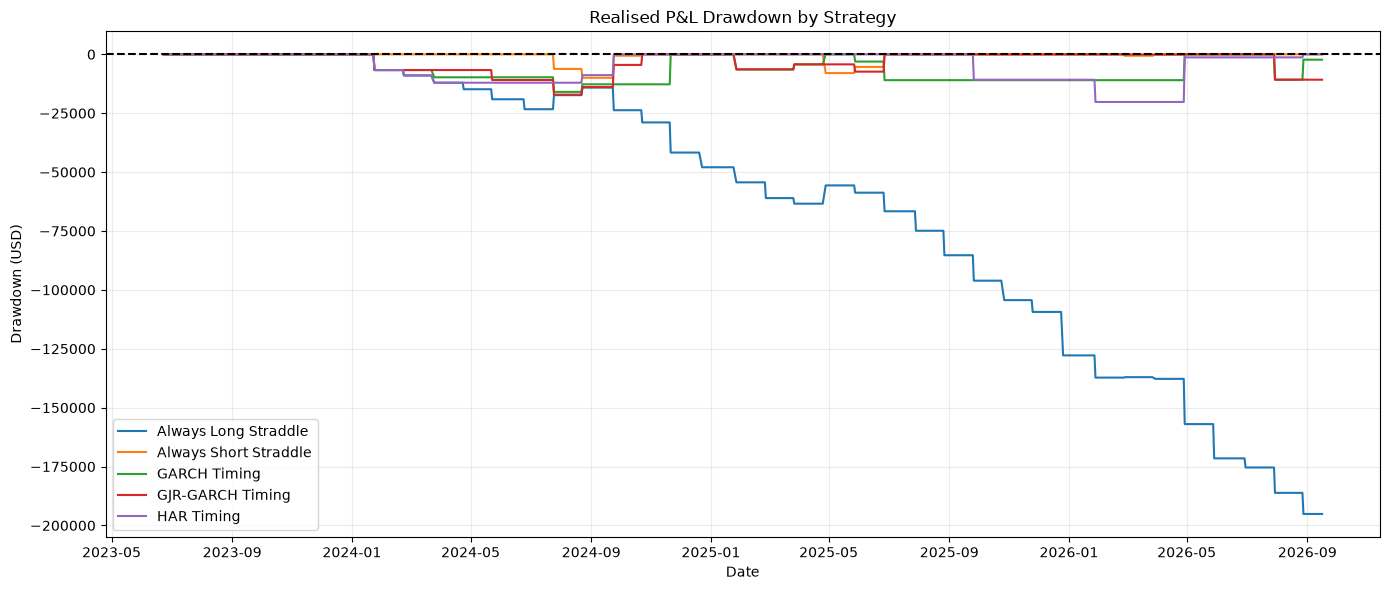

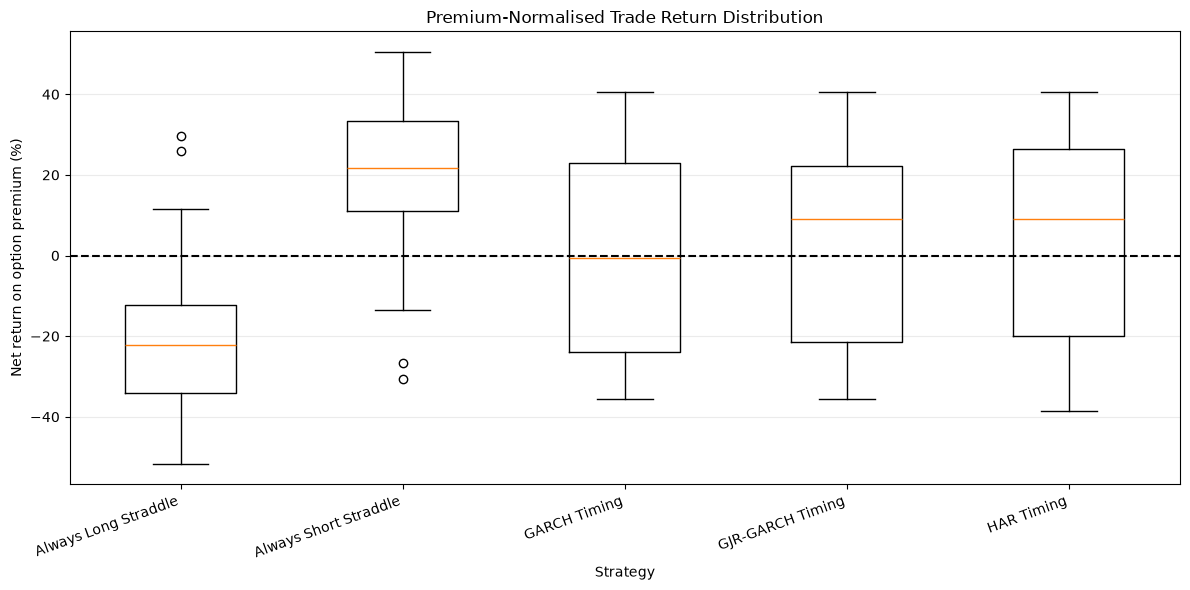


FINAL CONSISTENCY CHECKS
Maximum strategy P&L aggregation difference: 2.9103830456733704e-11
Maximum drawdown-summary P&L difference: 0.0
Maximum corrected live residual delta USD: 24.928767220615853

STAGE 27 COMPLETED
Strategies evaluated: 5
Scheduled trades: 160
Active trades: 104
Exposure observations after excluding exits: 2184

Available variables:
trades27
portfolio_risk_summary
portfolio_drawdown_summary
portfolio_exposure_summary
daily_realised_pnl
cumulative_pnl
drawdown_data
monthly_return_correlation
live_exposure


In [35]:

# ============================================================
# STAGE 27: PORTFOLIO PERFORMANCE AND RISK ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# ------------------------------------------------------------
# 1. Dependency checks
# ------------------------------------------------------------

required_variables = [
    "es_trade_results",
    "es_hedge_history",
    "stage26_data",
    "HOLD"
]

missing = [
    x for x in required_variables
    if x not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing Stage 26 variables: {missing}"
    )

required_columns = [
    "Strategy",
    "Entry date",
    "Exit date",
    "Direction",
    "Option premium USD",
    "Net P&L USD",
    "ES transaction costs USD",
    "Maximum absolute ES contracts"
]

missing_columns = [
    c for c in required_columns
    if c not in es_trade_results.columns
]

if missing_columns:
    raise ValueError(
        f"Missing trade-result columns: {missing_columns}"
    )

trades27 = es_trade_results.copy()

trades27["Entry date"] = pd.to_datetime(
    trades27["Entry date"]
)

trades27["Exit date"] = pd.to_datetime(
    trades27["Exit date"]
)

trades27 = trades27.sort_values(
    ["Strategy", "Entry date"]
).reset_index(drop=True)

# Approximate number of non-overlapping 21-session
# holding periods in a 252-session trading year.
ANNUALISATION_FACTOR = np.sqrt(252 / HOLD)

print("Scheduled trade records:", len(trades27))
print("Strategies:", trades27["Strategy"].nunique())
print("Holding period:", HOLD)
print("Annualisation factor:", round(ANNUALISATION_FACTOR, 4))


# ------------------------------------------------------------
# 2. Construct premium-normalised trade returns
# ------------------------------------------------------------

active_mask = (
    trades27["Direction"].isin([-1, 1])
    & (trades27["Option premium USD"] > 0)
)

trades27["Premium_normalised_return"] = 0.0

trades27.loc[
    active_mask,
    "Premium_normalised_return"
] = (
    trades27.loc[active_mask, "Net P&L USD"]
    / trades27.loc[active_mask, "Option premium USD"]
)

trades27["Trade_return_pct"] = (
    trades27["Premium_normalised_return"] * 100
)

print("\nTRADE RETURN CHECK")

display(
    trades27[
        [
            "Strategy",
            "Entry date",
            "Direction",
            "Option premium USD",
            "Net P&L USD",
            "Trade_return_pct"
        ]
    ].head(12).round(4)
)


# ------------------------------------------------------------
# 3. Trade-level risk metrics
# ------------------------------------------------------------

risk_rows = []

for strategy, group in trades27.groupby("Strategy"):

    group = group.sort_values("Entry date")

    returns = group[
        "Premium_normalised_return"
    ].to_numpy(dtype=float)

    pnl = group["Net P&L USD"].to_numpy(dtype=float)

    active_group = group[
        group["Direction"].isin([-1, 1])
    ]

    active_pnl = active_group[
        "Net P&L USD"
    ].to_numpy(dtype=float)

    active_returns = active_group[
        "Premium_normalised_return"
    ].to_numpy(dtype=float)

    # --------------------------------------------------------
    # Profit factor
    # --------------------------------------------------------

    positive_pnl = pnl[pnl > 0]
    negative_pnl = pnl[pnl < 0]

    total_wins = positive_pnl.sum()
    total_losses = abs(negative_pnl.sum())

    profit_factor = (
        total_wins / total_losses
        if total_losses > 0
        else np.inf
    )

    # --------------------------------------------------------
    # Sharpe proxy
    # --------------------------------------------------------

    return_std = (
        np.std(returns, ddof=1)
        if len(returns) > 1
        else np.nan
    )

    sharpe_proxy = (
        np.mean(returns)
        / return_std
        * ANNUALISATION_FACTOR
        if return_std > 0
        else np.nan
    )

    # --------------------------------------------------------
    # Sortino proxy
    # --------------------------------------------------------

    downside_returns = np.minimum(
        returns, 0
    )

    downside_deviation = np.sqrt(
        np.mean(downside_returns**2)
    )

    sortino_proxy = (
        np.mean(returns)
        / downside_deviation
        * ANNUALISATION_FACTOR
        if downside_deviation > 0
        else np.nan
    )

    # --------------------------------------------------------
    # Historical tail-risk metrics
    # --------------------------------------------------------

    if len(active_pnl) > 0:

        pnl_var_95 = np.quantile(
            active_pnl, 0.05
        )

        pnl_cvar_95 = active_pnl[
            active_pnl <= pnl_var_95
        ].mean()

        return_var_95 = np.quantile(
            active_returns, 0.05
        )

        return_cvar_95 = active_returns[
            active_returns <= return_var_95
        ].mean()

        active_win_fraction = (
            active_pnl > 0
        ).mean()

    else:

        pnl_var_95 = np.nan
        pnl_cvar_95 = np.nan
        return_var_95 = np.nan
        return_cvar_95 = np.nan
        active_win_fraction = np.nan

    risk_rows.append({

        "Strategy": strategy,

        "Scheduled trades": len(group),

        "Active trades": len(active_group),

        "Total net P&L USD": pnl.sum(),

        "Mean P&L per scheduled trade USD": pnl.mean(),

        "Mean P&L per active trade USD": (
            active_pnl.mean()
            if len(active_pnl) else np.nan
        ),

        "Median active trade P&L USD": (
            np.median(active_pnl)
            if len(active_pnl) else np.nan
        ),

        "Best trade USD": (
            np.max(active_pnl)
            if len(active_pnl) else np.nan
        ),

        "Worst trade USD": (
            np.min(active_pnl)
            if len(active_pnl) else np.nan
        ),

        "Active win fraction": active_win_fraction,

        "Profit factor": profit_factor,

        "Trade return standard deviation": return_std,

        "Annualised Sharpe proxy": sharpe_proxy,

        "Annualised Sortino proxy": sortino_proxy,

        "Historical P&L VaR 95% USD": pnl_var_95,

        "Historical P&L CVaR 95% USD": pnl_cvar_95,

        "Premium return VaR 95%": return_var_95,

        "Premium return CVaR 95%": return_cvar_95,

        "Total ES transaction costs USD": (
            group["ES transaction costs USD"].sum()
        )
    })

portfolio_risk_summary = (
    pd.DataFrame(risk_rows)
    .set_index("Strategy")
)

print("\nPORTFOLIO TRADE-LEVEL RISK SUMMARY")

display(
    portfolio_risk_summary.round(6)
)


# ------------------------------------------------------------
# 4. Construct realised P&L using exit dates
# ------------------------------------------------------------

portfolio_index = pd.DatetimeIndex(
    stage26_data.index
).sort_values().unique()

daily_realised_pnl = pd.DataFrame(
    index=portfolio_index
)

cumulative_pnl = pd.DataFrame(
    index=portfolio_index
)

drawdown_data = pd.DataFrame(
    index=portfolio_index
)

drawdown_summary_rows = []

for strategy, group in trades27.groupby("Strategy"):

    exit_cashflows = (
        group.groupby("Exit date")["Net P&L USD"]
        .sum()
    )

    daily_cashflows = (
        exit_cashflows
        .reindex(portfolio_index)
        .fillna(0.0)
    )

    cumulative = daily_cashflows.cumsum()

    # Start with zero initial realised P&L.
    running_peak = cumulative.cummax().clip(lower=0)

    drawdown = cumulative - running_peak

    daily_realised_pnl[strategy] = daily_cashflows

    cumulative_pnl[strategy] = cumulative

    drawdown_data[strategy] = drawdown

    # Longest consecutive trading-session drawdown.
    underwater = drawdown < -1e-10

    run_id = underwater.ne(
        underwater.shift(fill_value=False)
    ).cumsum()

    underwater_lengths = (
        underwater[underwater]
        .groupby(run_id[underwater])
        .size()
    )

    longest_drawdown_sessions = (
        int(underwater_lengths.max())
        if len(underwater_lengths)
        else 0
    )

    drawdown_summary_rows.append({

        "Strategy": strategy,

        "Final realised P&L USD": cumulative.iloc[-1],

        "Maximum drawdown USD": drawdown.min(),

        "Date of maximum drawdown": (
            drawdown.idxmin()
        ),

        "Longest drawdown duration (sessions)": (
            longest_drawdown_sessions
        ),

        "Winning exit fraction": (
            (group["Net P&L USD"] > 0).mean()
        )
    })


# ------------------------------------------------------------
# 5. Drawdown summary
# ------------------------------------------------------------

portfolio_drawdown_summary = (
    pd.DataFrame(drawdown_summary_rows)
    .set_index("Strategy")
)

print("\nEXIT-DATE-BASED DRAWDOWN SUMMARY")

display(
    portfolio_drawdown_summary.round(4)
)


# ------------------------------------------------------------
# 6. Correct ES exposure diagnostics
# Exclude the exit date, when both option and hedge
# positions have been closed.
# ------------------------------------------------------------

history27 = es_hedge_history.copy()

history27["Date"] = pd.to_datetime(
    history27["Date"]
)

history27["Entry date"] = pd.to_datetime(
    history27["Entry date"]
)

trade_dates = trades27[
    [
        "Strategy",
        "Entry date",
        "Exit date"
    ]
].drop_duplicates()

history27 = history27.merge(
    trade_dates,
    on=["Strategy", "Entry date"],
    how="left",
    validate="many_to_one"
)

if history27["Exit date"].isna().any():
    raise RuntimeError(
        "Some hedge records could not be matched to their trades."
    )

# Keep only observations where the option is still open.
live_exposure = history27[
    history27["Date"] < history27["Exit date"]
].copy()

live_exposure["Abs_ES_contracts"] = (
    live_exposure["Actual contracts"].abs()
)

live_exposure["Abs_residual_delta_USD"] = (
    live_exposure["Residual option delta"].abs()
)

exposure_rows = []

for strategy, group in live_exposure.groupby("Strategy"):

    exposure_rows.append({

        "Strategy": strategy,

        "Live hedge observations": len(group),

        "Mean absolute ES contracts": (
            group["Abs_ES_contracts"].mean()
        ),

        "Maximum absolute ES contracts": (
            group["Abs_ES_contracts"].max()
        ),

        "Zero-contract fraction": (
            group["Actual contracts"].eq(0).mean()
        ),

        "Mean absolute residual delta USD": (
            group["Abs_residual_delta_USD"].mean()
        ),

        "Maximum absolute residual delta USD": (
            group["Abs_residual_delta_USD"].max()
        ),

        "Roll observations while open": (
            group["Roll day"].sum()
        ),

        "Mean contracts traded": (
            group["Contracts traded"].abs().mean()
            if "Contracts traded" in group.columns
            else np.nan
        )
    })

portfolio_exposure_summary = (
    pd.DataFrame(exposure_rows)
    .set_index("Strategy")
)

print("\nCORRECTED LIVE EXPOSURE SUMMARY")

display(
    portfolio_exposure_summary.round(6)
)


# ------------------------------------------------------------
# 7. Check integer hedge rounding
# ------------------------------------------------------------

EXPECTED_MAX_RESIDUAL = (
    ES_CONTRACT_MULTIPLIER / 2
)

portfolio_exposure_summary[
    "Residual delta within rounding bound"
] = (
    portfolio_exposure_summary[
        "Maximum absolute residual delta USD"
    ]
    <= EXPECTED_MAX_RESIDUAL + 1e-6
)

print("\nINTEGER HEDGE ROUNDING VALIDATION")

display(
    portfolio_exposure_summary[
        [
            "Maximum absolute residual delta USD",
            "Residual delta within rounding bound"
        ]
    ].round(6)
)


# ------------------------------------------------------------
# 8. Premium-normalised monthly return correlation
# ------------------------------------------------------------

monthly_trades = trades27.copy()

monthly_trades["Month"] = (
    monthly_trades["Entry date"].dt.to_period("M")
)

monthly_return_matrix = (
    monthly_trades
    .pivot_table(
        index="Month",
        columns="Strategy",
        values="Premium_normalised_return",
        aggfunc="mean"
    )
    .fillna(0.0)
)

monthly_return_correlation = (
    monthly_return_matrix.corr()
)

print("\nPREMIUM-NORMALISED STRATEGY RETURN CORRELATION")

display(
    monthly_return_correlation.round(4)
)


# ------------------------------------------------------------
# 9. Plot cumulative realised P&L
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

for strategy in cumulative_pnl.columns:

    ax.plot(
        cumulative_pnl.index,
        cumulative_pnl[strategy],
        label=strategy
    )

ax.axhline(
    0,
    color="black",
    linestyle="--"
)

ax.set_title(
    "Cumulative Realised P&L by Exit Date"
)

ax.set_xlabel("Exit date")
ax.set_ylabel("Cumulative realised P&L (USD)")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Plot drawdowns
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

for strategy in drawdown_data.columns:

    ax.plot(
        drawdown_data.index,
        drawdown_data[strategy],
        label=strategy
    )

ax.axhline(
    0,
    color="black",
    linestyle="--"
)

ax.set_title(
    "Realised P&L Drawdown by Strategy"
)

ax.set_xlabel("Date")
ax.set_ylabel("Drawdown (USD)")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. Plot premium-normalised trade return distributions
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

return_data = []

return_labels = []

for strategy in trades27["Strategy"].unique():

    group = trades27[
        (trades27["Strategy"] == strategy)
        & trades27["Direction"].isin([-1, 1])
    ]

    if len(group):

        return_data.append(
            group["Trade_return_pct"].dropna().to_numpy()
        )

        return_labels.append(strategy)

ax.boxplot(
    return_data,
    tick_labels=return_labels,
    showfliers=True
)

ax.axhline(
    0,
    color="black",
    linestyle="--"
)

ax.set_title(
    "Premium-Normalised Trade Return Distribution"
)

ax.set_xlabel("Strategy")
ax.set_ylabel("Net return on option premium (%)")

plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12. Final consistency checks
# ------------------------------------------------------------

pnl_difference = (
    trades27.groupby("Strategy")["Net P&L USD"].sum()
    - portfolio_risk_summary["Total net P&L USD"]
)

drawdown_difference = (
    cumulative_pnl.iloc[-1]
    - portfolio_drawdown_summary["Final realised P&L USD"]
)

print("\nFINAL CONSISTENCY CHECKS")

print(
    "Maximum strategy P&L aggregation difference:",
    pnl_difference.abs().max()
)

print(
    "Maximum drawdown-summary P&L difference:",
    drawdown_difference.abs().max()
)

print(
    "Maximum corrected live residual delta USD:",
    portfolio_exposure_summary[
        "Maximum absolute residual delta USD"
    ].max()
)


# ------------------------------------------------------------
# 13. Completion
# ------------------------------------------------------------

print("\nSTAGE 27 COMPLETED")

print("Strategies evaluated:", len(portfolio_risk_summary))

print("Scheduled trades:", len(trades27))

print("Active trades:", int(active_mask.sum()))

print(
    "Exposure observations after excluding exits:",
    len(live_exposure)
)

print("\nAvailable variables:")

print("trades27")
print("portfolio_risk_summary")
print("portfolio_drawdown_summary")
print("portfolio_exposure_summary")
print("daily_realised_pnl")
print("cumulative_pnl")
print("drawdown_data")
print("monthly_return_correlation")
print("live_exposure")


## Stage 28 — Final causal-roll audit
Detect futures-roll jumps using only prior observations, rerun the hedge, test cost sensitivity, bootstrap active-trade P&L, and validate accounting identities.


STAGE 28 CONFIGURATION
Scheduled records: 160
Holding period: 21
Baseline ES cost (bps): 1.0
Baseline option cost (% of entry premium): 0.0

CAUSAL ROLL DIAGNOSTICS
Detected causal roll days: 17
First detected roll: 2023-12-15 00:00:00
Last detected roll: 2026-06-22 00:00:00


,SPX,ES,Basis,Basis_change,Historical_basis_change_median,Roll_threshold_causal,Roll_adjustment_causal,ES_back_adjusted_causal
Date,,,,,,,,
2023-12-15,4719.1899,4694.2700,-24.9199,-27.1201,-0.6602,10.0000,-26.4600,4720.7300
2023-12-18,4740.5601,4793.0000,52.4399,77.3599,-0.6602,10.0000,78.0200,4741.4399
2024-03-15,5117.0898,5101.6699,-15.4199,-18.6899,-0.6150,11.8029,-18.0750,5068.1848
2024-03-18,5149.4199,5214.7500,65.3301,80.7500,-0.6350,12.2778,81.3850,5099.8799
2024-06-24,5447.8701,5517.0000,69.1299,61.8599,-0.7600,13.5808,62.6199,5339.5100
2024-09-23,5718.5698,5776.7500,58.1802,60.7397,-0.9597,15.2401,61.6995,5537.5605
2024-12-20,5930.8501,5840.2598,-90.5903,-92.2603,-0.9248,20.8143,-91.3354,5692.4058
2024-12-23,5974.0698,6036.0000,61.9302,152.5205,-0.9548,20.6406,153.4753,5734.6707
2025-03-21,5667.5601,5617.7998,-49.7603,-49.3701,-0.9250,18.2053,-48.4451,5364.9155



RAW VS CAUSAL-ADJUSTED TRACKING


,Correlation with SPX,Annualised tracking error (%),Return difference RMSE
Series,,,
Raw_ES_return,0.979289,3.039795,0.001914
Causal_ES_return,0.998207,1.168642,0.000744



CAUSAL ES SIMULATION
Trade records: 160
Active trades: 104
Hedge observations: 2288
Evaluation start: 2023-06-23 00:00:00
Evaluation end: 2026-09-16 00:00:00

CAUSAL-ROLL STRATEGY PERFORMANCE


C:\Users\Bhavya\AppData\Local\Temp\ipykernel_5736\4011789969.py:356: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(stage28_strategy_summary.round(5))


... (7 outputs left out)


CAUSAL-ROLL LIVE EXPOSURE AUDIT


,Live hedge observations,Mean absolute ES contracts,Maximum absolute ES contracts,Zero-contract fraction,Mean absolute residual delta USD,Maximum absolute residual delta USD,Roll observations while open,Within half-contract rounding bound
Strategy,,,,,,,,
Always Long Straddle,672,0.57143,2,0.50595,11.54614,24.92877,15,True
Always Short Straddle,672,0.57143,2,0.50595,11.54614,24.92877,15,True
GARCH Timing,294,0.66327,2,0.44558,12.09081,24.92877,7,True
GJR-GARCH Timing,294,0.60544,2,0.50340,11.45568,24.62907,6,True
HAR Timing,252,0.61508,2,0.47222,11.20518,24.92877,7,True



AUTOMATED VALIDATION CHECKS


,Result,Passed
Check,,
No duplicate strategy-entry records,0.000000e+00,True
All exits match the configured holding horizon,0.000000e+00,True
Gross P&L reconciles to option plus ES hedge P&L,0.000000e+00,True
Net P&L reconciles after all modelled costs,1.449507e-12,True
All ES hedge positions are integer contracts,0.000000e+00,True
Live residual delta respects integer-rounding bound,2.492877e+01,True


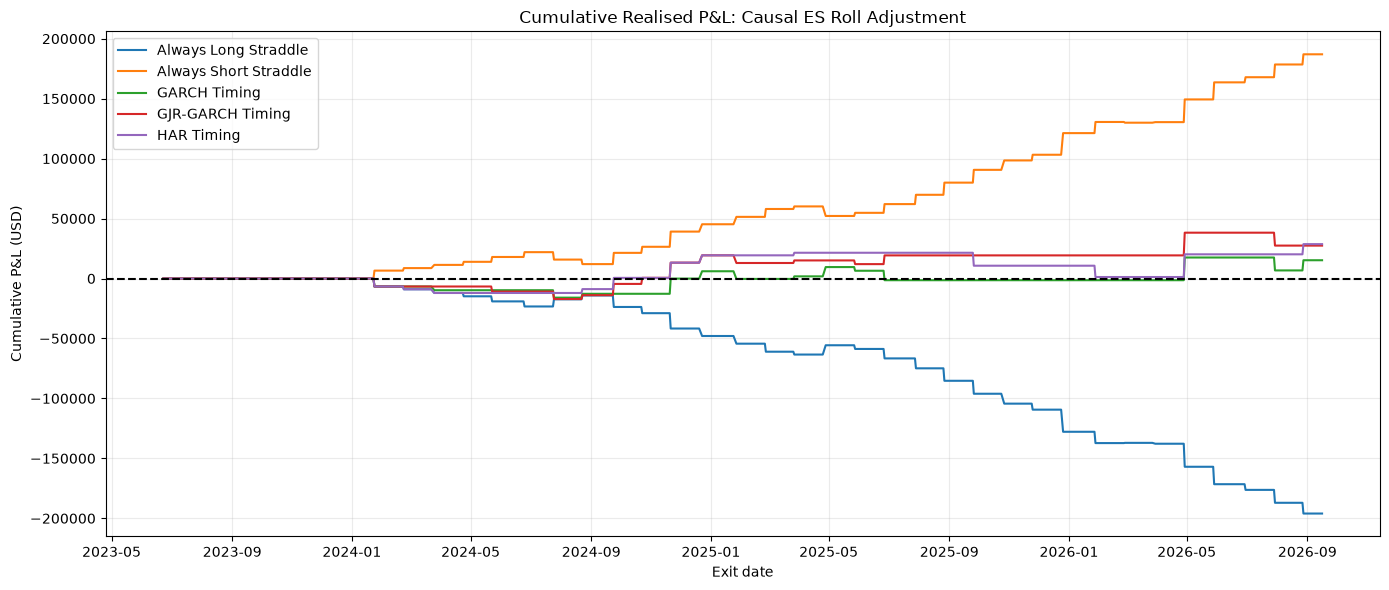

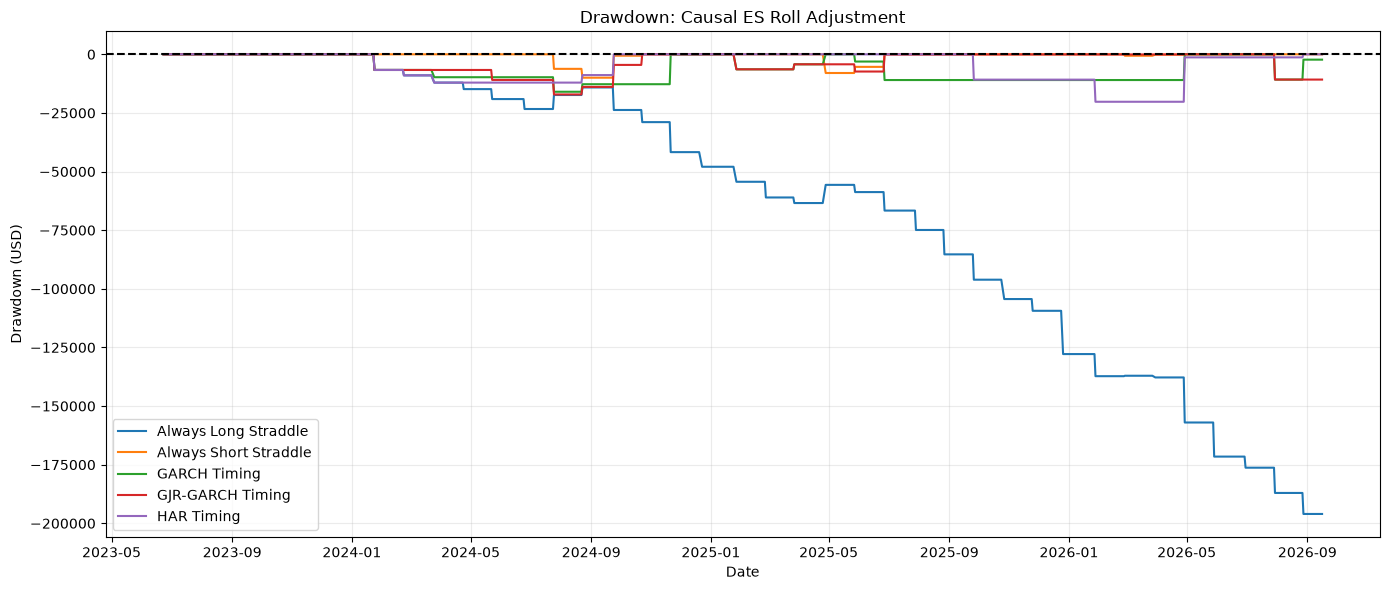

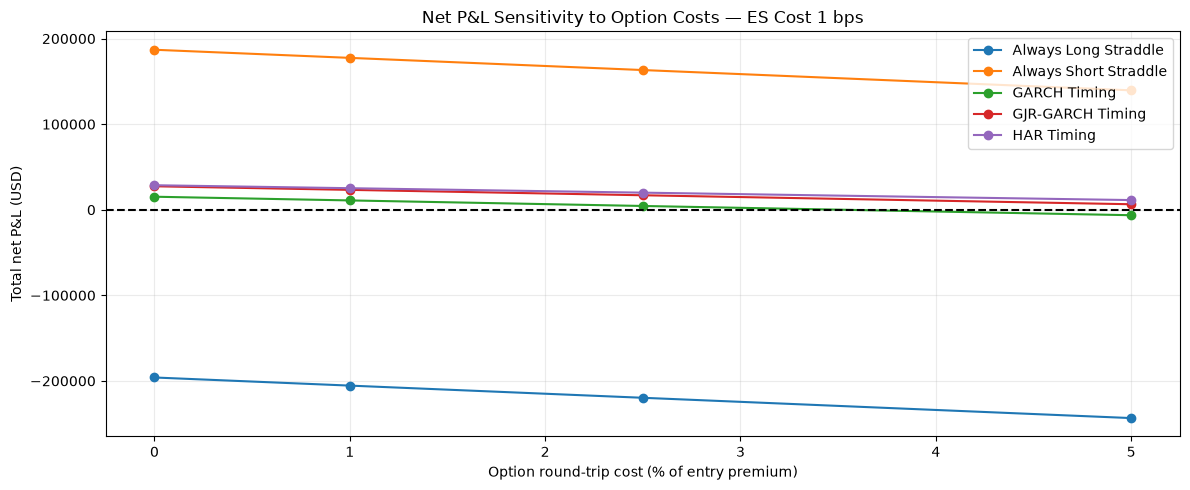

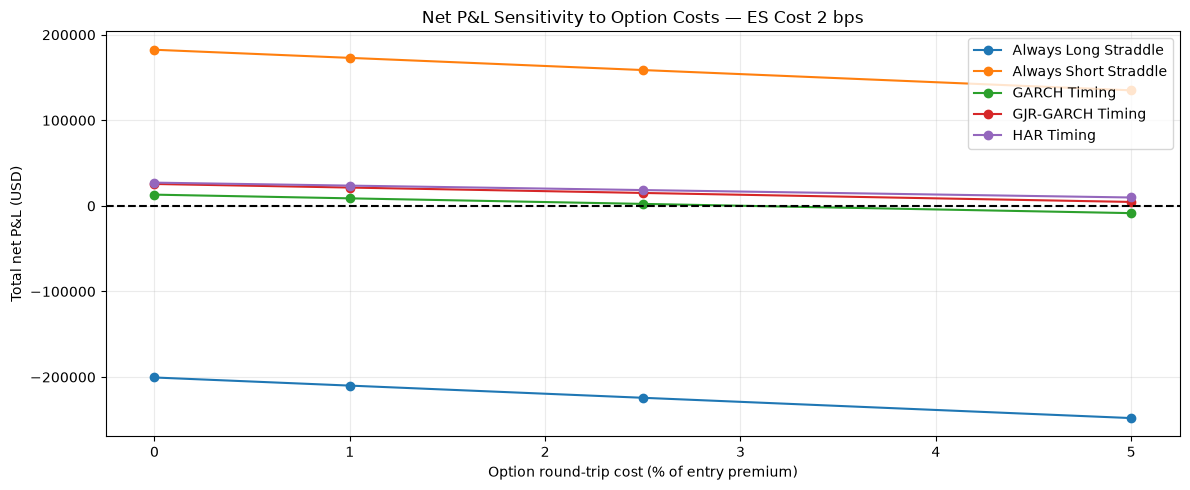

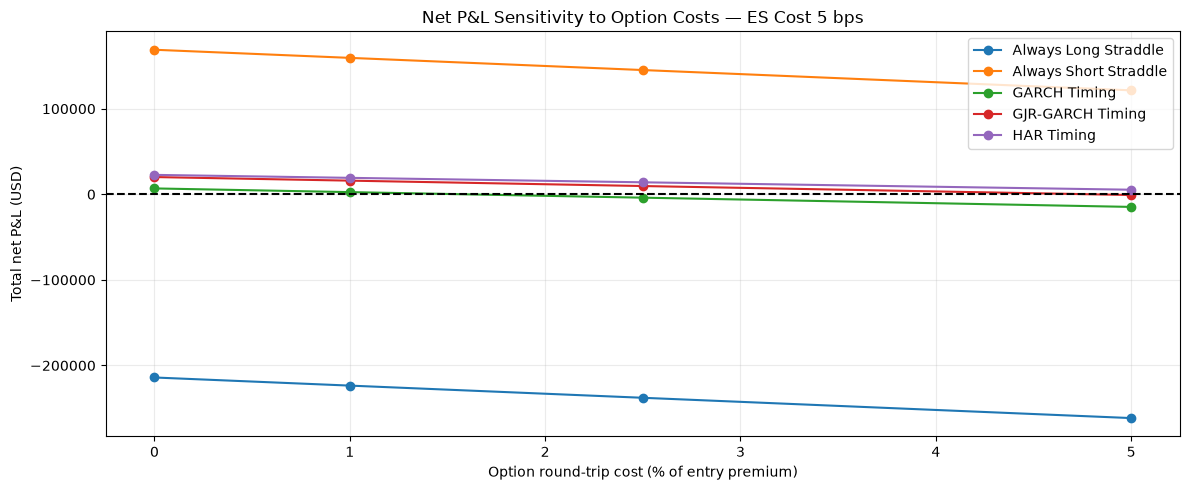


STAGE 28 COMPLETED
Causal roll days detected: 17
Trade records rerun: 160
Active trades: 104
Automated checks passed: 6
Automated checks failed: 0

AVAILABLE VARIABLES:
causal_es
causal_roll_table
causal_roll_tracking_summary
stage28_data
stage28_trade_results
stage28_hedge_history
stage28_strategy_summary
roll_method_comparison
stage28_cost_sensitivity
stage28_bootstrap_summary
stage28_exposure_summary
stage28_validation_checks
stage28_cumulative_pnl
stage28_drawdowns
live28

RESEARCH LIMITATIONS
1. Yahoo ES=F is a continuous-futures proxy, not individual tradable contract history.
2. Causal basis-jump adjustment is still a proxy, not an executable roll simulation.
3. VIX term-structure inputs are IV proxies, not historical SPX option quotes.
4. Option bid-ask spreads, market impact, margin and financing are not fully modelled.
5. Bootstrap intervals are descriptive and based on a small number of trades.
6. Premium-normalised Sharpe/Sortino are not return-on-capital performance measu

In [36]:
# ============================================================
# STAGE 28: FINAL VALIDATION AND ROBUSTNESS AUDIT
# Run inside the same Jupyter kernel as Stages 20-27.
# Recommended: open this file and run its contents as one cell.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# ------------------------------------------------------------
# 1. Validate required objects and functions
# ------------------------------------------------------------

required_names = [
    "term_data",
    "hedge_data",
    "gamma_trades_v2",
    "simulate_es_hedge",
    "HOLD",
    "OPTION_TENOR_DAYS",
    "maturity_matched_iv",
    "bs_extended_greeks",
    "RISK_FREE_RATE",
    "DIVIDEND_YIELD",
]

missing = [name for name in required_names if name not in globals()]
if missing:
    raise RuntimeError(
        "Missing previous-stage objects. Run Stages 20-27 first: "
        f"{missing}"
    )

if not callable(simulate_es_hedge):
    raise TypeError("simulate_es_hedge is not callable.")

if not {"SPX", "ES"}.issubset(hedge_data.columns):
    raise ValueError("hedge_data must contain SPX and ES columns.")

if not {"Entry date", "Exit date", "Direction", "Strategy"}.issubset(
    gamma_trades_v2.columns
):
    raise ValueError("gamma_trades_v2 is missing required trade columns.")

HOLD = int(HOLD)
if HOLD < 1:
    raise ValueError("HOLD must be a positive integer.")

ES_HEDGE_COST_BPS = float(globals().get("ES_HEDGE_COST_BPS", 1.0))
OPTION_COST_PCT = float(globals().get("OPTION_COST_PCT", 0.0))
SPX_OPTION_MULTIPLIER = float(globals().get("SPX_OPTION_MULTIPLIER", 100.0))
ES_CONTRACT_MULTIPLIER = float(globals().get("ES_CONTRACT_MULTIPLIER", 50.0))

print("STAGE 28 CONFIGURATION")
print("Scheduled records:", len(gamma_trades_v2))
print("Holding period:", HOLD)
print("Baseline ES cost (bps):", ES_HEDGE_COST_BPS)
print("Baseline option cost (% of entry premium):", OPTION_COST_PCT)

# ------------------------------------------------------------
# 2. Causal futures-roll detection
#    Threshold uses only information available before date t.
# ------------------------------------------------------------

causal_es = hedge_data[["SPX", "ES"]].copy().sort_index()
causal_es = causal_es[~causal_es.index.duplicated(keep="last")]

causal_es["Basis"] = causal_es["ES"] - causal_es["SPX"]
causal_es["Basis_change"] = causal_es["Basis"].diff()

ROLL_LOOKBACK = 126
ROLL_MIN_HISTORY = 63
ROLL_SIGMA_MULTIPLIER = 8.0
ROLL_MIN_THRESHOLD = 10.0

roll_adjustments = np.zeros(len(causal_es), dtype=float)
roll_flags = np.zeros(len(causal_es), dtype=bool)
roll_thresholds = np.full(len(causal_es), np.nan, dtype=float)
roll_medians = np.full(len(causal_es), np.nan, dtype=float)

basis_changes = causal_es["Basis_change"].to_numpy(dtype=float)

for i in range(1, len(causal_es)):
    # Strictly historical window: the current observation is excluded.
    left = max(1, i - ROLL_LOOKBACK)
    historical = basis_changes[left:i]
    historical = historical[np.isfinite(historical)]

    if len(historical) < ROLL_MIN_HISTORY:
        continue

    historical_median = float(np.median(historical))
    historical_mad = float(
        np.median(np.abs(historical - historical_median))
    )
    historical_sigma = 1.4826 * historical_mad

    threshold = max(
        ROLL_MIN_THRESHOLD,
        ROLL_SIGMA_MULTIPLIER * historical_sigma
    )

    current_change = basis_changes[i]
    if not np.isfinite(current_change):
        continue

    roll_medians[i] = historical_median
    roll_thresholds[i] = threshold

    deviation = current_change - historical_median

    if abs(deviation) > threshold:
        roll_flags[i] = True
        roll_adjustments[i] = deviation

causal_es["Roll_day_causal"] = roll_flags
causal_es["Roll_adjustment_causal"] = roll_adjustments
causal_es["Roll_threshold_causal"] = roll_thresholds
causal_es["Historical_basis_change_median"] = roll_medians

causal_es["ES_back_adjusted_causal"] = (
    causal_es["ES"]
    - causal_es["Roll_adjustment_causal"].cumsum()
)

causal_roll_dates = causal_es.index[causal_es["Roll_day_causal"]]

print("\nCAUSAL ROLL DIAGNOSTICS")
print("Detected causal roll days:", len(causal_roll_dates))
print("First detected roll:", causal_roll_dates.min() if len(causal_roll_dates) else "None")
print("Last detected roll:", causal_roll_dates.max() if len(causal_roll_dates) else "None")

causal_roll_table = causal_es.loc[
    causal_es["Roll_day_causal"],
    [
        "SPX", "ES", "Basis", "Basis_change",
        "Historical_basis_change_median", "Roll_threshold_causal",
        "Roll_adjustment_causal", "ES_back_adjusted_causal"
    ]
].copy()

display(causal_roll_table.round(4))

# ------------------------------------------------------------
# 3. Compare full-sample and causal roll-adjusted returns
# ------------------------------------------------------------

if "ES_back_adjusted" in hedge_data.columns:
    old_adjusted = hedge_data["ES_back_adjusted"].rename("Full_sample_adjusted_ES")
else:
    old_adjusted = pd.Series(dtype=float, name="Full_sample_adjusted_ES")

roll_return_data = pd.concat(
    [
        causal_es["SPX"].pct_change().rename("SPX_return"),
        causal_es["ES"].pct_change().rename("Raw_ES_return"),
        causal_es["ES_back_adjusted_causal"].pct_change().rename("Causal_ES_return"),
        old_adjusted.pct_change()
    ],
    axis=1
).replace([np.inf, -np.inf], np.nan).dropna(subset=["SPX_return", "Raw_ES_return", "Causal_ES_return"])

roll_tracking_rows = []
for col in ["Raw_ES_return", "Causal_ES_return"]:
    diff = roll_return_data[col] - roll_return_data["SPX_return"]
    roll_tracking_rows.append({
        "Series": col,
        "Correlation with SPX": roll_return_data[["SPX_return", col]].corr().iloc[0, 1],
        "Annualised tracking error (%)": diff.std(ddof=1) * np.sqrt(252) * 100,
        "Return difference RMSE": np.sqrt(np.mean(diff.to_numpy() ** 2)),
    })

causal_roll_tracking_summary = pd.DataFrame(roll_tracking_rows).set_index("Series")
print("\nRAW VS CAUSAL-ADJUSTED TRACKING")
display(causal_roll_tracking_summary.round(6))

# ------------------------------------------------------------
# 4. Build causal simulation data and rerun each trade
# ------------------------------------------------------------

causal_es_for_join = causal_es[
    ["ES", "ES_back_adjusted_causal", "Roll_day_causal"]
].rename(columns={
    "ES_back_adjusted_causal": "ES_back_adjusted",
    "Roll_day_causal": "Roll_day"
})

stage28_data = (
    term_data
    .join(causal_es_for_join, how="inner")
    .sort_index()
    .dropna(subset=["SPX", "ES", "ES_back_adjusted"])
)

if stage28_data.empty:
    raise RuntimeError("No overlapping observations for causal ES simulation.")

stage28_trade_records = []
stage28_hedge_records = []

for trade_id, trade in gamma_trades_v2.iterrows():
    strategy = str(trade["Strategy"])
    direction = int(trade["Direction"])
    entry_date = pd.Timestamp(trade["Entry date"])

    if entry_date not in stage28_data.index:
        raise RuntimeError(
            f"Entry date {entry_date} is absent from causal simulation data."
        )

    entry_pos = stage28_data.index.get_loc(entry_date)
    path = stage28_data.iloc[entry_pos:entry_pos + HOLD + 1].copy()

    if len(path) != HOLD + 1:
        raise RuntimeError(
            f"Incomplete {HOLD}-session path for {strategy} on {entry_date}."
        )

    if direction == 0:
        # Flat signals carry no position, premium or P&L.
        stage28_trade_records.append({
            "Strategy": strategy,
            "Entry date": entry_date,
            "Exit date": path.index[-1],
            "Direction": 0,
            "Entry SPX": float(path["SPX"].iloc[0]),
            "Entry ES": float(path["ES"].iloc[0]),
            "Entry IV": np.nan,
            "Option premium USD": 0.0,
            "Theoretical initial ES contracts": 0.0,
            "Initial integer ES contracts": 0,
            "Option P&L USD": 0.0,
            "ES hedge P&L USD": 0.0,
            "Gross P&L USD": 0.0,
            "ES turnover USD": 0.0,
            "ES transaction costs USD": 0.0,
            "Option costs USD": 0.0,
            "Net P&L USD": 0.0,
            "Return on option premium (%)": np.nan,
            "Mean absolute residual delta USD": 0.0,
            "Maximum absolute residual delta USD": 0.0,
            "Maximum absolute ES contracts": 0,
            "Roll days encountered": int(path["Roll_day"].sum()),
        })
        continue

    result, hedge_history = simulate_es_hedge(
        path=path,
        direction=direction,
        strategy=strategy,
        entry_date=entry_date,
        es_cost_bps=ES_HEDGE_COST_BPS,
        option_cost_pct=OPTION_COST_PCT
    )

    result["Trade ID"] = trade_id
    stage28_trade_records.append(result)

    for item in hedge_history:
        item["Trade ID"] = trade_id
        item["Strategy"] = strategy
        item["Entry date"] = entry_date
        item["Exit date"] = path.index[-1]
        stage28_hedge_records.append(item)

stage28_trade_results = pd.DataFrame(stage28_trade_records)
stage28_hedge_history = pd.DataFrame(stage28_hedge_records)

stage28_trade_results["Entry date"] = pd.to_datetime(stage28_trade_results["Entry date"])
stage28_trade_results["Exit date"] = pd.to_datetime(stage28_trade_results["Exit date"])

print("\nCAUSAL ES SIMULATION")
print("Trade records:", len(stage28_trade_results))
print("Active trades:", int(stage28_trade_results["Direction"].isin([-1, 1]).sum()))
print("Hedge observations:", len(stage28_hedge_history))
print("Evaluation start:", stage28_data.index.min())
print("Evaluation end:", stage28_data.index.max())

# ------------------------------------------------------------
# 5. Strategy-level performance and exit-date drawdown
# ------------------------------------------------------------

strategy_rows = []
stage28_cumulative_pnl = pd.DataFrame(index=stage28_data.index)
stage28_drawdowns = pd.DataFrame(index=stage28_data.index)

annualisation_factor = np.sqrt(252 / HOLD)

for strategy, group in stage28_trade_results.groupby("Strategy"):
    group = group.sort_values("Entry date").copy()
    active = group[group["Direction"].isin([-1, 1])].copy()

    net = group["Net P&L USD"].astype(float)
    active_net = active["Net P&L USD"].astype(float)

    premium_returns = (
        active["Net P&L USD"] / active["Option premium USD"]
    ).replace([np.inf, -np.inf], np.nan).dropna()

    wins = active_net[active_net > 0].sum()
    losses = abs(active_net[active_net < 0].sum())
    profit_factor = wins / losses if losses > 0 else np.inf

    ret_std = premium_returns.std(ddof=1) if len(premium_returns) > 1 else np.nan
    sharpe_active_proxy = (
        premium_returns.mean() / ret_std * annualisation_factor
        if pd.notna(ret_std) and ret_std > 0 else np.nan
    )

    downside = np.minimum(premium_returns.to_numpy(dtype=float), 0.0)
    downside_dev = np.sqrt(np.mean(downside ** 2)) if len(downside) else np.nan
    sortino_active_proxy = (
        premium_returns.mean() / downside_dev * annualisation_factor
        if pd.notna(downside_dev) and downside_dev > 0 else np.nan
    )

    exit_cashflows = group.groupby("Exit date")["Net P&L USD"].sum()
    daily = exit_cashflows.reindex(stage28_data.index).fillna(0.0)
    cumulative = daily.cumsum()
    peak = cumulative.cummax().clip(lower=0.0)
    dd = cumulative - peak

    stage28_cumulative_pnl[strategy] = cumulative
    stage28_drawdowns[strategy] = dd

    pnl_05 = active_net.quantile(0.05) if len(active_net) else np.nan
    cvar_05 = active_net[active_net <= pnl_05].mean() if len(active_net) else np.nan

    strategy_rows.append({
        "Strategy": strategy,
        "Scheduled trades": len(group),
        "Active trades": len(active),
        "Total net P&L USD": net.sum(),
        "Mean active P&L USD": active_net.mean() if len(active_net) else np.nan,
        "Active win fraction": (active_net > 0).mean() if len(active_net) else np.nan,
        "Profit factor": profit_factor,
        "Active-trade Sharpe proxy": sharpe_active_proxy,
        "Active-trade Sortino proxy": sortino_active_proxy,
        "Worst active trade USD": active_net.min() if len(active_net) else np.nan,
        "P&L VaR 95% USD": pnl_05,
        "P&L CVaR 95% USD": cvar_05,
        "Maximum drawdown USD": dd.min(),
        "Maximum drawdown date": dd.idxmin(),
        "Total ES transaction costs USD": group["ES transaction costs USD"].sum(),
        "Total option costs USD": group["Option costs USD"].sum(),
    })

stage28_strategy_summary = (
    pd.DataFrame(strategy_rows).set_index("Strategy").sort_index()
)

print("\nCAUSAL-ROLL STRATEGY PERFORMANCE")
display(stage28_strategy_summary.round(5))

# ------------------------------------------------------------
# 6. Compare full-sample Stage 26 results with causal rerun
# ------------------------------------------------------------

if "es_trade_results" in globals():
    old_totals = es_trade_results.groupby("Strategy")["Net P&L USD"].sum()
    new_totals = stage28_trade_results.groupby("Strategy")["Net P&L USD"].sum()

    roll_method_comparison = pd.concat(
        [
            old_totals.rename("Stage26_full_sample_roll_PnL_USD"),
            new_totals.rename("Stage28_causal_roll_PnL_USD")
        ],
        axis=1
    )
    roll_method_comparison["Causal_minus_full_sample_USD"] = (
        roll_method_comparison["Stage28_causal_roll_PnL_USD"]
        - roll_method_comparison["Stage26_full_sample_roll_PnL_USD"]
    )
else:
    roll_method_comparison = pd.DataFrame()

print("\nROLL-METHOD P&L COMPARISON")
display(roll_method_comparison.round(4))

# ------------------------------------------------------------
# 7. Transaction-cost sensitivity
#    Gross P&L is held fixed; costs are recalculated from turnover.
# ------------------------------------------------------------

hedge_cost_grid_bps = [1.0, 2.0, 5.0]
option_cost_grid_pct = [0.0, 1.0, 2.5, 5.0]

cost_rows = []

for strategy, group in stage28_trade_results.groupby("Strategy"):
    active = group[group["Direction"].isin([-1, 1])]

    for hedge_bps in hedge_cost_grid_bps:
        for option_pct in option_cost_grid_pct:
            scenario_net = (
                group["Gross P&L USD"].sum()
                - group["ES turnover USD"].sum() * hedge_bps / 10000.0
                - group["Option premium USD"].sum() * option_pct / 100.0
            )

            scenario_active_net = (
                active["Gross P&L USD"]
                - active["ES turnover USD"] * hedge_bps / 10000.0
                - active["Option premium USD"] * option_pct / 100.0
            )

            cost_rows.append({
                "Strategy": strategy,
                "ES hedge cost (bps)": hedge_bps,
                "Option round-trip cost (% premium)": option_pct,
                "Active trades": len(active),
                "Total net P&L USD": scenario_net,
                "Mean net P&L per active trade USD": (
                    scenario_active_net.mean() if len(active) else np.nan
                ),
                "Active win fraction": (
                    (scenario_active_net > 0).mean() if len(active) else np.nan
                ),
            })

stage28_cost_sensitivity = pd.DataFrame(cost_rows)

print("\nTRANSACTION-COST SENSITIVITY")
display(
    stage28_cost_sensitivity.sort_values(
        ["ES hedge cost (bps)", "Option round-trip cost (% premium)", "Strategy"]
    ).round(4)
)

# ------------------------------------------------------------
# 8. Moving-block bootstrap of active-trade mean P&L
#    Descriptive uncertainty interval, not a trading p-value.
# ------------------------------------------------------------

BOOTSTRAP_REPS = 5000
BOOTSTRAP_BLOCK_LENGTH = 2
BOOTSTRAP_SEED = 20261113
rng = np.random.default_rng(BOOTSTRAP_SEED)


def circular_moving_block_bootstrap(values, reps, block_length, rng):
    values = np.asarray(values, dtype=float)
    n = len(values)
    if n < 2:
        raise ValueError("At least two active trades are required.")

    block_length = max(1, min(int(block_length), n))
    out = np.empty(reps, dtype=float)

    for b in range(reps):
        sample_indices = []
        while len(sample_indices) < n:
            start = int(rng.integers(0, n))
            block = (start + np.arange(block_length)) % n
            sample_indices.extend(block.tolist())
        sample_indices = np.asarray(sample_indices[:n], dtype=int)
        out[b] = values[sample_indices].mean()

    return out


bootstrap_rows = []

for strategy, group in stage28_trade_results.groupby("Strategy"):
    active_values = group.loc[
        group["Direction"].isin([-1, 1]),
        "Net P&L USD"
    ].dropna().to_numpy(dtype=float)

    if len(active_values) < 5:
        bootstrap_rows.append({
            "Strategy": strategy,
            "Active trades": len(active_values),
            "Observed mean active P&L USD": np.mean(active_values) if len(active_values) else np.nan,
            "Bootstrap 95% CI lower USD": np.nan,
            "Bootstrap 95% CI upper USD": np.nan,
            "Bootstrap probability mean positive": np.nan,
            "Status": "Insufficient active trades"
        })
        continue

    boot_means = circular_moving_block_bootstrap(
        active_values,
        reps=BOOTSTRAP_REPS,
        block_length=BOOTSTRAP_BLOCK_LENGTH,
        rng=rng
    )

    lower, upper = np.quantile(boot_means, [0.025, 0.975])

    bootstrap_rows.append({
        "Strategy": strategy,
        "Active trades": len(active_values),
        "Observed mean active P&L USD": active_values.mean(),
        "Bootstrap 95% CI lower USD": lower,
        "Bootstrap 95% CI upper USD": upper,
        "Bootstrap probability mean positive": (boot_means > 0).mean(),
        "Status": "Descriptive; small sample"
    })

stage28_bootstrap_summary = pd.DataFrame(bootstrap_rows).set_index("Strategy")

print("\nACTIVE-TRADE MOVING-BLOCK BOOTSTRAP")
print("Bootstrap replications:", BOOTSTRAP_REPS)
print("Block length (scheduled active trades):", BOOTSTRAP_BLOCK_LENGTH)
display(stage28_bootstrap_summary.round(5))

# ------------------------------------------------------------
# 9. Exposure audit: exclude exit rows
# ------------------------------------------------------------

if len(stage28_hedge_history):
    exposure28 = stage28_hedge_history.copy()
    exposure28["Date"] = pd.to_datetime(exposure28["Date"])
    exposure28["Exit date"] = pd.to_datetime(exposure28["Exit date"])

    live28 = exposure28[
        exposure28["Date"] < exposure28["Exit date"]
    ].copy()

    live28["Abs ES contracts"] = live28["Actual contracts"].abs()
    live28["Abs residual delta USD"] = live28["Residual option delta"].abs()

    exposure_rows = []
    for strategy, group in live28.groupby("Strategy"):
        exposure_rows.append({
            "Strategy": strategy,
            "Live hedge observations": len(group),
            "Mean absolute ES contracts": group["Abs ES contracts"].mean(),
            "Maximum absolute ES contracts": group["Abs ES contracts"].max(),
            "Zero-contract fraction": group["Actual contracts"].eq(0).mean(),
            "Mean absolute residual delta USD": group["Abs residual delta USD"].mean(),
            "Maximum absolute residual delta USD": group["Abs residual delta USD"].max(),
            "Roll observations while open": group["Roll day"].sum(),
        })

    stage28_exposure_summary = pd.DataFrame(exposure_rows).set_index("Strategy")
    stage28_exposure_summary["Within half-contract rounding bound"] = (
        stage28_exposure_summary["Maximum absolute residual delta USD"]
        <= ES_CONTRACT_MULTIPLIER / 2 + 1e-6
    )
else:
    live28 = pd.DataFrame()
    stage28_exposure_summary = pd.DataFrame()

print("\nCAUSAL-ROLL LIVE EXPOSURE AUDIT")
display(stage28_exposure_summary.round(5))

# ------------------------------------------------------------
# 10. Automated data, P&L and trade-integrity checks
# ------------------------------------------------------------

checks = []

# A. No duplicated scheduled strategy-entry combinations.
duplicate_count = stage28_trade_results.duplicated(
    subset=["Strategy", "Entry date"]
).sum()
checks.append({
    "Check": "No duplicate strategy-entry records",
    "Result": int(duplicate_count),
    "Passed": duplicate_count == 0
})

# B. All trade paths have the required holding horizon.
expected_exit_dates = []
for _, trade in stage28_trade_results.iterrows():
    entry = pd.Timestamp(trade["Entry date"])
    pos = stage28_data.index.get_loc(entry)
    expected_exit_dates.append(stage28_data.index[pos + HOLD])

exit_match = np.array([
    pd.Timestamp(actual) == pd.Timestamp(expected)
    for actual, expected in zip(
        stage28_trade_results["Exit date"], expected_exit_dates
    )
])
checks.append({
    "Check": "All exits match the configured holding horizon",
    "Result": int((~exit_match).sum()),
    "Passed": bool(exit_match.all())
})

# C. P&L identity: gross = option + hedge; net = gross - costs.
gross_error = (
    stage28_trade_results["Gross P&L USD"]
    - stage28_trade_results["Option P&L USD"]
    - stage28_trade_results["ES hedge P&L USD"]
).abs().max()

net_error = (
    stage28_trade_results["Net P&L USD"]
    - stage28_trade_results["Gross P&L USD"]
    + stage28_trade_results["ES transaction costs USD"]
    + stage28_trade_results["Option costs USD"]
).abs().max()

checks.append({
    "Check": "Gross P&L reconciles to option plus ES hedge P&L",
    "Result": float(gross_error),
    "Passed": bool(gross_error < 1e-6)
})
checks.append({
    "Check": "Net P&L reconciles after all modelled costs",
    "Result": float(net_error),
    "Passed": bool(net_error < 1e-6)
})

# D. Integer futures positions.
if len(stage28_hedge_history):
    integer_error = np.max(
        np.abs(
            stage28_hedge_history["Actual contracts"].to_numpy(dtype=float)
            - np.rint(stage28_hedge_history["Actual contracts"].to_numpy(dtype=float))
        )
    )
    checks.append({
        "Check": "All ES hedge positions are integer contracts",
        "Result": float(integer_error),
        "Passed": bool(integer_error < 1e-10)
    })

# E. Live residual delta should not exceed half a contract's delta value
#    under nearest-integer rounding, using the simulator's delta convention.
if len(stage28_exposure_summary):
    exposure_pass = bool(
        stage28_exposure_summary["Within half-contract rounding bound"].all()
    )
    max_residual = float(
        stage28_exposure_summary["Maximum absolute residual delta USD"].max()
    )
    checks.append({
        "Check": "Live residual delta respects integer-rounding bound",
        "Result": max_residual,
        "Passed": exposure_pass
    })

stage28_validation_checks = pd.DataFrame(checks).set_index("Check")

print("\nAUTOMATED VALIDATION CHECKS")
display(stage28_validation_checks)

# ------------------------------------------------------------
# 11. Plot causal-roll cumulative P&L and drawdowns
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))
for strategy in stage28_cumulative_pnl.columns:
    ax.plot(
        stage28_cumulative_pnl.index,
        stage28_cumulative_pnl[strategy],
        label=strategy
    )
ax.axhline(0, color="black", linestyle="--")
ax.set_title("Cumulative Realised P&L: Causal ES Roll Adjustment")
ax.set_xlabel("Exit date")
ax.set_ylabel("Cumulative P&L (USD)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(14, 6))
for strategy in stage28_drawdowns.columns:
    ax.plot(
        stage28_drawdowns.index,
        stage28_drawdowns[strategy],
        label=strategy
    )
ax.axhline(0, color="black", linestyle="--")
ax.set_title("Drawdown: Causal ES Roll Adjustment")
ax.set_xlabel("Date")
ax.set_ylabel("Drawdown (USD)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Cost sensitivity plot at each ES cost level.
for hedge_bps in hedge_cost_grid_bps:
    subset = stage28_cost_sensitivity[
        stage28_cost_sensitivity["ES hedge cost (bps)"] == hedge_bps
    ]
    fig, ax = plt.subplots(figsize=(12, 5))
    for strategy, group in subset.groupby("Strategy"):
        group = group.sort_values("Option round-trip cost (% premium)")
        ax.plot(
            group["Option round-trip cost (% premium)"],
            group["Total net P&L USD"],
            marker="o",
            label=strategy
        )
    ax.axhline(0, color="black", linestyle="--")
    ax.set_title(f"Net P&L Sensitivity to Option Costs — ES Cost {hedge_bps:g} bps")
    ax.set_xlabel("Option round-trip cost (% of entry premium)")
    ax.set_ylabel("Total net P&L (USD)")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 12. Final warnings and completion
# ------------------------------------------------------------

print("\nSTAGE 28 COMPLETED")
print("Causal roll days detected:", len(causal_roll_dates))
print("Trade records rerun:", len(stage28_trade_results))
print("Active trades:", int(stage28_trade_results["Direction"].isin([-1, 1]).sum()))
print("Automated checks passed:", int(stage28_validation_checks["Passed"].sum()))
print("Automated checks failed:", int((~stage28_validation_checks["Passed"]).sum()))

print("\nAVAILABLE VARIABLES:")
for name in [
    "causal_es",
    "causal_roll_table",
    "causal_roll_tracking_summary",
    "stage28_data",
    "stage28_trade_results",
    "stage28_hedge_history",
    "stage28_strategy_summary",
    "roll_method_comparison",
    "stage28_cost_sensitivity",
    "stage28_bootstrap_summary",
    "stage28_exposure_summary",
    "stage28_validation_checks",
    "stage28_cumulative_pnl",
    "stage28_drawdowns",
    "live28",
]:
    print(name)

print("\nRESEARCH LIMITATIONS")
print("1. Yahoo ES=F is a continuous-futures proxy, not individual tradable contract history.")
print("2. Causal basis-jump adjustment is still a proxy, not an executable roll simulation.")
print("3. VIX term-structure inputs are IV proxies, not historical SPX option quotes.")
print("4. Option bid-ask spreads, market impact, margin and financing are not fully modelled.")
print("5. Bootstrap intervals are descriptive and based on a small number of trades.")
print("6. Premium-normalised Sharpe/Sortino are not return-on-capital performance measures.")


## Saved-run findings and limitations

The saved run used S&P 500/VIX data from **4 January 2010 to 12 November 2026**. The common forecast comparison covered **1,084** observations; the VRP and synthetic strategy evaluation ran from **21 June 2023 to 15 September 2026**.

- **Forecasting:** HAR, GARCH, and GJR-GARCH did not show a reliable overall improvement over the VIX-only benchmark.
- **VRP signal:** some quintile patterns appeared, but the globally corrected bootstrap intervals included zero.
- **Strategy test:** signal-based timing did not establish an advantage over always-short variance; the corrected HAR long–short comparison was negative versus that benchmark.
- **Synthetic option test:** the causal-roll run reported approximately **+$150.8k** for always-short straddles, **+$65.4k** for GARCH timing, **+$49.6k** for GJR-GARCH timing, **+$46.5k** for HAR timing, and **−$160.1k** for always-long straddles. These are assumption-dependent model outputs, not realised or executable trading profits.
- **Implementation audit:** the causal rule detected **17** roll days; annualised ES tracking error fell from about **3.04%** to **1.17%**; all **6** automated validation checks passed. Accounting consistency does not establish market realism.

**Research implication:** the current evidence does not establish a robust VRP timing premium or a tradable gamma-scalping edge. The synthetic option results should be presented as a mechanics and sensitivity study, not as strategy performance. A genuine historical options backtest requires timestamped, strike-specific option quotes and fuller execution and capital assumptions.

*Saved-run values are descriptive and can change when Yahoo Finance data are refreshed.*
